# GR5398 26 Spring: FinRL-Trading Quantitative Trading Strategy Track
## Assignment 1

In this assignment 1, we want you to :
+ Run this ipynb file, which is a simplified FinRL-Trading whole process, and have a basic knowledge of what we will do in this semester
+ Design a portfolio using the selected stocks, and learn some fundamental information of quantitative trading (especially stock selection part)
+ Implement a full backtest process to verify your strategy's performance using real historical data
+ Summarize your result in a very brief research report, and write a `Medium Blog`. Submit your code files onto GitHub repo in a new folder called Assignment1_Name_UNI.
    + An example of medium blog: [Applying new LLMs on FinGPT: Fine-tune DeepSeek and Llama3](https://medium.com/p/6ac9198d88b2)

Assignment 1 Report Submission Due Day: **Feb 20, 2026**.

For full `FinRL-Trading` project, please refer to [AI4Finance/FinRL-Trading](https://github.com/AI4Finance-Foundation/FinRL-Trading/tree/master_backup).

### 0. Prerequisities

First, you should decide your stock pool for later selection. Here we recommend you to choose your portfolio from S&P 500 index or NASDAQ 100 index. We have already provided you with their components.

Then, you should download stock's daily OHLCV data on [WRDS-Security Daily](https://wrds-www.wharton.upenn.edu/pages/get-data/compustat-capital-iq-standard-poors/compustat/north-america-daily/security-daily/) and quarterly fundamental data on [WRDS-Fundamental Quarterly](https://wrds-www.wharton.upenn.edu/pages/get-data/compustat-capital-iq-standard-poors/compustat/north-america-daily/security-daily/) for later usage.

+ Note: Here we highly recommend you to register for a WRDS account which our university has provided for all master students for free. Please follow the instruction below to get a WRDS account:
    + https://guides.library.columbia.edu/wrds

If you don't have enough storage or want this data file to be loaded faster while doing calculation, you can select these columns below only while querying the WRDS database.
+ prccd (Price - Close - Daily)
+ prcod (Price - Open - Daily)
+ ajexdi (Adjustment Factor (Issue)-Cumulative by Ex-Date)
+ tic (Ticker)

Since we want you to implement backtest from **Jan 1, 2018** to **Dec 31, 2025**, we suggest you to download all the data during this period.

### 1. Data Preprocessing

In this part, we will preprocess all the fundamental data for our Machine Learning algorithms. Please refer to [AI4Finance/FinRL-Trading/data_processor/Step2_preprocess_fundmental_data.py](https://github.com/AI4Finance-Foundation/FinRL-Trading/blob/master_backup/data_processor/Step2_preprocess_fundmental_data.py) for detailed usage.

After running this part, you should get a folder with final fundamental ratios split into different industry sections in `xlsx` files.

In [1]:
import os
import pandas as pd
import numpy as np
import warnings
from datetime import datetime as dt
import sys
import time
from pathlib import Path
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore")

In [ ]:
def load_data(fundamental_file, price_file):
    """
    Load fundamental and price data from CSV files.
    
    Args:
        fundamental_file (str): Path to fundamental data CSV file
        price_file (str): Path to price data CSV file
        
    Returns:
        tuple: (fundamental_df, price_df)
    """
    print("Loading data files...")
    
    if not os.path.isfile(fundamental_file):
        raise FileNotFoundError(f"Fundamental file {fundamental_file} not found.")
    
    if not os.path.isfile(price_file):
        raise FileNotFoundError(f"Price file {price_file} not found.")
    
    # Load fundamental data
    fund_df = pd.read_csv(fundamental_file)
    print(fund_df.head())
    
    # For price data, only load necessary columns to save memory
    print("Loading price data (only necessary columns)...")
    price_columns = ['gvkey', 'tic', 'datadate', 'prccd', 'ajexdi']
    df_daily_price = pd.read_csv(price_file, usecols=price_columns)
    print(df_daily_price.head())
    
    print(f"Fundamental data shape: {fund_df.shape}")
    print(f"Price data shape: {df_daily_price.shape}")
    print(f"Unique tickers in fundamental data: {len(fund_df.tic.unique())}")
    print(f"Unique tickers in price data: {len(df_daily_price.tic.unique())}")
    
    return fund_df, df_daily_price

In [ ]:
def adjust_trade_dates(fund_df):
    """
    Adjust trade dates to use trading dates instead of quarterly report dates.
    
    Args:
        fund_df (pandas.DataFrame): Fundamental data DataFrame
        
    Returns:
        pandas.DataFrame: DataFrame with adjusted trade dates
    """
    print("Adjusting trade dates...")
    
    # Convert datadate to datetime first, then to integer format
    datadate_dt = pd.to_datetime(fund_df['datadate'])

    fund_df['tradedate'] = ((datadate_dt.dt.to_period('Q')).dt.end_time.dt.normalize())
    fund_df['reportdate'] = fund_df["rdq"]
    
    return fund_df

In [ ]:
def calculate_adjusted_close(fund_df):
    """
    Calculate adjusted close price.
    
    Args:
        fund_df (pandas.DataFrame): Fundamental data DataFrame
        
    Returns:
        pandas.DataFrame: DataFrame with adjusted close price
    """
    print("Calculating adjusted close price...")
    fund_df['adj_close_q'] = fund_df.prccq / fund_df.adjex
    return fund_df

In [ ]:
def match_tickers_and_gvkey(fund_df, df_daily_price):
    """
    Match tickers and gvkey for fundamental and price data.
    
    Args:
        fund_df (pandas.DataFrame): Fundamental data DataFrame
        df_daily_price (pandas.DataFrame): Price data DataFrame
        
    Returns:
        pandas.DataFrame: Filtered fundamental data DataFrame
    """
    print("Matching tickers and gvkey...")
    
    # Create mapping from ticker to gvkey
    tic_to_gvkey = {}
    df_daily_groups = list(df_daily_price.groupby('tic'))
    
    for tic, df_ in df_daily_groups:
        tic_to_gvkey[tic] = df_.gvkey.iloc[0]
    
    print(f"Original fundamental data shape: {fund_df.shape}")
    
    # Filter fundamental data to only include tickers present in price data
    fund_df = fund_df[np.isin(fund_df.tic, list(tic_to_gvkey.keys()))]
    
    print(f"Filtered fundamental data shape: {fund_df.shape}")
    print(f"Unique gvkeys: {len(fund_df.gvkey.unique())}")
    
    # Add gvkey mapping
    fund_df['gvkey'] = [tic_to_gvkey[x] for x in fund_df['tic']]
    
    return fund_df

In [ ]:
def calculate_next_quarter_returns(fund_df):
    """
    Calculate next quarter's return for each stock.
    
    Args:
        fund_df (pandas.DataFrame): Fundamental data DataFrame
        
    Returns:
        pandas.DataFrame: DataFrame with next quarter returns
    """
    print("Calculating next quarter returns...")
    
    fund_df['date'] = fund_df["tradedate"]
    # fund_df['date'] = pd.to_datetime(fund_df['date'], format="%Y-%m%d")
    fund_df['date'] = pd.to_datetime(fund_df['date'])
    fund_df.drop_duplicates(["date", "gvkey"], keep='last', inplace=True)
    
    # Calculate next quarter return for each stock
    l_df = list(fund_df.groupby('gvkey'))
    for tic, df in l_df:
        df.reset_index(inplace=True, drop=True)
        df = df.sort_values('date')
        # Calculate next quarter's return
        df['y_return'] = np.log(df['adj_close_q'].shift(-1) / df['adj_close_q'])
    
    fund_df = pd.concat([x[1] for x in l_df])
    
    print(f"Data shape after calculating returns: {fund_df.shape}")
    return fund_df

In [ ]:
def calculate_basic_ratios(fund_df):
    """
    Calculate basic financial ratios (PE, PS, PB).
    
    Args:
        fund_df (pandas.DataFrame): Fundamental data DataFrame
        
    Returns:
        pandas.DataFrame: DataFrame with basic ratios
    """
    print("Calculating basic financial ratios...")
    
    fund_df['pe'] = fund_df.prccq / fund_df.epspxq
    fund_df['ps'] = fund_df.prccq / (fund_df.revtq / fund_df.cshoq)
    fund_df['pb'] = fund_df.prccq / ((fund_df.atq - fund_df.ltq) / fund_df.cshoq)
    
    return fund_df

In [ ]:
def select_columns(fund_df):
    """
    Select relevant columns for analysis.
    
    Args:
        fund_df (pandas.DataFrame): Fundamental data DataFrame
        
    Returns:
        pandas.DataFrame: DataFrame with selected columns
    """
    print("Selecting relevant columns...")
    
    items = [
        'date', 'gvkey', 'tic', 'gsector',
        'oiadpq', 'revtq', 'niq', 'atq', 'teqq', 'epspiy', 'ceqq', 'cshoq', 'dvpspq',
        'actq', 'lctq', 'cheq', 'rectq', 'cogsq', 'invtq', 'apq', 'dlttq', 'dlcq', 'ltq',
        'pe', 'ps', 'pb', 'adj_close_q', 'y_return', 'reportdate'
    ]
    
    fund_data = fund_df[items]
    
    # Rename columns for readability
    fund_data = fund_data.rename(columns={
        'oiadpq': 'op_inc_q',
        'revtq': 'rev_q',
        'niq': 'net_inc_q',
        'atq': 'tot_assets',
        'teqq': 'sh_equity',
        'epspiy': 'eps_incl_ex',
        'ceqq': 'com_eq',
        'cshoq': 'sh_outstanding',
        'dvpspq': 'div_per_sh',
        'actq': 'cur_assets',
        'lctq': 'cur_liabilities',
        'cheq': 'cash_eq',
        'rectq': 'receivables',
        'cogsq': 'cogs_q',
        'invtq': 'inventories',
        'apq': 'payables',
        'dlttq': 'long_debt',
        'dlcq': 'short_debt',
        'ltq': 'tot_liabilities'
    })
    
    return fund_data

In [ ]:
def calculate_financial_ratios(fund_data):
    """
    Calculate comprehensive financial ratios.
    
    Args:
        fund_data (pandas.DataFrame): Fundamental data DataFrame
        
    Returns:
        pandas.DataFrame: DataFrame with all financial ratios
    """
    print("Calculating comprehensive financial ratios...")
    
    # Set data type to series
    date = fund_data['date'].to_frame('date').reset_index(drop=True)
    reportdate = fund_data['reportdate'].to_frame('reportdate').reset_index(drop=True)
    tic = fund_data['tic'].to_frame('tic').reset_index(drop=True)
    gvkey = fund_data['gvkey'].to_frame('gvkey').reset_index(drop=True)
    adj_close_q = fund_data['adj_close_q'].to_frame('adj_close_q').reset_index(drop=True)
    y_return = fund_data['y_return'].to_frame('y_return').reset_index(drop=True)
    gsector = fund_data['gsector'].to_frame('gsector').reset_index(drop=True)
    pe = fund_data['pe'].to_frame('pe').reset_index(drop=True)
    ps = fund_data['ps'].to_frame('ps').reset_index(drop=True)
    pb = fund_data['pb'].to_frame('pb').reset_index(drop=True)
    
    # Profitability ratios
    print("  Calculating profitability ratios...")
    
    # Operating Margin
    OPM = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='OPM')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            OPM[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            OPM.iloc[i] = np.nan
        else:
            OPM.iloc[i] = np.sum(fund_data['op_inc_q'].iloc[i-3:i]) / np.sum(fund_data['rev_q'].iloc[i-3:i])
    OPM = pd.Series(OPM).to_frame().reset_index(drop=True)
    
    # Net Profit Margin
    NPM = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='NPM')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            NPM[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            NPM.iloc[i] = np.nan
        else:
            NPM.iloc[i] = np.sum(fund_data['net_inc_q'].iloc[i-3:i]) / np.sum(fund_data['rev_q'].iloc[i-3:i])
    NPM = pd.Series(NPM).to_frame().reset_index(drop=True)
    
    # Return On Assets
    ROA = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='ROA')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            ROA[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            ROA.iloc[i] = np.nan
        else:
            ROA.iloc[i] = np.sum(fund_data['net_inc_q'].iloc[i-3:i]) / fund_data['tot_assets'].iloc[i]
    ROA = pd.Series(ROA).to_frame().reset_index(drop=True)
    
    # Return on Equity
    ROE = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='ROE')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            ROE[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            ROE.iloc[i] = np.nan
        else:
            ROE.iloc[i] = np.sum(fund_data['net_inc_q'].iloc[i-3:i]) / fund_data['sh_equity'].iloc[i]
    ROE = pd.Series(ROE).to_frame().reset_index(drop=True)
    
    # Per share items
    EPS = fund_data['eps_incl_ex'].to_frame('EPS').reset_index(drop=True)
    BPS = (fund_data['com_eq'] / fund_data['sh_outstanding']).to_frame('BPS').reset_index(drop=True)
    DPS = fund_data['div_per_sh'].to_frame('DPS').reset_index(drop=True)
    
    # Liquidity ratios
    print("  Calculating liquidity ratios...")
    cur_ratio = (fund_data['cur_assets'] / fund_data['cur_liabilities']).to_frame('cur_ratio').reset_index(drop=True)
    quick_ratio = ((fund_data['cash_eq'] + fund_data['receivables']) / fund_data['cur_liabilities']).to_frame('quick_ratio').reset_index(drop=True)
    cash_ratio = (fund_data['cash_eq'] / fund_data['cur_liabilities']).to_frame('cash_ratio').reset_index(drop=True)
    
    # Efficiency ratios
    print("  Calculating efficiency ratios...")
    
    # Inventory turnover ratio
    inv_turnover = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='inv_turnover')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            inv_turnover[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            inv_turnover.iloc[i] = np.nan
        else:
            inv_turnover.iloc[i] = np.sum(fund_data['cogs_q'].iloc[i-3:i]) / fund_data['inventories'].iloc[i]
    inv_turnover = pd.Series(inv_turnover).to_frame().reset_index(drop=True)
    
    # Receivables turnover ratio
    acc_rec_turnover = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='acc_rec_turnover')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            acc_rec_turnover[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            acc_rec_turnover.iloc[i] = np.nan
        else:
            acc_rec_turnover.iloc[i] = np.sum(fund_data['rev_q'].iloc[i-3:i]) / fund_data['receivables'].iloc[i]
    acc_rec_turnover = pd.Series(acc_rec_turnover).to_frame().reset_index(drop=True)
    
    # Payable turnover ratio
    acc_pay_turnover = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='acc_pay_turnover')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            acc_pay_turnover[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            acc_pay_turnover.iloc[i] = np.nan
        else:
            acc_pay_turnover.iloc[i] = np.sum(fund_data['cogs_q'].iloc[i-3:i]) / fund_data['payables'].iloc[i]
    acc_pay_turnover = pd.Series(acc_pay_turnover).to_frame().reset_index(drop=True)
    
    # Leverage ratios
    print("  Calculating leverage ratios...")
    debt_ratio = (fund_data['tot_liabilities'] / fund_data['tot_assets']).to_frame('debt_ratio').reset_index(drop=True)
    debt_to_equity = (fund_data['tot_liabilities'] / fund_data['sh_equity']).to_frame('debt_to_equity').reset_index(drop=True)
    
    # Create final ratios dataframe
    ratios = pd.concat([
        date, gvkey, tic, gsector, adj_close_q, y_return,
        OPM, NPM, ROA, ROE, EPS, BPS, DPS,
        cur_ratio, quick_ratio, cash_ratio, inv_turnover, acc_rec_turnover, acc_pay_turnover,
        debt_ratio, debt_to_equity, pe, ps, pb, reportdate
    ], axis=1).reset_index(drop=True)
    
    return ratios

In [ ]:
def handle_missing_values(ratios):
    """
    Handle missing values and infinite values in the dataset.
    
    Args:
        ratios (pandas.DataFrame): DataFrame with financial ratios
        
    Returns:
        pandas.DataFrame: Cleaned DataFrame
    """
    print("Handling missing values...")
    
    # Replace NAs and infinite values with zero initially
    final_ratios = ratios.copy()
    final_ratios = final_ratios.fillna(0)
    final_ratios = final_ratios.replace(np.inf, 0)
    
    # Define financial features columns
    features_column_financial = [
        'OPM', 'NPM', 'ROA', 'ROE', 'EPS', 'BPS', 'DPS', 'cur_ratio',
        'quick_ratio', 'cash_ratio', 'inv_turnover', 'acc_rec_turnover',
        'acc_pay_turnover', 'debt_ratio', 'debt_to_equity', 'pe', 'ps', 'pb'
    ]
    
    # Remove rows with zero adjusted close price
    final_ratios = final_ratios.drop(list(final_ratios[final_ratios.adj_close_q == 0].index)).reset_index(drop=True)
    
    # Convert to numeric and handle invalid values
    final_ratios['y_return'] = pd.to_numeric(final_ratios['y_return'], errors='coerce')
    for col in features_column_financial:
        if col in final_ratios.columns:
            final_ratios[col] = pd.to_numeric(final_ratios[col], errors='coerce')
    
    final_ratios['y_return'].replace([np.nan, np.inf, -np.inf], np.nan, inplace=True)
    final_ratios[features_column_financial].replace([np.nan, np.inf, -np.inf], np.nan, inplace=True)
    
    # Remove columns with too many invalid values
    dropped_col = []
    for col in features_column_financial:
        if col in final_ratios.columns and np.any(~np.isfinite(final_ratios[col])):
            final_ratios.drop(columns=[col], axis=1, inplace=True)
            dropped_col.append(col)
    
    # Remove rows with any missing values
    final_ratios.dropna(axis=0, inplace=True)
    final_ratios = final_ratios[final_ratios["reportdate"].ne(0)]  
    final_ratios = final_ratios.reset_index(drop=True)
    
    print(f"Dropped columns: {dropped_col}")
    print(f"Final data shape: {final_ratios.shape}")
    
    return final_ratios

In [ ]:
def save_results(final_ratios, output_dir="outputs", include_sector0=False):
    """
    Save the processed data to files.
    
    Args:
        final_ratios (pandas.DataFrame): Final processed data
        output_dir (str): Output directory
        include_sector0 (bool): Whether to include sector 0 in sector-specific files (default: False)
    """
    print("Saving results...")
    
    # Create output directory if it doesn't exist
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    # Format date column
    # final_ratios.date = final_ratios.date.apply(lambda x: x.strftime('%Y-%m-%d'))
    
    # Save main results
    main_output_file = os.path.join(output_dir, 'final_ratios.csv')
    final_ratios.to_csv(main_output_file, index=False)
    print(f"Main results saved to: {main_output_file}")
    
    # Save by sector
    print("Saving sector-specific files...")
    sector_count = 0
    for sec, df_ in list(final_ratios.groupby('gsector')):
        # Skip sector 0 unless explicitly included
        if sec == 0 and not include_sector0:
            print(f"  Skipping Sector 0: {len(df_)} records (stocks with missing sector information)")
            continue
        
        sector_file = os.path.join(output_dir, f"sector{int(sec)}.xlsx")
        df_.to_excel(sector_file, index=False)
        print(f"  Sector {int(sec)}: {sector_file} ({len(df_)} records)")
        sector_count += 1
    
    print(f"  Total sectors saved: {sector_count}")
    
    return main_output_file

In [ ]:
Stock_Index_fundation_file = "" ### Path of your stocks' fundamental data
Stock_Index_price_file = "" ### Path of your stocks' daily performance data
output_dir = "" ### Where do you like to output your results
include_sector0 = False

In [ ]:
print("=" * 80)
print("S&P 500 Fundamental Data Preprocessing Tool")
print("=" * 80)
print(f"Fundamental file: {Stock_Index_fundation_file}")
print(f"Price file: {Stock_Index_price_file}")
print(f"Output directory: {output_dir}")
print(f"Include sector 0 in sector files: {include_sector0}")
print("-" * 80)

# Load data
fund_df, df_daily_price = load_data(Stock_Index_fundation_file, Stock_Index_price_file)

# Process data
fund_df = adjust_trade_dates(fund_df)
fund_df = calculate_adjusted_close(fund_df)
fund_df = match_tickers_and_gvkey(fund_df, df_daily_price)
fund_df = calculate_next_quarter_returns(fund_df)
fund_df = calculate_basic_ratios(fund_df)

# Select and process columns
fund_data = select_columns(fund_df)

# Calculate financial ratios
ratios = calculate_financial_ratios(fund_data)

# Handle missing values
final_ratios = handle_missing_values(ratios)

# Save results
output_file = save_results(final_ratios, output_dir, include_sector0)

print("\n" + "=" * 80)
print("Processing completed successfully!")
print(f"Final dataset shape: {final_ratios.shape}")
print(f"Output saved to: {output_file}")
print("=" * 80)

### 2. Stock Selection

In this part, we will use processed fundamental data to predict stocks' future return.

To be specific, we will use 3 different machine learning algorithms (Random Forest, LightGBM, XGBoost) to predict next quarter's performance. Instead of setting a specific date to calculate all the future returns, here we optimized to predict dynamically. While there is a new report published, we can immediately renew its latest prediction. Then, we choose stocks with top k% (you can adjust this rate by yourself) predicted return as our portfolio.

For details, please refer to `fundamental_run_model.py` and `ml_model.py`. Also, we recommend you to try DRL stock selection and reallocation algorithm in [AI4Finance/FinRL-Trading/fundamental_portfolio_drl.py](https://github.com/AI4Finance-Foundation/FinRL-Trading/blob/master_backup/fundamental_portfolio_drl.py).

After running this part, you should get a csv file contains all your portfolio's components history.

In [3]:
def create_directory_if_not_exists(directory_path):
    """
    Create directory if it doesn't exist
    
    Args:
        directory_path (str): Directory path
    """
    path = Path(directory_path)
    if not path.exists():
        path.mkdir(parents=True, exist_ok=True)
        print(f"✓ Created directory: {directory_path}")
    else:
        print(f"✓ Directory already exists: {directory_path}")

def quarter_ffill(df: pd.DataFrame) -> pd.DataFrame:
    qkey = df.index.to_period("Q")
    df = df.groupby(qkey).ffill()
    return df

def quarter_reportday_ffill(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.index = pd.to_datetime(df.index)

    full_idx = pd.bdate_range(df.index.min(), df.index.max())

    out = df.reindex(full_idx)
    out = out.sort_index().copy()
    idx = out.index
    for col in out.columns:
        s = out[col]
        if not s.notna().any():
            continue
        dates = s.dropna().index
        for i, t0 in enumerate(dates):
            val = s.at[t0]
            t1 = dates[i + 1] if i + 1 < len(dates) else None
            cap = (t0.to_period('Q') + 1).end_time.normalize()
            mask = (idx > t0) & (idx < (t1 if t1 and t1 <= cap else cap + pd.Timedelta('1ns')))
            out.loc[mask, col] = val
    return out

In [4]:
def run_stock_selection(data_path, output_path):
    """
    Run stock selection model
    
    Args:
        data_path (str): Input sector files directory
        output_path (str): Output directory
    """
    # Define sector range
    sectors = range(10, 65, 5)
    
    # Set data directory path
    DATA_DIR = data_path
    FUNDAMENTAL_FILE = os.path.join(DATA_DIR, "final_ratios.csv")
    
    print(f"Using data directory: {DATA_DIR}")
    print(f"Fundamental data file: {FUNDAMENTAL_FILE}")
    print(f"Output directory: {output_path}")
    print(f"Sector range: {list(sectors)}")
    
    # Check if input file exists
    if not os.path.exists(FUNDAMENTAL_FILE):
        print(f"Error: Fundamental data file does not exist: {FUNDAMENTAL_FILE}")
        sys.exit(1)
    
    # Create output directory
    create_directory_if_not_exists(output_path)
    
    # gvkey is unique identifier
    df_dict = {'tic': [], 'predicted_return': [], 'trade_date': []}
    
    # ===== Run stock selection for all sectors in my_outputs directory =====
    start = time.time()
    print("\nStarting stock selection model for all sectors...")

    df_all = pd.DataFrame()
    
    for sector in sectors:
        sector_file = os.path.join(DATA_DIR, f"sector{sector}.xlsx")
        print(f"\nProcessing sector{sector}...")
        
        # Check if sector file exists
        if not os.path.exists(sector_file):
            print(f"   Warning: Sector file does not exist, skipping: {sector_file}")
            continue
        
        # Run model training - using files from specified directory
        cmd = f"{sys.executable} fundamental_run_model.py -sector_name sector{sector} -tic_column tic -fundamental {FUNDAMENTAL_FILE} -sector {sector_file}"
        print(f"Executing command: {cmd}")
        
        result = os.system(cmd)
        if result != 0:
            print(f" sector{sector} model training failed")
            continue
        
        # Read prediction results
        result_file = f"results/sector{sector}/df_predict_best.csv"
        if not os.path.exists(result_file):
            print(f" Prediction result file does not exist: {result_file}")
            continue

        df = pd.read_csv(result_file, index_col=0)
        df.index = pd.to_datetime(df.index)
        print(f"  Reading prediction results: {df.shape[0]} dates, {df.shape[1]} stocks")
        df = quarter_reportday_ffill(df)
        df_all = pd.concat([df_all, df], axis=1)
        print(f" sector{sector} processing completed")

    for idx in df_all.index:
        predicted_return = df_all.loc[idx]
        ### Choose top 25% stocks, or you can adjust by yourself
        btm_q = predicted_return.quantile(0.75)
        # top_q = predicted_return.quantile(1)
        predicted_return = predicted_return[predicted_return >= btm_q]
        # predicted_return = predicted_return[(predicted_return >= btm_q) & (predicted_return <= top_q)]
        for tic in predicted_return.index:
            df_dict["tic"].append(tic)
            df_dict["predicted_return"].append(predicted_return[tic])
            df_dict["trade_date"].append(idx)
    
    end = time.time()
    
    print(f"\nTotal time: {(end-start)/60:.2f} minutes")
    print(f"Processing completed! Total records: {len(df_dict['tic'])}")
    
    # Create result DataFrame
    df_result = pd.DataFrame(df_dict)
    
    # Save results to CSV file
    output_file = os.path.join(output_path, "stock_selected.csv")
    df_result.to_csv(output_file, index=False)
    print(f"Results saved to: {output_file}")
    
    # Display result statistics
    if len(df_result) > 0:
        print(f"\nResult statistics:")
        print(f"  Total records: {len(df_result)}")
        print(f"  Unique stocks: {df_result['tic'].nunique()}")
        print(f"  Date range: {df_result['trade_date'].min()} to {df_result['trade_date'].max()}")
        print(f"  Predicted return range: {df_result['predicted_return'].min():.4f} to {df_result['predicted_return'].max():.4f}")
    else:
        print("\nWarning: No stock selection results generated")

In [2]:
data_path = "./prepared" ### Path of your fundamental data's, should be the same of your choice in part 1
output_path_step2 = "./results" ### Where do you want to output the result file

In [ ]:
run_stock_selection(data_path, output_path_step2)

Using data directory: ./prepared
Fundamental data file: ./prepared\final_ratios.csv
Output directory: ./results
Sector range: [10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60]
✓ Directory already exists: ./results

Starting stock selection model for all sectors...

Processing sector10...
Executing command: c:\Users\kisum\.conda\envs\finrl\python.exe fundamental_run_model.py -sector_name sector10 -tic_column tic -fundamental ./prepared\final_ratios.csv -sector ./prepared\sector10.xlsx


### 3. Backtest

In this part, you should use your result from part 2 to design a quantitative trading strategy. Your portfolio's performance should **beat S&P 500** during all the time.

Here we provide you with a simple strategy: equal weight portfolio with buy & hold strategy.

In [4]:
stock_selected = pd.read_csv("./results/stock_selected.csv")
print(stock_selected.shape)
print(stock_selected.head())

(174571, 3)
    tic  predicted_return  trade_date
0   TXT          0.019418  2020-05-01
1   TXT          0.019418  2020-05-04
2  LDOS          0.030792  2020-05-05
3  LDOS          0.030792  2020-05-06
4  LDOS          0.030792  2020-05-07


In [5]:
Stock_Index_price_file = "./prepared/daily.csv"

In [6]:
import pandas as pd

test = pd.read_csv("./prepared/daily.csv", nrows=5)
print(test.columns.tolist())

['tic', 'datadate', 'prcod', 'prccd', 'prchd', 'prcld', 'ajexdi', 'adj_close', 'volume', 'open_adj', 'close_adj']


In [7]:
# ============ Equal Weight Portfolio Construction ============
print("=" * 80)
print("Equal Weight Portfolio Construction")
print("=" * 80)

# Step 1: Load selected stocks data
selected_stocks_df = pd.read_csv(os.path.join(output_path_step2, "stock_selected.csv"))
selected_stocks_df['trade_date'] = pd.to_datetime(selected_stocks_df['trade_date'])

print(f"\nSelected stocks data shape: {selected_stocks_df.shape}")
print(f"Date range: {selected_stocks_df['trade_date'].min()} to {selected_stocks_df['trade_date'].max()}")
print(f"Unique stocks: {selected_stocks_df['tic'].nunique()}")
print(f"\nStock list: {sorted(selected_stocks_df['tic'].unique())}")

# Step 2: Load daily price data
price_columns = ['tic', 'datadate', 'prccd']
df_daily_price = pd.read_csv(Stock_Index_price_file, usecols=price_columns)
df_daily_price['datadate'] = pd.to_datetime(df_daily_price['datadate'])
df_daily_price = df_daily_price.rename(columns={'prccd': 'close'})

print(f"\nDaily price data shape: {df_daily_price.shape}")
print(f"Price date range: {df_daily_price['datadate'].min()} to {df_daily_price['datadate'].max()}")

# Step 3: Create portfolio weights dataframe
portfolio_dates = sorted(selected_stocks_df['trade_date'].unique())
all_stocks_in_portfolio = sorted(selected_stocks_df['tic'].unique())

print(f"\nPortfolio dates: {len(portfolio_dates)}")
print(f"All stocks in portfolio: {len(all_stocks_in_portfolio)}")

portfolio_weights_dict = {}

for date in portfolio_dates:
    stocks_on_date = selected_stocks_df[selected_stocks_df['trade_date'] == date]['tic'].unique()
    n_stocks = len(stocks_on_date)
    
    portfolio_weights_dict[date] = {}
    for stock in all_stocks_in_portfolio:
        if stock in stocks_on_date:
            portfolio_weights_dict[date][stock] = 1.0 / n_stocks
        else:
            portfolio_weights_dict[date][stock] = 0.0

portfolio_weights_df = pd.DataFrame(portfolio_weights_dict).T
portfolio_weights_df.index.name = 'date'

print(f"\nPortfolio weights dataframe shape: {portfolio_weights_df.shape}")
print(f"Rows (dates): {portfolio_weights_df.shape[0]}, Columns (stocks): {portfolio_weights_df.shape[1]}")
print(f"\nFirst few dates and weights:")
print(portfolio_weights_df.head(10))
print(f"\nLast few dates and weights:")
print(portfolio_weights_df.tail(10))

weights_sum = portfolio_weights_df.sum(axis=1)
print(f"\nWeights sum check (should all be 1.0):")
print(f"  Min: {weights_sum.min():.6f}")
print(f"  Max: {weights_sum.max():.6f}")
print(f"  Mean: {weights_sum.mean():.6f}")

# Step 4: Save the portfolio weights
portfolio_weights_file = os.path.join(output_path_step2, "portfolio_weights.csv")
portfolio_weights_df.to_csv(portfolio_weights_file)
print(f"\n✓ Portfolio weights saved to: {portfolio_weights_file}")

print("\n" + "=" * 80)
print("Equal weight portfolio constructed successfully!")
print("=" * 80)

Equal Weight Portfolio Construction

Selected stocks data shape: (174571, 3)
Date range: 2020-05-01 00:00:00 to 2025-11-25 00:00:00
Unique stocks: 418

Stock list: ['A', 'AAL', 'AAPL', 'ABBV', 'ABMD', 'ABT', 'ACGL', 'ACN', 'ADBE', 'ADI', 'ADP', 'ADSK', 'AES', 'AIG', 'AIZ', 'AJG', 'AKAM', 'ALB', 'ALGN', 'ALK', 'ALL', 'ALLE', 'AMAT', 'AMD', 'AME', 'AMGN', 'AMP', 'AMTM', 'AMZN', 'ANET', 'ANSS', 'ANTM', 'AON', 'AOS', 'APA', 'APD', 'APH', 'APP', 'ATO', 'ATVI', 'AVGO', 'AVY', 'AXON', 'AXP', 'BA', 'BAC', 'BAX', 'BBY', 'BEN', 'BG', 'BIO', 'BK', 'BLDR', 'BLK', 'BR', 'BRK.B', 'BRO', 'BSX', 'BWA', 'BX', 'C', 'CAH', 'CARR', 'CAT', 'CBOE', 'CBRE', 'CCL', 'CDAY', 'CDNS', 'CDW', 'CE', 'CEG', 'CF', 'CFG', 'CHRW', 'CI', 'CLX', 'CMA', 'CME', 'CMI', 'CMS', 'CNC', 'CNP', 'COF', 'COO', 'COR', 'COST', 'CPAY', 'CPRT', 'CRL', 'CRM', 'CRWD', 'CSCO', 'CSX', 'CTAS', 'CTLT', 'CTSH', 'CTVA', 'CTXS', 'CVS', 'CXO', 'CZR', 'DAL', 'DAY', 'DD', 'DDOG', 'DE', 'DECK', 'DELL', 'DG', 'DHR', 'DLTR', 'DOV', 'DOW', 'DTE', 'DU

In [9]:
daily = pd.read_csv("./prepared/daily.csv", parse_dates=["datadate"])

daily = daily.rename(columns={
    "datadate": "date",
    "prcod": "open",
    "prccd": "close"
})

daily["open_adj"] = daily["open"] / daily["ajexdi"]
daily["close_adj"] = daily["close"] / daily["ajexdi"]

daily["ret"] = daily["close_adj"] / daily["open_adj"] - 1

ret_df = (
    daily
    .pivot(index="date", columns="tic", values="ret")
    .sort_index()
)

portfolio_weights_df = portfolio_weights_df.sort_index()

common_dates = portfolio_weights_df.index.intersection(ret_df.index)
portfolio_weights_df = portfolio_weights_df.loc[common_dates]
ret_df = ret_df.loc[common_dates]

ret_df = ret_df.fillna(0.0)


gross_ret = (portfolio_weights_df * ret_df).sum(axis=1)
turnover = portfolio_weights_df.diff().abs().sum(axis=1)

fee_rate = 0.001  # 0.1%
cost = fee_rate * turnover
cost.iloc[0] = 0.0

net_ret = gross_ret - cost
nav = (1 + net_ret).cumprod()

result = pd.DataFrame({
    "gross_ret": gross_ret,
    "turnover": turnover,
    "cost": cost,
    "net_ret": net_ret,
    "nav": nav
})

initial_date = portfolio_weights_df.index[0] - pd.Timedelta(days=1)
initial_row = pd.DataFrame({
    "gross_ret": [0.0],
    "turnover": [0.0],
    "cost": [0.0],
    "net_ret": [0.0],
    "nav": [1.0]
}, index=[initial_date])

result = pd.concat([initial_row, result], axis=0)
print(f"Result shape: {result.shape}")
print(f"First few rows:\n{result.head()}")

Result shape: (1362, 5)
First few rows:
            gross_ret  turnover   cost   net_ret       nav
2020-04-30   0.000000       0.0  0.000  0.000000  1.000000
2020-05-01   0.023819       0.0  0.000  0.023819  1.023819
2020-05-04  -0.009656       0.0  0.000 -0.009656  1.013933
2020-05-05   0.036211       2.0  0.002  0.034211  1.048620
2020-05-06  -0.012800       0.0  0.000 -0.012800  1.035198


Normalizing NAV curves to start from 1.0...
Aligned data shape: (1362, 3)
Date range: 2020-04-30 00:00:00 to 2025-09-30 00:00:00
Chart saved to: portfolio_comparison_chart.png


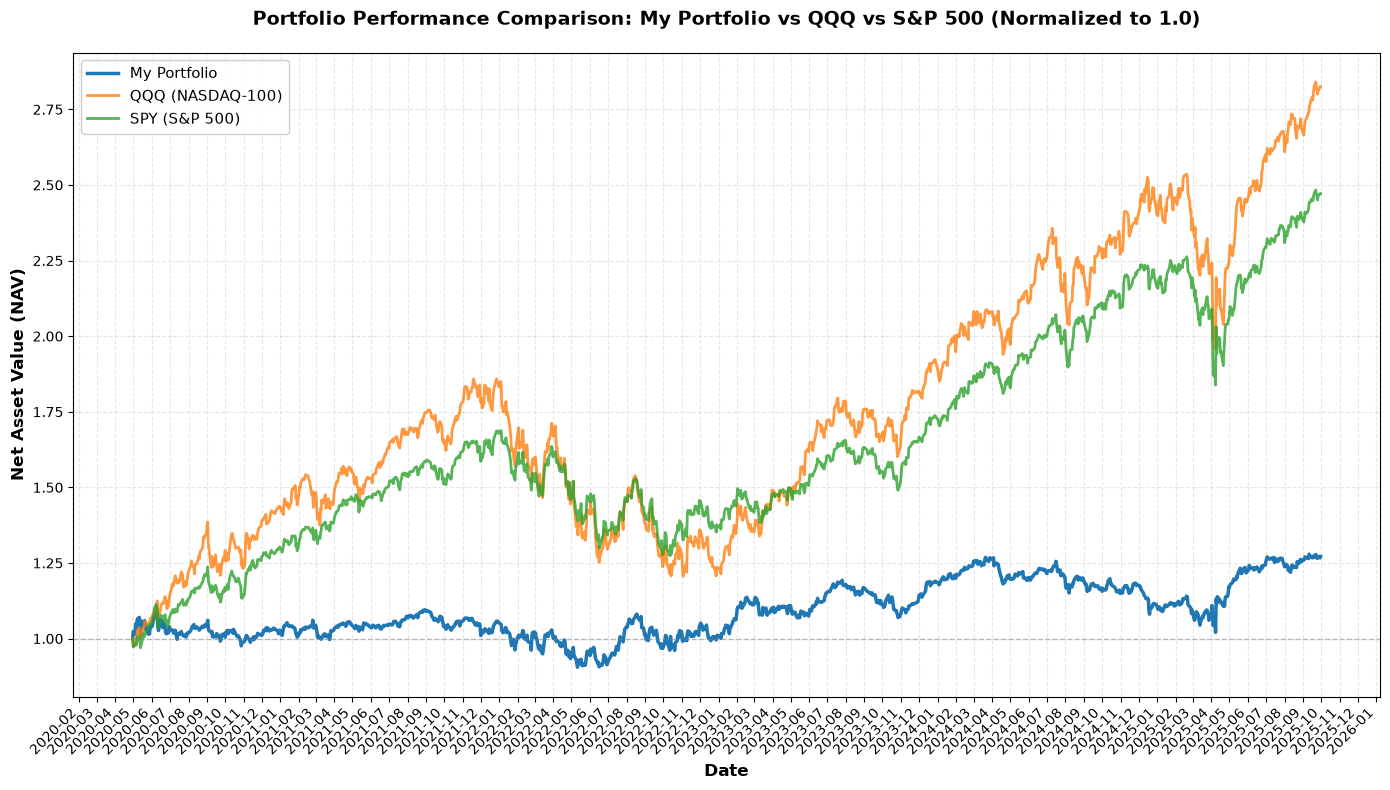

In [10]:
QQQ = yf.download("QQQ", start=result.index.min(), end=result.index.max(), progress=False, multi_level_index=False)
spy = yf.download("SPY", start=result.index.min(), end=result.index.max(), progress=False, multi_level_index=False)

qqq_nav = QQQ['Close'] / QQQ['Close'].iloc[0]
spy_nav = spy['Close'] / spy['Close'].iloc[0]

# Create a dataframe with all NAVs
comparison_df = pd.DataFrame({
    'Portfolio': result['nav'],
    'QQQ': qqq_nav,
    'SPY': spy_nav
})

# Forward fill to handle missing dates
comparison_df = comparison_df.fillna(method='ffill')

# Remove rows with NaN
comparison_df = comparison_df.dropna()

# Normalize all NAV curves to start from 1.0
print("Normalizing NAV curves to start from 1.0...")
comparison_df = comparison_df / comparison_df.iloc[0]

print(f"Aligned data shape: {comparison_df.shape}")
print(f"Date range: {comparison_df.index.min()} to {comparison_df.index.max()}")

fig, ax = plt.subplots(figsize=(14, 8))

# Plot NAV curves
ax.plot(comparison_df.index, comparison_df['Portfolio'], label='My Portfolio', linewidth=2.5, color='#1f77b4')
ax.plot(comparison_df.index, comparison_df['QQQ'], label='QQQ (NASDAQ-100)', linewidth=2, color='#ff7f0e', alpha=0.8)
ax.plot(comparison_df.index, comparison_df['SPY'], label='SPY (S&P 500)', linewidth=2, color='#2ca02c', alpha=0.8)

# Add horizontal line at 1.0
ax.axhline(y=1.0, color='gray', linestyle='--', linewidth=1, alpha=0.5)

# Formatting
ax.set_xlabel('Date', fontsize=12, fontweight='bold')
ax.set_ylabel('Net Asset Value (NAV)', fontsize=12, fontweight='bold')
ax.set_title('Portfolio Performance Comparison: My Portfolio vs QQQ vs S&P 500 (Normalized to 1.0)', 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(fontsize=11, loc='best', framealpha=0.95)
ax.grid(True, alpha=0.3, linestyle='--')

# Format x-axis
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45, ha='right')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.2f}'))

plt.tight_layout()

# Save figure
output_file = 'portfolio_comparison_chart.png'
plt.savefig(output_file, dpi=300, bbox_inches='tight')
print(f"Chart saved to: {output_file}")

plt.show()

In [ ]:
###########################################################################
# Your own strategy and visulization can be built based on the above code #
###########################################################################

# Independent Portfolio Research — Submission Guide

**Scope.** The course-provided FinRL-Trading notebook above the separator is preserved as supplied. All subsequent code is the independent portfolio research extension. The stored outputs are from the completed local run and are retained for review; this organization pass does **not** rerun or change any experiment.

**Environment and execution.** Use the project `source_code/` directory as the Jupyter working directory. The portfolio extension starts from `prepared/daily.csv`, `prepared/final_ratios.csv`, and `results/stock_selected.csv` generated by the upstream workflow. Later audit cells also require source files in the adjacent `data/` directory, original sector files, `prepare_data.py`, and model-result files. The source notebook's preliminary preprocessing cells have unfilled path placeholders, so running this entire notebook from an empty environment requires preparing those inputs first. Benchmark retrieval uses `yfinance` and requires internet access.

**Navigation.** Base backtests (Cells 1–4) → portfolio optimization (5–9) → alternative allocation strategies (10–25) → signal/robustness/attribution checks (26–34) → integrated strategy comparison and ML diagnostics (35–39) → full-window warm-up and SPY fallback (39A–39D) → timing and point-in-time audits (40–42) → report figures (44–47). Figures 1 and 2 use previously verified summary values; detailed calculations appear in the earlier model-selection and strategy-comparison cells.


In [2]:

# ============================================================
# Cell 1 - Load Data and Calculate Close-to-Close Returns
# ============================================================

import numpy as np
import pandas as pd

Stock_Index_price_file = "./prepared/daily.csv"
Stock_Selected_file = "./results/stock_selected.csv"

# ------------------------------------------------------------
# 1. Load ML-selected stocks
# ------------------------------------------------------------

stock_selected = pd.read_csv(
    Stock_Selected_file,
    parse_dates=["trade_date"]
)

stock_selected = stock_selected.sort_values(
    ["trade_date", "tic"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 2. Load existing adjusted closing prices
# ------------------------------------------------------------

daily_prices = pd.read_csv(
    Stock_Index_price_file,
    usecols=["tic", "datadate", "close_adj"],
    parse_dates=["datadate"]
)

daily_prices["close_adj"] = pd.to_numeric(
    daily_prices["close_adj"],
    errors="coerce"
)

# Check duplicate ticker-date records
assert not daily_prices.duplicated(
    ["datadate", "tic"]
).any(), "Duplicate price records found."

# ------------------------------------------------------------
# 3. Construct adjusted closing price matrix
# ------------------------------------------------------------

close_prices = (
    daily_prices
    .pivot(
        index="datadate",
        columns="tic",
        values="close_adj"
    )
    .sort_index()
)

# ------------------------------------------------------------
# 4. Calculate close-to-close returns
# ------------------------------------------------------------

daily_returns = (
    close_prices
    .pct_change(fill_method=None)
    .replace([np.inf, -np.inf], np.nan)
)

# ------------------------------------------------------------
# 5. Data coverage diagnostics
# ------------------------------------------------------------

selected_tickers = set(stock_selected["tic"].unique())
available_tickers = set(close_prices.columns)

missing_tickers = sorted(
    selected_tickers - available_tickers
)

print("=" * 60)
print("CLOSE-TO-CLOSE DATA PREPARATION")
print("=" * 60)

print("\nML Selection:")
print("Records:", len(stock_selected))
print("Unique stocks:", len(selected_tickers))

print("\nPrice Data:")
print("Price matrix shape:", close_prices.shape)
print("Return matrix shape:", daily_returns.shape)

print("\nPrice date range:")
print(close_prices.index.min().date())
print(close_prices.index.max().date())

print("\nStock coverage:")
print("Available selected stocks:",
      len(selected_tickers & available_tickers))
print("Missing selected stocks:", len(missing_tickers))

print("\nSample daily returns:")
print(daily_returns.iloc[1:6, :5].round(5))

assert not close_prices.empty
assert not daily_returns.empty

print("\nCell 1 completed successfully.")


CLOSE-TO-CLOSE DATA PREPARATION

ML Selection:
Records: 174571
Unique stocks: 418

Price Data:
Price matrix shape: (2590, 501)
Return matrix shape: (2590, 501)

Price date range:
2015-06-15
2025-09-30

Stock coverage:
Available selected stocks: 356
Missing selected stocks: 62

Sample daily returns:
tic               A     AAPL     ABBV  ABNB      ABT
datadate                                            
2015-06-16  0.00689  0.00564 -0.00206   NaN  0.00859
2015-06-17 -0.00466 -0.00245  0.01512   NaN  0.00175
2015-06-18  0.00743  0.00456  0.01783   NaN  0.02826
2015-06-19 -0.01011 -0.01014  0.00710   NaN -0.00097
2015-06-22  0.00800  0.00812  0.00925   NaN  0.00292

Cell 1 completed successfully.


In [3]:

# ============================================================
# Cell 2 - Construct Lagged ML Equal Weight Portfolio
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Construct daily stock selection matrix
# ------------------------------------------------------------

selection_matrix = (
    stock_selected[["trade_date", "tic"]]
    .drop_duplicates()
    .assign(selected=1.0)
    .pivot(
        index="trade_date",
        columns="tic",
        values="selected"
    )
    .fillna(0.0)
    .sort_index()
)

# ------------------------------------------------------------
# 2. Construct daily equal weights
# ------------------------------------------------------------

n_selected = selection_matrix.sum(axis=1)

assert (n_selected > 0).all(), (
    "Some selection dates have no stocks."
)

ml_ew_target_weights = selection_matrix.div(
    n_selected,
    axis=0
)

# ------------------------------------------------------------
# 3. Lag weights by one selection date
# ------------------------------------------------------------

ml_ew_lagged_weights = (
    ml_ew_target_weights
    .shift(1)
    .fillna(0.0)
)

# ------------------------------------------------------------
# 4. Determine backtest dates
# ------------------------------------------------------------

backtest_dates = (
    ml_ew_lagged_weights.index
    .intersection(daily_returns.index)
)

ml_ew_backtest_weights = (
    ml_ew_lagged_weights
    .loc[backtest_dates]
)

# Keep the original 418-stock selection universe.
# Missing stock returns will be treated as zero
# in the reproduction backtest, as before.

# ------------------------------------------------------------
# 5. Diagnostics
# ------------------------------------------------------------

print("=" * 60)
print("LAGGED ML EQUAL WEIGHT PORTFOLIO")
print("=" * 60)

print("\nOriginal target weight matrix:")
print(ml_ew_target_weights.shape)

print("\nLagged weight matrix:")
print(ml_ew_lagged_weights.shape)

print("\nBacktest weight matrix:")
print(ml_ew_backtest_weights.shape)

print("\nBacktest date range:")
print(backtest_dates.min().date())
print(backtest_dates.max().date())

print("\nNumber of selected stocks per day:")
print(n_selected.describe().round(2))

print("\nTarget weight sum:")
print(
    ml_ew_target_weights.sum(axis=1)
    .describe()
    .round(6)
)

print("\nLagged weight sum:")
print(
    ml_ew_backtest_weights.sum(axis=1)
    .describe()
    .round(6)
)

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

assert np.allclose(
    ml_ew_target_weights.sum(axis=1),
    1.0
)

assert np.allclose(
    ml_ew_lagged_weights.iloc[0].sum(),
    0.0
)

assert np.allclose(
    ml_ew_lagged_weights.iloc[1:].sum(axis=1),
    1.0
)

assert (
    ml_ew_lagged_weights >= 0
).all().all()

print("\nAll portfolio weight checks passed.")
print("Cell 2 completed successfully.")


LAGGED ML EQUAL WEIGHT PORTFOLIO

Original target weight matrix:
(1453, 418)

Lagged weight matrix:
(1453, 418)

Backtest weight matrix:
(1361, 418)

Backtest date range:
2020-05-01
2025-09-30

Number of selected stocks per day:
count    1453.00
mean      120.15
std        24.91
min         1.00
25%       123.00
50%       125.00
75%       126.00
max       159.00
dtype: float64

Target weight sum:
count    1453.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
dtype: float64

Lagged weight sum:
count    1361.000000
mean        0.999265
std         0.027106
min         0.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         1.000000
dtype: float64

All portfolio weight checks passed.
Cell 2 completed successfully.


In [4]:

# ============================================================
# Cell 3 - Lagged Close-to-Close Equal Weight Backtest
# ============================================================

import numpy as np
import pandas as pd

FEE_RATE = 0.001

# ------------------------------------------------------------
# 1. Define a reusable backtest function
# ------------------------------------------------------------

def run_backtest(weights, returns, fee_rate=0.001):

    weights = weights.sort_index().copy()
    returns = returns.sort_index()

    # Align trading dates
    common_dates = weights.index.intersection(
        returns.index
    )

    w = weights.loc[common_dates]

    r = returns.reindex(
        index=common_dates,
        columns=w.columns
    ).fillna(0.0)

    if len(common_dates) == 0:
        raise ValueError("No common trading dates.")

    # --------------------------------------------------------
    # 2. Calculate portfolio daily returns
    # --------------------------------------------------------

    gross_ret = (w * r).sum(axis=1)

    # --------------------------------------------------------
    # 3. Calculate turnover and transaction costs
    # --------------------------------------------------------

    turnover = w.diff().abs().sum(axis=1)

    cost = fee_rate * turnover

    # Match original notebook's initial cost convention
    cost.iloc[0] = 0.0

    net_ret = gross_ret - cost

    # --------------------------------------------------------
    # 4. Calculate cumulative NAV
    # --------------------------------------------------------

    nav = (1.0 + net_ret).cumprod()

    result = pd.DataFrame({
        "gross_ret": gross_ret,
        "turnover": turnover,
        "cost": cost,
        "net_ret": net_ret,
        "nav": nav
    })

    # Add initial NAV = 1
    initial_date = (
        common_dates[0] - pd.Timedelta(days=1)
    )

    initial_row = pd.DataFrame({
        "gross_ret": [0.0],
        "turnover": [0.0],
        "cost": [0.0],
        "net_ret": [0.0],
        "nav": [1.0]
    }, index=[initial_date])

    result = pd.concat(
        [initial_row, result]
    )

    return result


# ------------------------------------------------------------
# 5. Run ML Equal Weight backtest
# ------------------------------------------------------------

ml_ew_result = run_backtest(
    weights=ml_ew_backtest_weights,
    returns=daily_returns,
    fee_rate=FEE_RATE
)

# ------------------------------------------------------------
# 6. Calculate performance statistics
# ------------------------------------------------------------

nav = ml_ew_result["nav"]
ret = ml_ew_result["net_ret"].iloc[1:]

n_days = len(ret)

total_return = nav.iloc[-1] - 1

cagr = nav.iloc[-1] ** (252 / n_days) - 1

volatility = ret.std() * np.sqrt(252)

sharpe = (
    ret.mean() / ret.std() * np.sqrt(252)
    if ret.std() > 0 else np.nan
)

max_drawdown = (
    nav / nav.cummax() - 1
).min()

total_turnover = ml_ew_result["turnover"].sum()

total_cost = ml_ew_result["cost"].sum()

# ------------------------------------------------------------
# 7. Print performance summary
# ------------------------------------------------------------

print("=" * 65)
print("ML EQUAL WEIGHT - LAGGED CLOSE-TO-CLOSE")
print("=" * 65)

print("\nBacktest Period:")
print(nav.index.min().date(), "to",
      nav.index.max().date())

print("\nTrading Days:", n_days)

print("\nPerformance Metrics:")
print(f"Final NAV:          {nav.iloc[-1]:.6f}")
print(f"Total Return:       {total_return * 100:.3f}%")
print(f"CAGR:               {cagr * 100:.3f}%")
print(f"Volatility:         {volatility * 100:.3f}%")
print(f"Sharpe Ratio:       {sharpe:.4f}")
print(f"Max Drawdown:       {max_drawdown * 100:.3f}%")
print(f"Total Turnover:     {total_turnover:.4f}")
print(f"Total Cost:         {total_cost:.4f}")

print("\nFirst 5 rows:")
print(ml_ew_result.head())

print("\nLast 5 rows:")
print(ml_ew_result.tail())

# ------------------------------------------------------------
# 8. Validation
# ------------------------------------------------------------

assert np.isfinite(nav).all()
assert (nav > 0).all()
assert len(ml_ew_result) == n_days + 1

print("\nAll backtest checks passed.")

# Compare with previous result
REFERENCE_NAV = 2.2724

difference = abs(nav.iloc[-1] - REFERENCE_NAV)

print(f"\nPrevious Reference NAV: {REFERENCE_NAV:.4f}")
print(f"Difference: {difference:.6f}")

if difference < 0.0005:
    print("Previous lagged close-to-close result reproduced.")
else:
    print("WARNING: Result differs from previous reference.")


ML EQUAL WEIGHT - LAGGED CLOSE-TO-CLOSE

Backtest Period:
2020-04-30 to 2025-09-30

Trading Days: 1361

Performance Metrics:
Final NAV:          2.272416
Total Return:       127.242%
CAGR:               16.414%
Volatility:         18.268%
Sharpe Ratio:       0.9234
Max Drawdown:       -24.721%
Total Turnover:     45.1039
Total Cost:         0.0451

First 5 rows:
            gross_ret  turnover   cost   net_ret       nav
2020-04-30   0.000000       0.0  0.000  0.000000  1.000000
2020-05-01   0.000000       0.0  0.000  0.000000  1.000000
2020-05-04  -0.022256       1.0  0.001 -0.023256  0.976744
2020-05-05  -0.013344       0.0  0.000 -0.013344  0.963710
2020-05-06  -0.012792       2.0  0.002 -0.014792  0.949455

Last 5 rows:
            gross_ret  turnover  cost   net_ret       nav
2025-09-24  -0.005861       0.0   0.0 -0.005861  2.255202
2025-09-25  -0.004800       0.0   0.0 -0.004800  2.244375
2025-09-26   0.006278       0.0   0.0  0.006278  2.258465
2025-09-29   0.003650       0.0   0

ML EQUAL WEIGHT VS MARKET BENCHMARKS

Backtest Period:
2020-04-30 to 2025-09-30

Performance Comparison:
                 Final NAV  Total Return (%)  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)
ML Equal Weight     2.2724          127.2416   16.4144         18.2678  0.9234          -24.7215
SPY                 2.4807          148.0732   18.3204         17.5468  1.0466          -24.4964
QQQ                 2.8325          183.2513   21.2616         23.0274  0.9525          -35.1187

Final NAV:
ML Equal Weight    2.272416
SPY                2.480732
QQQ                2.832513
Name: 2025-09-30 00:00:00, dtype: float64

ML Equal Weight vs SPY:
-8.397%


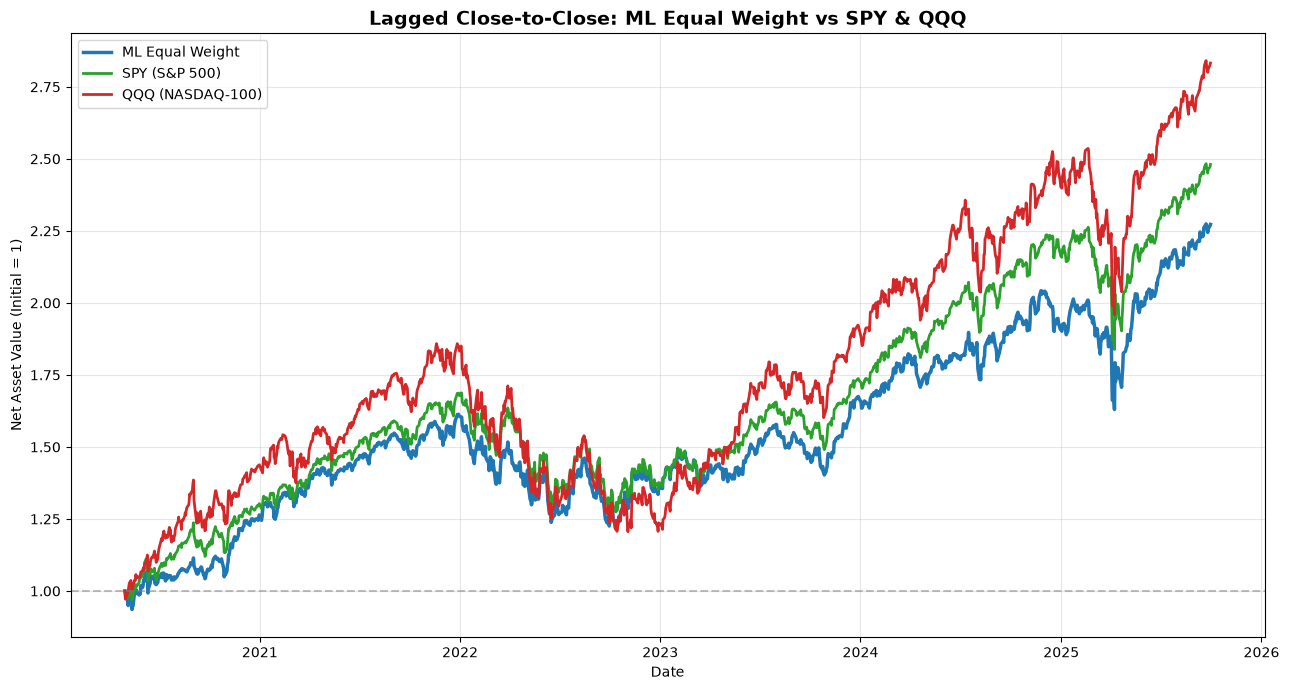


All benchmark checks passed.
Cell 4 completed successfully.


In [5]:

# ============================================================
# Cell 4 - ML Equal Weight vs SPY and QQQ
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# ------------------------------------------------------------
# 1. Define common evaluation dates
# ------------------------------------------------------------

eval_dates = ml_ew_result.index

comparison_nav = pd.DataFrame(index=eval_dates)

comparison_nav["ML Equal Weight"] = ml_ew_result["nav"]

# ------------------------------------------------------------
# 2. Download SPY and QQQ adjusted close prices
# ------------------------------------------------------------

for ticker in ["SPY", "QQQ"]:

    benchmark_data = yf.download(
        ticker,
        start=eval_dates.min().strftime("%Y-%m-%d"),
        end=(
            eval_dates.max() + pd.Timedelta(days=1)
        ).strftime("%Y-%m-%d"),
        auto_adjust=True,
        multi_level_index=False,
        progress=False
    )

    if benchmark_data.empty:
        raise ValueError(f"Failed to download {ticker}")

    benchmark_close = benchmark_data["Close"].copy()

    benchmark_close.index = (
        pd.to_datetime(benchmark_close.index)
        .tz_localize(None)
        .normalize()
    )

    benchmark_close = benchmark_close.reindex(eval_dates)

    if benchmark_close.isna().any():
        missing_dates = benchmark_close[
            benchmark_close.isna()
        ].index.tolist()

        raise ValueError(
            f"{ticker} missing prices on: {missing_dates[:5]}"
        )

    # Normalize NAV to 1 on the initial date
    comparison_nav[ticker] = (
        benchmark_close / benchmark_close.iloc[0]
    )

# ------------------------------------------------------------
# 3. Calculate comparable performance metrics
# ------------------------------------------------------------

def performance_metrics(nav):

    returns = nav.pct_change(
        fill_method=None
    ).dropna()

    n_days = len(returns)

    total_return = nav.iloc[-1] / nav.iloc[0] - 1

    cagr = (
        (nav.iloc[-1] / nav.iloc[0])
        ** (252 / n_days) - 1
    )

    volatility = returns.std() * np.sqrt(252)

    sharpe = (
        returns.mean() / returns.std() * np.sqrt(252)
        if returns.std() > 0 else np.nan
    )

    max_drawdown = (
        nav / nav.cummax() - 1
    ).min()

    return {
        "Final NAV": nav.iloc[-1],
        "Total Return (%)": total_return * 100,
        "CAGR (%)": cagr * 100,
        "Volatility (%)": volatility * 100,
        "Sharpe": sharpe,
        "Max Drawdown (%)": max_drawdown * 100
    }


comparison_metrics = pd.DataFrame({
    name: performance_metrics(comparison_nav[name])
    for name in comparison_nav.columns
}).T

# ------------------------------------------------------------
# 4. Print performance comparison
# ------------------------------------------------------------

print("=" * 70)
print("ML EQUAL WEIGHT VS MARKET BENCHMARKS")
print("=" * 70)

print("\nBacktest Period:")
print(eval_dates.min().date(), "to",
      eval_dates.max().date())

print("\nPerformance Comparison:")
print(comparison_metrics.round(4).to_string())

print("\nFinal NAV:")
print(comparison_nav.iloc[-1].round(6))

print("\nML Equal Weight vs SPY:")
print(
    f"{(comparison_nav['ML Equal Weight'].iloc[-1] / comparison_nav['SPY'].iloc[-1] - 1) * 100:.3f}%"
)

# ------------------------------------------------------------
# 5. Plot cumulative NAV
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(
    comparison_nav.index,
    comparison_nav["ML Equal Weight"],
    label="ML Equal Weight",
    linewidth=2.5,
    color="#1f77b4"
)

ax.plot(
    comparison_nav.index,
    comparison_nav["SPY"],
    label="SPY (S&P 500)",
    linewidth=2,
    color="#2ca02c"
)

ax.plot(
    comparison_nav.index,
    comparison_nav["QQQ"],
    label="QQQ (NASDAQ-100)",
    linewidth=2,
    color="#d62728"
)

ax.axhline(
    1.0,
    linestyle="--",
    color="gray",
    alpha=0.5
)

ax.set_title(
    "Lagged Close-to-Close: ML Equal Weight vs SPY & QQQ",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("Net Asset Value (Initial = 1)")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------

comparison_nav.to_csv(
    "./results/ml_ew_benchmark_nav.csv"
)

comparison_metrics.to_csv(
    "./results/ml_ew_benchmark_metrics.csv"
)

# ------------------------------------------------------------
# 7. Validation
# ------------------------------------------------------------

assert not comparison_nav.isna().any().any()

assert np.isfinite(
    comparison_nav.to_numpy()
).all()

assert (
    comparison_nav > 0
).all().all()

print("\nAll benchmark checks passed.")
print("Cell 4 completed successfully.")


## Constrained Mean–Variance Optimization

Cells 5–9 build lagged ML signals, solve a long-only sector-constrained optimization, and compare its 2020–2025 performance with matched monthly equal weighting, SPY, and QQQ. The optimizer can emit a SciPy warning about mixed equality/inequality constraints; convergence and feasibility checks are reported in the original outputs.


In [6]:

# ============================================================
# Cell 5 - Prepare ML Signals and Historical Risk Data
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MVO_START = pd.Timestamp("2020-09-01")
MVO_END = pd.Timestamp("2025-09-30")

MVO_LOOKBACK = 252
MVO_MIN_HISTORY = 180
MVO_MIN_STOCKS = 40

# ------------------------------------------------------------
# 2. Monthly rebalance dates
# ------------------------------------------------------------

eligible_dates = ml_ew_backtest_weights.index[
    (ml_ew_backtest_weights.index >= MVO_START)
    & (ml_ew_backtest_weights.index <= MVO_END)
]

monthly_rebalance_dates = eligible_dates[
    ~eligible_dates.to_period("M").duplicated()
]

# ------------------------------------------------------------
# 3. Organize historical ML predictions
# ------------------------------------------------------------

ml_predictions = (
    stock_selected[
        ["trade_date", "tic", "predicted_return"]
    ]
    .dropna()
    .sort_values(["trade_date", "tic"])
    .drop_duplicates(
        subset=["trade_date", "tic"],
        keep="last"
    )
)

ml_prediction_dates = pd.DatetimeIndex(
    sorted(ml_predictions["trade_date"].unique())
)

prediction_snapshots = {
    date: group.set_index("tic")["predicted_return"]
    for date, group in ml_predictions.groupby("trade_date")
}

# ------------------------------------------------------------
# 4. Prepare monthly optimization inputs
# ------------------------------------------------------------

mvo_inputs = {}
mvo_records = []

for trade_date in monthly_rebalance_dates:

    # Most recent prediction strictly before trade date
    signal_pos = ml_prediction_dates.searchsorted(
        trade_date,
        side="left"
    ) - 1

    if signal_pos < 0:
        raise ValueError(
            f"No historical ML signal for {trade_date}"
        )

    signal_date = ml_prediction_dates[signal_pos]

    predictions = prediction_snapshots[signal_date]

    # Historical returns strictly before trade date
    history = daily_returns.loc[
        daily_returns.index < trade_date
    ].tail(MVO_LOOKBACK)

    # Eligible stocks with price coverage
    candidate_tickers = predictions.index.intersection(
        daily_returns.columns
    )

    # Require valid execution-date closing price
    current_prices = close_prices.loc[
        trade_date, candidate_tickers
    ]

    valid_price = (
        current_prices.notna()
        & np.isfinite(current_prices)
        & (current_prices > 0)
    )

    candidate_tickers = current_prices.index[
        valid_price
    ]

    # Require sufficient historical returns
    historical_counts = (
        history[candidate_tickers]
        .count()
    )

    eligible_tickers = historical_counts.index[
        historical_counts >= MVO_MIN_HISTORY
    ]

    if len(eligible_tickers) < MVO_MIN_STOCKS:
        raise ValueError(
            f"Insufficient stocks on {trade_date}: "
            f"{len(eligible_tickers)}"
        )

    # --------------------------------------------------------
    # Robust ML signal normalization
    # --------------------------------------------------------

    raw_signal = predictions.reindex(
        eligible_tickers
    ).astype(float)

    # Winsorize extreme predictions
    lower = raw_signal.quantile(0.05)
    upper = raw_signal.quantile(0.95)

    clipped_signal = raw_signal.clip(
        lower=lower,
        upper=upper
    )

    signal_std = clipped_signal.std(ddof=0)

    if signal_std > 0:
        normalized_signal = (
            clipped_signal - clipped_signal.mean()
        ) / signal_std
    else:
        normalized_signal = pd.Series(
            0.0,
            index=eligible_tickers
        )

    normalized_signal = normalized_signal.clip(
        -2.0, 2.0
    )

    normalized_signal -= normalized_signal.mean()

    # --------------------------------------------------------
    # Store inputs for next cell's optimizer
    # --------------------------------------------------------

    mvo_inputs[trade_date] = {
        "signal_date": signal_date,
        "tickers": eligible_tickers.tolist(),
        "signal": normalized_signal,
        "history": history[
            eligible_tickers
        ].copy()
    }

    mvo_records.append({
        "trade_date": trade_date,
        "signal_date": signal_date,
        "n_stocks": len(eligible_tickers),
        "min_history": historical_counts[
            eligible_tickers
        ].min(),
        "signal_std": normalized_signal.std()
    })

# ------------------------------------------------------------
# 5. Diagnostics
# ------------------------------------------------------------

mvo_info = pd.DataFrame(mvo_records)

print("=" * 65)
print("MVO INPUT PREPARATION")
print("=" * 65)

print("\nMonthly Rebalance Dates:")
print(len(monthly_rebalance_dates))

print("\nFirst Rebalance:")
print(monthly_rebalance_dates.min().date())

print("\nLast Rebalance:")
print(monthly_rebalance_dates.max().date())

print("\nEligible Stocks per Rebalance:")
print(mvo_info["n_stocks"].describe().round(2))

print("\nSignal Standard Deviation:")
print(mvo_info["signal_std"].describe().round(3))

print("\nFirst 5 Rebalances:")
print(mvo_info.head().to_string(index=False))

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

assert (
    mvo_info["signal_date"]
    < mvo_info["trade_date"]
).all()

assert (
    mvo_info["n_stocks"] >= MVO_MIN_STOCKS
).all()

assert len(mvo_inputs) == len(monthly_rebalance_dates)

for trade_date, inputs in mvo_inputs.items():
    assert inputs["history"].index.max() < trade_date
    assert np.isfinite(inputs["signal"]).all()

print("\nAll MVO input checks passed.")
print("Cell 5 completed successfully.")


MVO INPUT PREPARATION

Monthly Rebalance Dates:
61

First Rebalance:
2020-09-01

Last Rebalance:
2025-09-02

Eligible Stocks per Rebalance:
count     61.00
mean     112.39
std        9.07
min       95.00
25%      105.00
50%      113.00
75%      119.00
max      142.00
Name: n_stocks, dtype: float64

Signal Standard Deviation:
count    61.000
mean      0.959
std       0.051
min       0.849
25%       0.916
50%       0.983
75%       1.005
max       1.005
Name: signal_std, dtype: float64

First 5 Rebalances:
trade_date signal_date  n_stocks  min_history  signal_std
2020-09-01  2020-08-31       117          252    0.989123
2020-10-01  2020-09-30       120          252    1.002439
2020-11-02  2020-10-30        95          252    0.983167
2020-12-01  2020-11-30       102          252    1.004938
2021-01-04  2021-01-01        99          252    0.998701

All MVO input checks passed.
Cell 5 completed successfully.


In [7]:

# ============================================================
# Cell 6 - ML-Based Constrained Mean-Variance Optimization
# ============================================================

import numpy as np
import pandas as pd

from scipy.optimize import minimize, LinearConstraint
from sklearn.covariance import LedoitWolf

# ------------------------------------------------------------
# 1. Fixed optimizer parameters
# ------------------------------------------------------------

MVO_ALPHA_SCALE = 0.05
MVO_RISK_AVERSION = 4.0
MVO_TRACKING_PENALTY = 20.0

MVO_MAX_WEIGHT = 0.025
MVO_SECTOR_TOLERANCE = 0.05

# ------------------------------------------------------------
# 2. Load historical sector classifications
# ------------------------------------------------------------

mvo_sector_data = pd.read_csv(
    "./prepared/final_ratios.csv",
    usecols=["tic", "reportdate", "gsector"],
    parse_dates=["reportdate"]
)

mvo_sector_data = (
    mvo_sector_data
    .dropna(subset=["tic", "reportdate", "gsector"])
    .sort_values(["tic", "reportdate"])
    .drop_duplicates(
        ["tic", "reportdate"],
        keep="last"
    )
)

# ------------------------------------------------------------
# 3. Define optimizer
# ------------------------------------------------------------

def optimize_ml_mvo(trade_date):

    inputs = mvo_inputs[trade_date]

    tickers = pd.Index(inputs["tickers"])
    n = len(tickers)

    signal = inputs["signal"].reindex(
        tickers
    ).to_numpy(dtype=float)

    history = inputs["history"].reindex(
        columns=tickers
    ).astype(float)

    signal_date = inputs["signal_date"]

    # --------------------------------------------------------
    # 4. Expected return signal
    # --------------------------------------------------------

    # Annualized relative return preference.
    # This is not a calibrated forecast of actual returns.
    alpha = MVO_ALPHA_SCALE * signal

    # --------------------------------------------------------
    # 5. Estimate annualized covariance
    # --------------------------------------------------------

    # Demean using historical observations only.
    # Missing observations are set to the historical mean.
    history_centered = history.sub(
        history.mean(axis=0),
        axis=1
    ).fillna(0.0)

    covariance_model = LedoitWolf(
        assume_centered=True
    )

    covariance_model.fit(
        history_centered.to_numpy()
    )

    covariance = (
        covariance_model.covariance_ * 252.0
    )

    # Numerical regularization
    covariance += np.eye(n) * 1e-7

    # --------------------------------------------------------
    # 6. Equal weight reference
    # --------------------------------------------------------

    ew_weights = np.ones(n) / n

    # --------------------------------------------------------
    # 7. Point-in-time sector mapping
    # --------------------------------------------------------

    sector_history = mvo_sector_data.loc[
        (mvo_sector_data["reportdate"] <= signal_date)
        & (mvo_sector_data["tic"].isin(tickers))
    ]

    latest_sectors = (
        sector_history
        .sort_values(["tic", "reportdate"])
        .drop_duplicates("tic", keep="last")
        .set_index("tic")["gsector"]
        .reindex(tickers)
    )

    if latest_sectors.isna().any():
        missing = latest_sectors[
            latest_sectors.isna()
        ].index.tolist()

        raise ValueError(
            f"Missing sector mapping: {missing}"
        )

    sector_codes = latest_sectors.to_numpy()
    unique_sectors = np.unique(sector_codes)

    # Sector exposure matrix
    sector_matrix = np.vstack([
        (sector_codes == sector).astype(float)
        for sector in unique_sectors
    ])

    ew_sector_exposure = (
        sector_matrix @ ew_weights
    )

    # Keep sector exposure within +/- 5 percentage
    # points of the matched equal weight portfolio.
    sector_lower = np.maximum(
        0.0,
        ew_sector_exposure - MVO_SECTOR_TOLERANCE
    )

    sector_upper = np.minimum(
        1.0,
        ew_sector_exposure + MVO_SECTOR_TOLERANCE
    )

    # --------------------------------------------------------
    # 8. Portfolio constraints
    # --------------------------------------------------------

    max_weight = max(
        MVO_MAX_WEIGHT,
        2.5 / n
    )

    bounds = [
        (0.0, max_weight)
        for _ in range(n)
    ]

    constraint_matrix = np.vstack([
        np.ones(n),
        sector_matrix
    ])

    lower_bounds = np.concatenate([
        [1.0],
        sector_lower
    ])

    upper_bounds = np.concatenate([
        [1.0],
        sector_upper
    ])

    constraints = LinearConstraint(
        constraint_matrix,
        lower_bounds,
        upper_bounds
    )

    # --------------------------------------------------------
    # 9. Objective and analytical gradient
    # --------------------------------------------------------

    def objective(w):

        expected_alpha = alpha @ w

        portfolio_variance = (
            w @ covariance @ w
        )

        tracking_error = np.sum(
            (w - ew_weights) ** 2
        )

        value = (
            -expected_alpha
            + 0.5 * MVO_RISK_AVERSION
            * portfolio_variance
            + 0.5 * MVO_TRACKING_PENALTY
            * tracking_error
        )

        gradient = (
            -alpha
            + MVO_RISK_AVERSION * (covariance @ w)
            + MVO_TRACKING_PENALTY
            * (w - ew_weights)
        )

        return value, gradient

    # --------------------------------------------------------
    # 10. Solve constrained optimization
    # --------------------------------------------------------

    result = minimize(
        objective,
        x0=ew_weights,
        method="SLSQP",
        jac=True,
        bounds=bounds,
        constraints=[constraints],
        options={
            "maxiter": 400,
            "ftol": 1e-10,
            "disp": False
        }
    )

    if not result.success:
        raise RuntimeError(
            f"Optimization failed on {trade_date}: "
            f"{result.message}"
        )

    optimized_weights = pd.Series(
        result.x,
        index=tickers,
        name="weight"
    )

    # --------------------------------------------------------
    # 11. Validate optimized weights
    # --------------------------------------------------------

    sector_exposure = (
        sector_matrix @ optimized_weights.to_numpy()
    )

    assert np.isclose(
        optimized_weights.sum(), 1.0, atol=1e-6
    )

    assert optimized_weights.min() >= -1e-7

    assert optimized_weights.max() <= max_weight + 1e-6

    assert np.all(
        sector_exposure >= sector_lower - 1e-6
    )

    assert np.all(
        sector_exposure <= sector_upper + 1e-6
    )

    diagnostics = {
        "trade_date": trade_date,
        "n_stocks": n,
        "n_sectors": len(unique_sectors),
        "max_weight": optimized_weights.max(),
        "min_weight": optimized_weights.min(),
        "weight_sum": optimized_weights.sum(),
        "iterations": result.nit,
        "shrinkage": covariance_model.shrinkage_,
        "sector_max_deviation": np.max(
            np.abs(
                sector_exposure - ew_sector_exposure
            )
        )
    }

    return optimized_weights, diagnostics


# ------------------------------------------------------------
# 12. Test the optimizer on the first rebalance date
# ------------------------------------------------------------

mvo_test_date = monthly_rebalance_dates[0]

mvo_test_weights, mvo_test_diagnostics = (
    optimize_ml_mvo(mvo_test_date)
)

print("=" * 65)
print("ML-BASED CONSTRAINED MVO - SINGLE-DATE TEST")
print("=" * 65)

print("\nTest Date:")
print(mvo_test_date.date())

print("\nOptimization Diagnostics:")
for key, value in mvo_test_diagnostics.items():
    print(f"{key}: {value}")

print("\nWeight Distribution:")
print(
    mvo_test_weights.describe().round(6)
)

print("\nTop 10 Portfolio Weights:")
print(
    mvo_test_weights
    .sort_values(ascending=False)
    .head(10)
    .round(6)
)

print("\nNumber of Zero-Weight Stocks:")
print(int((mvo_test_weights < 1e-7).sum()))

print("\nSingle-date optimizer test passed.")
print("Cell 6 completed successfully.")


ML-BASED CONSTRAINED MVO - SINGLE-DATE TEST

Test Date:
2020-09-01

Optimization Diagnostics:
trade_date: 2020-09-01 00:00:00
n_stocks: 117
n_sectors: 6
max_weight: 0.024196395987271153
min_weight: 0.0
weight_sum: 1.0
iterations: 29
shrinkage: 0.06065413388841244
sector_max_deviation: 0.050000000000000155

Weight Distribution:
count    117.000000
mean       0.008547
std        0.005244
min        0.000000
25%        0.005251
50%        0.009067
75%        0.012299
max        0.024196
Name: weight, dtype: float64

Top 10 Portfolio Weights:
CLX     0.024196
AKAM    0.019477
COST    0.018965
KMB     0.018175
EA      0.017726
TTWO    0.017005
MMC     0.016181
TYL     0.015491
AON     0.015411
UPS     0.014593
Name: weight, dtype: float64

Number of Zero-Weight Stocks:
14

Single-date optimizer test passed.
Cell 6 completed successfully.


c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient use with this method, equality and inequality constraints should be specified in separate elements of the constraint list. 
  constraints = standardize_constraints(constraints, x0, meth)


In [8]:

# ============================================================
# Cell 7 - Generate All Monthly MVO Portfolio Weights
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Initialize monthly target weight matrices
# ------------------------------------------------------------

portfolio_tickers = ml_ew_target_weights.columns

mvo_monthly_weights = pd.DataFrame(
    0.0,
    index=monthly_rebalance_dates,
    columns=portfolio_tickers
)

matched_monthly_ew_weights = pd.DataFrame(
    0.0,
    index=monthly_rebalance_dates,
    columns=portfolio_tickers
)

mvo_diagnostics_records = []

# ------------------------------------------------------------
# 2. Optimize each monthly rebalance
# ------------------------------------------------------------

print("=" * 65)
print("GENERATING MONTHLY MVO PORTFOLIOS")
print("=" * 65)

for i, trade_date in enumerate(monthly_rebalance_dates):

    # Optimize using historical data and ML predictions
    optimized_weights, diagnostics = optimize_ml_mvo(
        trade_date
    )

    tickers = optimized_weights.index
    n_stocks = len(tickers)

    # MVO target weights
    mvo_monthly_weights.loc[
        trade_date, tickers
    ] = optimized_weights.to_numpy()

    # Matched equal-weight reference
    matched_monthly_ew_weights.loc[
        trade_date, tickers
    ] = 1.0 / n_stocks

    # Additional diagnostics
    ew_reference = pd.Series(
        1.0 / n_stocks,
        index=tickers
    )

    diagnostics["l1_deviation_from_ew"] = (
        optimized_weights - ew_reference
    ).abs().sum()

    diagnostics["effective_n_stocks"] = (
        1.0 / np.sum(optimized_weights.to_numpy() ** 2)
    )

    diagnostics["zero_weight_stocks"] = int(
        (optimized_weights < 1e-7).sum()
    )

    mvo_diagnostics_records.append(diagnostics)

    if (i + 1) % 10 == 0 or i == 0 or i == len(monthly_rebalance_dates) - 1:
        print(
            f"Completed {i + 1}/{len(monthly_rebalance_dates)} | "
            f"{trade_date.date()} | "
            f"Stocks: {n_stocks} | "
            f"Max Weight: {optimized_weights.max():.4f}"
        )

# ------------------------------------------------------------
# 3. Diagnostics DataFrame
# ------------------------------------------------------------

mvo_monthly_diagnostics = pd.DataFrame(
    mvo_diagnostics_records
).set_index("trade_date")

# ------------------------------------------------------------
# 4. Compare monthly portfolio characteristics
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MONTHLY PORTFOLIO CONSTRUCTION SUMMARY")
print("=" * 65)

print("\nMVO Weight Matrix:")
print(mvo_monthly_weights.shape)

print("\nMatched Equal Weight Matrix:")
print(matched_monthly_ew_weights.shape)

print("\nRebalance Date Range:")
print(monthly_rebalance_dates.min().date())
print(monthly_rebalance_dates.max().date())

print("\nMVO Portfolio Statistics:")
print(
    mvo_monthly_diagnostics[
        [
            "n_stocks",
            "max_weight",
            "sector_max_deviation",
            "effective_n_stocks",
            "zero_weight_stocks",
            "iterations"
        ]
    ].describe().round(4).to_string()
)

# ------------------------------------------------------------
# 5. Monthly target weight turnover diagnostics
# ------------------------------------------------------------

# This is target-to-target weight change,
# NOT realized trading turnover.
# Actual costs will be calculated during the backtest.

mvo_target_change = (
    mvo_monthly_weights
    .diff()
    .abs()
    .sum(axis=1)
)

matched_ew_target_change = (
    matched_monthly_ew_weights
    .diff()
    .abs()
    .sum(axis=1)
)

print("\nMonthly Target Weight Changes:")
print(
    pd.DataFrame({
        "MVO": mvo_target_change,
        "Matched EW": matched_ew_target_change
    }).describe().round(4).to_string()
)

print("\nFirst 5 Rebalances:")
print(
    mvo_monthly_diagnostics.head().round(4).to_string()
)

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

assert len(mvo_monthly_weights) == len(
    monthly_rebalance_dates
)

assert mvo_monthly_weights.index.equals(
    matched_monthly_ew_weights.index
)

assert mvo_monthly_weights.columns.equals(
    matched_monthly_ew_weights.columns
)

assert np.allclose(
    mvo_monthly_weights.sum(axis=1), 1.0
)

assert np.allclose(
    matched_monthly_ew_weights.sum(axis=1), 1.0
)

assert (
    mvo_monthly_weights >= -1e-7
).all().all()

assert (
    matched_monthly_ew_weights >= 0
).all().all()

assert np.isfinite(
    mvo_monthly_weights.to_numpy()
).all()

assert (
    mvo_monthly_diagnostics["sector_max_deviation"]
    <= MVO_SECTOR_TOLERANCE + 1e-6
).all()

# ------------------------------------------------------------
# 7. Save target weights and diagnostics
# ------------------------------------------------------------

mvo_monthly_weights.to_csv(
    "./results/mvo_monthly_target_weights.csv"
)

matched_monthly_ew_weights.to_csv(
    "./results/matched_monthly_ew_target_weights.csv"
)

mvo_monthly_diagnostics.to_csv(
    "./results/mvo_monthly_diagnostics.csv"
)

print("\nAll monthly portfolio checks passed.")
print("Cell 7 completed successfully.")


c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient use with this method, equality and inequality constraints should be specified in separate elements of the constraint list. 
  constraints = standardize_constraints(constraints, x0, meth)


GENERATING MONTHLY MVO PORTFOLIOS
Completed 1/61 | 2020-09-01 | Stocks: 117 | Max Weight: 0.0242


c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient use with this method, equality and inequality constraints should be specified in separate elements of the constraint list. 
  constraints = standardize_constraints(constraints, x0, meth)
c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient use with this method, equality and inequality constraints should be specified in separate elements of the constraint list. 
  constraints = standardize_constraints(constraints, x0, meth)
c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient

Completed 10/61 | 2021-06-01 | Stocks: 104 | Max Weight: 0.0146


c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient use with this method, equality and inequality constraints should be specified in separate elements of the constraint list. 
  constraints = standardize_constraints(constraints, x0, meth)
c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient use with this method, equality and inequality constraints should be specified in separate elements of the constraint list. 
  constraints = standardize_constraints(constraints, x0, meth)
c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient

...

c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient use with this method, equality and inequality constraints should be specified in separate elements of the constraint list. 
  constraints = standardize_constraints(constraints, x0, meth)
c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient use with this method, equality and inequality constraints should be specified in separate elements of the constraint list. 
  constraints = standardize_constraints(constraints, x0, meth)
c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient

Completed 50/61 | 2024-10-01 | Stocks: 120 | Max Weight: 0.0144


c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient use with this method, equality and inequality constraints should be specified in separate elements of the constraint list. 
  constraints = standardize_constraints(constraints, x0, meth)
c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient use with this method, equality and inequality constraints should be specified in separate elements of the constraint list. 
  constraints = standardize_constraints(constraints, x0, meth)
c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient

Completed 60/61 | 2025-08-01 | Stocks: 123 | Max Weight: 0.0155
Completed 61/61 | 2025-09-02 | Stocks: 124 | Max Weight: 0.0161

MONTHLY PORTFOLIO CONSTRUCTION SUMMARY

MVO Weight Matrix:
(61, 418)

Matched Equal Weight Matrix:
(61, 418)

Rebalance Date Range:
2020-09-01
2025-09-02

MVO Portfolio Statistics:
       n_stocks  max_weight  sector_max_deviation  effective_n_stocks  zero_weight_stocks  iterations
count   61.0000     61.0000               61.0000             61.0000             61.0000     61.0000
mean   112.3934      0.0166                0.0347            100.8560              1.0984     21.0328
std      9.0743      0.0029                0.0145             10.3977              2.9479      4.6151
min     95.0000      0.0136                0.0097             72.8094              0.0000     13.0000
25%    105.0000      0.0148                0.0218             95.7946              0.0000     18.0000
50%    113.0000      0.0157                0.0358            102.2850         

c:\Users\kisum\.conda\envs\finrl\Lib\site-packages\scipy\optimize\_minimize.py:699: OptimizeWarning: Equality and inequality constraints are specified in the same element of the constraint list. For efficient use with this method, equality and inequality constraints should be specified in separate elements of the constraint list. 
  constraints = standardize_constraints(constraints, x0, meth)


MONTHLY MVO VS MATCHED EW VS SPY / QQQ

Backtest Period:
2020-09-01 to 2025-09-30

Trading Days: 1276
Monthly Rebalances: 61

Performance Comparison:
                    Final NAV  Total Return (%)  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)  Total Turnover  Total Cost
ML MVO                 1.9773           97.7341   14.4247         18.9678  0.8063          -29.2779         22.9755      0.0230
Matched Monthly EW     2.1718          117.1843   16.5663         20.0433  0.8660          -29.5172         22.1377      0.0221
SPY                    2.0347          103.4731   15.0735         17.4067  0.8936          -24.4964             NaN         NaN
QQQ                    2.0638          106.3847   15.3971         23.1248  0.7349          -35.1187             NaN         NaN

Final NAV:
ML MVO                1.977341
Matched Monthly EW    2.171843
SPY                   2.034731
QQQ                   2.063847
Name: 2025-09-30 00:00:00, dtype: float64

Relative Performance:
MVO vs Ma

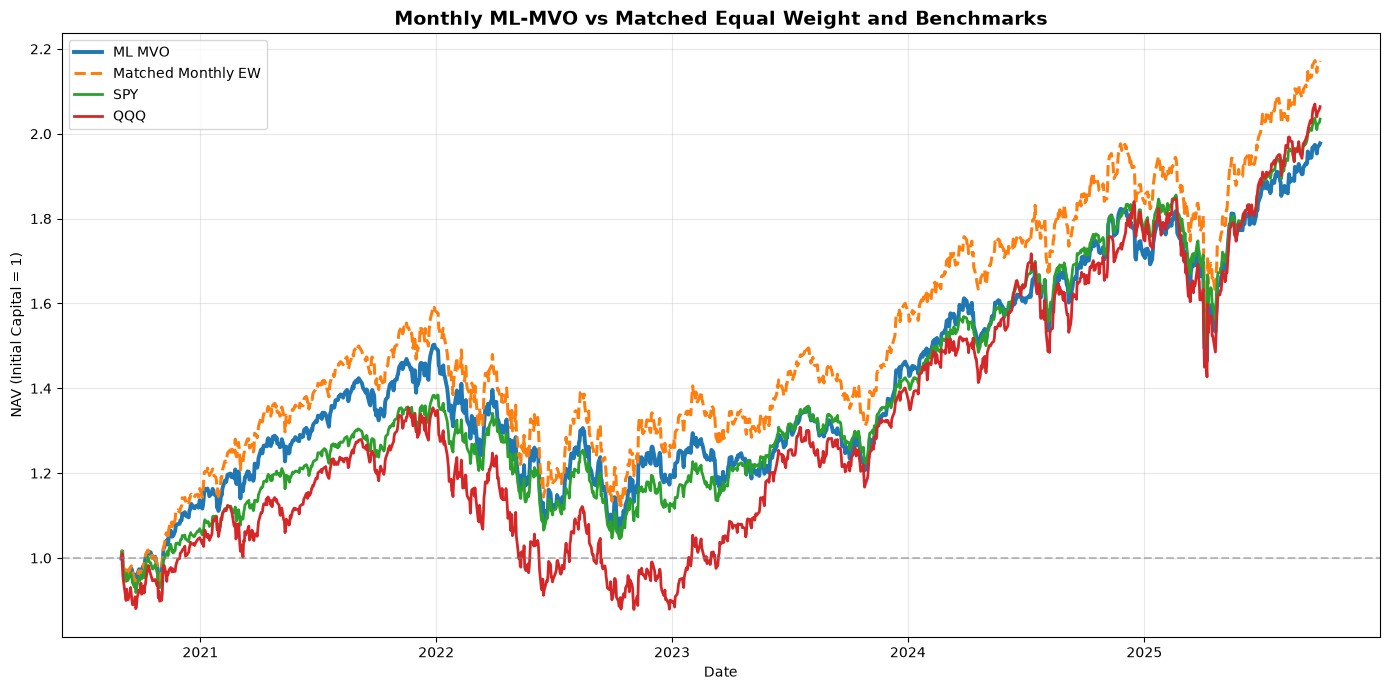


All monthly backtest checks passed.
Cell 8 completed successfully.


In [9]:

# ============================================================
# Cell 8 - Monthly MVO vs Matched Equal Weight Backtest
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Monthly buy-and-hold backtest engine
# ------------------------------------------------------------

def run_monthly_backtest(
    target_weights,
    daily_returns,
    fee_rate=0.001
):

    targets = target_weights.sort_index().copy()

    trading_dates = daily_returns.index[
        (daily_returns.index >= targets.index.min())
        & (daily_returns.index <= pd.Timestamp("2025-09-30"))
    ]

    assert targets.index.isin(trading_dates).all()

    returns = daily_returns.reindex(
        index=trading_dates,
        columns=targets.columns
    )

    rebalance_dates = set(targets.index)

    n = len(targets.columns)

    current_weights = np.zeros(n, dtype=float)
    nav = 1.0

    records = []

    for i, date in enumerate(trading_dates):

        r = returns.loc[date].to_numpy(dtype=float)

        # ----------------------------------------------------
        # Calculate holding-period returns
        # ----------------------------------------------------

        if i == 0:
            # Start with cash; enter at first rebalance close.
            gross_ret = 0.0
            pretrade_weights = current_weights.copy()

        else:
            held = current_weights > 1e-10

            # Do not silently replace missing held-stock
            # returns with zero.
            if not np.isfinite(r[held]).all():
                bad = targets.columns[
                    held & ~np.isfinite(r)
                ].tolist()

                raise ValueError(
                    f"Missing held-stock returns on "
                    f"{date.date()}: {bad[:10]}"
                )

            r = np.where(np.isfinite(r), r, 0.0)

            gross_ret = float(
                np.dot(current_weights, r)
            )

            if 1.0 + gross_ret <= 0:
                raise ValueError(
                    f"Invalid portfolio return on {date}"
                )

            # Drift holdings with realized returns
            pretrade_weights = (
                current_weights * (1.0 + r)
                / (1.0 + gross_ret)
            )

        # ----------------------------------------------------
        # Rebalance at today's close
        # ----------------------------------------------------

        turnover = 0.0
        cost = 0.0

        if date in rebalance_dates:

            new_weights = targets.loc[
                date
            ].to_numpy(dtype=float)

            assert np.isclose(
                new_weights.sum(), 1.0, atol=1e-6
            )

            turnover = float(
                np.abs(
                    new_weights - pretrade_weights
                ).sum()
            )

            cost = fee_rate * turnover

            # New target weights take effect after close
            current_weights = new_weights.copy()

        else:
            current_weights = pretrade_weights.copy()

        # Cost paid at close from current portfolio value
        net_ret = (
            (1.0 + gross_ret) * (1.0 - cost) - 1.0
        )

        nav *= 1.0 + net_ret

        records.append({
            "date": date,
            "gross_ret": gross_ret,
            "turnover": turnover,
            "cost": cost,
            "net_ret": net_ret,
            "nav": nav
        })

    return pd.DataFrame(records).set_index("date")


# ------------------------------------------------------------
# 2. Run MVO and matched monthly EW
# ------------------------------------------------------------

mvo_result = run_monthly_backtest(
    mvo_monthly_weights,
    daily_returns,
    fee_rate=FEE_RATE
)

matched_ew_result = run_monthly_backtest(
    matched_monthly_ew_weights,
    daily_returns,
    fee_rate=FEE_RATE
)

# ------------------------------------------------------------
# 3. Align SPY / QQQ to the exact same period
# ------------------------------------------------------------

eval_dates = mvo_result.index

assert mvo_result.index.equals(
    matched_ew_result.index
)

monthly_comparison = pd.DataFrame(
    index=eval_dates
)

monthly_comparison["ML MVO"] = mvo_result["nav"]
monthly_comparison["Matched Monthly EW"] = (
    matched_ew_result["nav"]
)

for ticker in ["SPY", "QQQ"]:

    benchmark = comparison_nav[
        ticker
    ].reindex(eval_dates)

    assert benchmark.notna().all()

    monthly_comparison[ticker] = (
        benchmark / benchmark.iloc[0]
    )


# ------------------------------------------------------------
# 4. Performance metric function
# ------------------------------------------------------------

def monthly_performance_metrics(nav, net_returns=None):

    # The initial portfolio value is 1 before
    # the first close's transaction costs.
    final_nav = float(nav.iloc[-1])

    years = (len(nav) - 1) / 252.0

    total_return = final_nav - 1.0
    cagr = final_nav ** (1.0 / years) - 1.0

    # Risk statistics exclude first close's
    # one-time initial purchase transaction.
    daily_ret = nav.pct_change(
        fill_method=None
    ).dropna()

    vol = daily_ret.std() * np.sqrt(252)

    sharpe = (
        daily_ret.mean() / daily_ret.std() * np.sqrt(252)
        if daily_ret.std() > 0 else np.nan
    )

    # Include initial capital = 1 in drawdown
    nav_with_initial = pd.concat([
        pd.Series([1.0]),
        nav.reset_index(drop=True)
    ], ignore_index=True)

    max_dd = (
        nav_with_initial
        / nav_with_initial.cummax() - 1.0
    ).min()

    return {
        "Final NAV": final_nav,
        "Total Return (%)": total_return * 100,
        "CAGR (%)": cagr * 100,
        "Volatility (%)": vol * 100,
        "Sharpe": sharpe,
        "Max Drawdown (%)": max_dd * 100
    }


# ------------------------------------------------------------
# 5. Performance comparison
# ------------------------------------------------------------

monthly_metrics = pd.DataFrame({
    name: monthly_performance_metrics(
        monthly_comparison[name]
    )
    for name in monthly_comparison.columns
}).T

monthly_metrics["Total Turnover"] = [
    mvo_result["turnover"].sum(),
    matched_ew_result["turnover"].sum(),
    np.nan,
    np.nan
]

monthly_metrics["Total Cost"] = [
    mvo_result["cost"].sum(),
    matched_ew_result["cost"].sum(),
    np.nan,
    np.nan
]

print("=" * 75)
print("MONTHLY MVO VS MATCHED EW VS SPY / QQQ")
print("=" * 75)

print("\nBacktest Period:")
print(
    eval_dates.min().date(),
    "to",
    eval_dates.max().date()
)

print("\nTrading Days:", len(eval_dates))
print("Monthly Rebalances:", len(mvo_monthly_weights))

print("\nPerformance Comparison:")
print(monthly_metrics.round(4).to_string())

print("\nFinal NAV:")
print(monthly_comparison.iloc[-1].round(6))

# ------------------------------------------------------------
# 6. Relative performance
# ------------------------------------------------------------

mvo_final = monthly_comparison["ML MVO"].iloc[-1]
ew_final = monthly_comparison[
    "Matched Monthly EW"
].iloc[-1]

spy_final = monthly_comparison["SPY"].iloc[-1]

print("\nRelative Performance:")

print(
    "MVO vs Matched EW:",
    f"{(mvo_final / ew_final - 1) * 100:.3f}%"
)

print(
    "MVO vs SPY:",
    f"{(mvo_final / spy_final - 1) * 100:.3f}%"
)

# ------------------------------------------------------------
# 7. Plot NAV
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

styles = {
    "ML MVO": ("#1f77b4", "-", 2.8),
    "Matched Monthly EW": ("#ff7f0e", "--", 2.2),
    "SPY": ("#2ca02c", "-", 2.0),
    "QQQ": ("#d62728", "-", 2.0)
}

for name, (color, linestyle, width) in styles.items():
    ax.plot(
        monthly_comparison.index,
        monthly_comparison[name],
        label=name,
        color=color,
        linestyle=linestyle,
        linewidth=width
    )

ax.axhline(
    1.0,
    color="gray",
    linestyle="--",
    alpha=0.5
)

ax.set_title(
    "Monthly ML-MVO vs Matched Equal Weight and Benchmarks",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("NAV (Initial Capital = 1)")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Validation and save
# ------------------------------------------------------------

assert monthly_comparison.notna().all().all()

assert np.isfinite(
    monthly_comparison.to_numpy()
).all()

assert (monthly_comparison > 0).all().all()

monthly_comparison.to_csv(
    "./results/mvo_monthly_nav.csv"
)

monthly_metrics.to_csv(
    "./results/mvo_monthly_metrics.csv"
)

print("\nAll monthly backtest checks passed.")
print("Cell 8 completed successfully.")


PORTFOLIO RISK DIAGNOSIS

Risk Statistics:
                    Beta vs SPY  Correlation vs SPY  Annual Volatility (%)  Downside Deviation (%)
Strategy                                                                                          
Matched Monthly EW       1.0930              0.9492                20.0433                 11.9013
ML MVO                   1.0401              0.9545                18.9678                 11.3664
SPY                      1.0000              1.0000                17.4067                 10.5696
QQQ                      1.2493              0.9404                23.1248                 14.0826

Annual Returns (%):
      Matched Monthly EW  ML MVO     SPY     QQQ  EW - SPY
date                                                      
2020              16.487  13.734   6.913   4.798     9.574
2021              35.960  31.571  28.729  27.420     7.231
2022             -20.356 -20.406 -18.175 -32.577    -2.181
2023              26.463  22.509  26.176  54.85

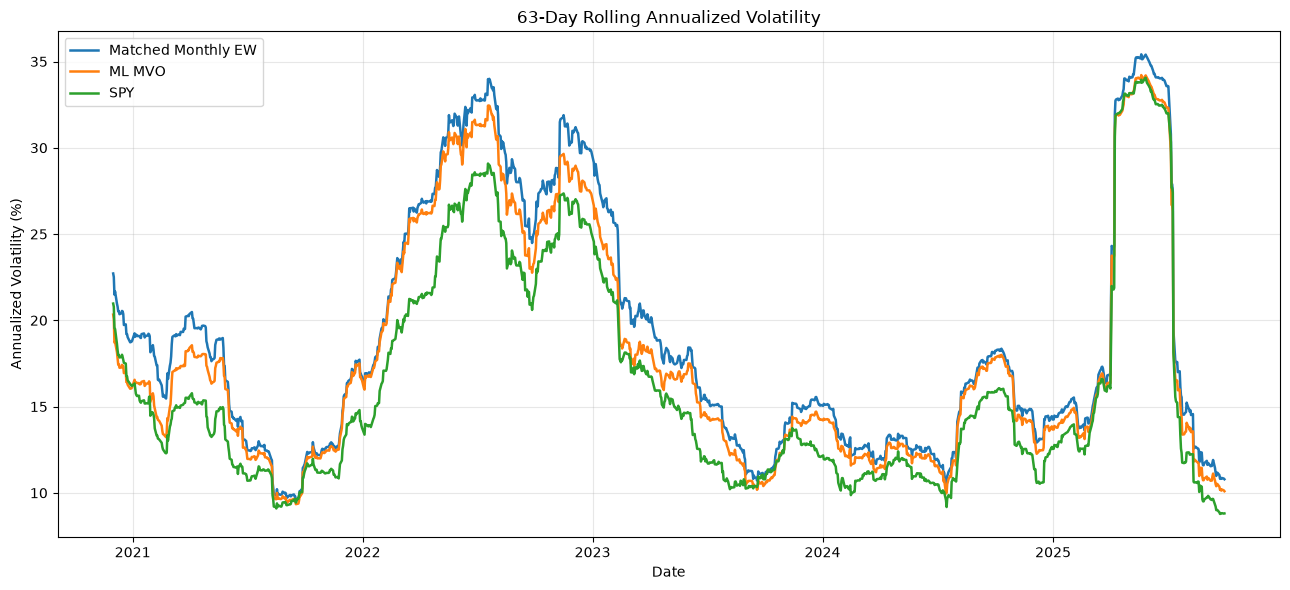


Cell 9 completed successfully.


In [10]:

# ============================================================
# Cell 9 - Portfolio Risk Diagnosis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Daily returns from the matched NAV series
# ------------------------------------------------------------

risk_nav = monthly_comparison[
    ["Matched Monthly EW", "ML MVO", "SPY", "QQQ"]
].copy()

risk_returns = (
    risk_nav.pct_change(fill_method=None)
    .dropna()
)

spy_returns = risk_returns["SPY"]

# ------------------------------------------------------------
# 2. Market beta and correlation
# ------------------------------------------------------------

risk_records = []

for name in risk_returns.columns:

    r = risk_returns[name]

    beta = r.cov(spy_returns) / spy_returns.var()
    correlation = r.corr(spy_returns)

    downside_vol = (
        np.minimum(r, 0).std()
        * np.sqrt(252)
    )

    risk_records.append({
        "Strategy": name,
        "Beta vs SPY": beta,
        "Correlation vs SPY": correlation,
        "Annual Volatility (%)":
            r.std() * np.sqrt(252) * 100,
        "Downside Deviation (%)":
            downside_vol * 100
    })

risk_diagnostics = (
    pd.DataFrame(risk_records)
    .set_index("Strategy")
)

print("=" * 70)
print("PORTFOLIO RISK DIAGNOSIS")
print("=" * 70)

print("\nRisk Statistics:")
print(risk_diagnostics.round(4).to_string())

# ------------------------------------------------------------
# 3. Annual performance
# ------------------------------------------------------------

annual_returns = (
    (1 + risk_returns)
    .groupby(risk_returns.index.year)
    .prod() - 1
) * 100

annual_returns["EW - SPY"] = (
    annual_returns["Matched Monthly EW"]
    - annual_returns["SPY"]
)

print("\nAnnual Returns (%):")
print(annual_returns.round(3).to_string())

# ------------------------------------------------------------
# 4. Drawdown diagnostics
# ------------------------------------------------------------

drawdowns = (
    risk_nav / risk_nav.cummax() - 1
)

print("\nMaximum Drawdown Dates:")

for name in risk_nav.columns:
    dd = drawdowns[name]

    print(
        f"{name}: "
        f"{dd.min() * 100:.3f}% "
        f"on {dd.idxmin().date()}"
    )

# ------------------------------------------------------------
# 5. Rolling volatility
# ------------------------------------------------------------

ROLLING_WINDOW = 63

rolling_vol = (
    risk_returns[
        ["Matched Monthly EW", "ML MVO", "SPY"]
    ]
    .rolling(ROLLING_WINDOW)
    .std()
    * np.sqrt(252) * 100
)

print("\n63-Day Rolling Volatility Summary:")
print(rolling_vol.describe().round(3).to_string())

# ------------------------------------------------------------
# 6. Plot rolling volatility
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6))

for name in rolling_vol.columns:
    ax.plot(
        rolling_vol.index,
        rolling_vol[name],
        label=name,
        linewidth=1.8
    )

ax.set_title("63-Day Rolling Annualized Volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized Volatility (%)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nCell 9 completed successfully.")


## Alternative Portfolio Allocation Strategies

Cells 10–25 test volatility and beta tilts, sector momentum, within-sector signal filtering, residual momentum, and fundamental quality–value weighting. Each strategy is evaluated using the same matched backtest assumptions where applicable.


In [11]:

# ============================================================
# Cell 10 - Sector-Neutral Volatility-Balanced Weights
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Fixed strategy parameters
# ------------------------------------------------------------

VOL_TILT_POWER = 0.50
MIN_TILT = 0.75
MAX_TILT = 1.25

vol_balanced_weights = pd.DataFrame(
    0.0,
    index=monthly_rebalance_dates,
    columns=matched_monthly_ew_weights.columns
)

vol_balance_records = []

# ------------------------------------------------------------
# 2. Construct monthly portfolio weights
# ------------------------------------------------------------

for trade_date in monthly_rebalance_dates:

    inputs = mvo_inputs[trade_date]

    tickers = pd.Index(inputs["tickers"])
    signal_date = inputs["signal_date"]
    history = inputs["history"].reindex(columns=tickers)

    # Historical volatility, known before trade date
    historical_vol = history.std(ddof=1) * np.sqrt(252)

    if (
        historical_vol.isna().any()
        or (historical_vol <= 0).any()
    ):
        raise ValueError(
            f"Invalid volatility on {trade_date}"
        )

    # --------------------------------------------------------
    # Point-in-time sector classifications
    # --------------------------------------------------------

    sector_history = mvo_sector_data.loc[
        (mvo_sector_data["reportdate"] <= signal_date)
        & (mvo_sector_data["tic"].isin(tickers))
    ]

    latest_sector = (
        sector_history
        .sort_values(["tic", "reportdate"])
        .drop_duplicates("tic", keep="last")
        .set_index("tic")["gsector"]
        .reindex(tickers)
    )

    if latest_sector.isna().any():
        raise ValueError(
            f"Missing sector on {trade_date}"
        )

    frame = pd.DataFrame({
        "volatility": historical_vol,
        "sector": latest_sector
    })

    n_total = len(frame)

    # --------------------------------------------------------
    # Low-volatility tilt within each sector
    # --------------------------------------------------------

    for sector, group in frame.groupby("sector"):

        sector_tickers = group.index
        sector_count = len(group)

        # Preserve EW sector budget
        sector_budget = sector_count / n_total

        median_vol = group["volatility"].median()

        # Favor low-volatility stocks moderately
        tilt = (
            median_vol / group["volatility"]
        ) ** VOL_TILT_POWER

        tilt = tilt.clip(
            lower=MIN_TILT,
            upper=MAX_TILT
        )

        # Sector-neutral normalization
        sector_weights = (
            sector_budget * tilt / tilt.sum()
        )

        vol_balanced_weights.loc[
            trade_date, sector_tickers
        ] = sector_weights.to_numpy()

        vol_balance_records.append({
            "trade_date": trade_date,
            "sector": sector,
            "sector_budget": sector_budget,
            "final_sector_weight": sector_weights.sum(),
            "n_stocks": sector_count
        })

# ------------------------------------------------------------
# 3. Diagnostics
# ------------------------------------------------------------

vol_balance_info = pd.DataFrame(vol_balance_records)

weight_sum = vol_balanced_weights.sum(axis=1)

max_weight = vol_balanced_weights.max(axis=1)

effective_n = 1.0 / (
    vol_balanced_weights.pow(2).sum(axis=1)
)

l1_deviation = (
    vol_balanced_weights - matched_monthly_ew_weights
).abs().sum(axis=1)

sector_difference = (
    vol_balance_info["final_sector_weight"]
    - vol_balance_info["sector_budget"]
)

print("=" * 70)
print("SECTOR-NEUTRAL VOLATILITY-BALANCED PORTFOLIO")
print("=" * 70)

print("\nPortfolio Matrix:")
print(vol_balanced_weights.shape)

print("\nWeight Sum:")
print(weight_sum.describe().round(6))

print("\nMaximum Individual Weight:")
print(max_weight.describe().round(6))

print("\nEffective Number of Stocks:")
print(effective_n.describe().round(2))

print("\nL1 Deviation from Matched EW:")
print(l1_deviation.describe().round(4))

print("\nMaximum Sector Allocation Difference:")
print(sector_difference.abs().max())

# ------------------------------------------------------------
# 4. Validation
# ------------------------------------------------------------

assert np.allclose(weight_sum, 1.0)

assert (vol_balanced_weights >= 0).all().all()

assert vol_balanced_weights.index.equals(
    matched_monthly_ew_weights.index
)

assert (
    (vol_balanced_weights > 0)
    == (matched_monthly_ew_weights > 0)
).all().all()

assert sector_difference.abs().max() < 1e-8

print("\nAll volatility-balanced weight checks passed.")
print("Cell 10 completed successfully.")


SECTOR-NEUTRAL VOLATILITY-BALANCED PORTFOLIO

Portfolio Matrix:
(61, 418)

Weight Sum:
count    61.0
mean      1.0
std       0.0
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       1.0
dtype: float64

Maximum Individual Weight:
count    61.000000
mean      0.011042
std       0.000873
min       0.008599
25%       0.010332
50%       0.010821
75%       0.011773
max       0.012890
dtype: float64

Effective Number of Stocks:
count     61.00
mean     110.96
std        8.79
min       94.24
25%      103.64
50%      111.75
75%      117.24
max      140.48
dtype: float64

L1 Deviation from Matched EW:
count    61.0000
mean      0.0923
std       0.0115
min       0.0714
25%       0.0845
50%       0.0895
75%       0.0995
max       0.1190
dtype: float64

Maximum Sector Allocation Difference:
1.1102230246251565e-16

All volatility-balanced weight checks passed.
Cell 10 completed successfully.


VOLATILITY-BALANCED PORTFOLIO - BACKTEST RESULTS

Backtest Period:
2020-09-01 to 2025-09-30

Trading Days: 1276
Monthly Rebalances: 61

Performance Comparison:
                        Final NAV  Total Return (%)  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)  Total Turnover  Total Cost
Matched Monthly EW         2.1718          117.1843   16.5663         20.0433  0.8660          -29.5172         22.1377      0.0221
Volatility-Balanced EW     2.1174          111.7380   15.9827         19.5092  0.8586          -29.2177         22.2437      0.0222
ML MVO                     1.9773           97.7341   14.4247         18.9678  0.8063          -29.2779         22.9755      0.0230
SPY                        2.0347          103.4731   15.0735         17.4067  0.8936          -24.4964             NaN         NaN
QQQ                        2.0638          106.3847   15.3971         23.1248  0.7349          -35.1187             NaN         NaN

Final NAV:
Matched Monthly EW        2.171843
V

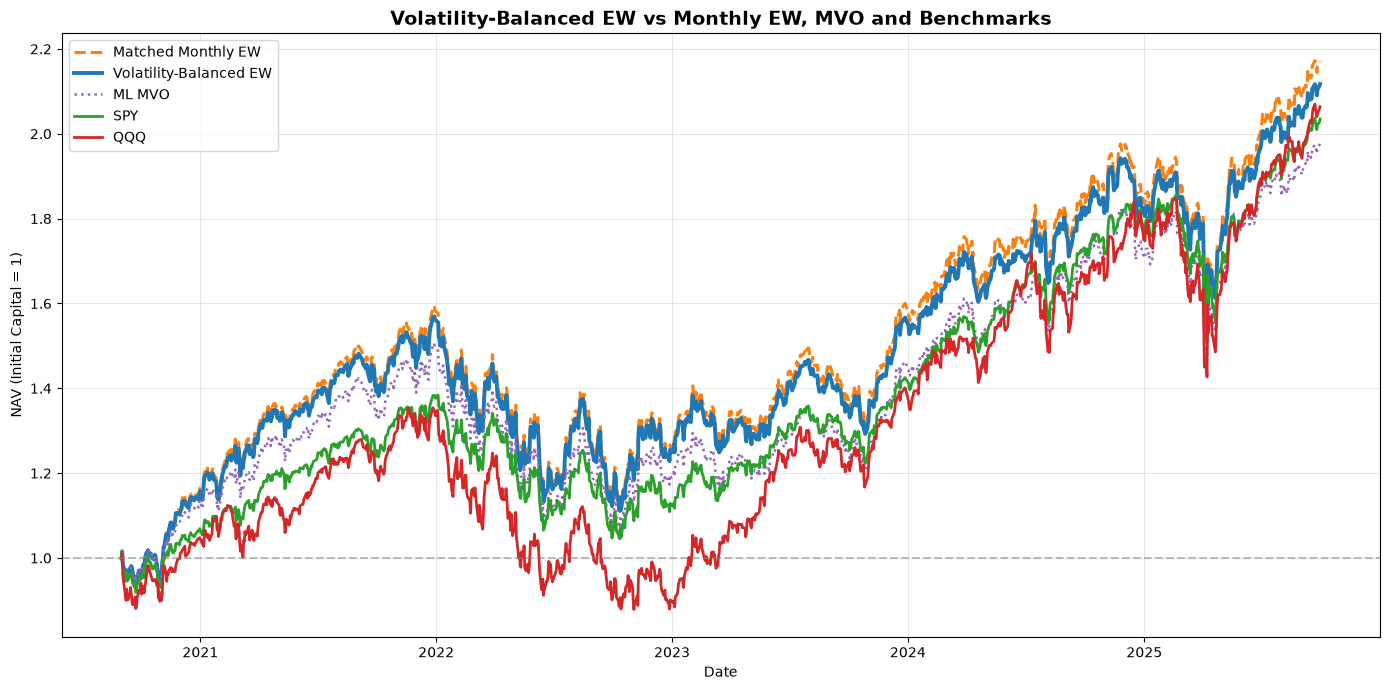


All backtest checks passed.
Cell 11 completed successfully.


In [12]:

# ============================================================
# Cell 11 - Volatility-Balanced Portfolio Backtest
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Run Volatility-Balanced Strategy
# ------------------------------------------------------------

vol_balanced_result = run_monthly_backtest(
    target_weights=vol_balanced_weights,
    daily_returns=daily_returns,
    fee_rate=FEE_RATE
)

# ------------------------------------------------------------
# 2. Align with existing strategies and benchmarks
# ------------------------------------------------------------

vol_comparison = monthly_comparison.copy()

assert vol_balanced_result.index.equals(
    vol_comparison.index
)

vol_comparison["Volatility-Balanced EW"] = (
    vol_balanced_result["nav"]
)

strategy_order = [
    "Matched Monthly EW",
    "Volatility-Balanced EW",
    "ML MVO",
    "SPY",
    "QQQ"
]

vol_comparison = vol_comparison[strategy_order]

# ------------------------------------------------------------
# 3. Calculate performance metrics
# ------------------------------------------------------------

vol_metrics = pd.DataFrame({
    name: monthly_performance_metrics(
        vol_comparison[name]
    )
    for name in strategy_order
}).T

vol_metrics["Total Turnover"] = [
    matched_ew_result["turnover"].sum(),
    vol_balanced_result["turnover"].sum(),
    mvo_result["turnover"].sum(),
    np.nan,
    np.nan
]

vol_metrics["Total Cost"] = [
    matched_ew_result["cost"].sum(),
    vol_balanced_result["cost"].sum(),
    mvo_result["cost"].sum(),
    np.nan,
    np.nan
]

# ------------------------------------------------------------
# 4. Print performance comparison
# ------------------------------------------------------------

print("=" * 75)
print("VOLATILITY-BALANCED PORTFOLIO - BACKTEST RESULTS")
print("=" * 75)

print("\nBacktest Period:")
print(
    vol_comparison.index.min().date(),
    "to",
    vol_comparison.index.max().date()
)

print("\nTrading Days:", len(vol_comparison))
print("Monthly Rebalances:", len(vol_balanced_weights))

print("\nPerformance Comparison:")
print(vol_metrics.round(4).to_string())

print("\nFinal NAV:")
print(vol_comparison.iloc[-1].round(6))

# ------------------------------------------------------------
# 5. Relative performance
# ------------------------------------------------------------

vol_final = vol_comparison[
    "Volatility-Balanced EW"
].iloc[-1]

ew_final = vol_comparison[
    "Matched Monthly EW"
].iloc[-1]

spy_final = vol_comparison["SPY"].iloc[-1]

print("\nRelative Performance:")

print(
    "Volatility-Balanced vs Matched EW:",
    f"{(vol_final / ew_final - 1) * 100:.3f}%"
)

print(
    "Volatility-Balanced vs SPY:",
    f"{(vol_final / spy_final - 1) * 100:.3f}%"
)

print("\nRisk Improvements vs Matched EW:")

print(
    "Volatility Change (percentage points):",
    round(
        vol_metrics.loc[
            "Volatility-Balanced EW",
            "Volatility (%)"
        ]
        - vol_metrics.loc[
            "Matched Monthly EW",
            "Volatility (%)"
        ],
        4
    )
)

print(
    "Sharpe Change:",
    round(
        vol_metrics.loc[
            "Volatility-Balanced EW", "Sharpe"
        ]
        - vol_metrics.loc[
            "Matched Monthly EW", "Sharpe"
        ],
        4
    )
)

print(
    "Max Drawdown Change (percentage points):",
    round(
        vol_metrics.loc[
            "Volatility-Balanced EW",
            "Max Drawdown (%)"
        ]
        - vol_metrics.loc[
            "Matched Monthly EW",
            "Max Drawdown (%)"
        ],
        4
    )
)

# ------------------------------------------------------------
# 6. Annual returns
# ------------------------------------------------------------

daily_ret = (
    vol_comparison
    .pct_change(fill_method=None)
    .iloc[1:]
)

annual_returns = (
    (1.0 + daily_ret)
    .groupby(daily_ret.index.year)
    .prod() - 1.0
) * 100

print("\nAnnual Returns (%):")
print(annual_returns.round(3).to_string())

# ------------------------------------------------------------
# 7. Plot NAV comparison
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

styles = {
    "Matched Monthly EW": ("#ff7f0e", "--", 2.2),
    "Volatility-Balanced EW": ("#1f77b4", "-", 2.8),
    "ML MVO": ("#9467bd", ":", 1.8),
    "SPY": ("#2ca02c", "-", 2.0),
    "QQQ": ("#d62728", "-", 2.0)
}

for name, (color, linestyle, width) in styles.items():

    ax.plot(
        vol_comparison.index,
        vol_comparison[name],
        label=name,
        color=color,
        linestyle=linestyle,
        linewidth=width
    )

ax.axhline(
    1.0,
    color="gray",
    linestyle="--",
    alpha=0.5
)

ax.set_title(
    "Volatility-Balanced EW vs Monthly EW, MVO and Benchmarks",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("NAV (Initial Capital = 1)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Validation and save
# ------------------------------------------------------------

assert vol_comparison.notna().all().all()

assert np.isfinite(
    vol_comparison.to_numpy()
).all()

assert (vol_comparison > 0).all().all()

vol_comparison.to_csv(
    "./results/vol_balanced_nav.csv"
)

vol_metrics.to_csv(
    "./results/vol_balanced_metrics.csv"
)

print("\nAll backtest checks passed.")
print("Cell 11 completed successfully.")


In [13]:

# ============================================================
# Cell 12 - Sector-Neutral Beta-Balanced Portfolio
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Fixed parameters
# ------------------------------------------------------------

BETA_TILT_STRENGTH = 0.50
BETA_SHRINKAGE = 0.50

MIN_BETA_TILT = 0.75
MAX_BETA_TILT = 1.25

BETA_MIN_OBSERVATIONS = 63

# ------------------------------------------------------------
# 2. SPY historical returns
# ------------------------------------------------------------

spy_daily_returns = (
    comparison_nav["SPY"]
    .pct_change(fill_method=None)
)

# ------------------------------------------------------------
# 3. Initialize portfolio weights
# ------------------------------------------------------------

beta_balanced_weights = pd.DataFrame(
    0.0,
    index=monthly_rebalance_dates,
    columns=matched_monthly_ew_weights.columns
)

beta_diagnostics_records = []

# ------------------------------------------------------------
# 4. Construct monthly beta-balanced portfolios
# ------------------------------------------------------------

for trade_date in monthly_rebalance_dates:

    inputs = mvo_inputs[trade_date]

    tickers = pd.Index(inputs["tickers"])
    signal_date = inputs["signal_date"]

    historical_returns = inputs["history"].reindex(
        columns=tickers
    )

    spy_history = spy_daily_returns.loc[
        spy_daily_returns.index < trade_date
    ]

    # Use only dates observed for both SPY and stocks
    aligned_history = historical_returns.join(
        spy_history.rename("_SPY"),
        how="inner"
    )

    if len(aligned_history) < BETA_MIN_OBSERVATIONS:
        raise ValueError(
            f"Insufficient SPY history on {trade_date}"
        )

    market_ret = aligned_history["_SPY"]

    # --------------------------------------------------------
    # Estimate historical stock betas
    # --------------------------------------------------------

    beta_estimates = {}
    fallback_count = 0

    for tic in tickers:

        paired = aligned_history[
            [tic, "_SPY"]
        ].dropna()

        if len(paired) < BETA_MIN_OBSERVATIONS:
            beta_estimates[tic] = 1.0
            fallback_count += 1
            continue

        market_variance = paired["_SPY"].var()

        if market_variance <= 0:
            beta_estimates[tic] = 1.0
            fallback_count += 1
            continue

        raw_beta = (
            paired[tic].cov(paired["_SPY"])
            / market_variance
        )

        # Winsorize extreme beta estimates
        raw_beta = np.clip(raw_beta, 0.0, 3.0)

        # Shrink estimates toward market beta = 1
        shrunk_beta = (
            (1.0 - BETA_SHRINKAGE) * raw_beta
            + BETA_SHRINKAGE * 1.0
        )

        beta_estimates[tic] = shrunk_beta

    betas = pd.Series(
        beta_estimates,
        index=tickers,
        dtype=float
    )

    # --------------------------------------------------------
    # Point-in-time sector mapping
    # --------------------------------------------------------

    sector_history = mvo_sector_data.loc[
        (mvo_sector_data["reportdate"] <= signal_date)
        & (mvo_sector_data["tic"].isin(tickers))
    ]

    sectors = (
        sector_history
        .sort_values(["tic", "reportdate"])
        .drop_duplicates("tic", keep="last")
        .set_index("tic")["gsector"]
        .reindex(tickers)
    )

    if sectors.isna().any():
        raise ValueError(
            f"Missing sector information on {trade_date}"
        )

    frame = pd.DataFrame({
        "beta": betas,
        "sector": sectors
    })

    # --------------------------------------------------------
    # Sector-neutral beta weighting
    # --------------------------------------------------------

    ew_weights = matched_monthly_ew_weights.loc[
        trade_date, tickers
    ]

    for sector, group in frame.groupby("sector"):

        sector_tickers = group.index

        sector_budget = ew_weights.loc[
            sector_tickers
        ].sum()

        median_beta = group["beta"].median()

        # Underweight high-beta stocks,
        # overweight low-beta stocks
        tilt = np.exp(
            -BETA_TILT_STRENGTH
            * (group["beta"] - median_beta)
        )

        tilt = tilt.clip(
            lower=MIN_BETA_TILT,
            upper=MAX_BETA_TILT
        )

        new_weights = (
            sector_budget
            * tilt / tilt.sum()
        )

        beta_balanced_weights.loc[
            trade_date, sector_tickers
        ] = new_weights.to_numpy()

        # Preserve sector budget exactly
        assert np.isclose(
            new_weights.sum(),
            sector_budget,
            atol=1e-8
        )

    new_weights = beta_balanced_weights.loc[
        trade_date, tickers
    ]

    # Ex-ante beta based on the same estimates
    ew_beta = float(
        np.dot(ew_weights, betas)
    )

    strategy_beta = float(
        np.dot(new_weights, betas)
    )

    beta_diagnostics_records.append({
        "trade_date": trade_date,
        "n_stocks": len(tickers),
        "n_spy_observations": len(aligned_history),
        "fallback_betas": fallback_count,
        "ew_estimated_beta": ew_beta,
        "strategy_estimated_beta": strategy_beta,
        "beta_reduction": ew_beta - strategy_beta,
        "max_weight": new_weights.max(),
        "effective_n_stocks": (
            1.0 / np.sum(new_weights.to_numpy() ** 2)
        )
    })

# ------------------------------------------------------------
# 5. Diagnostics
# ------------------------------------------------------------

beta_diagnostics = (
    pd.DataFrame(beta_diagnostics_records)
    .set_index("trade_date")
)

print("=" * 70)
print("SECTOR-NEUTRAL BETA-BALANCED PORTFOLIO")
print("=" * 70)

print("\nWeight Matrix:")
print(beta_balanced_weights.shape)

print("\nEstimated Portfolio Beta:")
print(
    beta_diagnostics[
        [
            "ew_estimated_beta",
            "strategy_estimated_beta",
            "beta_reduction"
        ]
    ].describe().round(4).to_string()
)

print("\nPortfolio Concentration:")
print(
    beta_diagnostics[
        ["max_weight", "effective_n_stocks"]
    ].describe().round(4).to_string()
)

print("\nBeta Estimation Coverage:")
print(
    beta_diagnostics[
        ["n_spy_observations", "fallback_betas"]
    ].describe().round(2).to_string()
)

print("\nFirst 5 Rebalances:")
print(beta_diagnostics.head().round(4).to_string())

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

assert np.allclose(
    beta_balanced_weights.sum(axis=1),
    1.0
)

assert (
    beta_balanced_weights >= 0
).all().all()

assert beta_balanced_weights.index.equals(
    matched_monthly_ew_weights.index
)

assert (
    (beta_balanced_weights > 0)
    == (matched_monthly_ew_weights > 0)
).all().all()

assert np.isfinite(
    beta_balanced_weights.to_numpy()
).all()

print("\nAll beta-balanced weight checks passed.")
print("Cell 12 completed successfully.")


SECTOR-NEUTRAL BETA-BALANCED PORTFOLIO

Weight Matrix:
(61, 418)

Estimated Portfolio Beta:
       ew_estimated_beta  strategy_estimated_beta  beta_reduction
count            61.0000                  61.0000         61.0000
mean              1.0529                   1.0379          0.0150
std               0.0312                   0.0321          0.0057
min               0.9987                   0.9719          0.0086
25%               1.0304                   1.0164          0.0112
50%               1.0426                   1.0294          0.0132
75%               1.0784                   1.0657          0.0164
max               1.1462                   1.1207          0.0297

Portfolio Concentration:
       max_weight  effective_n_stocks
count     61.0000             61.0000
mean       0.0108            111.5672
std        0.0008              8.8746
min        0.0086             94.4490
25%        0.0102            104.2632
50%        0.0105            112.4992
75%        0.0113     

BETA-BALANCED PORTFOLIO - BACKTEST RESULTS

Backtest Period:
2020-09-01 to 2025-09-30

Performance Comparison:
                        Final NAV  Total Return (%)  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)  Total Turnover  Total Cost  Realized Beta  Correlation vs SPY
Matched Monthly EW         2.1718          117.1843   16.5663         20.0433  0.8660          -29.5172         22.1377      0.0221         1.0930              0.9492
Beta-Balanced EW           2.1403          114.0299   16.2298         19.5763  0.8672          -29.1309         22.1885      0.0222         1.0679              0.9496
Volatility-Balanced EW     2.1174          111.7380   15.9827         19.5092  0.8586          -29.2177         22.2437      0.0222         1.0649              0.9501
ML MVO                     1.9773           97.7341   14.4247         18.9678  0.8063          -29.2779         22.9755      0.0230         1.0401              0.9545
SPY                        2.0347          103.4731   

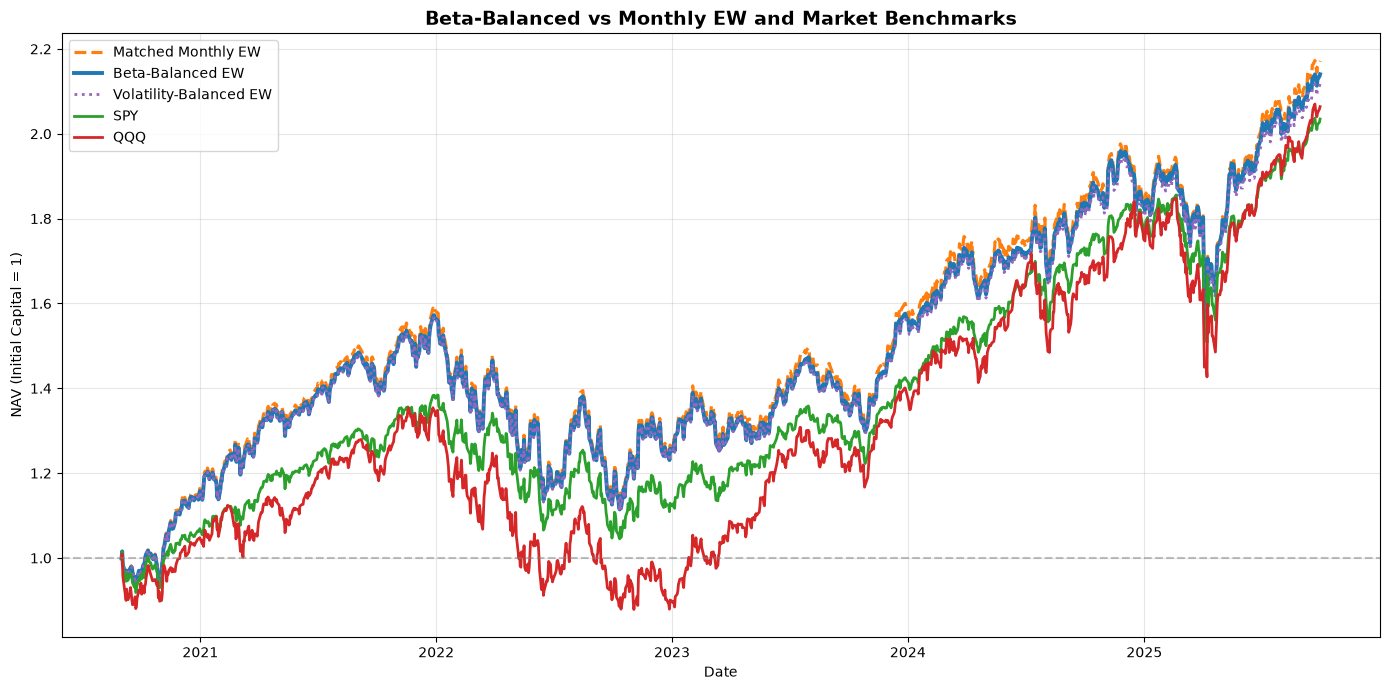


All beta-balanced backtest checks passed.
Cell 13 completed successfully.


In [14]:

# ============================================================
# Cell 13 - Beta-Balanced Portfolio Backtest
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Run Beta-Balanced Strategy
# ------------------------------------------------------------

beta_balanced_result = run_monthly_backtest(
    target_weights=beta_balanced_weights,
    daily_returns=daily_returns,
    fee_rate=FEE_RATE
)

# ------------------------------------------------------------
# 2. Align all strategies
# ------------------------------------------------------------

beta_comparison = monthly_comparison.copy()

assert beta_balanced_result.index.equals(
    beta_comparison.index
)

beta_comparison["Beta-Balanced EW"] = (
    beta_balanced_result["nav"]
)

beta_comparison["Volatility-Balanced EW"] = (
    vol_balanced_result["nav"]
)

strategy_order = [
    "Matched Monthly EW",
    "Beta-Balanced EW",
    "Volatility-Balanced EW",
    "ML MVO",
    "SPY",
    "QQQ"
]

beta_comparison = beta_comparison[strategy_order]

# ------------------------------------------------------------
# 3. Performance metrics
# ------------------------------------------------------------

beta_metrics = pd.DataFrame({
    name: monthly_performance_metrics(
        beta_comparison[name]
    )
    for name in strategy_order
}).T

beta_metrics["Total Turnover"] = [
    matched_ew_result["turnover"].sum(),
    beta_balanced_result["turnover"].sum(),
    vol_balanced_result["turnover"].sum(),
    mvo_result["turnover"].sum(),
    np.nan,
    np.nan
]

beta_metrics["Total Cost"] = [
    matched_ew_result["cost"].sum(),
    beta_balanced_result["cost"].sum(),
    vol_balanced_result["cost"].sum(),
    mvo_result["cost"].sum(),
    np.nan,
    np.nan
]

# ------------------------------------------------------------
# 4. Realized Beta and Correlation vs SPY
# ------------------------------------------------------------

strategy_returns = (
    beta_comparison
    .pct_change(fill_method=None)
    .iloc[1:]
)

spy_ret = strategy_returns["SPY"]

realized_beta = {}
realized_corr = {}

for name in strategy_order:

    r = strategy_returns[name]

    realized_beta[name] = (
        r.cov(spy_ret) / spy_ret.var()
    )

    realized_corr[name] = r.corr(spy_ret)

beta_metrics["Realized Beta"] = pd.Series(
    realized_beta
)

beta_metrics["Correlation vs SPY"] = pd.Series(
    realized_corr
)

# ------------------------------------------------------------
# 5. Print comparison
# ------------------------------------------------------------

print("=" * 75)
print("BETA-BALANCED PORTFOLIO - BACKTEST RESULTS")
print("=" * 75)

print("\nBacktest Period:")
print(
    beta_comparison.index.min().date(),
    "to",
    beta_comparison.index.max().date()
)

print("\nPerformance Comparison:")
print(beta_metrics.round(4).to_string())

print("\nFinal NAV:")
print(beta_comparison.iloc[-1].round(6))

# ------------------------------------------------------------
# 6. Relative performance
# ------------------------------------------------------------

beta_final = beta_comparison[
    "Beta-Balanced EW"
].iloc[-1]

ew_final = beta_comparison[
    "Matched Monthly EW"
].iloc[-1]

spy_final = beta_comparison["SPY"].iloc[-1]

print("\nRelative Performance:")

print(
    "Beta-Balanced vs Matched EW:",
    f"{(beta_final / ew_final - 1) * 100:.3f}%"
)

print(
    "Beta-Balanced vs SPY:",
    f"{(beta_final / spy_final - 1) * 100:.3f}%"
)

# ------------------------------------------------------------
# 7. Risk improvement diagnostics
# ------------------------------------------------------------

print("\nRisk Changes vs Matched EW:")

for metric in [
    "Volatility (%)",
    "Sharpe",
    "Max Drawdown (%)",
    "Realized Beta"
]:

    change = (
        beta_metrics.loc["Beta-Balanced EW", metric]
        - beta_metrics.loc["Matched Monthly EW", metric]
    )

    print(f"{metric}: {change:+.4f}")

# ------------------------------------------------------------
# 8. Annual returns
# ------------------------------------------------------------

annual_returns = (
    (1.0 + strategy_returns)
    .groupby(strategy_returns.index.year)
    .prod() - 1.0
) * 100

print("\nAnnual Returns (%):")
print(
    annual_returns[
        [
            "Matched Monthly EW",
            "Beta-Balanced EW",
            "Volatility-Balanced EW",
            "SPY",
            "QQQ"
        ]
    ].round(3).to_string()
)

# ------------------------------------------------------------
# 9. Plot NAV
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

styles = {
    "Matched Monthly EW": ("#ff7f0e", "--", 2.3),
    "Beta-Balanced EW": ("#1f77b4", "-", 2.8),
    "Volatility-Balanced EW": ("#9467bd", ":", 2.0),
    "SPY": ("#2ca02c", "-", 2.0),
    "QQQ": ("#d62728", "-", 2.0)
}

for name, (color, linestyle, width) in styles.items():

    ax.plot(
        beta_comparison.index,
        beta_comparison[name],
        label=name,
        color=color,
        linestyle=linestyle,
        linewidth=width
    )

ax.axhline(
    1.0,
    color="gray",
    linestyle="--",
    alpha=0.5
)

ax.set_title(
    "Beta-Balanced vs Monthly EW and Market Benchmarks",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("NAV (Initial Capital = 1)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Validation and save
# ------------------------------------------------------------

assert beta_comparison.notna().all().all()

assert np.isfinite(
    beta_comparison.to_numpy()
).all()

assert (beta_comparison > 0).all().all()

beta_comparison.to_csv(
    "./results/beta_balanced_nav.csv"
)

beta_metrics.to_csv(
    "./results/beta_balanced_metrics.csv"
)

print("\nAll beta-balanced backtest checks passed.")
print("Cell 13 completed successfully.")


In [15]:

# ============================================================
# Cell 14 - Subperiod Robustness Analysis
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Collect daily net returns
# ------------------------------------------------------------

strategy_results = {
    "Matched Monthly EW": matched_ew_result,
    "Beta-Balanced EW": beta_balanced_result,
    "Volatility-Balanced EW": vol_balanced_result,
    "ML MVO": mvo_result
}

analysis_returns = pd.DataFrame(
    index=beta_comparison.index
)

for name, result in strategy_results.items():
    analysis_returns[name] = result["net_ret"]

# Benchmark daily close-to-close returns
for name in ["SPY", "QQQ"]:
    analysis_returns[name] = (
        beta_comparison[name]
        .pct_change(fill_method=None)
        .fillna(0.0)
    )

assert analysis_returns.notna().all().all(), (
    "Missing values found in analysis_returns"
)

# ------------------------------------------------------------
# 2. Define evaluation periods
# ------------------------------------------------------------

periods = {
    "Development 2020-2023": (
        "2020-09-01", "2023-12-29"
    ),
    "Evaluation 2024-2025": (
        "2024-01-01", "2025-09-30"
    )
}

# ------------------------------------------------------------
# 3. Performance calculator
# ------------------------------------------------------------

def period_metrics(returns):

    returns = returns.astype(float)

    nav = (1.0 + returns).cumprod()

    initial_nav = pd.concat(
        [
            pd.Series([1.0]),
            nav.reset_index(drop=True)
        ],
        ignore_index=True
    )

    n = len(returns)

    return {
        "Final NAV": nav.iloc[-1],
        "CAGR (%)": (
            nav.iloc[-1] ** (252 / n) - 1
        ) * 100,
        "Volatility (%)": (
            returns.std() * np.sqrt(252) * 100
        ),
        "Sharpe": (
            returns.mean() / returns.std()
            * np.sqrt(252)
            if returns.std() > 0 else np.nan
        ),
        "Max Drawdown (%)": (
            initial_nav / initial_nav.cummax() - 1
        ).min() * 100
    }

# ------------------------------------------------------------
# 4. Evaluate each period
# ------------------------------------------------------------

period_tables = {}

for period_name, (start, end) in periods.items():

    period_returns = analysis_returns.loc[start:end]

    table = pd.DataFrame({
        name: period_metrics(period_returns[name])
        for name in analysis_returns.columns
    }).T

    period_tables[period_name] = table

    print("\n" + "=" * 70)
    print(period_name.upper())
    print("=" * 70)

    print("Trading Days:", len(period_returns))
    print("\nPerformance:")
    print(table.round(4).to_string())

    ew = table.loc["Matched Monthly EW", "Final NAV"]
    spy = table.loc["SPY", "Final NAV"]

    print(
        "\nEW vs SPY Relative NAV:",
        f"{(ew / spy - 1) * 100:.3f}%"
    )

# ------------------------------------------------------------
# 5. Save results
# ------------------------------------------------------------

subperiod_metrics = pd.concat(
    period_tables,
    names=["Period", "Strategy"]
)

subperiod_metrics.to_csv(
    "./results/subperiod_robustness_metrics.csv"
)

print("\nSubperiod robustness analysis completed.")



DEVELOPMENT 2020-2023
Trading Days: 838

Performance:
                        Final NAV  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)
Matched Monthly EW         1.5936   15.0417         20.8993  0.7750          -29.5172
Beta-Balanced EW           1.5700   14.5279         20.4905  0.7645          -29.1309
Volatility-Balanced EW     1.5610   14.3302         20.4021  0.7585          -29.2177
ML MVO                     1.4577   11.9998         19.6287  0.6755          -29.2779
SPY                        1.4209   11.1424         17.6821  0.6860          -24.4964
QQQ                        1.3942   10.5096         23.9801  0.5368          -35.1187

EW vs SPY Relative NAV: 12.150%

EVALUATION 2024-2025
Trading Days: 438

Performance:
                        Final NAV  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)
Matched Monthly EW         1.3629   19.4979         18.2921  1.0650          -21.3474
Beta-Balanced EW           1.3632   19.5156         17.6936  1.0958          -20.653

In [16]:

# ============================================================
# Cell 15 - ML Selection + Sector Momentum Rotation
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Strategy configuration
# ------------------------------------------------------------

SECTOR_MOM_TILT = 0.50

MIN_SECTOR_FACTOR = 0.75
MAX_SECTOR_FACTOR = 1.25

# Approximately 6-1 month price momentum:
# compare close ~21 trading days ago
# against close ~126 trading days ago.
MOM_LONG_LAG = 126
MOM_SHORT_LAG = 21

# ------------------------------------------------------------
# 2. Initialize monthly weights
# ------------------------------------------------------------

sector_mom_weights = pd.DataFrame(
    0.0,
    index=monthly_rebalance_dates,
    columns=matched_monthly_ew_weights.columns
)

sector_mom_records = []

# ------------------------------------------------------------
# 3. Construct each monthly portfolio
# ------------------------------------------------------------

for trade_date in monthly_rebalance_dates:

    inputs = mvo_inputs[trade_date]

    tickers = pd.Index(inputs["tickers"])
    signal_date = inputs["signal_date"]

    # --------------------------------------------------------
    # Point-in-time sector classification
    # --------------------------------------------------------

    sector_history = mvo_sector_data.loc[
        (mvo_sector_data["reportdate"] <= signal_date)
        & (mvo_sector_data["tic"].isin(tickers))
    ]

    sectors = (
        sector_history
        .sort_values(["tic", "reportdate"])
        .drop_duplicates("tic", keep="last")
        .set_index("tic")["gsector"]
        .reindex(tickers)
    )

    if sectors.isna().any():
        raise ValueError(
            f"Missing sector information: {trade_date}"
        )

    # --------------------------------------------------------
    # Historical momentum (strictly before trade date)
    # --------------------------------------------------------

    historical_prices = close_prices.loc[
        close_prices.index < trade_date,
        tickers
    ].tail(MOM_LONG_LAG + 1)

    if len(historical_prices) < MOM_LONG_LAG + 1:
        raise ValueError(
            f"Insufficient price history: {trade_date}"
        )

    older_prices = historical_prices.iloc[
        -(MOM_LONG_LAG + 1)
    ]

    recent_prices = historical_prices.iloc[
        -(MOM_SHORT_LAG + 1)
    ]

    stock_momentum = (
        recent_prices / older_prices - 1.0
    ).replace(
        [np.inf, -np.inf], np.nan
    )

    # --------------------------------------------------------
    # Sector-level momentum score
    # --------------------------------------------------------

    frame = pd.DataFrame({
        "sector": sectors,
        "momentum": stock_momentum
    })

    sector_momentum = (
        frame.groupby("sector")["momentum"]
        .median()
    )

    # Sector with no valid momentum receives
    # the cross-sector median rather than
    # an artificial high or low score.
    n_missing_sectors = int(
        sector_momentum.isna().sum()
    )

    if sector_momentum.notna().sum() == 0:
        raise ValueError(
            f"No valid sector momentum: {trade_date}"
        )

    sector_momentum = sector_momentum.fillna(
        sector_momentum.median()
    )

    # --------------------------------------------------------
    # Rank sectors by historical momentum
    # --------------------------------------------------------

    sector_rank = sector_momentum.rank(
        pct=True,
        method="average"
    )

    # Moderate sector momentum tilt
    sector_factor = (
        1.0
        + SECTOR_MOM_TILT * (2.0 * sector_rank - 1.0)
    )

    sector_factor = sector_factor.clip(
        lower=MIN_SECTOR_FACTOR,
        upper=MAX_SECTOR_FACTOR
    )

    # --------------------------------------------------------
    # Original equal-weight sector allocation
    # --------------------------------------------------------

    sector_counts = frame.groupby(
        "sector"
    ).size()

    ew_sector_budget = (
        sector_counts / len(tickers)
    )

    # --------------------------------------------------------
    # Apply sector rotation
    # --------------------------------------------------------

    raw_sector_budget = (
        ew_sector_budget * sector_factor
    )

    final_sector_budget = (
        raw_sector_budget
        / raw_sector_budget.sum()
    )

    # Equal weight within each sector
    for sector, group in frame.groupby("sector"):

        sector_tickers = group.index

        new_weight = (
            final_sector_budget.loc[sector]
            / len(sector_tickers)
        )

        sector_mom_weights.loc[
            trade_date, sector_tickers
        ] = new_weight

        sector_mom_records.append({
            "trade_date": trade_date,
            "sector": sector,
            "n_stocks": len(sector_tickers),
            "sector_momentum":
                sector_momentum.loc[sector],
            "sector_rank":
                sector_rank.loc[sector],
            "ew_sector_weight":
                ew_sector_budget.loc[sector],
            "rotated_sector_weight":
                final_sector_budget.loc[sector],
            "missing_sector_momentum":
                n_missing_sectors
        })

# ------------------------------------------------------------
# 4. Diagnostics
# ------------------------------------------------------------

sector_mom_info = pd.DataFrame(
    sector_mom_records
)

weight_sums = sector_mom_weights.sum(axis=1)

sector_weight_difference = (
    sector_mom_info["rotated_sector_weight"]
    - sector_mom_info["ew_sector_weight"]
)

l1_deviation = (
    sector_mom_weights
    - matched_monthly_ew_weights
).abs().sum(axis=1)

print("=" * 70)
print("ML + SECTOR MOMENTUM ROTATION")
print("=" * 70)

print("\nPortfolio Weight Matrix:")
print(sector_mom_weights.shape)

print("\nWeight Sums:")
print(weight_sums.describe().round(6))

print("\nSector Allocation Changes:")
print(
    (
        sector_weight_difference.abs() * 100
    ).describe().round(3)
)

print("\nL1 Deviation from Monthly EW:")
print(l1_deviation.describe().round(4))

print("\nMaximum Individual Stock Weight:")
print(
    sector_mom_weights.max(axis=1)
    .describe().round(5)
)

print("\nMissing Momentum Observations:")
print(
    "Stocks:",
    int(
        sector_mom_info[
            "missing_sector_momentum"
        ].sum()
    )
)

print("\nExample First Rebalance:")
print(
    sector_mom_info[
        sector_mom_info["trade_date"]
        == monthly_rebalance_dates[0]
    ][[
        "sector",
        "n_stocks",
        "sector_momentum",
        "ew_sector_weight",
        "rotated_sector_weight"
    ]].round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 5. Validation
# ------------------------------------------------------------

assert np.allclose(
    sector_mom_weights.sum(axis=1), 1.0
)

assert (
    sector_mom_weights >= 0
).all().all()

assert sector_mom_weights.index.equals(
    matched_monthly_ew_weights.index
)

assert sector_mom_weights.columns.equals(
    matched_monthly_ew_weights.columns
)

assert (
    (sector_mom_weights > 0)
    == (matched_monthly_ew_weights > 0)
).all().all()

assert np.isfinite(
    sector_mom_weights.to_numpy()
).all()

print("\nAll sector momentum checks passed.")
print("Cell 15 completed successfully.")


ML + SECTOR MOMENTUM ROTATION

Portfolio Weight Matrix:
(61, 418)

Weight Sums:
count    61.0
mean      1.0
std       0.0
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       1.0
dtype: float64

Sector Allocation Changes:
count    391.000
mean       2.122
std        2.112
min        0.000
25%        0.500
50%        1.286
75%        3.417
max       10.626
dtype: float64

L1 Deviation from Monthly EW:
count    61.0000
mean      0.1360
std       0.0391
min       0.0428
25%       0.1107
50%       0.1398
75%       0.1640
max       0.2185
dtype: float64

Maximum Individual Stock Weight:
count    61.00000
mean      0.01060
std       0.00106
min       0.00817
25%       0.00984
50%       0.01045
75%       0.01116
max       0.01302
dtype: float64

Missing Momentum Observations:
Stocks: 0

Example First Rebalance:
 sector  n_stocks  sector_momentum  ew_sector_weight  rotated_sector_weight
     10         3          -0.3828            0.0256                 0.0185
     20        40  

SECTOR MOMENTUM ROTATION - BACKTEST RESULTS

Backtest Period:
2020-09-01 to 2025-09-30

Trading Days: 1276
Monthly Rebalances: 61

Performance Comparison:
                    Final NAV  Total Return (%)  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)  Total Turnover  Total Cost  Beta vs SPY
Sector Momentum        2.1137          111.3728   15.9431         20.1524  0.8358          -29.8426         26.1415      0.0261       1.0992
Matched Monthly EW     2.1718          117.1843   16.5663         20.0433  0.8660          -29.5172         22.1377      0.0221       1.0930
SPY                    2.0347          103.4731   15.0735         17.4067  0.8936          -24.4964             NaN         NaN       1.0000
QQQ                    2.0638          106.3847   15.3971         23.1248  0.7349          -35.1187             NaN         NaN       1.2493

Final NAV:
Sector Momentum       2.113728
Matched Monthly EW    2.171843
SPY                   2.034731
QQQ                   2.063847
Name

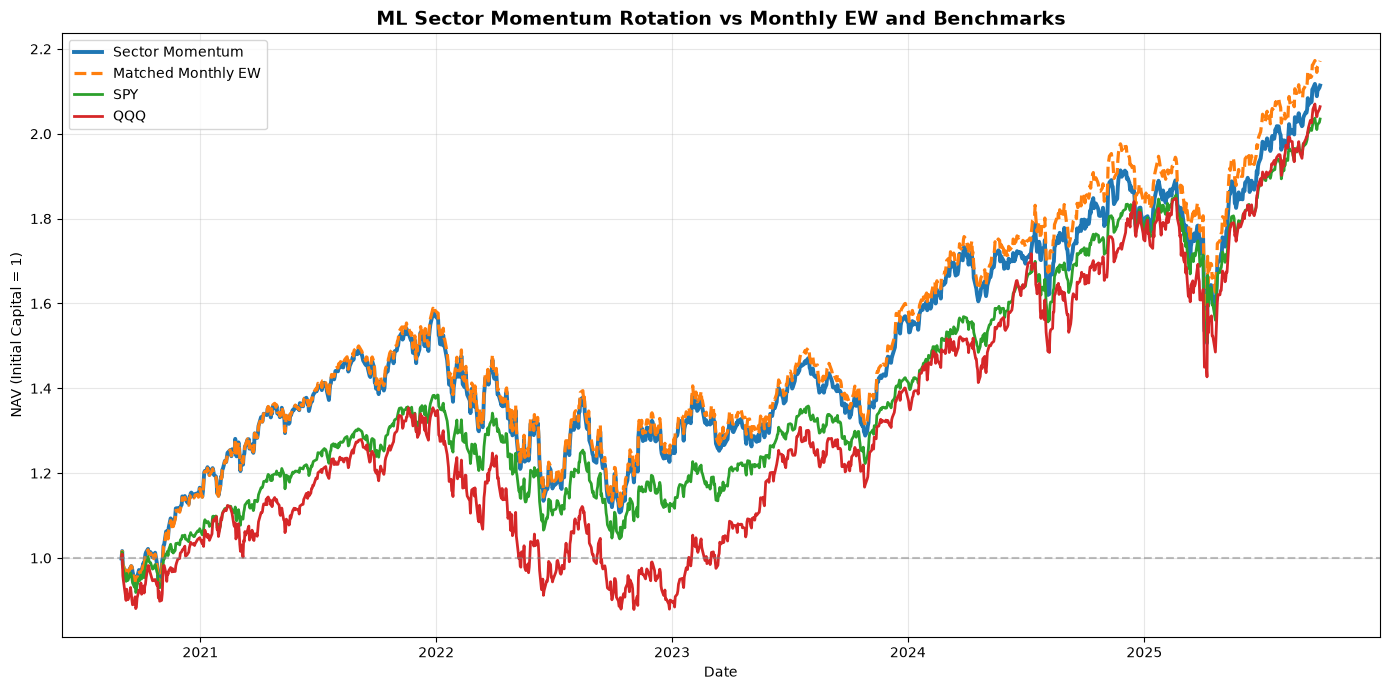


All Sector Momentum backtest checks passed.
Cell 16 completed successfully.


In [17]:

# ============================================================
# Cell 16 - Sector Momentum Rotation Backtest
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Run Sector Momentum Strategy
# ------------------------------------------------------------

sector_mom_result = run_monthly_backtest(
    target_weights=sector_mom_weights,
    daily_returns=daily_returns,
    fee_rate=FEE_RATE
)

# ------------------------------------------------------------
# 2. Align NAV with matched benchmarks
# ------------------------------------------------------------

sector_mom_comparison = monthly_comparison[
    ["Matched Monthly EW", "SPY", "QQQ"]
].copy()

assert sector_mom_result.index.equals(
    sector_mom_comparison.index
)

sector_mom_comparison["Sector Momentum"] = (
    sector_mom_result["nav"]
)

strategy_order = [
    "Sector Momentum",
    "Matched Monthly EW",
    "SPY",
    "QQQ"
]

sector_mom_comparison = sector_mom_comparison[
    strategy_order
]

# ------------------------------------------------------------
# 3. Performance metrics
# ------------------------------------------------------------

sector_mom_metrics = pd.DataFrame({
    name: monthly_performance_metrics(
        sector_mom_comparison[name]
    )
    for name in strategy_order
}).T

sector_mom_metrics["Total Turnover"] = [
    sector_mom_result["turnover"].sum(),
    matched_ew_result["turnover"].sum(),
    np.nan,
    np.nan
]

sector_mom_metrics["Total Cost"] = [
    sector_mom_result["cost"].sum(),
    matched_ew_result["cost"].sum(),
    np.nan,
    np.nan
]

# ------------------------------------------------------------
# 4. Realized market beta
# ------------------------------------------------------------

strategy_returns = (
    sector_mom_comparison
    .pct_change(fill_method=None)
    .iloc[1:]
)

spy_returns = strategy_returns["SPY"]

sector_mom_metrics["Beta vs SPY"] = [
    strategy_returns[name].cov(spy_returns)
    / spy_returns.var()
    for name in strategy_order
]

# ------------------------------------------------------------
# 5. Main performance comparison
# ------------------------------------------------------------

print("=" * 75)
print("SECTOR MOMENTUM ROTATION - BACKTEST RESULTS")
print("=" * 75)

print("\nBacktest Period:")
print(
    sector_mom_comparison.index.min().date(),
    "to",
    sector_mom_comparison.index.max().date()
)

print("\nTrading Days:", len(sector_mom_comparison))
print("Monthly Rebalances:", len(sector_mom_weights))

print("\nPerformance Comparison:")
print(sector_mom_metrics.round(4).to_string())

print("\nFinal NAV:")
print(
    sector_mom_comparison.iloc[-1].round(6)
)

# ------------------------------------------------------------
# 6. Relative performance
# ------------------------------------------------------------

mom_final = sector_mom_comparison[
    "Sector Momentum"
].iloc[-1]

ew_final = sector_mom_comparison[
    "Matched Monthly EW"
].iloc[-1]

spy_final = sector_mom_comparison["SPY"].iloc[-1]

qqq_final = sector_mom_comparison["QQQ"].iloc[-1]

print("\nRelative Performance:")

print(
    "Sector Momentum vs Monthly EW:",
    f"{(mom_final / ew_final - 1) * 100:+.3f}%"
)

print(
    "Sector Momentum vs SPY:",
    f"{(mom_final / spy_final - 1) * 100:+.3f}%"
)

print(
    "Sector Momentum vs QQQ:",
    f"{(mom_final / qqq_final - 1) * 100:+.3f}%"
)

# ------------------------------------------------------------
# 7. Risk changes relative to Monthly EW
# ------------------------------------------------------------

print("\nRisk Changes vs Monthly EW:")

for metric in [
    "Volatility (%)",
    "Sharpe",
    "Max Drawdown (%)",
    "Beta vs SPY"
]:

    change = (
        sector_mom_metrics.loc[
            "Sector Momentum", metric
        ]
        - sector_mom_metrics.loc[
            "Matched Monthly EW", metric
        ]
    )

    print(f"{metric}: {change:+.4f}")

# ------------------------------------------------------------
# 8. Annual performance
# ------------------------------------------------------------

annual_returns = (
    (1.0 + strategy_returns)
    .groupby(strategy_returns.index.year)
    .prod() - 1.0
) * 100

annual_returns["Sector Momentum - EW"] = (
    annual_returns["Sector Momentum"]
    - annual_returns["Matched Monthly EW"]
)

print("\nAnnual Returns (%):")
print(annual_returns.round(3).to_string())

# ------------------------------------------------------------
# 9. Development vs Evaluation
# ------------------------------------------------------------

periods = {
    "Development 2020-2023": (
        "2020-09-01", "2023-12-29"
    ),
    "Evaluation 2024-2025": (
        "2024-01-01", "2025-09-30"
    )
}

print("\nSubperiod Relative Performance:")

for period_name, (start, end) in periods.items():

    period_returns = strategy_returns.loc[start:end]

    mom_period_nav = (
        (1 + period_returns["Sector Momentum"]).prod()
    )

    ew_period_nav = (
        (1 + period_returns["Matched Monthly EW"]).prod()
    )

    spy_period_nav = (
        (1 + period_returns["SPY"]).prod()
    )

    print(f"\n{period_name}")
    print(f"Sector Momentum NAV: {mom_period_nav:.4f}")
    print(f"Monthly EW NAV:      {ew_period_nav:.4f}")
    print(f"SPY NAV:             {spy_period_nav:.4f}")
    print(
        "Momentum vs EW:",
        f"{(mom_period_nav / ew_period_nav - 1)*100:+.3f}%"
    )

# ------------------------------------------------------------
# 10. Plot NAV comparison
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

styles = {
    "Sector Momentum": ("#1f77b4", "-", 2.8),
    "Matched Monthly EW": ("#ff7f0e", "--", 2.3),
    "SPY": ("#2ca02c", "-", 2.0),
    "QQQ": ("#d62728", "-", 2.0)
}

for name, (color, linestyle, width) in styles.items():

    ax.plot(
        sector_mom_comparison.index,
        sector_mom_comparison[name],
        label=name,
        color=color,
        linestyle=linestyle,
        linewidth=width
    )

ax.axhline(
    1.0,
    color="gray",
    linestyle="--",
    alpha=0.5
)

ax.set_title(
    "ML Sector Momentum Rotation vs Monthly EW and Benchmarks",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("NAV (Initial Capital = 1)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Validation and save
# ------------------------------------------------------------

assert sector_mom_comparison.notna().all().all()

assert np.isfinite(
    sector_mom_comparison.to_numpy()
).all()

assert (sector_mom_comparison > 0).all().all()

sector_mom_comparison.to_csv(
    "./results/sector_momentum_nav.csv"
)

sector_mom_metrics.to_csv(
    "./results/sector_momentum_metrics.csv"
)

annual_returns.to_csv(
    "./results/sector_momentum_annual_returns.csv"
)

print("\nAll Sector Momentum backtest checks passed.")
print("Cell 16 completed successfully.")


In [18]:

# ============================================================
# Cell 17 - Within-Sector ML Top 50% Selection
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Strategy configuration
# ------------------------------------------------------------

ML_TOP_FRACTION = 0.50

ml_top50_weights = pd.DataFrame(
    0.0,
    index=monthly_rebalance_dates,
    columns=matched_monthly_ew_weights.columns
)

ml_top50_records = []

# ------------------------------------------------------------
# 2. Construct portfolios at each monthly rebalance
# ------------------------------------------------------------

for trade_date in monthly_rebalance_dates:

    inputs = mvo_inputs[trade_date]

    tickers = pd.Index(inputs["tickers"])
    signal_date = inputs["signal_date"]

    # ML predictions available before the rebalance
    predictions = (
        prediction_snapshots[signal_date]
        .reindex(tickers)
        .astype(float)
    )

    if not np.isfinite(predictions).all():
        raise ValueError(
            f"Missing ML predictions on {trade_date}"
        )

    # --------------------------------------------------------
    # 3. Point-in-time sector classification
    # --------------------------------------------------------

    sector_history = mvo_sector_data.loc[
        (mvo_sector_data["reportdate"] <= signal_date)
        & (mvo_sector_data["tic"].isin(tickers))
    ]

    sectors = (
        sector_history
        .sort_values(["tic", "reportdate"])
        .drop_duplicates("tic", keep="last")
        .set_index("tic")["gsector"]
        .reindex(tickers)
    )

    if sectors.isna().any():
        raise ValueError(
            f"Missing sector information on {trade_date}"
        )

    frame = pd.DataFrame({
        "predicted_return": predictions,
        "sector": sectors
    })

    n_total = len(frame)

    # --------------------------------------------------------
    # 4. Select top 50% within each sector
    # --------------------------------------------------------

    for sector, group in frame.groupby("sector"):

        n_sector = len(group)

        # Keep at least one stock in each sector
        n_keep = max(
            1,
            int(np.ceil(n_sector * ML_TOP_FRACTION))
        )

        # Deterministic ranking: break ties by ticker
        ranked = (
            group
            .assign(tic=group.index)
            .sort_values(
                ["predicted_return", "tic"],
                ascending=[False, True]
            )
        )

        selected = ranked.head(n_keep)

        # Preserve original Equal Weight sector budget
        sector_budget = n_sector / n_total

        # Equal weight among selected stocks
        new_weight = sector_budget / n_keep

        ml_top50_weights.loc[
            trade_date, selected.index
        ] = new_weight

        ml_top50_records.append({
            "trade_date": trade_date,
            "signal_date": signal_date,
            "sector": sector,
            "n_original": n_sector,
            "n_selected": n_keep,
            "sector_budget": sector_budget,
            "weight_per_selected_stock": new_weight
        })

# ------------------------------------------------------------
# 5. Diagnostics
# ------------------------------------------------------------

ml_top50_info = pd.DataFrame(
    ml_top50_records
)

n_holdings = (
    ml_top50_weights > 0
).sum(axis=1)

max_weight = ml_top50_weights.max(axis=1)

effective_n = (
    1.0 / ml_top50_weights.pow(2).sum(axis=1)
)

l1_deviation = (
    ml_top50_weights
    - matched_monthly_ew_weights
).abs().sum(axis=1)

original_sector_counts = (
    ml_top50_info.groupby("trade_date")["n_original"]
    .sum()
)

selected_sector_counts = (
    ml_top50_info.groupby("trade_date")["n_selected"]
    .sum()
)

print("=" * 70)
print("WITHIN-SECTOR ML TOP 50% PORTFOLIO")
print("=" * 70)

print("\nPortfolio Weight Matrix:")
print(ml_top50_weights.shape)

print("\nOriginal Eligible Stocks:")
print(original_sector_counts.describe().round(2))

print("\nSelected Stocks:")
print(n_holdings.describe().round(2))

print("\nMaximum Individual Weight:")
print(max_weight.describe().round(5))

print("\nEffective Number of Stocks:")
print(effective_n.describe().round(2))

print("\nL1 Deviation from Monthly EW:")
print(l1_deviation.describe().round(4))

print("\nSelection Ratio:")
print(
    (
        selected_sector_counts
        / original_sector_counts
    ).describe().round(4)
)

print("\nFirst Rebalance Sector Allocation:")
print(
    ml_top50_info.loc[
        ml_top50_info["trade_date"]
        == monthly_rebalance_dates[0],
        [
            "sector",
            "n_original",
            "n_selected",
            "sector_budget",
            "weight_per_selected_stock"
        ]
    ].round(5).to_string(index=False)
)

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

assert np.allclose(
    ml_top50_weights.sum(axis=1),
    1.0
)

assert (ml_top50_weights >= 0).all().all()

assert ml_top50_weights.index.equals(
    matched_monthly_ew_weights.index
)

assert ml_top50_weights.columns.equals(
    matched_monthly_ew_weights.columns
)

# Selected stocks must be a subset of Monthly EW
assert (
    (ml_top50_weights > 0)
    & ~(matched_monthly_ew_weights > 0)
).sum().sum() == 0

# Verify each sector retains the original budget
for trade_date, group in ml_top50_info.groupby("trade_date"):

    for row in group.itertuples():

        sector_tickers = mvo_sector_data.loc[
            (mvo_sector_data["tic"].isin(
                mvo_inputs[trade_date]["tickers"]
            ))
            & (
                mvo_sector_data["reportdate"]
                <= mvo_inputs[trade_date]["signal_date"]
            )
            & (mvo_sector_data["gsector"] == row.sector),
            "tic"
        ].unique()

        # The budget itself is already guaranteed by
        # sector_budget / n_keep for each selected stock.
        selected_weight = (
            row.n_selected
            * row.weight_per_selected_stock
        )

        assert np.isclose(
            selected_weight,
            row.sector_budget,
            atol=1e-8
        )

assert np.isfinite(
    ml_top50_weights.to_numpy()
).all()

ml_top50_weights.to_csv(
    "./results/ml_top50_monthly_weights.csv"
)

print("\nAll ML Top 50% portfolio checks passed.")
print("Cell 17 completed successfully.")


WITHIN-SECTOR ML TOP 50% PORTFOLIO

Portfolio Weight Matrix:
(61, 418)

Original Eligible Stocks:
count     61.00
mean     112.39
std        9.07
min       95.00
25%      105.00
50%      113.00
75%      119.00
max      142.00
Name: n_original, dtype: float64

Selected Stocks:
count    61.00
mean     57.84
std       4.75
min      48.00
25%      54.00
50%      59.00
75%      62.00
max      72.00
dtype: float64

Maximum Individual Weight:
count    61.00000
mean      0.01791
std       0.00144
min       0.01408
25%       0.01681
50%       0.01770
75%       0.01905
max       0.02105
dtype: float64

Effective Number of Stocks:
count    61.00
mean     57.59
std       4.67
min      48.00
25%      53.89
50%      58.45
75%      61.62
max      71.98
dtype: float64

L1 Deviation from Monthly EW:
count    61.0000
mean      0.9709
std       0.0132
min       0.9423
25%       0.9615
50%       0.9735
75%       0.9808
max       1.0000
dtype: float64

Selection Ratio:
count    61.0000
mean      0.5146
std

WITHIN-SECTOR ML TOP 50% - BACKTEST RESULTS

Backtest Period:
2020-09-01 to 2025-09-30

Trading Days: 1276
Monthly Rebalances: 61

Performance Comparison:
                    Final NAV  Total Return (%)  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)  Total Turnover  Total Cost  Beta vs SPY  Correlation vs SPY
ML Top 50%             2.1774          117.7407   16.6253         21.1287  0.8345          -33.5992         33.9097      0.0339       1.1457              0.9439
Matched Monthly EW     2.1718          117.1843   16.5663         20.0433  0.8660          -29.5172         22.1377      0.0221       1.0930              0.9492
SPY                    2.0347          103.4731   15.0735         17.4067  0.8936          -24.4964             NaN         NaN       1.0000              1.0000
QQQ                    2.0638          106.3847   15.3971         23.1248  0.7349          -35.1187             NaN         NaN       1.2493              0.9404

Final NAV:
ML Top 50%            2.1774

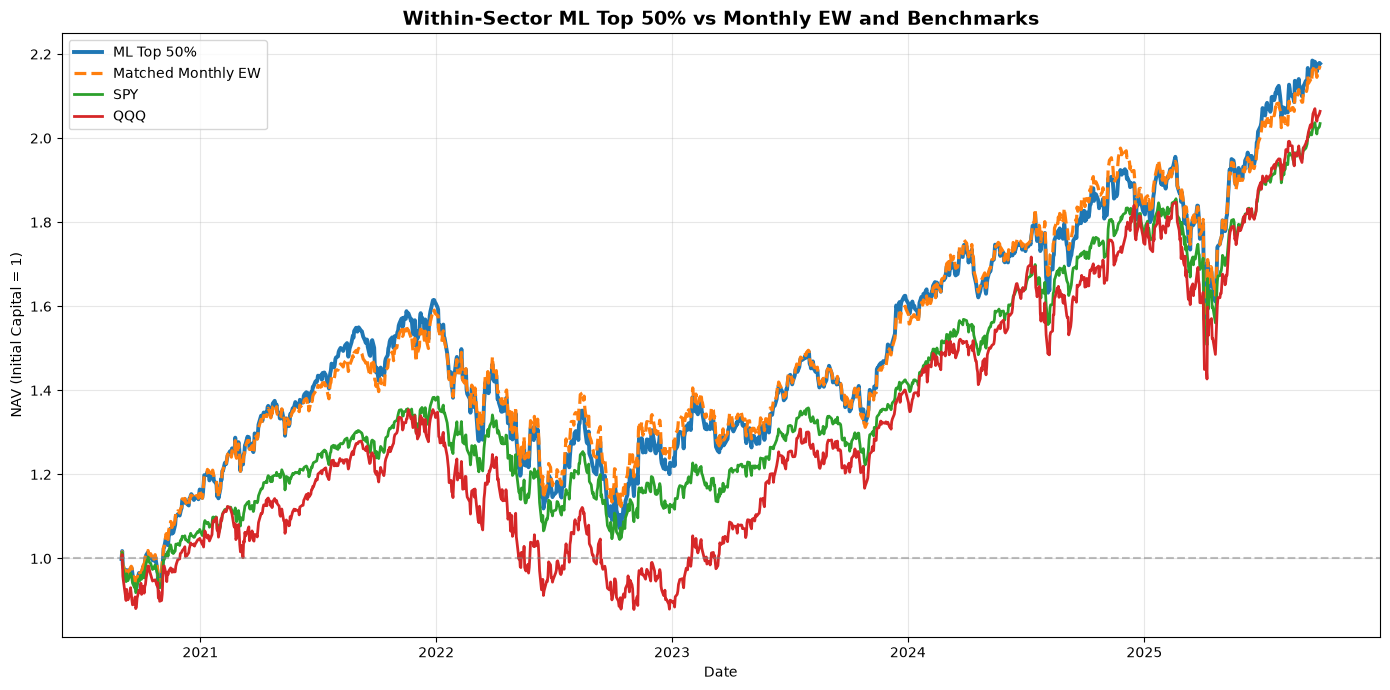


All ML Top 50% backtest checks passed.
Cell 18 completed successfully.


In [19]:

# ============================================================
# Cell 18 - Within-Sector ML Top 50% Backtest
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Run ML Top 50% strategy
# ------------------------------------------------------------

ml_top50_result = run_monthly_backtest(
    target_weights=ml_top50_weights,
    daily_returns=daily_returns,
    fee_rate=FEE_RATE
)

# ------------------------------------------------------------
# 2. Align with existing benchmarks
# ------------------------------------------------------------

top50_comparison = monthly_comparison[
    ["Matched Monthly EW", "SPY", "QQQ"]
].copy()

assert ml_top50_result.index.equals(
    top50_comparison.index
)

top50_comparison["ML Top 50%"] = (
    ml_top50_result["nav"]
)

strategy_order = [
    "ML Top 50%",
    "Matched Monthly EW",
    "SPY",
    "QQQ"
]

top50_comparison = top50_comparison[strategy_order]

# ------------------------------------------------------------
# 3. Performance metrics
# ------------------------------------------------------------

top50_metrics = pd.DataFrame({
    name: monthly_performance_metrics(
        top50_comparison[name]
    )
    for name in strategy_order
}).T

top50_metrics["Total Turnover"] = [
    ml_top50_result["turnover"].sum(),
    matched_ew_result["turnover"].sum(),
    np.nan,
    np.nan
]

top50_metrics["Total Cost"] = [
    ml_top50_result["cost"].sum(),
    matched_ew_result["cost"].sum(),
    np.nan,
    np.nan
]

# ------------------------------------------------------------
# 4. Realized beta and correlation
# ------------------------------------------------------------

top50_returns = (
    top50_comparison
    .pct_change(fill_method=None)
    .iloc[1:]
)

spy_returns = top50_returns["SPY"]

top50_metrics["Beta vs SPY"] = [
    top50_returns[name].cov(spy_returns)
    / spy_returns.var()
    for name in strategy_order
]

top50_metrics["Correlation vs SPY"] = [
    top50_returns[name].corr(spy_returns)
    for name in strategy_order
]

# ------------------------------------------------------------
# 5. Main performance comparison
# ------------------------------------------------------------

print("=" * 75)
print("WITHIN-SECTOR ML TOP 50% - BACKTEST RESULTS")
print("=" * 75)

print("\nBacktest Period:")
print(
    top50_comparison.index.min().date(),
    "to",
    top50_comparison.index.max().date()
)

print("\nTrading Days:", len(top50_comparison))
print("Monthly Rebalances:", len(ml_top50_weights))

print("\nPerformance Comparison:")
print(top50_metrics.round(4).to_string())

print("\nFinal NAV:")
print(top50_comparison.iloc[-1].round(6))

# ------------------------------------------------------------
# 6. Relative performance
# ------------------------------------------------------------

top50_final = top50_comparison[
    "ML Top 50%"
].iloc[-1]

ew_final = top50_comparison[
    "Matched Monthly EW"
].iloc[-1]

spy_final = top50_comparison["SPY"].iloc[-1]
qqq_final = top50_comparison["QQQ"].iloc[-1]

print("\nRelative Performance:")

print(
    "ML Top 50% vs Monthly EW:",
    f"{(top50_final / ew_final - 1) * 100:+.3f}%"
)

print(
    "ML Top 50% vs SPY:",
    f"{(top50_final / spy_final - 1) * 100:+.3f}%"
)

print(
    "ML Top 50% vs QQQ:",
    f"{(top50_final / qqq_final - 1) * 100:+.3f}%"
)

# ------------------------------------------------------------
# 7. Risk changes vs Monthly EW
# ------------------------------------------------------------

print("\nRisk Changes vs Monthly EW:")

for metric in [
    "Volatility (%)",
    "Sharpe",
    "Max Drawdown (%)",
    "Beta vs SPY"
]:

    change = (
        top50_metrics.loc["ML Top 50%", metric]
        - top50_metrics.loc["Matched Monthly EW", metric]
    )

    print(f"{metric}: {change:+.4f}")

# ------------------------------------------------------------
# 8. Annual returns
# ------------------------------------------------------------

annual_returns = (
    (1.0 + top50_returns)
    .groupby(top50_returns.index.year)
    .prod() - 1.0
) * 100

annual_returns["Top 50% - EW"] = (
    annual_returns["ML Top 50%"]
    - annual_returns["Matched Monthly EW"]
)

print("\nAnnual Returns (%):")
print(annual_returns.round(3).to_string())

# ------------------------------------------------------------
# 9. Development vs Evaluation
# ------------------------------------------------------------

periods = {
    "Development 2020-2023": (
        "2020-09-01", "2023-12-29"
    ),
    "Evaluation 2024-2025": (
        "2024-01-01", "2025-09-30"
    )
}

print("\nSubperiod Performance:")

# Use net_ret for the strategy portfolios so that the
# initial transaction cost is included where applicable.
subperiod_returns = top50_returns.copy()

subperiod_returns["ML Top 50%"] = (
    ml_top50_result["net_ret"]
)

subperiod_returns["Matched Monthly EW"] = (
    matched_ew_result["net_ret"]
)

for period_name, (start, end) in periods.items():

    period_data = subperiod_returns.loc[start:end]

    period_nav = (
        1.0 + period_data
    ).prod()

    print(f"\n{period_name}")
    print(period_nav.round(4).to_string())

    print(
        "Top 50% vs Monthly EW:",
        f"{(period_nav['ML Top 50%'] / period_nav['Matched Monthly EW'] - 1) * 100:+.3f}%"
    )

    print(
        "Top 50% vs SPY:",
        f"{(period_nav['ML Top 50%'] / period_nav['SPY'] - 1) * 100:+.3f}%"
    )

# ------------------------------------------------------------
# 10. Plot cumulative NAV
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

styles = {
    "ML Top 50%": ("#1f77b4", "-", 2.8),
    "Matched Monthly EW": ("#ff7f0e", "--", 2.3),
    "SPY": ("#2ca02c", "-", 2.0),
    "QQQ": ("#d62728", "-", 2.0)
}

for name, (color, linestyle, width) in styles.items():

    ax.plot(
        top50_comparison.index,
        top50_comparison[name],
        label=name,
        color=color,
        linestyle=linestyle,
        linewidth=width
    )

ax.axhline(
    1.0,
    color="gray",
    linestyle="--",
    alpha=0.5
)

ax.set_title(
    "Within-Sector ML Top 50% vs Monthly EW and Benchmarks",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("NAV (Initial Capital = 1)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Validation and save
# ------------------------------------------------------------

assert top50_comparison.notna().all().all()

assert np.isfinite(
    top50_comparison.to_numpy()
).all()

assert (top50_comparison > 0).all().all()

top50_comparison.to_csv(
    "./results/ml_top50_nav.csv"
)

top50_metrics.to_csv(
    "./results/ml_top50_metrics.csv"
)

annual_returns.to_csv(
    "./results/ml_top50_annual_returns.csv"
)

print("\nAll ML Top 50% backtest checks passed.")
print("Cell 18 completed successfully.")


In [20]:

# ============================================================
# Cell 19 - Market-Residual Momentum Portfolio Construction
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Fixed configuration
# ------------------------------------------------------------

RES_MOM_LOOKBACK = 126
RES_MOM_SKIP = 21
RES_MOM_MIN_OBS = 80
RES_MOM_TILT = 0.50

res_mom_weights = pd.DataFrame(
    0.0,
    index=monthly_rebalance_dates,
    columns=matched_monthly_ew_weights.columns
)

res_mom_records = []

# Existing adjusted SPY close-to-close returns
spy_market_returns = (
    comparison_nav["SPY"]
    .pct_change(fill_method=None)
    .dropna()
)

# ------------------------------------------------------------
# 2. Build monthly portfolios
# ------------------------------------------------------------

for trade_date in monthly_rebalance_dates:

    inputs = mvo_inputs[trade_date]
    tickers = pd.Index(inputs["tickers"])
    signal_date = inputs["signal_date"]

    # --------------------------------------------------------
    # SPY observations strictly before rebalance
    # --------------------------------------------------------

    market_history = spy_market_returns.loc[
        spy_market_returns.index < trade_date
    ].tail(RES_MOM_LOOKBACK + RES_MOM_SKIP)

    enough_history = (
        len(market_history)
        == RES_MOM_LOOKBACK + RES_MOM_SKIP
    )

    scores = pd.Series(np.nan, index=tickers)
    beta_values = pd.Series(np.nan, index=tickers)

    # --------------------------------------------------------
    # Calculate beta-adjusted historical momentum
    # --------------------------------------------------------

    if enough_history:

        formation_market = (
            market_history.iloc[:-RES_MOM_SKIP]
        )

        formation_dates = formation_market.index
        market_values = formation_market.to_numpy()

        stock_history = daily_returns.reindex(
            index=formation_dates,
            columns=tickers
        )

        for tic in tickers:

            stock_values = stock_history[
                tic
            ].to_numpy(dtype=float)

            valid = (
                np.isfinite(stock_values)
                & np.isfinite(market_values)
                & (stock_values > -1.0)
                & (market_values > -1.0)
            )

            if valid.sum() < RES_MOM_MIN_OBS:
                continue

            y = stock_values[valid]
            m = market_values[valid]

            market_variance = np.var(m, ddof=1)

            if market_variance <= 0:
                continue

            beta = (
                np.cov(y, m, ddof=1)[0, 1]
                / market_variance
            )

            beta = np.clip(beta, 0.0, 3.0)

            # Beta-adjusted log-return performance.
            # This is a market-adjusted momentum proxy,
            # not a fully factor-neutral alpha estimate.
            adjusted_log_returns = (
                np.log1p(y)
                - beta * np.log1p(m)
            )

            score = (
                adjusted_log_returns.mean()
                * RES_MOM_LOOKBACK
            )

            scores.loc[tic] = score
            beta_values.loc[tic] = beta

    # --------------------------------------------------------
    # 3. Point-in-time sector mapping
    # --------------------------------------------------------

    sector_history = mvo_sector_data.loc[
        (mvo_sector_data["reportdate"] <= signal_date)
        & (mvo_sector_data["tic"].isin(tickers))
    ]

    sectors = (
        sector_history
        .sort_values(["tic", "reportdate"])
        .drop_duplicates("tic", keep="last")
        .set_index("tic")["gsector"]
        .reindex(tickers)
    )

    if sectors.isna().any():
        raise ValueError(
            f"Missing sectors on {trade_date}"
        )

    frame = pd.DataFrame({
        "sector": sectors,
        "score": scores
    })

    # --------------------------------------------------------
    # 4. Sector-neutral residual momentum tilt
    # --------------------------------------------------------

    for sector, group in frame.groupby("sector"):

        sector_tickers = group.index

        sector_budget = (
            matched_monthly_ew_weights.loc[
                trade_date, sector_tickers
            ].sum()
        )

        if enough_history:

            ranks = group["score"].rank(
                pct=True,
                method="average"
            )

            tilt = (
                1.0
                + RES_MOM_TILT * (2.0 * ranks - 1.0)
            )

            tilt = tilt.fillna(1.0).clip(
                0.75, 1.25
            )

        else:
            tilt = pd.Series(
                1.0,
                index=sector_tickers
            )

        final_weights = (
            sector_budget * tilt / tilt.sum()
        )

        res_mom_weights.loc[
            trade_date, sector_tickers
        ] = final_weights.to_numpy()

    res_mom_records.append({
        "trade_date": trade_date,
        "enough_history": enough_history,
        "n_stocks": len(tickers),
        "n_scored": int(scores.notna().sum()),
        "mean_beta": beta_values.mean(),
        "l1_vs_ew": (
            res_mom_weights.loc[trade_date]
            - matched_monthly_ew_weights.loc[trade_date]
        ).abs().sum()
    })

# ------------------------------------------------------------
# 5. Diagnostics
# ------------------------------------------------------------

res_mom_info = (
    pd.DataFrame(res_mom_records)
    .set_index("trade_date")
)

print("=" * 70)
print("MARKET-RESIDUAL MOMENTUM PORTFOLIO")
print("=" * 70)

print("\nWeight Matrix:")
print(res_mom_weights.shape)

print("\nMonths with Sufficient SPY History:")
print(int(res_mom_info["enough_history"].sum()))

print("\nEW Warm-Up Months:")
print(int((~res_mom_info["enough_history"]).sum()))

print("\nStocks with Valid Residual Momentum:")
print(res_mom_info["n_scored"].describe().round(2))

print("\nL1 Deviation from Monthly EW:")
print(res_mom_info["l1_vs_ew"].describe().round(4))

print("\nMaximum Individual Weight:")
print(
    res_mom_weights.max(axis=1)
    .describe().round(5)
)

print("\nFirst 8 Rebalances:")
print(res_mom_info.head(8).round(4).to_string())

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

assert np.allclose(
    res_mom_weights.sum(axis=1), 1.0
)

assert (res_mom_weights >= 0).all().all()

assert res_mom_weights.index.equals(
    matched_monthly_ew_weights.index
)

assert res_mom_weights.columns.equals(
    matched_monthly_ew_weights.columns
)

assert (
    (res_mom_weights > 0)
    == (matched_monthly_ew_weights > 0)
).all().all()

assert np.isfinite(
    res_mom_weights.to_numpy()
).all()

res_mom_weights.to_csv(
    "./results/residual_momentum_weights.csv"
)

res_mom_info.to_csv(
    "./results/residual_momentum_diagnostics.csv"
)

print("\nAll residual momentum checks passed.")
print("Cell 19 completed successfully.")


MARKET-RESIDUAL MOMENTUM PORTFOLIO

Weight Matrix:
(61, 418)

Months with Sufficient SPY History:
58

EW Warm-Up Months:
3

Stocks with Valid Residual Momentum:
count     61.00
mean     106.95
std       26.03
min        0.00
25%      104.00
50%      112.00
75%      119.00
max      142.00
Name: n_scored, dtype: float64

L1 Deviation from Monthly EW:
count    61.0000
mean      0.1740
std       0.0399
min       0.0000
25%       0.1820
50%       0.1828
75%       0.1841
max       0.1856
Name: l1_vs_ew, dtype: float64

Maximum Individual Weight:
count    61.00000
mean      0.01103
std       0.00098
min       0.00833
25%       0.01038
50%       0.01090
75%       0.01185
max       0.01295
dtype: float64

First 8 Rebalances:
            enough_history  n_stocks  n_scored  mean_beta  l1_vs_ew
trade_date                                                         
2020-09-01           False       117         0        NaN    0.0000
2020-10-01           False       120         0        NaN    0.0000
20

MARKET-RESIDUAL MOMENTUM - BACKTEST RESULTS

Backtest Period:
2020-09-01 to 2025-09-30

Trading Days: 1276
Monthly Rebalances: 61

Performance Comparison:
                    Final NAV  Total Return (%)  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)  Total Turnover  Total Cost  Beta vs SPY  Correlation vs SPY
Residual Momentum      2.1345          113.4493   16.1674         19.9013  0.8536          -30.3738         25.1776      0.0252       1.0864              0.9502
Matched Monthly EW     2.1718          117.1843   16.5663         20.0433  0.8660          -29.5172         22.1377      0.0221       1.0930              0.9492
SPY                    2.0347          103.4731   15.0735         17.4067  0.8936          -24.4964             NaN         NaN       1.0000              1.0000
QQQ                    2.0638          106.3847   15.3971         23.1248  0.7349          -35.1187             NaN         NaN       1.2493              0.9404

Final NAV:
Residual Momentum     2.1344

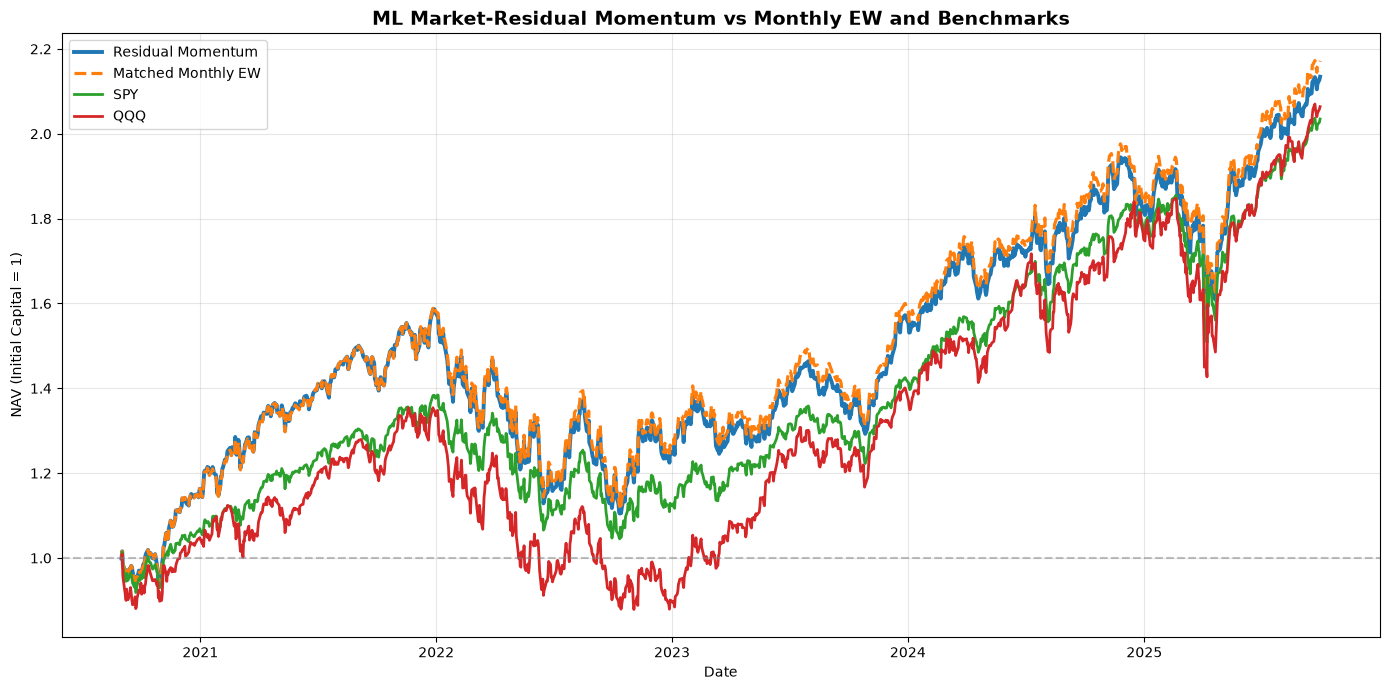


All residual momentum backtest checks passed.
Cell 20 completed successfully.


In [21]:

# ============================================================
# Cell 20 - Market-Residual Momentum Backtest
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Run Residual Momentum Strategy
# ------------------------------------------------------------

res_mom_result = run_monthly_backtest(
    target_weights=res_mom_weights,
    daily_returns=daily_returns,
    fee_rate=FEE_RATE
)

# ------------------------------------------------------------
# 2. Align strategies and benchmarks
# ------------------------------------------------------------

res_mom_comparison = monthly_comparison[
    ["Matched Monthly EW", "SPY", "QQQ"]
].copy()

assert res_mom_result.index.equals(
    res_mom_comparison.index
)

res_mom_comparison["Residual Momentum"] = (
    res_mom_result["nav"]
)

strategy_order = [
    "Residual Momentum",
    "Matched Monthly EW",
    "SPY",
    "QQQ"
]

res_mom_comparison = res_mom_comparison[strategy_order]

# ------------------------------------------------------------
# 3. Performance metrics
# ------------------------------------------------------------

res_mom_metrics = pd.DataFrame({
    name: monthly_performance_metrics(
        res_mom_comparison[name]
    )
    for name in strategy_order
}).T

res_mom_metrics["Total Turnover"] = [
    res_mom_result["turnover"].sum(),
    matched_ew_result["turnover"].sum(),
    np.nan,
    np.nan
]

res_mom_metrics["Total Cost"] = [
    res_mom_result["cost"].sum(),
    matched_ew_result["cost"].sum(),
    np.nan,
    np.nan
]

# ------------------------------------------------------------
# 4. Realized Beta and Correlation
# ------------------------------------------------------------

res_mom_daily_ret = (
    res_mom_comparison
    .pct_change(fill_method=None)
    .iloc[1:]
)

spy_ret = res_mom_daily_ret["SPY"]

res_mom_metrics["Beta vs SPY"] = [
    res_mom_daily_ret[name].cov(spy_ret)
    / spy_ret.var()
    for name in strategy_order
]

res_mom_metrics["Correlation vs SPY"] = [
    res_mom_daily_ret[name].corr(spy_ret)
    for name in strategy_order
]

# ------------------------------------------------------------
# 5. Main performance comparison
# ------------------------------------------------------------

print("=" * 75)
print("MARKET-RESIDUAL MOMENTUM - BACKTEST RESULTS")
print("=" * 75)

print("\nBacktest Period:")
print(
    res_mom_comparison.index.min().date(),
    "to",
    res_mom_comparison.index.max().date()
)

print("\nTrading Days:", len(res_mom_comparison))
print("Monthly Rebalances:", len(res_mom_weights))

print("\nPerformance Comparison:")
print(res_mom_metrics.round(4).to_string())

print("\nFinal NAV:")
print(res_mom_comparison.iloc[-1].round(6))

# ------------------------------------------------------------
# 6. Relative performance
# ------------------------------------------------------------

res_final = res_mom_comparison[
    "Residual Momentum"
].iloc[-1]

ew_final = res_mom_comparison[
    "Matched Monthly EW"
].iloc[-1]

spy_final = res_mom_comparison["SPY"].iloc[-1]
qqq_final = res_mom_comparison["QQQ"].iloc[-1]

print("\nRelative Performance:")

print(
    "Residual Momentum vs Monthly EW:",
    f"{(res_final / ew_final - 1) * 100:+.3f}%"
)

print(
    "Residual Momentum vs SPY:",
    f"{(res_final / spy_final - 1) * 100:+.3f}%"
)

print(
    "Residual Momentum vs QQQ:",
    f"{(res_final / qqq_final - 1) * 100:+.3f}%"
)

# ------------------------------------------------------------
# 7. Risk changes vs Monthly EW
# ------------------------------------------------------------

print("\nRisk Changes vs Monthly EW:")

for metric in [
    "Volatility (%)",
    "Sharpe",
    "Max Drawdown (%)",
    "Beta vs SPY"
]:

    change = (
        res_mom_metrics.loc[
            "Residual Momentum", metric
        ]
        - res_mom_metrics.loc[
            "Matched Monthly EW", metric
        ]
    )

    print(f"{metric}: {change:+.4f}")

# ------------------------------------------------------------
# 8. Annual returns
# ------------------------------------------------------------

annual_returns = (
    (1.0 + res_mom_daily_ret)
    .groupby(res_mom_daily_ret.index.year)
    .prod() - 1.0
) * 100

annual_returns["Residual - EW"] = (
    annual_returns["Residual Momentum"]
    - annual_returns["Matched Monthly EW"]
)

print("\nAnnual Returns (%):")
print(annual_returns.round(3).to_string())

# ------------------------------------------------------------
# 9. Development vs Evaluation
# ------------------------------------------------------------

periods = {
    "Development 2020-2023": (
        "2020-09-01", "2023-12-29"
    ),
    "Evaluation 2024-2025": (
        "2024-01-01", "2025-09-30"
    )
}

# Use actual net returns, including initial trade cost
subperiod_returns = res_mom_daily_ret.copy()

subperiod_returns["Residual Momentum"] = (
    res_mom_result["net_ret"]
)

subperiod_returns["Matched Monthly EW"] = (
    matched_ew_result["net_ret"]
)

print("\nSubperiod Performance:")

for period_name, (start, end) in periods.items():

    period_data = subperiod_returns.loc[start:end]

    period_nav = (1.0 + period_data).prod()

    print(f"\n{period_name}")
    print(period_nav.round(4).to_string())

    print(
        "Residual vs Monthly EW:",
        f"{(period_nav['Residual Momentum'] / period_nav['Matched Monthly EW'] - 1) * 100:+.3f}%"
    )

    print(
        "Residual vs SPY:",
        f"{(period_nav['Residual Momentum'] / period_nav['SPY'] - 1) * 100:+.3f}%"
    )

# ------------------------------------------------------------
# 10. Plot cumulative NAV
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

styles = {
    "Residual Momentum": ("#1f77b4", "-", 2.8),
    "Matched Monthly EW": ("#ff7f0e", "--", 2.3),
    "SPY": ("#2ca02c", "-", 2.0),
    "QQQ": ("#d62728", "-", 2.0)
}

for name, (color, linestyle, width) in styles.items():

    ax.plot(
        res_mom_comparison.index,
        res_mom_comparison[name],
        label=name,
        color=color,
        linestyle=linestyle,
        linewidth=width
    )

ax.axhline(
    1.0,
    color="gray",
    linestyle="--",
    alpha=0.5
)

ax.set_title(
    "ML Market-Residual Momentum vs Monthly EW and Benchmarks",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("NAV (Initial Capital = 1)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Validation and save
# ------------------------------------------------------------

assert res_mom_comparison.notna().all().all()

assert np.isfinite(
    res_mom_comparison.to_numpy()
).all()

assert (res_mom_comparison > 0).all().all()

res_mom_comparison.to_csv(
    "./results/residual_momentum_nav.csv"
)

res_mom_metrics.to_csv(
    "./results/residual_momentum_metrics.csv"
)

annual_returns.to_csv(
    "./results/residual_momentum_annual_returns.csv"
)

print("\nAll residual momentum backtest checks passed.")
print("Cell 20 completed successfully.")


In [22]:

# ============================================================
# Cell 21 - Fundamental Factor Inventory
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Load fundamental factor data
# ------------------------------------------------------------

fundamental_file = "./prepared/final_ratios.csv"

fundamentals = pd.read_csv(
    fundamental_file,
    low_memory=False,
    parse_dates=["reportdate"]
)

print("=" * 70)
print("FUNDAMENTAL FACTOR INVENTORY")
print("=" * 70)

print("\nDataset Shape:")
print(fundamentals.shape)

print("\nDate Range:")
print(fundamentals["reportdate"].min())
print(fundamentals["reportdate"].max())

print("\nUnique Stocks:")
print(fundamentals["tic"].nunique())

# ------------------------------------------------------------
# 2. Available factor columns
# ------------------------------------------------------------

metadata_columns = {
    "tic", "reportdate", "gsector"
}

factor_columns = [
    col for col in fundamentals.columns
    if col not in metadata_columns
]

print("\nAvailable Factor Columns:")
for col in factor_columns:
    print(col)

# ------------------------------------------------------------
# 3. Identify potential quality and value factors
# ------------------------------------------------------------

keywords = [
    "roe", "roa", "profit", "margin",
    "earn", "yield", "value", "book",
    "debt", "leverage", "liquid",
    "current", "quick", "cash",
    "pe", "pb", "ps", "bm",
    "growth", "sales", "asset",
    "return", "accrual"
]

candidate_factors = [
    col for col in factor_columns
    if any(
        keyword in col.lower()
        for keyword in keywords
    )
]

print("\nPotential Quality / Value Factors:")
print(candidate_factors)

# ------------------------------------------------------------
# 4. Factor coverage diagnostics
# ------------------------------------------------------------

factor_records = []

for col in factor_columns:

    values = pd.to_numeric(
        fundamentals[col],
        errors="coerce"
    )

    finite = np.isfinite(values)

    factor_records.append({
        "Factor": col,
        "Coverage (%)": finite.mean() * 100,
        "Median": values[finite].median(),
        "Std": values[finite].std(),
        "Unique Values": values[finite].nunique()
    })

factor_coverage = (
    pd.DataFrame(factor_records)
    .sort_values(
        "Coverage (%)",
        ascending=False
    )
)

print("\nCandidate Factor Coverage:")
print(
    factor_coverage[
        factor_coverage["Factor"].isin(
            candidate_factors
        )
    ].round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 5. Recent fundamental reporting dates
# ------------------------------------------------------------

print("\nLatest Report Dates:")
print(
    fundamentals[
        ["tic", "reportdate"]
    ]
    .sort_values("reportdate")
    .tail(10)
    .to_string(index=False)
)

print("\nCell 21 completed successfully.")


FUNDAMENTAL FACTOR INVENTORY

Dataset Shape:
(19007, 59)

Date Range:
2015-04-03 00:00:00
2025-11-25 00:00:00

Unique Stocks:
674

Available Factor Columns:
date
adj_close_q
EPS
BPS
DPS
cur_ratio
quick_ratio
cash_ratio
acc_rec_turnover
debt_ratio
debt_to_equity
pe
ps
pb
roe
net_income_ratio
y_return
gross_margin
operating_margin
ebitda_margin
pretax_margin
effective_tax_rate
ebt_per_ebit
asset_turnover
fixed_asset_turnover
inventory_turnover
payables_turnover
wc_turnover
debt_to_assets
debt_to_capital
lt_debt_to_capital
interest_coverage
debt_service_coverage
debt_to_mktcap
fcf_per_share
ocf_per_share
cash_per_share
capex_per_share
fcf_to_ocf
ocf_ratio
ocf_to_sales
ocf_coverage
st_ocf_coverage
capex_coverage
revenue_per_share
tangible_bvps
interest_debt_per_share
peg
price_to_fcf
price_to_ocf
ev_multiple
dividend_payout
dividend_yield
div_capex_coverage
solvency_ratio
gsector_name

Potential Quality / Value Factors:
['EPS', 'BPS', 'DPS', 'quick_ratio', 'cash_ratio', 'debt_ratio', 'debt

In [23]:

# ============================================================
# Cell 22 - Fundamental Factor and Date Audit
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Inspect available factor names
# ------------------------------------------------------------

metadata_cols = {
    "tic", "date", "reportdate",
    "gsector", "adj_close_q"
}

factor_cols = [
    c for c in fundamentals.columns
    if c not in metadata_cols
]

print("=" * 70)
print("AVAILABLE FUNDAMENTAL FACTORS")
print("=" * 70)

for i, col in enumerate(factor_cols, start=1):
    print(f"{i:2d}. {col}")

# ------------------------------------------------------------
# 2. Find quality and value candidates
# ------------------------------------------------------------

keywords = [
    "roe", "roa", "roic", "profit",
    "margin", "debt", "leverage",
    "earn", "eps", "bps", "book",
    "pe", "pb", "ps", "value",
    "yield", "growth", "cash",
    "current", "quick", "asset",
    "equity"
]

candidates = [
    c for c in factor_cols
    if any(k in c.lower() for k in keywords)
]

records = []

for col in candidates:

    values = pd.to_numeric(
        fundamentals[col],
        errors="coerce"
    )

    valid = values.replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    records.append({
        "Factor": col,
        "Coverage (%)": round(
            len(valid) / len(values) * 100, 2
        ),
        "Median": valid.median(),
        "Std": valid.std(),
        "Unique": valid.nunique()
    })

quality_value_coverage = pd.DataFrame(records)

print("\n" + "=" * 70)
print("QUALITY / VALUE FACTOR COVERAGE")
print("=" * 70)

print(
    quality_value_coverage
    .round(4)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 3. Inspect date definitions
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATE FIELD AUDIT")
print("=" * 70)

print("\nOriginal date field examples:")
print(
    fundamentals[
        ["tic", "date", "reportdate"]
    ].head(10).to_string(index=False)
)

print("\nOriginal date dtype:")
print(fundamentals["date"].dtype)

date_parsed = pd.to_datetime(
    fundamentals["date"],
    errors="coerce"
)

reportdate_parsed = pd.to_datetime(
    fundamentals["reportdate"],
    errors="coerce"
)

valid_dates = (
    date_parsed.notna()
    & reportdate_parsed.notna()
)

date_gap = (
    date_parsed[valid_dates]
    - reportdate_parsed[valid_dates]
).dt.days

print("\nDate coverage:")
print("Valid date pairs:", int(valid_dates.sum()))
print("Invalid date pairs:", int((~valid_dates).sum()))

if len(date_gap) > 0:
    print("\nDate - Reportdate (days):")
    print(date_gap.describe().round(2))

    print("\nDate relationship:")
    print("Date before reportdate:", int((date_gap < 0).sum()))
    print("Same date:", int((date_gap == 0).sum()))
    print("Date after reportdate:", int((date_gap > 0).sum()))

# ------------------------------------------------------------
# 4. Duplicate fundamental records
# ------------------------------------------------------------

print("\nDuplicate ticker/reportdate records:")
print(
    int(
        fundamentals.duplicated(
            ["tic", "reportdate"]
        ).sum()
    )
)

print("\nCell 22 completed successfully.")


AVAILABLE FUNDAMENTAL FACTORS
 1. EPS
 2. BPS
 3. DPS
 4. cur_ratio
 5. quick_ratio
 6. cash_ratio
 7. acc_rec_turnover
 8. debt_ratio
 9. debt_to_equity
10. pe
11. ps
12. pb
13. roe
14. net_income_ratio
15. y_return
16. gross_margin
17. operating_margin
18. ebitda_margin
19. pretax_margin
20. effective_tax_rate
21. ebt_per_ebit
22. asset_turnover
23. fixed_asset_turnover
24. inventory_turnover
25. payables_turnover
26. wc_turnover
27. debt_to_assets
28. debt_to_capital
29. lt_debt_to_capital
30. interest_coverage
31. debt_service_coverage
32. debt_to_mktcap
33. fcf_per_share
34. ocf_per_share
35. cash_per_share
36. capex_per_share
37. fcf_to_ocf
38. ocf_ratio
39. ocf_to_sales
40. ocf_coverage
41. st_ocf_coverage
42. capex_coverage
43. revenue_per_share
44. tangible_bvps
45. interest_debt_per_share
46. peg
47. price_to_fcf
48. price_to_ocf
49. ev_multiple
50. dividend_payout
51. dividend_yield
52. div_capex_coverage
53. solvency_ratio
54. gsector_name

QUALITY / VALUE FACTOR COVERAGE
 

In [24]:

# ============================================================
# Cell 23 - Fundamental Reporting Date Consistency Audit
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Prepare date audit
# ------------------------------------------------------------

date_audit = fundamentals[
    ["tic", "date", "reportdate", "gsector"]
].copy()

date_audit["date"] = pd.to_datetime(
    date_audit["date"], errors="coerce"
)

date_audit["reportdate"] = pd.to_datetime(
    date_audit["reportdate"], errors="coerce"
)

date_audit["gap_days"] = (
    date_audit["date"] - date_audit["reportdate"]
).dt.days

# Positive gap: filing date precedes fiscal period end
date_audit["suspicious"] = date_audit["gap_days"] > 0

date_audit["fiscal_year"] = date_audit["date"].dt.year

# ------------------------------------------------------------
# 2. Overall diagnostics
# ------------------------------------------------------------

print("=" * 70)
print("FUNDAMENTAL REPORTING DATE CONSISTENCY AUDIT")
print("=" * 70)

print("\nTotal Records:", len(date_audit))

print("Suspicious Records:",
      int(date_audit["suspicious"].sum()))

print("Suspicious Percentage:",
      f"{date_audit['suspicious'].mean() * 100:.2f}%")

print("\nDate Gap Summary (all records):")
print(date_audit["gap_days"].describe().round(2))

# ------------------------------------------------------------
# 3. Suspicious records by fiscal year
# ------------------------------------------------------------

year_summary = (
    date_audit.groupby("fiscal_year")
    .agg(
        total_records=("tic", "size"),
        suspicious_records=("suspicious", "sum")
    )
)

year_summary["suspicious_pct"] = (
    year_summary["suspicious_records"]
    / year_summary["total_records"] * 100
)

print("\nSuspicious Records by Fiscal Year:")
print(year_summary.round(2).to_string())

# ------------------------------------------------------------
# 4. Gap severity
# ------------------------------------------------------------

suspicious = date_audit.loc[
    date_audit["suspicious"]
].copy()

print("\nSuspicious Gap Distribution (days):")
print(suspicious["gap_days"].describe().round(2))

gap_buckets = pd.cut(
    suspicious["gap_days"],
    bins=[0, 7, 30, 60, 90, np.inf],
    labels=[
        "1-7 days",
        "8-30 days",
        "31-60 days",
        "61-90 days",
        ">90 days"
    ]
)

print("\nSuspicious Gap Buckets:")
print(gap_buckets.value_counts().sort_index())

# ------------------------------------------------------------
# 5. Most affected tickers
# ------------------------------------------------------------

print("\nTop 15 Tickers by Suspicious Record Count:")
print(
    suspicious["tic"]
    .value_counts()
    .head(15)
    .to_string()
)

# ------------------------------------------------------------
# 6. Examples
# ------------------------------------------------------------

print("\nFirst 15 Suspicious Records:")
print(
    suspicious[
        ["tic", "date", "reportdate", "gap_days"]
    ]
    .sort_values(
        ["date", "tic"]
    )
    .head(15)
    .to_string(index=False)
)

print("\nLargest 15 Suspicious Gaps:")
print(
    suspicious[
        ["tic", "date", "reportdate", "gap_days"]
    ]
    .sort_values("gap_days", ascending=False)
    .head(15)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 7. Check duplicates and date validity
# ------------------------------------------------------------

print("\nDuplicate Ticker + Fiscal Date:")
print(
    int(date_audit.duplicated(["tic", "date"]).sum())
)

print("\nDuplicate Ticker + Report Date:")
print(
    int(date_audit.duplicated(
        ["tic", "reportdate"]
    ).sum())
)

print("\nMissing or Invalid Dates:")
print(
    date_audit[
        ["date", "reportdate"]
    ].isna().sum()
)

print("\nCell 23 completed successfully.")


FUNDAMENTAL REPORTING DATE CONSISTENCY AUDIT

Total Records: 19007
Suspicious Records: 2194
Suspicious Percentage: 11.54%

Date Gap Summary (all records):
count    19007.00
mean       -27.42
std         24.65
min       -287.00
25%        -38.00
50%        -33.00
75%        -26.00
max         90.00
Name: gap_days, dtype: float64

Suspicious Records by Fiscal Year:
             total_records  suspicious_records  suspicious_pct
fiscal_year                                                   
2015                   178                  27           15.17
2016                  1770                 230           12.99
2017                  1860                 250           13.44
2018                  1915                 211           11.02
2019                  1956                 195            9.97
2020                  1975                 201           10.18
2021                  1957                 256           13.08
2022                  1953                 245           12.54
2023

In [25]:

# ============================================================
# Cell 24 - Point-in-Time Quality-Value Portfolio
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Strategy configuration
# ------------------------------------------------------------

QV_FACTORS = {
    "roe": True,
    "operating_margin": True,
    "debt_ratio": False,
    "pb": False
}

QV_TILT = 0.50
QV_MAX_AGE_DAYS = 540

# ------------------------------------------------------------
# 2. Prepare historical fundamental records
# ------------------------------------------------------------

qv_data = fundamentals[
    ["tic", "date", "reportdate", *QV_FACTORS.keys()]
].copy()

qv_data["date"] = pd.to_datetime(
    qv_data["date"], errors="coerce"
)

qv_data["reportdate"] = pd.to_datetime(
    qv_data["reportdate"], errors="coerce"
)

qv_data = qv_data.dropna(
    subset=["tic", "date", "reportdate"]
)

for factor in QV_FACTORS:
    qv_data[factor] = pd.to_numeric(
        qv_data[factor], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

# Exclude invalid valuation ratios
qv_data.loc[qv_data["pb"] <= 0, "pb"] = np.nan
qv_data.loc[
    qv_data["debt_ratio"] < 0, "debt_ratio"
] = np.nan

# Remove ambiguous duplicate ticker/filing-date pairs
duplicate_mask = qv_data.duplicated(
    ["tic", "reportdate"], keep=False
)

print("Ambiguous fundamental rows excluded:",
      int(duplicate_mask.sum()))

qv_data = (
    qv_data.loc[~duplicate_mask]
    .sort_values(["tic", "reportdate"])
    .copy()
)

# ------------------------------------------------------------
# 3. Initialize monthly portfolio weights
# ------------------------------------------------------------

qv_weights = pd.DataFrame(
    0.0,
    index=monthly_rebalance_dates,
    columns=matched_monthly_ew_weights.columns
)

qv_records = []

# ------------------------------------------------------------
# 4. Construct monthly Quality-Value portfolios
# ------------------------------------------------------------

for trade_date in monthly_rebalance_dates:

    inputs = mvo_inputs[trade_date]

    tickers = pd.Index(inputs["tickers"])
    signal_date = pd.Timestamp(inputs["signal_date"])

    # Only filings strictly before the ML signal date
    eligible = qv_data.loc[
        (qv_data["reportdate"] < signal_date)
        & qv_data["tic"].isin(tickers)
    ].copy()

    eligible["age_days"] = (
        signal_date - eligible["reportdate"]
    ).dt.days

    eligible = eligible.loc[
        eligible["age_days"] <= QV_MAX_AGE_DAYS
    ]

    # Latest available filing for each stock
    latest = (
        eligible
        .sort_values(["tic", "reportdate"])
        .drop_duplicates("tic", keep="last")
        .set_index("tic")
        .reindex(tickers)
    )

    # --------------------------------------------------------
    # 5. Historical sector mapping
    # --------------------------------------------------------

    sector_history = mvo_sector_data.loc[
        (mvo_sector_data["reportdate"] <= signal_date)
        & mvo_sector_data["tic"].isin(tickers)
    ]

    sectors = (
        sector_history
        .sort_values(["tic", "reportdate"])
        .drop_duplicates("tic", keep="last")
        .set_index("tic")["gsector"]
        .reindex(tickers)
    )

    if sectors.isna().any():
        raise ValueError(
            f"Missing sector on {trade_date}"
        )

    frame = latest[list(QV_FACTORS)].copy()
    frame["sector"] = sectors

    ew = matched_monthly_ew_weights.loc[
        trade_date, tickers
    ]

    # --------------------------------------------------------
    # 6. Sector-neutral Quality-Value weighting
    # --------------------------------------------------------

    for sector, group in frame.groupby("sector"):

        sector_tickers = group.index

        sector_budget = ew.loc[
            sector_tickers
        ].sum()

        scores = pd.DataFrame(
            index=sector_tickers
        )

        for factor, higher_is_better in QV_FACTORS.items():

            values = group[factor].copy()

            # Winsorization within sector
            if values.notna().sum() >= 5:
                lower = values.quantile(0.05)
                upper = values.quantile(0.95)
                values = values.clip(lower, upper)

            if (
                values.notna().sum() <= 2
                or values.nunique() <= 1
            ):
                ranks = pd.Series(
                    0.5, index=sector_tickers
                )
            else:
                ranks = values.rank(
                    pct=True,
                    ascending=higher_is_better,
                    method="average"
                ).fillna(0.5)

            scores[factor] = ranks

        composite = scores.mean(axis=1)

        tilt = (
            1.0
            + QV_TILT * (2.0 * composite - 1.0)
        )

        new_weights = (
            sector_budget * tilt / tilt.sum()
        )

        qv_weights.loc[
            trade_date, sector_tickers
        ] = new_weights.to_numpy()

    # --------------------------------------------------------
    # 7. Diagnostics
    # --------------------------------------------------------

    valid_counts = frame[list(QV_FACTORS)].notna().sum(
        axis=1
    )

    valid_dates = latest["reportdate"].dropna()

    if len(valid_dates) > 0:
        assert (valid_dates < signal_date).all()

    qv_records.append({
        "trade_date": trade_date,
        "signal_date": signal_date,
        "n_stocks": len(tickers),
        "n_all_four_factors": int(
            (valid_counts == 4).sum()
        ),
        "n_no_factors": int(
            (valid_counts == 0).sum()
        ),
        "mean_filing_age_days": (
            (signal_date - valid_dates).dt.days.mean()
            if len(valid_dates) else np.nan
        ),
        "max_weight": qv_weights.loc[
            trade_date
        ].max(),
        "l1_vs_ew": (
            qv_weights.loc[trade_date]
            - matched_monthly_ew_weights.loc[trade_date]
        ).abs().sum()
    })

# ------------------------------------------------------------
# 8. Summary
# ------------------------------------------------------------

qv_info = (
    pd.DataFrame(qv_records)
    .set_index("trade_date")
)

print("=" * 70)
print("POINT-IN-TIME QUALITY-VALUE PORTFOLIO")
print("=" * 70)

print("\nWeight Matrix:")
print(qv_weights.shape)

print("\nFundamental Coverage:")
print(
    qv_info[
        ["n_stocks", "n_all_four_factors", "n_no_factors"]
    ].describe().round(2).to_string()
)

print("\nMean Filing Age (Days):")
print(
    qv_info["mean_filing_age_days"]
    .describe().round(2)
)

print("\nMaximum Individual Weight:")
print(
    qv_info["max_weight"].describe().round(5)
)

print("\nL1 Deviation from Monthly EW:")
print(
    qv_info["l1_vs_ew"].describe().round(4)
)

print("\nFirst 5 Rebalances:")
print(qv_info.head().round(3).to_string())

# ------------------------------------------------------------
# 9. Validation
# ------------------------------------------------------------

assert np.allclose(
    qv_weights.sum(axis=1), 1.0
)

assert (qv_weights >= 0).all().all()

assert qv_weights.index.equals(
    matched_monthly_ew_weights.index
)

assert qv_weights.columns.equals(
    matched_monthly_ew_weights.columns
)

assert (
    (qv_weights > 0)
    == (matched_monthly_ew_weights > 0)
).all().all()

assert np.isfinite(
    qv_weights.to_numpy()
).all()

qv_weights.to_csv(
    "./results/quality_value_weights.csv"
)

qv_info.to_csv(
    "./results/quality_value_diagnostics.csv"
)

print("\nAll Quality-Value checks passed.")
print("Cell 24 completed successfully.")


Ambiguous fundamental rows excluded: 27
POINT-IN-TIME QUALITY-VALUE PORTFOLIO

Weight Matrix:
(61, 418)

Fundamental Coverage:
       n_stocks  n_all_four_factors  n_no_factors
count     61.00               61.00         61.00
mean     112.39              104.82          0.02
std        9.07                7.79          0.13
min       95.00               89.00          0.00
25%      105.00               99.00          0.00
50%      113.00              104.00          0.00
75%      119.00              112.00          0.00
max      142.00              130.00          1.00

Mean Filing Age (Days):
count    61.00
mean     49.26
std      15.07
min      22.39
25%      36.21
50%      49.12
75%      57.58
max      85.14
Name: mean_filing_age_days, dtype: float64

Maximum Individual Weight:
count    61.00000
mean      0.01151
std       0.00104
min       0.00868
25%       0.01060
50%       0.01167
75%       0.01229
max       0.01359
Name: max_weight, dtype: float64

L1 Deviation from Monthly EW:

QUALITY-VALUE PORTFOLIO - BACKTEST RESULTS

Backtest Period:
2020-09-01 to 2025-09-30

Trading Days: 1276
Monthly Rebalances: 61

Performance Comparison:
                    Final NAV  Total Return (%)  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)  Total Turnover  Total Cost  Beta vs SPY  Correlation vs SPY
Quality-Value          2.1547          115.4692   16.3838         20.0741  0.8572          -29.6377         22.4767      0.0225       1.0957              0.9501
Matched Monthly EW     2.1718          117.1843   16.5663         20.0433  0.8660          -29.5172         22.1377      0.0221       1.0930              0.9492
SPY                    2.0347          103.4731   15.0735         17.4067  0.8936          -24.4964             NaN         NaN       1.0000              1.0000
QQQ                    2.0638          106.3847   15.3971         23.1248  0.7349          -35.1187             NaN         NaN       1.2493              0.9404

Final NAV:
Quality-Value         2.15469

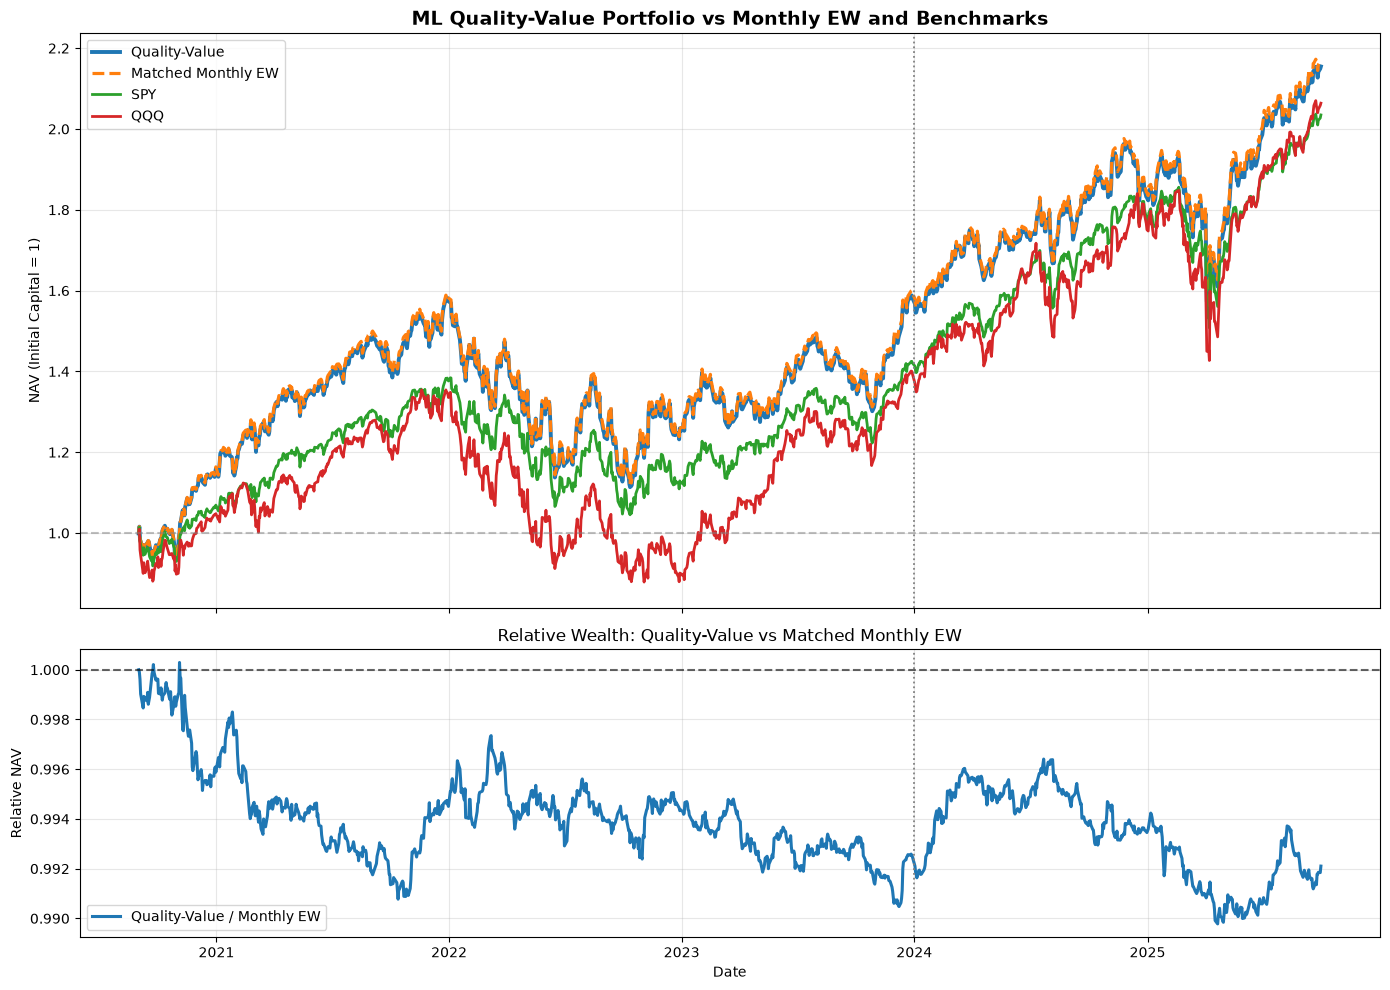


All Quality-Value backtest checks passed.
Cell 25 completed successfully.


In [26]:

# ============================================================
# Cell 25 - Quality-Value Portfolio Backtest
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Run Quality-Value Strategy
# ------------------------------------------------------------

qv_result = run_monthly_backtest(
    target_weights=qv_weights,
    daily_returns=daily_returns,
    fee_rate=FEE_RATE
)

# ------------------------------------------------------------
# 2. Align with existing benchmarks
# ------------------------------------------------------------

qv_comparison = monthly_comparison[
    ["Matched Monthly EW", "SPY", "QQQ"]
].copy()

assert qv_result.index.equals(qv_comparison.index)

qv_comparison["Quality-Value"] = qv_result["nav"]

strategy_order = [
    "Quality-Value",
    "Matched Monthly EW",
    "SPY",
    "QQQ"
]

qv_comparison = qv_comparison[strategy_order]

# ------------------------------------------------------------
# 3. Calculate performance metrics
# ------------------------------------------------------------

qv_metrics = pd.DataFrame({
    name: monthly_performance_metrics(
        qv_comparison[name]
    )
    for name in strategy_order
}).T

qv_metrics["Total Turnover"] = [
    qv_result["turnover"].sum(),
    matched_ew_result["turnover"].sum(),
    np.nan,
    np.nan
]

qv_metrics["Total Cost"] = [
    qv_result["cost"].sum(),
    matched_ew_result["cost"].sum(),
    np.nan,
    np.nan
]

# ------------------------------------------------------------
# 4. Realized market beta and correlation
# ------------------------------------------------------------

qv_daily_returns = (
    qv_comparison
    .pct_change(fill_method=None)
    .iloc[1:]
)

spy_ret = qv_daily_returns["SPY"]

qv_metrics["Beta vs SPY"] = [
    qv_daily_returns[name].cov(spy_ret)
    / spy_ret.var()
    for name in strategy_order
]

qv_metrics["Correlation vs SPY"] = [
    qv_daily_returns[name].corr(spy_ret)
    for name in strategy_order
]

# ------------------------------------------------------------
# 5. Main results
# ------------------------------------------------------------

print("=" * 75)
print("QUALITY-VALUE PORTFOLIO - BACKTEST RESULTS")
print("=" * 75)

print("\nBacktest Period:")
print(
    qv_comparison.index.min().date(),
    "to",
    qv_comparison.index.max().date()
)

print("\nTrading Days:", len(qv_comparison))
print("Monthly Rebalances:", len(qv_weights))

print("\nPerformance Comparison:")
print(qv_metrics.round(4).to_string())

print("\nFinal NAV:")
print(qv_comparison.iloc[-1].round(6))

# ------------------------------------------------------------
# 6. Relative performance
# ------------------------------------------------------------

qv_final = qv_comparison["Quality-Value"].iloc[-1]
ew_final = qv_comparison["Matched Monthly EW"].iloc[-1]
spy_final = qv_comparison["SPY"].iloc[-1]
qqq_final = qv_comparison["QQQ"].iloc[-1]

print("\nRelative Performance:")

print(
    "Quality-Value vs Monthly EW:",
    f"{(qv_final / ew_final - 1) * 100:+.3f}%"
)

print(
    "Quality-Value vs SPY:",
    f"{(qv_final / spy_final - 1) * 100:+.3f}%"
)

print(
    "Quality-Value vs QQQ:",
    f"{(qv_final / qqq_final - 1) * 100:+.3f}%"
)

# ------------------------------------------------------------
# 7. Risk changes vs Monthly EW
# ------------------------------------------------------------

print("\nRisk Changes vs Monthly EW:")

for metric in [
    "Volatility (%)",
    "Sharpe",
    "Max Drawdown (%)",
    "Beta vs SPY"
]:
    change = (
        qv_metrics.loc["Quality-Value", metric]
        - qv_metrics.loc["Matched Monthly EW", metric]
    )

    print(f"{metric}: {change:+.4f}")

# ------------------------------------------------------------
# 8. Annual returns
# ------------------------------------------------------------

# Use actual strategy net returns to include
# the initial portfolio purchase cost.

evaluation_returns = pd.DataFrame(
    index=qv_comparison.index
)

evaluation_returns["Quality-Value"] = (
    qv_result["net_ret"]
)

evaluation_returns["Matched Monthly EW"] = (
    matched_ew_result["net_ret"]
)

for ticker in ["SPY", "QQQ"]:
    evaluation_returns[ticker] = (
        qv_comparison[ticker]
        .pct_change(fill_method=None)
        .fillna(0.0)
    )

assert evaluation_returns.notna().all().all()

annual_returns = (
    (1.0 + evaluation_returns)
    .groupby(evaluation_returns.index.year)
    .prod() - 1.0
) * 100

annual_returns["QV - EW (pp)"] = (
    annual_returns["Quality-Value"]
    - annual_returns["Matched Monthly EW"]
)

print("\nAnnual Returns (%):")
print(annual_returns.round(3).to_string())

# ------------------------------------------------------------
# 9. Development vs Evaluation
# ------------------------------------------------------------

periods = {
    "Development 2020-2023": (
        "2020-09-01", "2023-12-29"
    ),
    "Evaluation 2024-2025": (
        "2024-01-01", "2025-09-30"
    )
}

print("\nSubperiod Performance:")

for period_name, (start, end) in periods.items():

    period_returns = evaluation_returns.loc[start:end]

    period_nav = (1.0 + period_returns).prod()

    print(f"\n{period_name}")
    print(period_nav.round(4).to_string())

    print(
        "QV vs Monthly EW:",
        f"{(period_nav['Quality-Value'] / period_nav['Matched Monthly EW'] - 1) * 100:+.3f}%"
    )

    print(
        "QV vs SPY:",
        f"{(period_nav['Quality-Value'] / period_nav['SPY'] - 1) * 100:+.3f}%"
    )

# ------------------------------------------------------------
# 10. Plot cumulative NAV
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 10),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

styles = {
    "Quality-Value": ("#1f77b4", "-", 2.8),
    "Matched Monthly EW": ("#ff7f0e", "--", 2.3),
    "SPY": ("#2ca02c", "-", 2.0),
    "QQQ": ("#d62728", "-", 2.0)
}

for name, (color, linestyle, width) in styles.items():
    axes[0].plot(
        qv_comparison.index,
        qv_comparison[name],
        label=name,
        color=color,
        linestyle=linestyle,
        linewidth=width
    )

axes[0].axhline(
    1.0, color="gray", linestyle="--", alpha=0.5
)

axes[0].set_title(
    "ML Quality-Value Portfolio vs Monthly EW and Benchmarks",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_ylabel("NAV (Initial Capital = 1)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Relative NAV against Equal Weight
relative_nav = (
    qv_comparison["Quality-Value"]
    / qv_comparison["Matched Monthly EW"]
)

axes[1].plot(
    relative_nav.index,
    relative_nav,
    linewidth=2.2,
    color="#1f77b4",
    label="Quality-Value / Monthly EW"
)

axes[1].axhline(
    1.0, color="black", linestyle="--", alpha=0.6
)

axes[1].set_title(
    "Relative Wealth: Quality-Value vs Matched Monthly EW"
)

axes[1].set_ylabel("Relative NAV")
axes[1].set_xlabel("Date")
axes[1].legend()
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.axvline(
        pd.Timestamp("2024-01-01"),
        color="gray",
        linestyle=":",
        linewidth=1.3
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Validation and save
# ------------------------------------------------------------

assert qv_comparison.notna().all().all()
assert np.isfinite(qv_comparison.to_numpy()).all()
assert (qv_comparison > 0).all().all()

qv_comparison.to_csv(
    "./results/quality_value_nav.csv"
)

qv_metrics.to_csv(
    "./results/quality_value_metrics.csv"
)

annual_returns.to_csv(
    "./results/quality_value_annual_returns.csv"
)

print("\nAll Quality-Value backtest checks passed.")
print("Cell 25 completed successfully.")


## Robustness, Signal Quality, and Portfolio Attribution

Cells 26–34 examine rank information coefficients, monthly/quarterly rebalance schedules, cost sensitivity, sector and stock attribution, missing price coverage, market-adjusted alpha, and portfolio diagnostics. These results qualify the headline strategy comparison rather than replacing it.


In [27]:

# ============================================================
# Cell 26 - ML Prediction Ranking Power Diagnostic
# ============================================================

import numpy as np
import pandas as pd

ic_records = []
sector_ic_records = []

rebalance_dates = pd.DatetimeIndex(
    monthly_rebalance_dates
)

# ------------------------------------------------------------
# 1. Evaluate each monthly prediction snapshot
# ------------------------------------------------------------

for i, trade_date in enumerate(rebalance_dates):

    inputs = mvo_inputs[trade_date]
    signal_date = inputs["signal_date"]
    tickers = pd.Index(inputs["tickers"])

    if i + 1 < len(rebalance_dates):
        end_date = rebalance_dates[i + 1]
    else:
        end_date = daily_returns.index.max()

    # Realized returns AFTER the formation close.
    # Includes next month's rebalance trading day.
    future_dates = daily_returns.index[
        (daily_returns.index > trade_date)
        & (daily_returns.index <= end_date)
    ]

    if len(future_dates) == 0:
        continue

    future_daily = daily_returns.reindex(
        index=future_dates,
        columns=tickers
    )

    # Require an uninterrupted valid forward return history
    valid_prices = (
        future_daily.notna().all(axis=0)
        & (future_daily > -1.0).all(axis=0)
    )

    valid_tickers = tickers[
        valid_prices.reindex(tickers).fillna(False).to_numpy()
    ]

    if len(valid_tickers) == 0:
        continue

    forward_returns = (
        (1.0 + future_daily[valid_tickers])
        .prod(axis=0) - 1.0
    )

    predictions = (
        prediction_snapshots[signal_date]
        .reindex(valid_tickers)
        .astype(float)
    )

    # Point-in-time sector mapping
    sector_history = mvo_sector_data.loc[
        (mvo_sector_data["reportdate"] <= signal_date)
        & mvo_sector_data["tic"].isin(valid_tickers)
    ]

    sectors = (
        sector_history
        .sort_values(["tic", "reportdate"])
        .drop_duplicates("tic", keep="last")
        .set_index("tic")["gsector"]
        .reindex(valid_tickers)
    )

    frame = pd.DataFrame({
        "prediction": predictions,
        "forward_return": forward_returns,
        "sector": sectors
    }).replace([np.inf, -np.inf], np.nan)

    frame = frame.dropna(
        subset=["prediction", "forward_return", "sector"]
    )

    if frame.empty:
        continue

    # --------------------------------------------------------
    # 2. Compute within-sector rank IC
    # --------------------------------------------------------

    weighted_ic_sum = 0.0
    ic_stock_count = 0

    top_return_sum = 0.0
    bottom_return_sum = 0.0
    budget_sum = 0.0

    for sector, group in frame.groupby("sector"):

        n_sector = len(group)

        sector_budget = (
            matched_monthly_ew_weights.loc[
                trade_date, group.index
            ].sum()
        )

        # Sector-level Spearman rank correlation
        if (
            n_sector >= 3
            and group["prediction"].nunique() > 1
            and group["forward_return"].nunique() > 1
        ):
            sector_ic = (
                group["prediction"].rank()
                .corr(group["forward_return"].rank())
            )

            if np.isfinite(sector_ic):
                weighted_ic_sum += sector_ic * n_sector
                ic_stock_count += n_sector
        else:
            sector_ic = np.nan

        # ----------------------------------------------------
        # 3. Top half vs bottom half within sector
        # ----------------------------------------------------

        ranked = (
            group.assign(tic=group.index)
            .sort_values(
                ["prediction", "tic"],
                ascending=[False, True]
            )
        )

        n_top = int(np.ceil(n_sector / 2))

        top_group = ranked.iloc[:n_top]
        bottom_group = ranked.iloc[n_top:]

        # Single-stock sectors have no meaningful split.
        if len(bottom_group) == 0:
            bottom_group = top_group

        top_mean = top_group[
            "forward_return"
        ].mean()

        bottom_mean = bottom_group[
            "forward_return"
        ].mean()

        top_return_sum += sector_budget * top_mean
        bottom_return_sum += sector_budget * bottom_mean
        budget_sum += sector_budget

        sector_ic_records.append({
            "trade_date": trade_date,
            "sector": sector,
            "n_stocks": n_sector,
            "sector_ic": sector_ic,
            "top_return": top_mean,
            "bottom_return": bottom_mean
        })

    if budget_sum <= 0:
        continue

    monthly_ic = (
        weighted_ic_sum / ic_stock_count
        if ic_stock_count > 0 else np.nan
    )

    top_portfolio_return = (
        top_return_sum / budget_sum
    )

    bottom_portfolio_return = (
        bottom_return_sum / budget_sum
    )

    # The same-stock-universe gross EW forward return
    ew_forward_return = (
        frame["forward_return"].mean()
    )

    ic_records.append({
        "trade_date": trade_date,
        "end_date": end_date,
        "n_eligible": len(tickers),
        "n_evaluated": len(frame),
        "n_future_days": len(future_dates),
        "rank_ic": monthly_ic,
        "top_half_return": top_portfolio_return,
        "bottom_half_return": bottom_portfolio_return,
        "gross_ew_return": ew_forward_return,
        "top_minus_bottom": (
            top_portfolio_return - bottom_portfolio_return
        ),
        "top_minus_ew": (
            top_portfolio_return - ew_forward_return
        )
    })

# ------------------------------------------------------------
# 4. Aggregate diagnostics
# ------------------------------------------------------------

ml_ic_results = (
    pd.DataFrame(ic_records)
    .set_index("trade_date")
)

ml_sector_ic = pd.DataFrame(
    sector_ic_records
)

valid_ic = ml_ic_results["rank_ic"].dropna()

print("=" * 75)
print("ML PREDICTION RANKING POWER DIAGNOSTIC")
print("=" * 75)

print("\nEvaluation Months:")
print(len(ml_ic_results))

print("\nStock Coverage:")
print(
    ml_ic_results[
        ["n_eligible", "n_evaluated"]
    ].describe().round(2).to_string()
)

print("\nWithin-Sector Rank IC:")
print(valid_ic.describe().round(4).to_string())

print("\nMean Rank IC:")
print(round(valid_ic.mean(), 5))

print("\nMedian Rank IC:")
print(round(valid_ic.median(), 5))

print("\nPositive IC Months (%):")
print(round((valid_ic > 0).mean() * 100, 2))

print("\nAverage Monthly Return Diagnostics (%):")
print(
    (
        ml_ic_results[
            [
                "top_half_return",
                "bottom_half_return",
                "gross_ew_return",
                "top_minus_bottom",
                "top_minus_ew"
            ]
        ].mean() * 100
    ).round(4).to_string()
)

print("\nTop Half Beats Bottom Half (% of Months):")
print(
    round(
        (ml_ic_results["top_minus_bottom"] > 0)
        .mean() * 100,
        2
    )
)

# ------------------------------------------------------------
# 5. Results by calendar year
# ------------------------------------------------------------

yearly_diagnostics = (
    ml_ic_results
    .groupby(ml_ic_results.index.year)
    .agg(
        Months=("rank_ic", "size"),
        Mean_IC=("rank_ic", "mean"),
        Positive_IC_Rate=("rank_ic", lambda x: (
            x.dropna() > 0
        ).mean() * 100 if x.notna().any() else np.nan),
        Top_Bottom_Spread=("top_minus_bottom", "mean"),
        Top_EW_Spread=("top_minus_ew", "mean")
    )
)

yearly_diagnostics[
    ["Top_Bottom_Spread", "Top_EW_Spread"]
] *= 100

print("\nYearly Ranking Diagnostics:")
print(yearly_diagnostics.round(4).to_string())

# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

ml_ic_results.to_csv(
    "./results/ml_prediction_rank_ic.csv"
)

ml_sector_ic.to_csv(
    "./results/ml_prediction_sector_ic.csv",
    index=False
)

yearly_diagnostics.to_csv(
    "./results/ml_prediction_ic_yearly.csv"
)

print("\nCell 26 completed successfully.")


ML PREDICTION RANKING POWER DIAGNOSTIC

Evaluation Months:
61

Stock Coverage:
       n_eligible  n_evaluated
count       61.00        61.00
mean       112.39       112.39
std          9.07         9.07
min         95.00        95.00
25%        105.00       105.00
50%        113.00       113.00
75%        119.00       119.00
max        142.00       142.00

Within-Sector Rank IC:
count    61.0000
mean      0.0131
std       0.1206
min      -0.2769
25%      -0.0612
50%       0.0160
75%       0.0898
max       0.3009

Mean Rank IC:
0.01313

Median Rank IC:
0.01603

Positive IC Months (%):
55.74

Average Monthly Return Diagnostics (%):
top_half_return       1.4950
bottom_half_return    1.4156
gross_ew_return       1.4617
top_minus_bottom      0.0794
top_minus_ew          0.0333

Top Half Beats Bottom Half (% of Months):
54.1

Yearly Ranking Diagnostics:
            Months  Mean_IC  Positive_IC_Rate  Top_Bottom_Spread  Top_EW_Spread
trade_date                                                  

QUARTERLY VS MONTHLY EQUAL WEIGHT

Monthly Rebalances: 61
Quarterly Rebalances: 21

Quarterly Rebalance Dates:
['2020-09-01', '2020-12-01', '2021-03-01', '2021-06-01', '2021-09-01', '2021-12-01', '2022-03-01', '2022-06-01', '2022-09-01', '2022-12-01', '2023-03-01', '2023-06-01', '2023-09-01', '2023-12-01', '2024-03-01', '2024-06-03', '2024-09-03', '2024-12-02', '2025-03-03', '2025-06-02', '2025-09-02']

Invalid Held-Stock Daily Returns: 0

Holding history validation passed.

Performance Comparison:
                    Final NAV  Total Return (%)  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)  Total Turnover  Total Cost  Beta vs SPY
Quarterly EW           2.1713          117.1342   16.5610         20.0352  0.8661          -30.0086         15.9794      0.0160       1.0904
Matched Monthly EW     2.1718          117.1843   16.5663         20.0433  0.8660          -29.5172         22.1377      0.0221       1.0930
SPY                    2.0347          103.4731   15.0735         17.4067

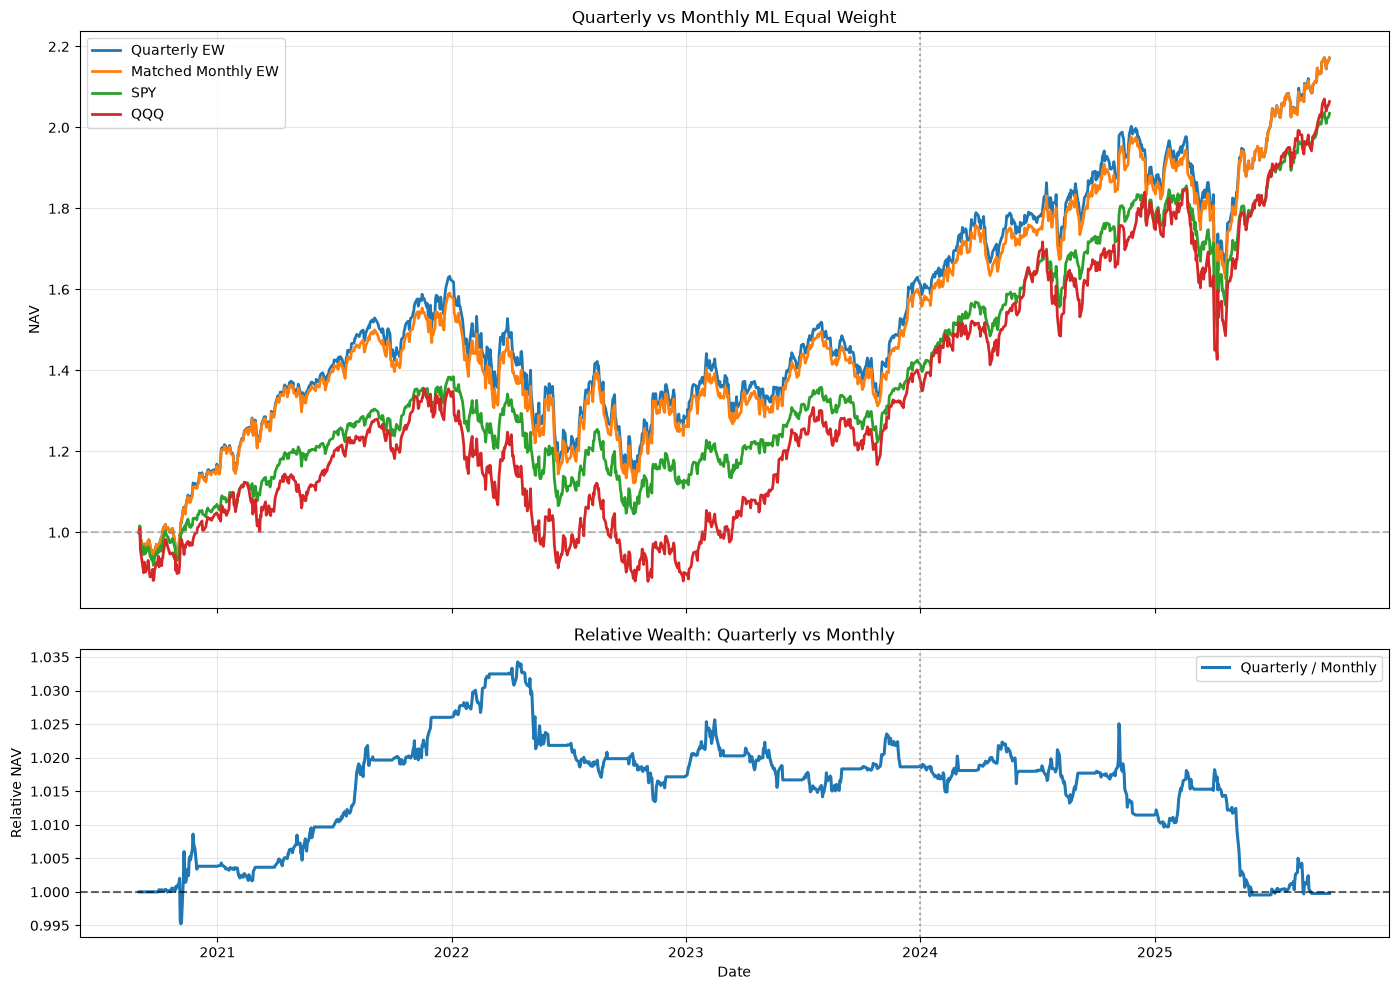


All quarterly backtest checks passed.

Cell 27 completed.


In [28]:

# ============================================================
# Cell 27 - Quarterly vs Monthly Equal Weight
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Quarterly rebalance schedule
# ------------------------------------------------------------

quarterly_weights = (
    matched_monthly_ew_weights
    .iloc[::3]
    .copy()
)

assert np.allclose(
    quarterly_weights.sum(axis=1), 1.0
)

assert quarterly_weights.index[0] == (
    matched_monthly_ew_weights.index[0]
)

assert quarterly_weights.index[-1] == (
    matched_monthly_ew_weights.index[-1]
)

print("=" * 72)
print("QUARTERLY VS MONTHLY EQUAL WEIGHT")
print("=" * 72)

print("\nMonthly Rebalances:",
      len(matched_monthly_ew_weights))

print("Quarterly Rebalances:",
      len(quarterly_weights))

print("\nQuarterly Rebalance Dates:")
print(
    quarterly_weights.index
    .strftime("%Y-%m-%d")
    .tolist()
)

# ------------------------------------------------------------
# 2. Validate uninterrupted returns while holding stocks
# ------------------------------------------------------------

missing_records = []

for i, start_date in enumerate(quarterly_weights.index):

    if i + 1 < len(quarterly_weights):
        end_date = quarterly_weights.index[i + 1]
    else:
        end_date = monthly_comparison.index.max()

    held_tickers = quarterly_weights.columns[
        quarterly_weights.loc[start_date] > 0
    ]

    held_dates = daily_returns.index[
        (daily_returns.index > start_date)
        & (daily_returns.index <= end_date)
    ]

    holding_returns = daily_returns.reindex(
        index=held_dates,
        columns=held_tickers
    )

    arr = holding_returns.to_numpy(dtype=float)

    invalid = (
        ~np.isfinite(arr)
        | (arr <= -1.0)
    )

    for row_idx, col_idx in np.argwhere(invalid):

        missing_records.append({
            "rebalance_date": start_date,
            "missing_date": held_dates[row_idx],
            "ticker": held_tickers[col_idx]
        })

quarterly_missing = pd.DataFrame(
    missing_records,
    columns=[
        "rebalance_date",
        "missing_date",
        "ticker"
    ]
)

print("\nInvalid Held-Stock Daily Returns:",
      len(quarterly_missing))

# ------------------------------------------------------------
# 3. Only backtest if the holding history is complete
# ------------------------------------------------------------

if len(quarterly_missing) > 0:

    print("\nQuarterly holding validation failed.")
    print("First 15 problematic records:")

    print(
        quarterly_missing.head(15)
        .to_string(index=False)
    )

    print(
        "\nBacktest skipped. Missing returns were "
        "not replaced by zero."
    )

else:

    print("\nHolding history validation passed.")

    # --------------------------------------------------------
    # 4. Run quarterly buy-and-hold backtest
    # --------------------------------------------------------

    quarterly_result = run_monthly_backtest(
        target_weights=quarterly_weights,
        daily_returns=daily_returns,
        fee_rate=FEE_RATE
    )

    quarterly_comparison = monthly_comparison[
        ["Matched Monthly EW", "SPY", "QQQ"]
    ].copy()

    assert quarterly_result.index.equals(
        quarterly_comparison.index
    )

    quarterly_comparison["Quarterly EW"] = (
        quarterly_result["nav"]
    )

    strategy_order = [
        "Quarterly EW",
        "Matched Monthly EW",
        "SPY",
        "QQQ"
    ]

    quarterly_comparison = quarterly_comparison[
        strategy_order
    ]

    # --------------------------------------------------------
    # 5. Performance metrics
    # --------------------------------------------------------

    quarterly_metrics = pd.DataFrame({
        name: monthly_performance_metrics(
            quarterly_comparison[name]
        )
        for name in strategy_order
    }).T

    quarterly_metrics["Total Turnover"] = [
        quarterly_result["turnover"].sum(),
        matched_ew_result["turnover"].sum(),
        np.nan,
        np.nan
    ]

    quarterly_metrics["Total Cost"] = [
        quarterly_result["cost"].sum(),
        matched_ew_result["cost"].sum(),
        np.nan,
        np.nan
    ]

    daily_comparison_returns = (
        quarterly_comparison
        .pct_change(fill_method=None)
        .iloc[1:]
    )

    spy_ret = daily_comparison_returns["SPY"]

    quarterly_metrics["Beta vs SPY"] = [
        daily_comparison_returns[name].cov(spy_ret)
        / spy_ret.var()
        for name in strategy_order
    ]

    print("\nPerformance Comparison:")
    print(
        quarterly_metrics.round(4)
        .to_string()
    )

    # --------------------------------------------------------
    # 6. Relative performance
    # --------------------------------------------------------

    final_nav = quarterly_comparison.iloc[-1]

    print("\nFinal NAV:")
    print(final_nav.round(6).to_string())

    print("\nRelative Performance:")

    for benchmark in [
        "Matched Monthly EW", "SPY", "QQQ"
    ]:

        difference = (
            final_nav["Quarterly EW"]
            / final_nav[benchmark] - 1.0
        ) * 100

        print(
            f"Quarterly EW vs {benchmark}: "
            f"{difference:+.3f}%"
        )

    # --------------------------------------------------------
    # 7. Annual and subperiod returns
    # --------------------------------------------------------

    eval_returns = pd.DataFrame(
        index=quarterly_comparison.index
    )

    eval_returns["Quarterly EW"] = (
        quarterly_result["net_ret"]
    )

    eval_returns["Matched Monthly EW"] = (
        matched_ew_result["net_ret"]
    )

    for ticker in ["SPY", "QQQ"]:
        eval_returns[ticker] = (
            quarterly_comparison[ticker]
            .pct_change(fill_method=None)
            .fillna(0.0)
        )

    annual = (
        (1.0 + eval_returns)
        .groupby(eval_returns.index.year)
        .prod() - 1.0
    ) * 100

    annual["Quarterly - Monthly (pp)"] = (
        annual["Quarterly EW"]
        - annual["Matched Monthly EW"]
    )

    print("\nAnnual Returns (%):")
    print(annual.round(3).to_string())

    periods = {
        "Development 2020-2023": (
            "2020-09-01",
            "2023-12-29"
        ),
        "Evaluation 2024-2025": (
            "2024-01-01",
            "2025-09-30"
        )
    }

    print("\nSubperiod Performance:")

    for period_name, (start, end) in periods.items():

        period_nav = (
            1.0 + eval_returns.loc[start:end]
        ).prod()

        print(f"\n{period_name}")
        print(period_nav.round(4).to_string())

        relative = (
            period_nav["Quarterly EW"]
            / period_nav["Matched Monthly EW"]
            - 1.0
        ) * 100

        print(
            "Quarterly vs Monthly EW:",
            f"{relative:+.3f}%"
        )

    # --------------------------------------------------------
    # 8. Plot NAV and relative wealth
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        2, 1,
        figsize=(14, 10),
        sharex=True,
        gridspec_kw={"height_ratios": [2, 1]}
    )

    for name in strategy_order:
        axes[0].plot(
            quarterly_comparison.index,
            quarterly_comparison[name],
            label=name,
            linewidth=2
        )

    axes[0].axhline(
        1.0,
        color="gray",
        linestyle="--",
        alpha=0.5
    )

    axes[0].set_title(
        "Quarterly vs Monthly ML Equal Weight"
    )

    axes[0].set_ylabel("NAV")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    relative_nav = (
        quarterly_comparison["Quarterly EW"]
        / quarterly_comparison["Matched Monthly EW"]
    )

    axes[1].plot(
        relative_nav.index,
        relative_nav,
        linewidth=2.2,
        label="Quarterly / Monthly"
    )

    axes[1].axhline(
        1.0,
        color="black",
        linestyle="--",
        alpha=0.6
    )

    axes[1].set_title(
        "Relative Wealth: Quarterly vs Monthly"
    )

    axes[1].set_ylabel("Relative NAV")
    axes[1].set_xlabel("Date")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    for ax in axes:
        ax.axvline(
            pd.Timestamp("2024-01-01"),
            color="gray",
            linestyle=":",
            alpha=0.7
        )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 9. Save and validate
    # --------------------------------------------------------

    assert quarterly_comparison.notna().all().all()

    assert np.isfinite(
        quarterly_comparison.to_numpy()
    ).all()

    quarterly_weights.to_csv(
        "./results/quarterly_ew_weights.csv"
    )

    quarterly_comparison.to_csv(
        "./results/quarterly_ew_nav.csv"
    )

    quarterly_metrics.to_csv(
        "./results/quarterly_ew_metrics.csv"
    )

    annual.to_csv(
        "./results/quarterly_ew_annual_returns.csv"
    )

    print("\nAll quarterly backtest checks passed.")

print("\nCell 27 completed.")


TRANSACTION COST SENSITIVITY ANALYSIS

Backtester Consistency Check:
Monthly reconstructed: 2.17184284
Monthly existing:      2.17184284
Quarterly reconstructed: 2.17134171
Quarterly existing:      2.17134171
Cost reconstruction checks passed.

Fee Sensitivity Results:
 Fee (bps)  Monthly NAV  Quarterly NAV  Quarterly vs Monthly (%)    Winner
         0      2.22047        2.20633                  -0.63681   Monthly
         2      2.21066        2.19929                  -0.51435   Monthly
         5      2.19603        2.18877                  -0.33040   Monthly
         8      2.18148        2.17830                  -0.14611   Monthly
        10      2.17184        2.17134                  -0.02307   Monthly
        11      2.16704        2.16787                   0.03850 Quarterly
        12      2.16224        2.16441                   0.10011 Quarterly
        15      2.14792        2.15405                   0.28517 Quarterly
        20      2.12426        2.13688                 

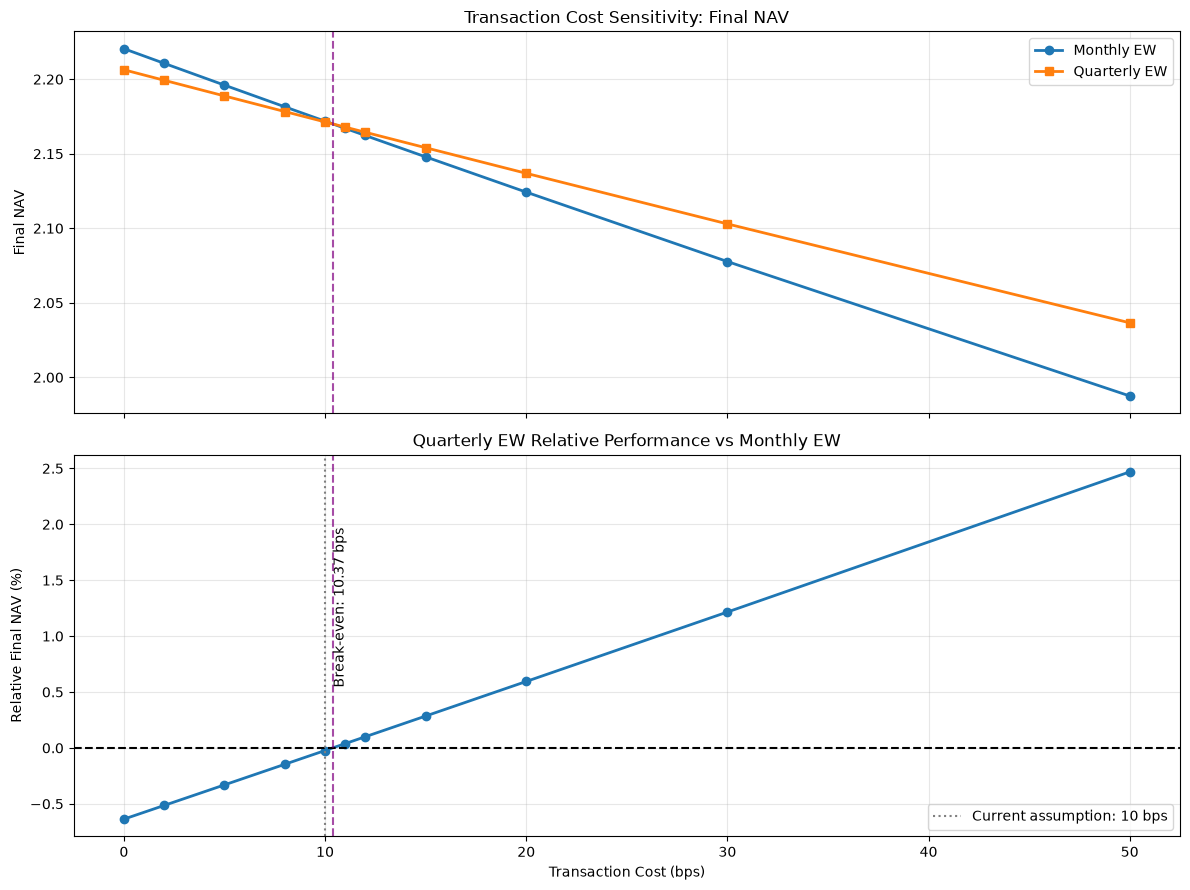


Cell 28 completed successfully.


In [29]:

# ============================================================
# Cell 28 - Transaction Cost Sensitivity Analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ------------------------------------------------------------
# 1. Re-run both strategies with zero transaction cost
# ------------------------------------------------------------

monthly_gross = run_monthly_backtest(
    target_weights=matched_monthly_ew_weights,
    daily_returns=daily_returns,
    fee_rate=0.0
)

quarterly_gross = run_monthly_backtest(
    target_weights=quarterly_weights,
    daily_returns=daily_returns,
    fee_rate=0.0
)

# ------------------------------------------------------------
# 2. Calculate NAV under alternative transaction costs
# ------------------------------------------------------------

# Trading weights and turnover are unchanged when only the
# transaction-cost parameter changes.
#
# This uses the same multiplicative fee model as the existing
# monthly buy-and-hold backtester.

def nav_with_fee(gross_result, fee_rate):

    turnover = gross_result["turnover"].to_numpy(
        dtype=float
    )

    gross_return = gross_result["net_ret"].to_numpy(
        dtype=float
    )

    fee_factor = 1.0 - fee_rate * turnover

    if np.any(fee_factor <= 0):
        raise ValueError("Invalid transaction-cost factor")

    return float(
        np.prod((1.0 + gross_return) * fee_factor)
    )

# ------------------------------------------------------------
# 3. Verify reconstruction against existing 10 bps results
# ------------------------------------------------------------

monthly_reconstructed = nav_with_fee(
    monthly_gross, FEE_RATE
)

quarterly_reconstructed = nav_with_fee(
    quarterly_gross, FEE_RATE
)

monthly_existing = matched_ew_result["nav"].iloc[-1]
quarterly_existing = quarterly_result["nav"].iloc[-1]

print("=" * 75)
print("TRANSACTION COST SENSITIVITY ANALYSIS")
print("=" * 75)

print("\nBacktester Consistency Check:")

print(
    f"Monthly reconstructed: {monthly_reconstructed:.8f}"
)
print(
    f"Monthly existing:      {monthly_existing:.8f}"
)

print(
    f"Quarterly reconstructed: {quarterly_reconstructed:.8f}"
)
print(
    f"Quarterly existing:      {quarterly_existing:.8f}"
)

assert np.isclose(
    monthly_reconstructed,
    monthly_existing,
    atol=1e-8
)

assert np.isclose(
    quarterly_reconstructed,
    quarterly_existing,
    atol=1e-8
)

print("Cost reconstruction checks passed.")

# ------------------------------------------------------------
# 4. Test alternative transaction costs
# ------------------------------------------------------------

fee_bps_grid = [
    0, 2, 5, 8, 10, 11, 12, 15, 20, 30, 50
]

fee_records = []

for bps in fee_bps_grid:

    fee = bps / 10000.0

    monthly_nav = nav_with_fee(
        monthly_gross, fee
    )

    quarterly_nav = nav_with_fee(
        quarterly_gross, fee
    )

    fee_records.append({
        "Fee (bps)": bps,
        "Monthly NAV": monthly_nav,
        "Quarterly NAV": quarterly_nav,
        "Quarterly vs Monthly (%)": (
            quarterly_nav / monthly_nav - 1
        ) * 100,
        "Winner": (
            "Quarterly"
            if quarterly_nav > monthly_nav
            else "Monthly"
            if monthly_nav > quarterly_nav
            else "Tie"
        )
    })

fee_sensitivity = pd.DataFrame(fee_records)

print("\nFee Sensitivity Results:")
print(
    fee_sensitivity.round(5)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 5. Find the transaction-cost break-even point
# ------------------------------------------------------------

def log_nav_difference(fee):

    monthly = nav_with_fee(
        monthly_gross, fee
    )

    quarterly = nav_with_fee(
        quarterly_gross, fee
    )

    return np.log(quarterly) - np.log(monthly)

low_fee = 0.0
high_fee = 50 / 10000.0

gap_low = log_nav_difference(low_fee)
gap_high = log_nav_difference(high_fee)

print("\nBreak-Even Transaction Cost:")

if np.isclose(gap_low, 0, atol=1e-12):
    break_even_bps = 0.0

elif gap_low * gap_high < 0:

    break_even_fee = brentq(
        log_nav_difference,
        low_fee,
        high_fee,
        xtol=1e-12
    )

    break_even_bps = break_even_fee * 10000

else:
    break_even_bps = np.nan

if np.isfinite(break_even_bps):

    print(
        f"Monthly and Quarterly EW break even "
        f"at approximately {break_even_bps:.4f} bps."
    )

else:

    print(
        "No break-even point found between 0 and 50 bps."
    )

# ------------------------------------------------------------
# 6. Cost savings
# ------------------------------------------------------------

monthly_turnover = monthly_gross["turnover"].sum()
quarterly_turnover = quarterly_gross["turnover"].sum()

print("\nTurnover Comparison:")

print(f"Monthly turnover:   {monthly_turnover:.4f}")
print(f"Quarterly turnover: {quarterly_turnover:.4f}")

print(
    "Turnover reduction:",
    f"{(1 - quarterly_turnover / monthly_turnover) * 100:.3f}%"
)

# ------------------------------------------------------------
# 7. Plot transaction-cost sensitivity
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 9),
    sharex=True
)

axes[0].plot(
    fee_sensitivity["Fee (bps)"],
    fee_sensitivity["Monthly NAV"],
    marker="o",
    label="Monthly EW",
    linewidth=2
)

axes[0].plot(
    fee_sensitivity["Fee (bps)"],
    fee_sensitivity["Quarterly NAV"],
    marker="s",
    label="Quarterly EW",
    linewidth=2
)

axes[0].set_title(
    "Transaction Cost Sensitivity: Final NAV"
)

axes[0].set_ylabel("Final NAV")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    fee_sensitivity["Fee (bps)"],
    fee_sensitivity["Quarterly vs Monthly (%)"],
    marker="o",
    linewidth=2
)

axes[1].axhline(
    0.0,
    color="black",
    linestyle="--"
)

axes[1].axvline(
    10.0,
    color="gray",
    linestyle=":",
    label="Current assumption: 10 bps"
)

if np.isfinite(break_even_bps):

    for ax in axes:
        ax.axvline(
            break_even_bps,
            color="purple",
            linestyle="--",
            alpha=0.7
        )

    axes[1].text(
        break_even_bps,
        axes[1].get_ylim()[1] * 0.75,
        f"Break-even: {break_even_bps:.2f} bps",
        rotation=90,
        va="top"
    )

axes[1].set_title(
    "Quarterly EW Relative Performance vs Monthly EW"
)

axes[1].set_xlabel("Transaction Cost (bps)")
axes[1].set_ylabel("Relative Final NAV (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Save
# ------------------------------------------------------------

fee_sensitivity.to_csv(
    "./results/rebalance_fee_sensitivity.csv",
    index=False
)

print("\nCell 28 completed successfully.")


MONTHLY EW - SECTOR ATTRIBUTION

Reconciliation Checks:
Maximum net-return reconstruction error: 0.0000000000
Maximum NAV reconstruction error: 0.0000000000
Maximum sector dollar PnL reconciliation error: 0.0000000000
All reconciliation checks passed.

---------------------------------------------------------------------------
Full 2020-2025
---------------------------------------------------------------------------
Portfolio Return: +117.184%
SPY Return:       +103.473%
Difference:       +13.711 pp

Sector Attribution:
                        NAV Contribution (%)  SPY-Relative Daily Spread (pp sum)  Average Exposure (%)
Information Technology                56.413                              10.741                43.761
Financials                            20.507                               2.762                15.883
Consumer Discretionary                 3.503                               1.531                 1.671
Utilities                              2.488                  

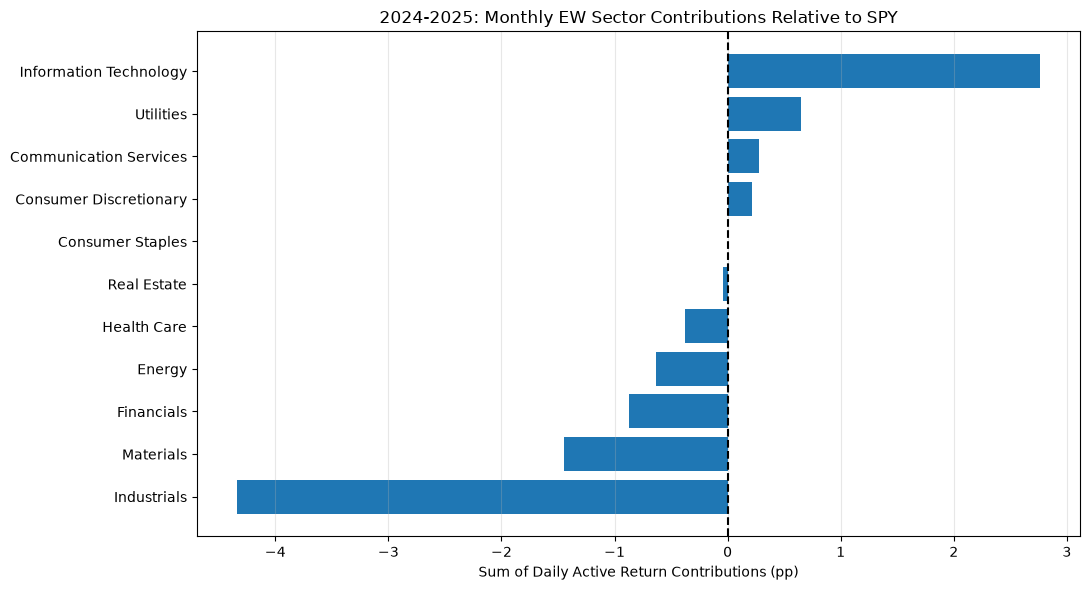


Cell 29 completed successfully.


In [30]:

# ============================================================
# Cell 29 - Monthly EW Sector Attribution
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

GICS_NAMES = {
    10: "Energy",
    15: "Materials",
    20: "Industrials",
    25: "Consumer Discretionary",
    30: "Consumer Staples",
    35: "Health Care",
    40: "Financials",
    45: "Information Technology",
    50: "Communication Services",
    55: "Utilities",
    60: "Real Estate"
}

sectors_all = list(GICS_NAMES.keys())

# ------------------------------------------------------------
# 1. Point-in-time sector mapping at each rebalance
# ------------------------------------------------------------

rebalance_sector_maps = {}

for trade_date in monthly_rebalance_dates:

    inputs = mvo_inputs[trade_date]
    tickers = pd.Index(inputs["tickers"])
    signal_date = inputs["signal_date"]

    history = mvo_sector_data.loc[
        (mvo_sector_data["reportdate"] <= signal_date)
        & mvo_sector_data["tic"].isin(tickers)
    ]

    mapping = (
        history
        .sort_values(["tic", "reportdate"])
        .drop_duplicates("tic", keep="last")
        .set_index("tic")["gsector"]
        .reindex(tickers)
    )

    assert mapping.notna().all()

    rebalance_sector_maps[trade_date] = (
        mapping.astype(int)
    )

# ------------------------------------------------------------
# 2. Reconstruct daily buy-and-hold portfolio exposures
# ------------------------------------------------------------

dates = monthly_comparison.index
all_tickers = matched_monthly_ew_weights.columns

held_weights = pd.Series(
    0.0, index=all_tickers
)

held_sectors = pd.Series(dtype=int)

sector_dollar_records = []
sector_active_records = []
sector_weight_records = []
audit_records = []

prev_nav = 1.0

spy_daily = (
    monthly_comparison["SPY"]
    .pct_change(fill_method=None)
    .fillna(0.0)
)

for date in dates:

    active = held_weights[held_weights > 0]

    sector_gross = pd.Series(
        0.0, index=sectors_all
    )

    sector_weights = pd.Series(
        0.0, index=sectors_all
    )

    # --------------------------------------------------------
    # Today's return belongs to yesterday's closing holdings
    # --------------------------------------------------------

    if len(active) > 0:

        returns_today = daily_returns.loc[
            date, active.index
        ].astype(float)

        if not np.isfinite(returns_today).all():
            raise ValueError(
                f"Missing held-stock return on {date}"
            )

        sector_ids = held_sectors.reindex(
            active.index
        )

        if sector_ids.isna().any():
            raise ValueError(
                f"Missing held-stock sector on {date}"
            )

        stock_contributions = (
            active * returns_today
        )

        grouped_gross = (
            stock_contributions
            .groupby(sector_ids)
            .sum()
        )

        grouped_weights = (
            active
            .groupby(sector_ids)
            .sum()
        )

        sector_gross.loc[
            grouped_gross.index
        ] = grouped_gross.values

        sector_weights.loc[
            grouped_weights.index
        ] = grouped_weights.values

    gross_return = sector_gross.sum()

    actual_net_return = float(
        matched_ew_result.loc[date, "net_ret"]
    )

    actual_turnover = float(
        matched_ew_result.loc[date, "turnover"]
    )

    # Verify same fee convention as the original backtester
    expected_net_return = (
        (1.0 + gross_return)
        * (1.0 - FEE_RATE * actual_turnover)
        - 1.0
    )

    net_error = abs(
        expected_net_return - actual_net_return
    )

    current_nav = float(
        matched_ew_result.loc[date, "nav"]
    )

    nav_error = abs(
        prev_nav * (1.0 + actual_net_return)
        - current_nav
    )

    # --------------------------------------------------------
    # Gross sector contribution, measured in NAV dollars
    # --------------------------------------------------------

    sector_dollars = (
        sector_gross * prev_nav
    )

    # Actual transaction-cost drag, including
    # the multiplicative interaction with today's gross return
    cost_dollar = (
        prev_nav
        * (actual_net_return - gross_return)
    )

    sector_dollars.loc["Transaction Costs"] = (
        cost_dollar
    )

    # Sector-level daily excess-return contribution vs SPY
    sector_active = (
        sector_gross
        - sector_weights * float(spy_daily.loc[date])
    )

    sector_active.loc["Transaction Costs"] = (
        actual_net_return - gross_return
    )

    sector_dollar_records.append(
        sector_dollars.rename(date)
    )

    sector_active_records.append(
        sector_active.rename(date)
    )

    sector_weight_records.append(
        sector_weights.rename(date)
    )

    audit_records.append({
        "date": date,
        "gross_return": gross_return,
        "net_return": actual_net_return,
        "net_reconstruction_error": net_error,
        "nav_reconstruction_error": nav_error,
        "sector_dollar_sum": sector_dollars.sum(),
        "actual_nav_change": (
            current_nav - prev_nav
        )
    })

    # --------------------------------------------------------
    # Drift weights after today's price movements
    # --------------------------------------------------------

    if len(active) > 0:

        drifted = (
            active * (1.0 + returns_today)
            / (1.0 + gross_return)
        )

        held_weights = pd.Series(
            0.0, index=all_tickers
        )

        held_weights.loc[
            drifted.index
        ] = drifted.values

    # Rebalance at today's close:
    # New target weights earn returns starting tomorrow.
    if date in rebalance_sector_maps:

        held_weights = (
            matched_monthly_ew_weights.loc[date]
            .copy()
        )

        held_sectors = rebalance_sector_maps[date]

    prev_nav = current_nav

# ------------------------------------------------------------
# 3. Assemble daily attribution
# ------------------------------------------------------------

sector_dollar_pnl = pd.DataFrame(
    sector_dollar_records
)

sector_active_daily = pd.DataFrame(
    sector_active_records
)

sector_exposure_daily = pd.DataFrame(
    sector_weight_records
)

attribution_audit = (
    pd.DataFrame(audit_records)
    .set_index("date")
)

# ------------------------------------------------------------
# 4. Reconciliation checks
# ------------------------------------------------------------

print("=" * 75)
print("MONTHLY EW - SECTOR ATTRIBUTION")
print("=" * 75)

print("\nReconciliation Checks:")

print(
    "Maximum net-return reconstruction error:",
    f"{attribution_audit['net_reconstruction_error'].max():.10f}"
)

print(
    "Maximum NAV reconstruction error:",
    f"{attribution_audit['nav_reconstruction_error'].max():.10f}"
)

pnl_error = (
    attribution_audit["sector_dollar_sum"]
    - attribution_audit["actual_nav_change"]
).abs().max()

print(
    "Maximum sector dollar PnL reconciliation error:",
    f"{pnl_error:.10f}"
)

assert (
    attribution_audit[
        "net_reconstruction_error"
    ].max() < 1e-7
), "Daily gross/net return reconstruction failed."

assert (
    attribution_audit[
        "nav_reconstruction_error"
    ].max() < 1e-7
), "Daily NAV reconstruction failed."

assert pnl_error < 1e-7, (
    "Sector PnL does not reconcile with NAV."
)

print("All reconciliation checks passed.")

# ------------------------------------------------------------
# 5. Full sample and subperiod attribution
# ------------------------------------------------------------

periods = {
    "Full 2020-2025": (
        "2020-09-01", "2025-09-30"
    ),
    "Development 2020-2023": (
        "2020-09-01", "2023-12-29"
    ),
    "Evaluation 2024-2025": (
        "2024-01-01", "2025-09-30"
    )
}

sector_attribution_tables = {}
attribution_summary = []

for period_name, (start, end) in periods.items():

    period_dates = dates[
        (dates >= pd.Timestamp(start))
        & (dates <= pd.Timestamp(end))
    ]

    first_pos = dates.get_loc(period_dates[0])

    starting_nav = (
        1.0
        if first_pos == 0
        else matched_ew_result["nav"].iloc[
            first_pos - 1
        ]
    )

    starting_spy = (
        1.0
        if first_pos == 0
        else monthly_comparison["SPY"].iloc[
            first_pos - 1
        ]
    )

    ending_nav = matched_ew_result[
        "nav"
    ].loc[period_dates[-1]]

    ending_spy = monthly_comparison[
        "SPY"
    ].loc[period_dates[-1]]

    # Exact contributions to realized portfolio NAV
    contribution_pct = (
        sector_dollar_pnl.loc[
            period_dates
        ].sum() / starting_nav * 100
    )

    # Arithmetic sum of daily market-relative contributions
    active_spread_pp = (
        sector_active_daily.loc[
            period_dates
        ].sum() * 100
    )

    mean_exposure_pct = (
        sector_exposure_daily.loc[
            period_dates
        ].mean() * 100
    )

    table = pd.DataFrame({
        "NAV Contribution (%)": contribution_pct,
        "SPY-Relative Daily Spread (pp sum)": (
            active_spread_pp
        ),
        "Average Exposure (%)": (
            mean_exposure_pct.reindex(
                contribution_pct.index
            ).fillna(0.0)
        )
    })

    table.index = [
        (
            GICS_NAMES.get(int(x), f"Sector {x}")
            if x != "Transaction Costs"
            else "Transaction Costs"
        )
        for x in table.index
    ]

    table = table.sort_values(
        "SPY-Relative Daily Spread (pp sum)",
        ascending=False
    )

    sector_attribution_tables[period_name] = table

    portfolio_return = (
        ending_nav / starting_nav - 1
    ) * 100

    spy_return = (
        ending_spy / starting_spy - 1
    ) * 100

    assert np.isclose(
        table["NAV Contribution (%)"].sum(),
        portfolio_return,
        atol=1e-7
    )

    attribution_summary.append({
        "Period": period_name,
        "Portfolio Return (%)": portfolio_return,
        "SPY Return (%)": spy_return,
        "Portfolio - SPY (pp)": (
            portfolio_return - spy_return
        )
    })

    print("\n" + "-" * 75)
    print(period_name)
    print("-" * 75)

    print(
        f"Portfolio Return: {portfolio_return:+.3f}%"
    )
    print(
        f"SPY Return:       {spy_return:+.3f}%"
    )
    print(
        f"Difference:       "
        f"{portfolio_return - spy_return:+.3f} pp"
    )

    print("\nSector Attribution:")
    print(
        table.round(3).to_string()
    )

# ------------------------------------------------------------
# 6. Period comparison
# ------------------------------------------------------------

attribution_summary_df = pd.DataFrame(
    attribution_summary
).set_index("Period")

print("\n" + "=" * 75)
print("PERIOD SUMMARY")
print("=" * 75)

print(
    attribution_summary_df
    .round(3).to_string()
)

# ------------------------------------------------------------
# 7. Plot 2024-2025 SPY-relative sector contributions
# ------------------------------------------------------------

evaluation_table = sector_attribution_tables[
    "Evaluation 2024-2025"
].drop(index="Transaction Costs")

plot_values = (
    evaluation_table[
        "SPY-Relative Daily Spread (pp sum)"
    ].sort_values()
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    plot_values.index,
    plot_values.values
)

ax.axvline(
    0.0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "2024-2025: Monthly EW Sector Contributions "
    "Relative to SPY"
)

ax.set_xlabel(
    "Sum of Daily Active Return Contributions (pp)"
)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Save diagnostics and attribution
# ------------------------------------------------------------

sector_dollar_pnl.to_csv(
    "./results/sector_daily_dollar_pnl.csv"
)

sector_active_daily.to_csv(
    "./results/sector_daily_active_contributions.csv"
)

attribution_audit.to_csv(
    "./results/sector_attribution_audit.csv"
)

attribution_summary_df.to_csv(
    "./results/sector_attribution_period_summary.csv"
)

for period_name, table in sector_attribution_tables.items():

    filename = (
        period_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    table.to_csv(
        f"./results/sector_attribution_{filename}.csv"
    )

print("\nCell 29 completed successfully.")


STOCK-LEVEL ATTRIBUTION - 2024 TO 2025

Evaluation Trading Days: 438
Maximum Sector Reconciliation Error: 0.000000000000
Stock-level attribution reconciles with Cell 29.

INDUSTRIALS - STOCK ATTRIBUTION

Unique Industrial Stocks Held:
73

Total Industrials Active Contribution (pp):
-4.3396

Top 12 Industrial Detractors:
 tic  held_days  avg_portfolio_weight_pct  active_contribution_pp  weighted_avg_excess_bps
 GPN        291                    0.5352                 -0.4498                 -19.1886
BLDR        143                    0.2623                 -0.3883                 -33.7964
 UPS        227                    0.4244                 -0.3678                 -19.7839
 UAL        147                    0.2709                 -0.3590                 -30.2576
 SWK        418                    0.7873                 -0.3587                 -10.4024
 AOS        374                    0.7032                 -0.3131                 -10.1653
CARR        309                    0.5835

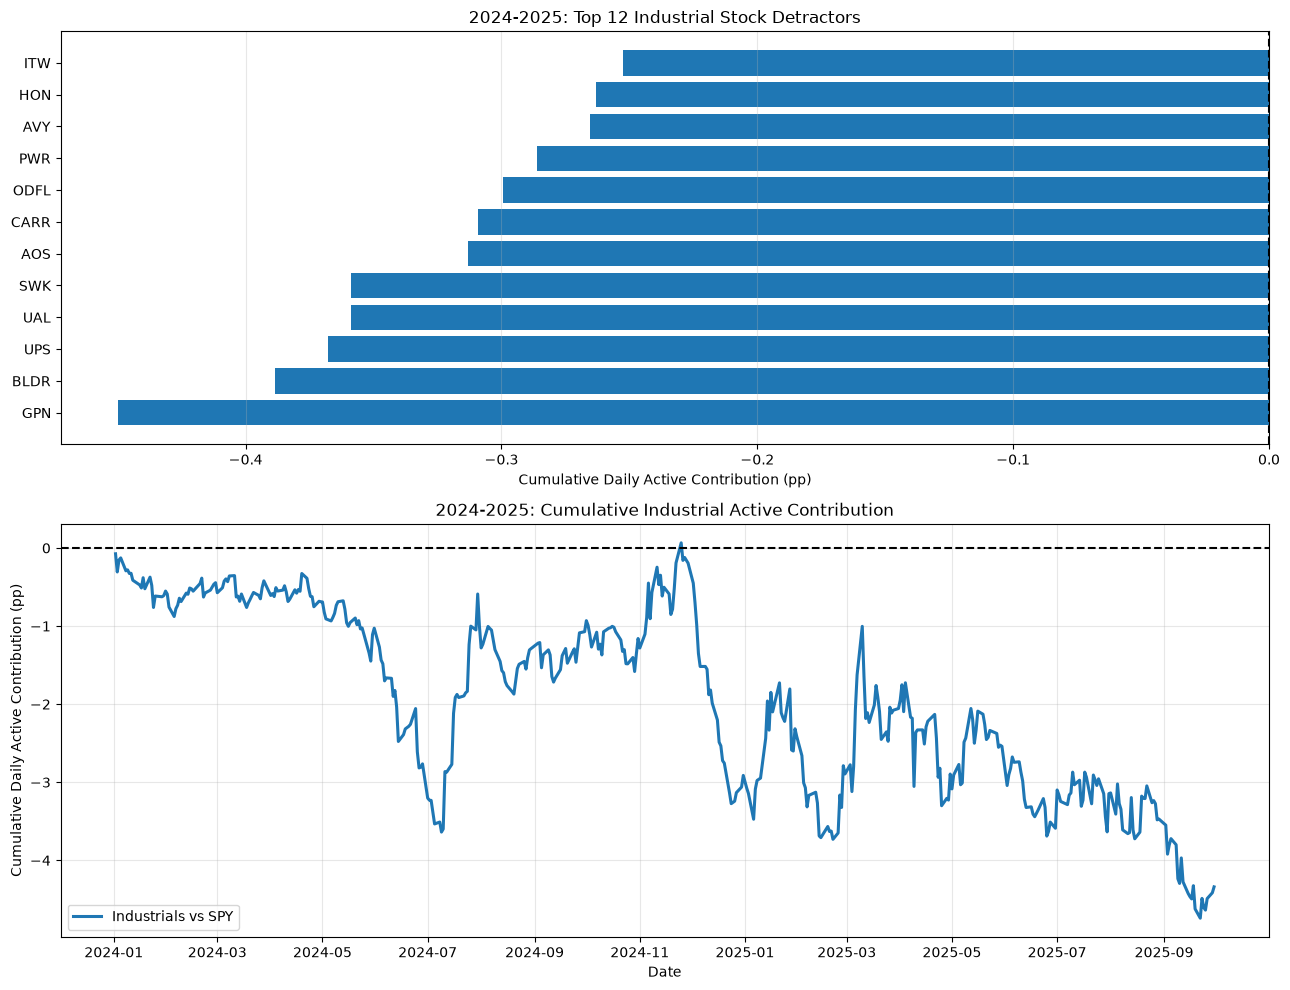


Cell 30 completed successfully.


In [31]:

# ============================================================
# Cell 30 - Stock-Level Attribution: Industrials Deep Dive
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EVAL_START = pd.Timestamp("2024-01-01")
EVAL_END = pd.Timestamp("2025-09-30")

# ------------------------------------------------------------
# 1. Reconstruct point-in-time holdings
# ------------------------------------------------------------

dates = monthly_comparison.index
all_tickers = matched_monthly_ew_weights.columns

held_weights = pd.Series(0.0, index=all_tickers)
held_sectors = pd.Series(dtype=int)

spy_ret = (
    monthly_comparison["SPY"]
    .pct_change(fill_method=None)
    .fillna(0.0)
)

stock_records = []

for date in dates:

    active = held_weights[held_weights > 0]

    if len(active) > 0:

        stock_ret = daily_returns.loc[
            date, active.index
        ].astype(float)

        if not np.isfinite(stock_ret).all():
            raise ValueError(
                f"Invalid held-stock returns: {date}"
            )

        sectors = held_sectors.reindex(active.index)

        if sectors.isna().any():
            raise ValueError(
                f"Missing sector classification: {date}"
            )

        market_ret = float(spy_ret.loc[date])

        # ----------------------------------------------------
        # Record evaluation-period stock contributions
        # ----------------------------------------------------

        if EVAL_START <= date <= EVAL_END:

            daily_frame = pd.DataFrame({
                "date": date,
                "tic": active.index,
                "sector": sectors.to_numpy(),
                "weight": active.to_numpy(),
                "stock_return": stock_ret.to_numpy()
            })

            daily_frame["spy_return"] = market_ret

            daily_frame["gross_contribution"] = (
                daily_frame["weight"]
                * daily_frame["stock_return"]
            )

            daily_frame["active_contribution"] = (
                daily_frame["weight"]
                * (
                    daily_frame["stock_return"]
                    - daily_frame["spy_return"]
                )
            )

            stock_records.append(daily_frame)

        # ----------------------------------------------------
        # Drift current holdings after today's price returns
        # ----------------------------------------------------

        gross_return = float(
            (active * stock_ret).sum()
        )

        drifted = (
            active * (1.0 + stock_ret)
            / (1.0 + gross_return)
        )

        held_weights = pd.Series(
            0.0, index=all_tickers
        )

        held_weights.loc[drifted.index] = drifted

    # Rebalance at today's close
    if date in rebalance_sector_maps:

        held_weights = (
            matched_monthly_ew_weights.loc[date]
            .copy()
        )

        held_sectors = rebalance_sector_maps[date]

# ------------------------------------------------------------
# 2. Combine stock-level daily records
# ------------------------------------------------------------

stock_attribution_daily = pd.concat(
    stock_records,
    ignore_index=True
)

stock_attribution_daily["sector"] = (
    stock_attribution_daily["sector"].astype(int)
)

eval_dates = dates[
    (dates >= EVAL_START)
    & (dates <= EVAL_END)
]

n_eval_days = len(eval_dates)

# ------------------------------------------------------------
# 3. Reconcile with Cell 29 sector attribution
# ------------------------------------------------------------

stock_sector_active = (
    stock_attribution_daily
    .groupby(["date", "sector"])[
        "active_contribution"
    ]
    .sum()
    .unstack(fill_value=0.0)
    .reindex(
        index=eval_dates,
        columns=sectors_all,
        fill_value=0.0
    )
)

reference_sector_active = (
    sector_active_daily
    .reindex(
        index=eval_dates,
        columns=sectors_all
    )
    .fillna(0.0)
)

reconciliation_error = (
    stock_sector_active
    - reference_sector_active
).abs().to_numpy().max()

print("=" * 75)
print("STOCK-LEVEL ATTRIBUTION - 2024 TO 2025")
print("=" * 75)

print("\nEvaluation Trading Days:", n_eval_days)

print(
    "Maximum Sector Reconciliation Error:",
    f"{reconciliation_error:.12f}"
)

assert reconciliation_error < 1e-8

print("Stock-level attribution reconciles with Cell 29.")

# ------------------------------------------------------------
# 4. Aggregate contributions by stock
# ------------------------------------------------------------

stock_summary = (
    stock_attribution_daily
    .groupby(["sector", "tic"])
    .agg(
        held_days=("date", "nunique"),
        weight_days=("weight", "sum"),
        gross_contribution=("gross_contribution", "sum"),
        active_contribution=("active_contribution", "sum")
    )
    .reset_index()
)

stock_summary["avg_portfolio_weight_pct"] = (
    stock_summary["weight_days"]
    / n_eval_days * 100
)

stock_summary["gross_contribution_pp"] = (
    stock_summary["gross_contribution"] * 100
)

stock_summary["active_contribution_pp"] = (
    stock_summary["active_contribution"] * 100
)

# Weight-weighted stock excess return on holding days
stock_summary["weighted_avg_excess_bps"] = (
    stock_summary["active_contribution"]
    / stock_summary["weight_days"]
    * 10000
)

stock_summary["sector_name"] = (
    stock_summary["sector"]
    .map(GICS_NAMES)
)

# ------------------------------------------------------------
# 5. Industrials contribution ranking
# ------------------------------------------------------------

industrials = (
    stock_summary.loc[
        stock_summary["sector"] == 20
    ]
    .sort_values("active_contribution_pp")
    .copy()
)

print("\n" + "=" * 75)
print("INDUSTRIALS - STOCK ATTRIBUTION")
print("=" * 75)

print("\nUnique Industrial Stocks Held:")
print(len(industrials))

print("\nTotal Industrials Active Contribution (pp):")
print(
    round(
        industrials["active_contribution_pp"].sum(),
        4
    )
)

display_cols = [
    "tic",
    "held_days",
    "avg_portfolio_weight_pct",
    "active_contribution_pp",
    "weighted_avg_excess_bps"
]

print("\nTop 12 Industrial Detractors:")
print(
    industrials
    .head(12)[display_cols]
    .round(4)
    .to_string(index=False)
)

print("\nTop 12 Industrial Contributors:")
print(
    industrials
    .tail(12)
    .sort_values(
        "active_contribution_pp",
        ascending=False
    )[display_cols]
    .round(4)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 6. Annual sector-level breakdown
# ------------------------------------------------------------

annual_sector_active = (
    stock_attribution_daily
    .assign(
        year=lambda x: x["date"].dt.year
    )
    .groupby(["year", "sector"])[
        "active_contribution"
    ]
    .sum()
    .unstack(fill_value=0.0)
    * 100
)

annual_sector_active = annual_sector_active.rename(
    columns=GICS_NAMES
)

print("\nAnnual Sector Active Contributions (pp):")

print(
    annual_sector_active
    .round(3)
    .to_string()
)

# ------------------------------------------------------------
# 7. Industrials cumulative active contribution
# ------------------------------------------------------------

industrial_daily = (
    stock_attribution_daily.loc[
        stock_attribution_daily["sector"] == 20
    ]
    .groupby("date")["active_contribution"]
    .sum()
    .reindex(eval_dates, fill_value=0.0)
)

cumulative_industrial_active = (
    industrial_daily.cumsum() * 100
)

# ------------------------------------------------------------
# 8. Plot main stock-level detractors and sector contribution
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 10)
)

bottom_stocks = (
    industrials.head(12)
    .sort_values("active_contribution_pp")
)

axes[0].barh(
    bottom_stocks["tic"],
    bottom_stocks["active_contribution_pp"]
)

axes[0].axvline(
    0.0, color="black", linestyle="--"
)

axes[0].set_title(
    "2024-2025: Top 12 Industrial Stock Detractors"
)

axes[0].set_xlabel(
    "Cumulative Daily Active Contribution (pp)"
)

axes[0].grid(axis="x", alpha=0.3)

axes[1].plot(
    cumulative_industrial_active.index,
    cumulative_industrial_active.values,
    linewidth=2.2,
    label="Industrials vs SPY"
)

axes[1].axhline(
    0.0, color="black", linestyle="--"
)

axes[1].set_title(
    "2024-2025: Cumulative Industrial Active Contribution"
)

axes[1].set_xlabel("Date")
axes[1].set_ylabel(
    "Cumulative Daily Active Contribution (pp)"
)

axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Save
# ------------------------------------------------------------

stock_attribution_daily.to_csv(
    "./results/stock_attribution_daily_2024_2025.csv",
    index=False
)

stock_summary.to_csv(
    "./results/stock_attribution_summary_2024_2025.csv",
    index=False
)

industrials.to_csv(
    "./results/industrials_stock_attribution.csv",
    index=False
)

annual_sector_active.to_csv(
    "./results/annual_sector_active_attribution.csv"
)

print("\nCell 30 completed successfully.")


In [32]:

# ============================================================
# Cell 31 - ML Selection / Price Coverage Audit
# ============================================================

import numpy as np
import pandas as pd

coverage_records = []
excluded_records = []

price_tickers = set(close_prices.columns)
all_signal_tickers = set()

# ------------------------------------------------------------
# 1. Audit each monthly signal snapshot
# ------------------------------------------------------------

for trade_date in monthly_rebalance_dates:

    inputs = mvo_inputs[trade_date]
    signal_date = inputs["signal_date"]

    snapshot = prediction_snapshots[signal_date]

    selected = pd.Index(
        snapshot.dropna().index
    ).unique()

    eligible = pd.Index(
        inputs["tickers"]
    ).unique()

    assert eligible.isin(selected).all(), (
        f"Eligible tickers not found in ML signal: {trade_date}"
    )

    all_signal_tickers.update(selected)

    trade_close = close_prices.loc[trade_date]

    historical_counts = (
        daily_returns.loc[
            daily_returns.index < trade_date
        ]
        .tail(MVO_LOOKBACK)
        .notna()
        .sum()
    )

    reasons = {}

    for tic in selected:

        if tic in eligible:
            reason = "Included"

        elif tic not in price_tickers:
            reason = "Never in price dataset"

        elif not np.isfinite(trade_close.loc[tic]):
            reason = "Missing rebalance-date price"

        elif historical_counts.loc[tic] < MVO_MIN_HISTORY:
            reason = "Insufficient return history"

        else:
            reason = "Other eligibility filter"

        reasons[tic] = reason

        if reason != "Included":
            excluded_records.append({
                "trade_date": trade_date,
                "signal_date": signal_date,
                "tic": tic,
                "reason": reason
            })

    reason_counts = pd.Series(reasons).value_counts()

    n_selected = len(selected)
    n_included = len(eligible)

    coverage_records.append({
        "trade_date": trade_date,
        "signal_date": signal_date,
        "ML Selected": n_selected,
        "Tradable": n_included,
        "Excluded": n_selected - n_included,
        "Coverage (%)": (
            n_included / n_selected * 100
            if n_selected else np.nan
        ),
        "Never Priced": reason_counts.get(
            "Never in price dataset", 0
        ),
        "Missing Trade Price": reason_counts.get(
            "Missing rebalance-date price", 0
        ),
        "Short History": reason_counts.get(
            "Insufficient return history", 0
        ),
        "Other Filters": reason_counts.get(
            "Other eligibility filter", 0
        )
    })

# ------------------------------------------------------------
# 2. Assemble diagnostics
# ------------------------------------------------------------

coverage_audit = (
    pd.DataFrame(coverage_records)
    .set_index("trade_date")
)

excluded_audit = pd.DataFrame(
    excluded_records,
    columns=[
        "trade_date", "signal_date",
        "tic", "reason"
    ]
)

print("=" * 75)
print("ML SELECTION TO TRADABLE UNIVERSE AUDIT")
print("=" * 75)

print("\nUnique ML-Selected Tickers (monthly snapshots):")
print(len(all_signal_tickers))

never_priced = sorted(
    all_signal_tickers - price_tickers
)

print("\nSelected Tickers Never Found in Price Dataset:")
print(len(never_priced))

print("\nFirst 25 Never-Priced Tickers:")
print(never_priced[:25])

# ------------------------------------------------------------
# 3. Monthly coverage
# ------------------------------------------------------------

print("\nMonthly Coverage Summary:")
print(
    coverage_audit[
        [
            "ML Selected",
            "Tradable",
            "Excluded",
            "Coverage (%)"
        ]
    ].describe().round(2).to_string()
)

print("\nAverage Monthly Exclusion Reasons:")
print(
    coverage_audit[
        [
            "Never Priced",
            "Missing Trade Price",
            "Short History",
            "Other Filters"
        ]
    ].mean().round(2).to_string()
)

# ------------------------------------------------------------
# 4. Development vs evaluation
# ------------------------------------------------------------

periods = {
    "Development 2020-2023": (
        "2020-09-01", "2023-12-29"
    ),
    "Evaluation 2024-2025": (
        "2024-01-01", "2025-09-30"
    )
}

print("\nCoverage by Subperiod:")

for name, (start, end) in periods.items():

    period = coverage_audit.loc[start:end]

    print(f"\n{name}")

    print(
        period[
            [
                "ML Selected",
                "Tradable",
                "Excluded",
                "Coverage (%)"
            ]
        ].mean().round(2).to_string()
    )

# ------------------------------------------------------------
# 5. Most frequently excluded stocks
# ------------------------------------------------------------

if not excluded_audit.empty:

    most_excluded = (
        excluded_audit
        .groupby(["tic", "reason"])
        .size()
        .reset_index(name="Months Excluded")
        .sort_values(
            "Months Excluded",
            ascending=False
        )
    )

    print("\nTop 20 Frequently Excluded Stocks:")
    print(
        most_excluded.head(20).to_string(index=False)
    )

else:
    most_excluded = pd.DataFrame(
        columns=["tic", "reason", "Months Excluded"]
    )

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

assert (
    coverage_audit["ML Selected"]
    >= coverage_audit["Tradable"]
).all()

reason_columns = [
    "Never Priced",
    "Missing Trade Price",
    "Short History",
    "Other Filters"
]

assert (
    coverage_audit[reason_columns].sum(axis=1)
    == coverage_audit["Excluded"]
).all()

assert (
    coverage_audit["Tradable"].to_numpy()
    == pd.Series({
        d: len(mvo_inputs[d]["tickers"])
        for d in monthly_rebalance_dates
    }).reindex(coverage_audit.index).to_numpy()
).all()

# ------------------------------------------------------------
# 7. Save
# ------------------------------------------------------------

coverage_audit.to_csv(
    "./results/ml_universe_coverage_audit.csv"
)

excluded_audit.to_csv(
    "./results/ml_excluded_tickers_audit.csv",
    index=False
)

most_excluded.to_csv(
    "./results/ml_exclusion_frequency.csv",
    index=False
)

print("\nAll coverage audit checks passed.")
print("Cell 31 completed successfully.")


ML SELECTION TO TRADABLE UNIVERSE AUDIT

Unique ML-Selected Tickers (monthly snapshots):
402

Selected Tickers Never Found in Price Dataset:
61

First 25 Never-Priced Tickers:
['AAL', 'ABMD', 'ALK', 'AMTM', 'ANSS', 'ANTM', 'ATVI', 'BIO', 'BRK.B', 'BWA', 'CDAY', 'CE', 'CMA', 'CTLT', 'CTXS', 'CXO', 'CZR', 'DXC', 'ENPH', 'ETSY', 'FBHS', 'FISV', 'FLIR', 'FLS', 'FLT']

Monthly Coverage Summary:
       ML Selected  Tradable  Excluded  Coverage (%)
count        61.00     61.00     61.00         61.00
mean        126.02    112.39     13.62         89.20
std           6.72      9.07      7.19          5.64
min         116.00     95.00      2.00         80.00
25%         124.00    105.00      8.00         84.00
50%         126.00    113.00     14.00         89.31
75%         126.00    119.00     19.00         93.70
max         159.00    142.00     28.00         98.41

Average Monthly Exclusion Reasons:
Never Priced           13.57
Missing Trade Price     0.00
Short History           0.05
Other F

MISSING STOCK - SECTOR EXPOSURE AUDIT

All sector coverage reconciliation checks passed.

Full Sample Sector Coverage:
                        Total_Selected  Total_Missing  Avg_ML_Share  Avg_Tradable_Share  Avg_Sector_Shift  Max_Abs_Shift  Missing_Rate (%)
sector                                                                                                                                    
Information Technology            3415            440        44.472              43.723            -0.749          3.474            12.884
Industrials                       1821            118        23.557              24.273             0.716          2.218             6.480
Financials                        1194            114        15.571              15.900             0.329          2.297             9.548
Materials                          532             74         6.955               6.639            -0.316          1.391            13.910
Consumer Discretionary             151         

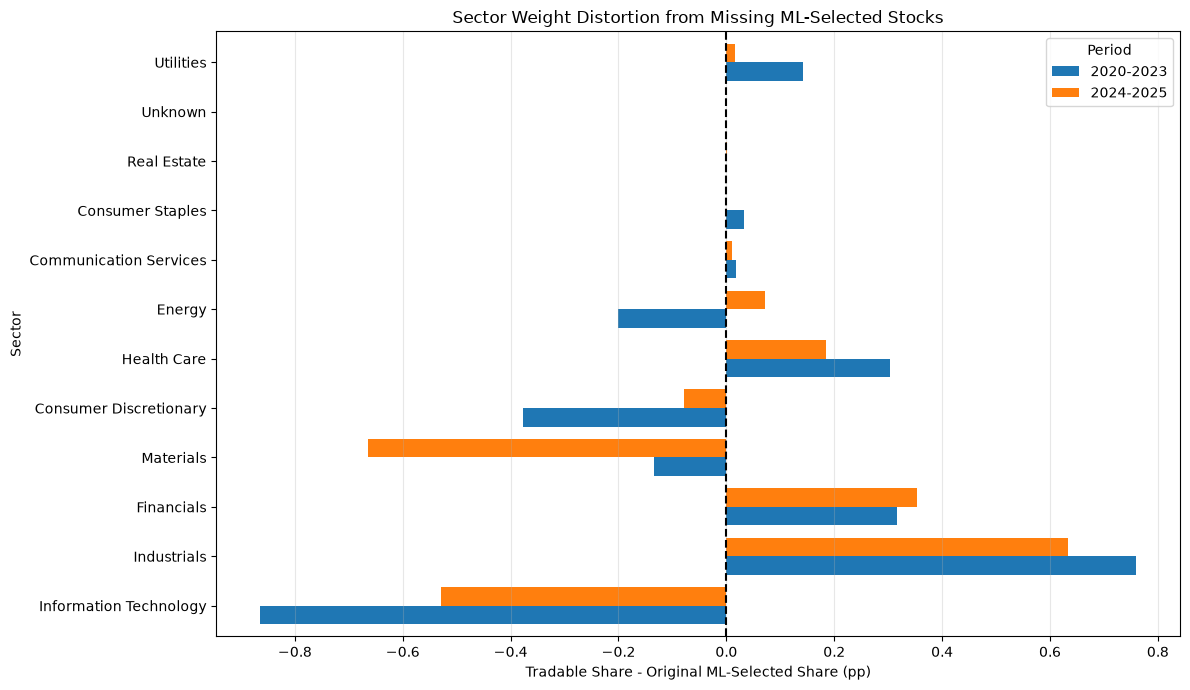


Cell 32 completed successfully.


In [33]:

# ============================================================
# Cell 32 - Missing Stock Sector Exposure Audit
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sector_names = {
    10: "Energy",
    15: "Materials",
    20: "Industrials",
    25: "Consumer Discretionary",
    30: "Consumer Staples",
    35: "Health Care",
    40: "Financials",
    45: "Information Technology",
    50: "Communication Services",
    55: "Utilities",
    60: "Real Estate"
}

sector_list = list(sector_names.values()) + ["Unknown"]

sector_coverage_records = []
missing_stock_records = []

# ------------------------------------------------------------
# 1. Reconstruct original and investable sector composition
# ------------------------------------------------------------

for trade_date in monthly_rebalance_dates:

    inputs = mvo_inputs[trade_date]
    signal_date = pd.Timestamp(inputs["signal_date"])

    selected = pd.Index(
        prediction_snapshots[signal_date]
        .dropna()
        .index
    ).unique()

    tradable = pd.Index(inputs["tickers"]).unique()

    assert tradable.isin(selected).all()

    # Point-in-time sector records
    sector_history = mvo_sector_data.loc[
        (mvo_sector_data["reportdate"] <= signal_date)
        & (mvo_sector_data["tic"].isin(selected))
    ].copy()

    sector_history = sector_history.sort_values(
        ["tic", "reportdate"]
    )

    latest_sectors = (
        sector_history
        .drop_duplicates("tic", keep="last")
        .set_index("tic")["gsector"]
        .reindex(selected)
    )

    latest_sectors = pd.to_numeric(
        latest_sectors,
        errors="coerce"
    )

    labels = latest_sectors.map(
        lambda x: (
            sector_names.get(int(x), "Unknown")
            if pd.notna(x) else "Unknown"
        )
    )

    frame = pd.DataFrame({
        "tic": selected,
        "sector": labels.to_numpy(),
        "tradable": selected.isin(tradable)
    })

    n_selected = len(selected)
    n_tradable = len(tradable)

    assert frame["tradable"].sum() == n_tradable

    for sector in sector_list:

        group = frame.loc[
            frame["sector"] == sector
        ]

        n_original = len(group)
        n_included = int(group["tradable"].sum())
        n_missing = n_original - n_included

        original_share = (
            n_original / n_selected * 100
        )

        actual_share = (
            n_included / n_tradable * 100
        )

        sector_coverage_records.append({
            "trade_date": trade_date,
            "sector": sector,
            "ml_selected": n_original,
            "tradable": n_included,
            "missing": n_missing,
            "coverage_pct": (
                n_included / n_original * 100
                if n_original else np.nan
            ),
            "original_share_pct": original_share,
            "tradable_share_pct": actual_share,
            "sector_shift_pp": (
                actual_share - original_share
            )
        })

    missing = frame.loc[~frame["tradable"]].copy()
    missing["trade_date"] = trade_date

    missing_stock_records.append(missing)

# ------------------------------------------------------------
# 2. Assemble results
# ------------------------------------------------------------

sector_coverage = pd.DataFrame(
    sector_coverage_records
)

missing_stocks = pd.concat(
    missing_stock_records,
    ignore_index=True
)

# ------------------------------------------------------------
# 3. Validate against Cell 31
# ------------------------------------------------------------

monthly_reconstruction = (
    sector_coverage
    .groupby("trade_date")[
        ["ml_selected", "tradable", "missing"]
    ]
    .sum()
)

assert np.array_equal(
    monthly_reconstruction["ml_selected"].to_numpy(),
    coverage_audit["ML Selected"].to_numpy()
)

assert np.array_equal(
    monthly_reconstruction["tradable"].to_numpy(),
    coverage_audit["Tradable"].to_numpy()
)

assert np.array_equal(
    monthly_reconstruction["missing"].to_numpy(),
    coverage_audit["Excluded"].to_numpy()
)

assert np.allclose(
    sector_coverage.groupby("trade_date")[
        "sector_shift_pp"
    ].sum(),
    0.0,
    atol=1e-10
)

print("=" * 75)
print("MISSING STOCK - SECTOR EXPOSURE AUDIT")
print("=" * 75)

print("\nAll sector coverage reconciliation checks passed.")

# ------------------------------------------------------------
# 4. Summarize sector composition
# ------------------------------------------------------------

def summarize_sector_coverage(data):

    summary = (
        data.groupby("sector")
        .agg(
            Total_Selected=("ml_selected", "sum"),
            Total_Missing=("missing", "sum"),
            Avg_ML_Share=("original_share_pct", "mean"),
            Avg_Tradable_Share=("tradable_share_pct", "mean"),
            Avg_Sector_Shift=("sector_shift_pp", "mean"),
            Max_Abs_Shift=(
                "sector_shift_pp",
                lambda x: x.abs().max()
            )
        )
    )

    summary["Missing_Rate (%)"] = (
        summary["Total_Missing"]
        / summary["Total_Selected"].replace(0, np.nan)
        * 100
    )

    return summary.sort_values(
        "Total_Missing",
        ascending=False
    )

full_summary = summarize_sector_coverage(
    sector_coverage
)

print("\nFull Sample Sector Coverage:")
print(
    full_summary.round(3).to_string()
)

# ------------------------------------------------------------
# 5. Subperiod comparisons
# ------------------------------------------------------------

periods = {
    "Development 2020-2023": (
        "2020-09-01", "2023-12-29"
    ),
    "Evaluation 2024-2025": (
        "2024-01-01", "2025-09-30"
    )
}

period_summaries = {}

for name, (start, end) in periods.items():

    period_data = sector_coverage.loc[
        sector_coverage["trade_date"].between(
            start, end
        )
    ]

    summary = summarize_sector_coverage(
        period_data
    )

    period_summaries[name] = summary

    print("\n" + "-" * 75)
    print(name)
    print("-" * 75)

    print(
        summary.round(3).to_string()
    )

# ------------------------------------------------------------
# 6. Monthly sector allocation distortion
# ------------------------------------------------------------

# Half L1 distance measures the fraction of
# portfolio capital implicitly reallocated among sectors
# by excluding unpriced ML-selected stocks.

monthly_sector_distortion = (
    sector_coverage.groupby("trade_date")[
        "sector_shift_pp"
    ]
    .apply(lambda x: x.abs().sum() / 2.0)
)

print("\nMonthly Sector Allocation Distortion (pp):")
print(
    monthly_sector_distortion
    .describe().round(3)
)

print("\nMost Distorted Months:")
print(
    monthly_sector_distortion
    .nlargest(10)
    .round(3)
    .to_string()
)

# ------------------------------------------------------------
# 7. Most frequently excluded stocks by sector
# ------------------------------------------------------------

missing_frequency = (
    missing_stocks
    .groupby(["tic", "sector"])
    .size()
    .reset_index(name="months_missing")
    .sort_values(
        "months_missing",
        ascending=False
    )
)

print("\nTop 30 Excluded Stocks with Sector:")
print(
    missing_frequency
    .head(30)
    .to_string(index=False)
)

print("\nUnknown Sector Classifications:")
print(
    sector_coverage.loc[
        sector_coverage["sector"] == "Unknown",
        ["ml_selected", "missing"]
    ].sum().to_string()
)

# ------------------------------------------------------------
# 8. Plot average allocation changes
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

plot_data = pd.DataFrame({
    "2020-2023": period_summaries[
        "Development 2020-2023"
    ]["Avg_Sector_Shift"],
    "2024-2025": period_summaries[
        "Evaluation 2024-2025"
    ]["Avg_Sector_Shift"]
}).fillna(0.0)

plot_data = plot_data.reindex(
    full_summary.index
)

plot_data.plot(
    kind="barh",
    ax=ax,
    width=0.75
)

ax.axvline(
    0.0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "Sector Weight Distortion from Missing ML-Selected Stocks"
)

ax.set_xlabel(
    "Tradable Share - Original ML-Selected Share (pp)"
)

ax.set_ylabel("Sector")
ax.legend(title="Period")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Save results
# ------------------------------------------------------------

sector_coverage.to_csv(
    "./results/ml_sector_coverage_monthly.csv",
    index=False
)

full_summary.to_csv(
    "./results/ml_sector_coverage_full.csv"
)

missing_frequency.to_csv(
    "./results/ml_missing_stocks_by_sector.csv",
    index=False
)

monthly_sector_distortion.to_csv(
    "./results/ml_sector_distortion_monthly.csv"
)

for name, summary in period_summaries.items():

    suffix = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    summary.to_csv(
        f"./results/ml_sector_coverage_{suffix}.csv"
    )

print("\nCell 32 completed successfully.")


ML MONTHLY EW - MARKET-ADJUSTED PERFORMANCE

Zero-risk-free market regression:
Portfolio daily return = alpha + beta * SPY daily return

Risk-Adjusted Performance:
                       Observations    Beta  Beta CI Low  Beta CI High  Annual Alpha (%)  Alpha CI Low (%)  Alpha CI High (%)  Alpha p-value  Tracking Error (%)  Annual Active Return (%)  Information Ratio  R-squared
Full 2020-2025               1276.0  1.0930       1.0604        1.1256            0.3361           -5.0080             5.6802         0.9019              6.5085                    1.7815             0.2737     0.9010
Development 2020-2023         838.0  1.1277       1.0999        1.1555            2.5186           -4.1762             9.2133         0.4609              6.6533                    4.0676             0.6114     0.9103
Evaluation 2024-2025          438.0  1.0205       0.9712        1.0699           -3.0460          -11.8210             5.7290         0.4963              6.2201                   -2.592

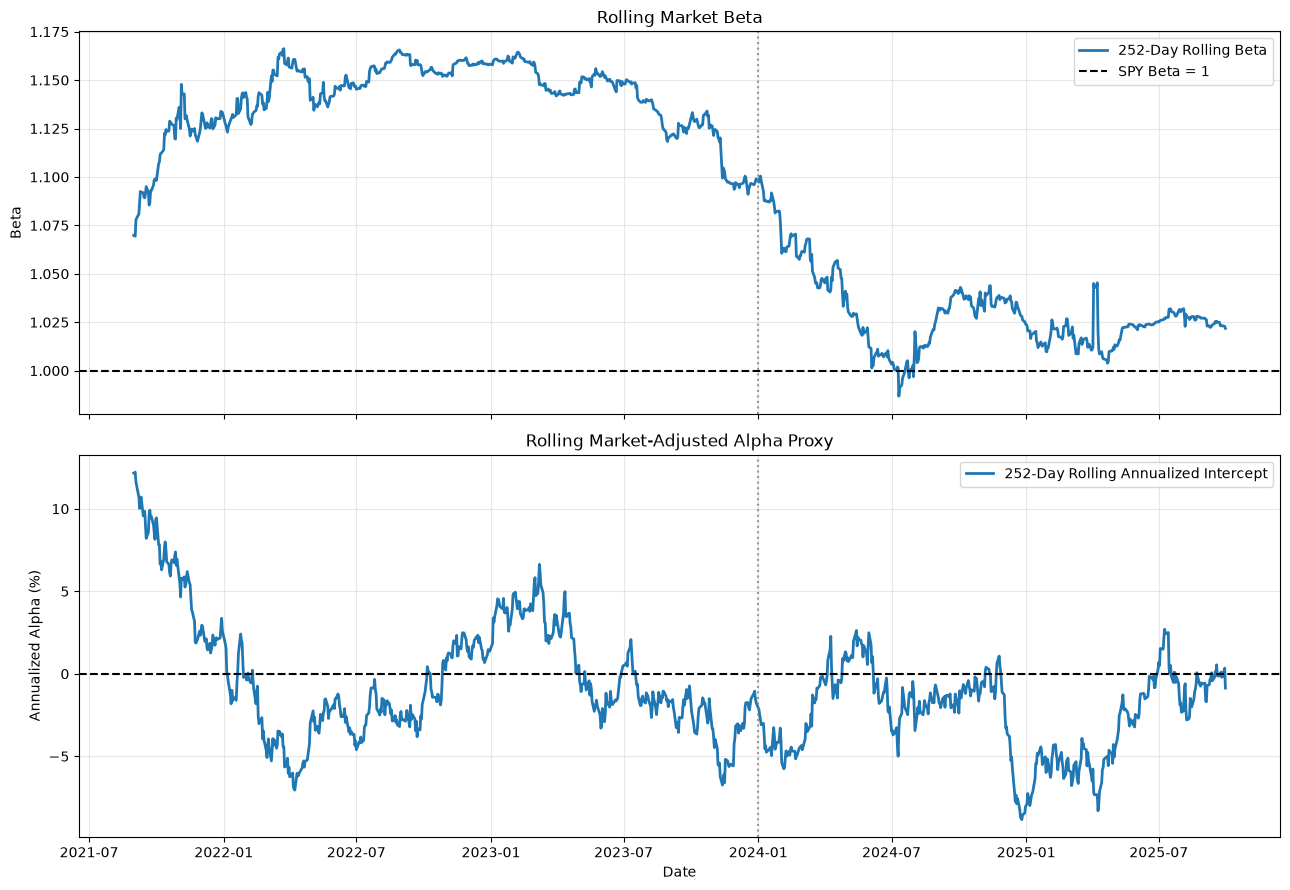


Cell 33 completed successfully.


In [34]:

# ============================================================
# Cell 33 - Market-Adjusted Alpha and Information Ratio
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# ------------------------------------------------------------
# 1. Use original net returns and aligned SPY returns
# ------------------------------------------------------------

risk_index = monthly_comparison.index

ew_ret = (
    matched_ew_result["net_ret"]
    .reindex(risk_index)
    .astype(float)
)

spy_ret = (
    monthly_comparison["SPY"]
    .pct_change(fill_method=None)
    .fillna(0.0)
    .astype(float)
)

assert ew_ret.notna().all()
assert spy_ret.notna().all()
assert ew_ret.index.equals(spy_ret.index)

# Verify the actual portfolio NAV
reconstructed_nav = (1 + ew_ret).cumprod()

assert np.allclose(
    reconstructed_nav.to_numpy(),
    matched_ew_result["nav"].reindex(risk_index).to_numpy(),
    atol=1e-8
)

# ------------------------------------------------------------
# 2. OLS regression with Newey-West HAC covariance
# ------------------------------------------------------------

def market_alpha_hac(portfolio, market, max_lags=5):

    y = portfolio.to_numpy(dtype=float)
    x_market = market.to_numpy(dtype=float)

    n = len(y)

    X = np.column_stack([
        np.ones(n),
        x_market
    ])

    coefficients = np.linalg.lstsq(
        X, y, rcond=None
    )[0]

    residuals = y - X @ coefficients

    # HAC covariance: Newey-West with Bartlett weights
    xu = X * residuals[:, None]

    S = xu.T @ xu

    for lag in range(1, min(max_lags, n - 1) + 1):

        gamma = xu[lag:].T @ xu[:-lag]

        weight = (
            1.0 - lag / (max_lags + 1.0)
        )

        S += weight * (gamma + gamma.T)

    xx_inverse = np.linalg.inv(X.T @ X)

    covariance = (
        xx_inverse @ S @ xx_inverse
    )

    standard_errors = np.sqrt(
        np.maximum(np.diag(covariance), 0)
    )

    alpha, beta = coefficients
    alpha_se, beta_se = standard_errors

    alpha_z = (
        alpha / alpha_se
        if alpha_se > 0 else np.nan
    )

    alpha_p = (
        2 * norm.sf(abs(alpha_z))
        if np.isfinite(alpha_z) else np.nan
    )

    # Annualized arithmetic alpha
    annual_alpha = alpha * 252 * 100
    annual_alpha_se = alpha_se * 252 * 100

    # Active return diagnostics
    active = y - x_market

    tracking_error = (
        np.std(active, ddof=1)
        * np.sqrt(252) * 100
    )

    annual_active_return = (
        np.mean(active) * 252 * 100
    )

    information_ratio = (
        annual_active_return / tracking_error
        if tracking_error > 0 else np.nan
    )

    r_squared = (
        1.0
        - np.sum(residuals ** 2)
        / np.sum((y - y.mean()) ** 2)
    )

    return {
        "Observations": n,
        "Beta": beta,
        "Beta CI Low": beta - 1.96 * beta_se,
        "Beta CI High": beta + 1.96 * beta_se,
        "Annual Alpha (%)": annual_alpha,
        "Alpha CI Low (%)": (
            annual_alpha - 1.96 * annual_alpha_se
        ),
        "Alpha CI High (%)": (
            annual_alpha + 1.96 * annual_alpha_se
        ),
        "Alpha p-value": alpha_p,
        "Tracking Error (%)": tracking_error,
        "Annual Active Return (%)": annual_active_return,
        "Information Ratio": information_ratio,
        "R-squared": r_squared
    }

# ------------------------------------------------------------
# 3. Full sample and subperiod regressions
# ------------------------------------------------------------

periods = {
    "Full 2020-2025": ("2020-09-01", "2025-09-30"),
    "Development 2020-2023": (
        "2020-09-01", "2023-12-29"
    ),
    "Evaluation 2024-2025": (
        "2024-01-01", "2025-09-30"
    )
}

regression_results = {}

for name, (start, end) in periods.items():

    sub_ew = ew_ret.loc[start:end]
    sub_spy = spy_ret.loc[start:end]

    regression_results[name] = market_alpha_hac(
        sub_ew,
        sub_spy,
        max_lags=5
    )

alpha_metrics = pd.DataFrame(
    regression_results
).T

print("=" * 78)
print("ML MONTHLY EW - MARKET-ADJUSTED PERFORMANCE")
print("=" * 78)

print("\nZero-risk-free market regression:")
print("Portfolio daily return = alpha + beta * SPY daily return")

print("\nRisk-Adjusted Performance:")
print(alpha_metrics.round(4).to_string())

print("\nInterpretation Guide:")
print("Annual Alpha is 252 times the daily regression intercept.")
print("Alpha confidence intervals use Newey-West HAC standard errors.")
print("Information Ratio uses realized daily portfolio-minus-SPY returns.")

# ------------------------------------------------------------
# 4. Rolling 252-day Beta and market-adjusted intercept
# ------------------------------------------------------------

window = 252

rolling_beta = (
    ew_ret.rolling(window).cov(spy_ret)
    / spy_ret.rolling(window).var()
)

rolling_alpha = (
    ew_ret.rolling(window).mean()
    - rolling_beta * spy_ret.rolling(window).mean()
) * 252 * 100

rolling_risk = pd.DataFrame({
    "Rolling Beta": rolling_beta,
    "Rolling Annual Alpha (%)": rolling_alpha
})

print("\nRolling Beta Summary:")
print(
    rolling_beta.dropna().describe().round(4)
)

print("\nRolling Annual Alpha Summary (%):")
print(
    rolling_alpha.dropna().describe().round(4)
)

# ------------------------------------------------------------
# 5. Plots
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 9),
    sharex=True
)

axes[0].plot(
    rolling_beta.index,
    rolling_beta,
    linewidth=2,
    label="252-Day Rolling Beta"
)

axes[0].axhline(
    1.0, color="black", linestyle="--",
    label="SPY Beta = 1"
)

axes[0].set_title("Rolling Market Beta")
axes[0].set_ylabel("Beta")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    rolling_alpha.index,
    rolling_alpha,
    linewidth=2,
    label="252-Day Rolling Annualized Intercept"
)

axes[1].axhline(
    0.0, color="black", linestyle="--"
)

axes[1].set_title(
    "Rolling Market-Adjusted Alpha Proxy"
)

axes[1].set_ylabel("Annualized Alpha (%)")
axes[1].set_xlabel("Date")
axes[1].legend()
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.axvline(
        pd.Timestamp("2024-01-01"),
        color="gray",
        linestyle=":",
        alpha=0.8
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

alpha_metrics.to_csv(
    "./results/market_adjusted_alpha_metrics.csv"
)

rolling_risk.to_csv(
    "./results/rolling_beta_alpha.csv"
)

print("\nCell 33 completed successfully.")


## Consolidated Strategy Results

Cell 35 consolidates terminal NAVs and subperiod performance into CSV outputs. These results are used in the research report and its final figures.


In [35]:

# ============================================================
# Cell 34 - Consolidated Strategy Comparison
# ============================================================

import os
import numpy as np
import pandas as pd

os.makedirs("./results", exist_ok=True)

# ------------------------------------------------------------
# 1. Collect existing monthly backtest results
# ------------------------------------------------------------

strategies = {
    "Monthly EW": matched_ew_result,
    "Quarterly EW": quarterly_result,
    "ML Top 50%": ml_top50_result,
    "Low-Beta": beta_balanced_result,
    "Low-Volatility": vol_balanced_result,
    "Residual Momentum": res_mom_result,
    "Sector Momentum": sector_mom_result,
    "Quality-Value": qv_result,
    "MVO": mvo_result
}

dates = monthly_comparison.index

spy_nav = monthly_comparison["SPY"]
qqq_nav = monthly_comparison["QQQ"]

spy_ret = spy_nav.pct_change(
    fill_method=None
).fillna(0.0)

qqq_ret = qqq_nav.pct_change(
    fill_method=None
).fillna(0.0)

# ------------------------------------------------------------
# 2. Check alignment and backtest consistency
# ------------------------------------------------------------

net_returns = pd.DataFrame(index=dates)

for name, result in strategies.items():

    assert result.index.equals(dates), (
        f"Date mismatch: {name}"
    )

    net_returns[name] = result["net_ret"]

    reconstructed = (
        1.0 + result["net_ret"]
    ).cumprod()

    assert np.allclose(
        reconstructed.to_numpy(),
        result["nav"].to_numpy(),
        atol=1e-8
    ), f"NAV reconstruction failed: {name}"

net_returns["SPY"] = spy_ret
net_returns["QQQ"] = qqq_ret

assert net_returns.notna().all().all()

# ------------------------------------------------------------
# 3. Consolidated risk and return metrics
# ------------------------------------------------------------

records = []

for name, result in strategies.items():

    metrics = monthly_performance_metrics(
        result["nav"]
    )

    alpha = market_alpha_hac(
        net_returns[name],
        spy_ret,
        max_lags=5
    )

    records.append({
        "Strategy": name,
        "Final NAV": metrics["Final NAV"],
        "CAGR (%)": metrics["CAGR (%)"],
        "Volatility (%)": metrics["Volatility (%)"],
        "Sharpe": metrics["Sharpe"],
        "Max Drawdown (%)": metrics["Max Drawdown (%)"],
        "Beta vs SPY": alpha["Beta"],
        "Annual Alpha (%)": alpha["Annual Alpha (%)"],
        "Alpha p-value": alpha["Alpha p-value"],
        "Information Ratio": alpha["Information Ratio"],
        "Total Turnover": result["turnover"].sum(),
        "Total Cost": result["cost"].sum()
    })

# Add benchmarks (without modeled transaction costs)
for name, nav in [
    ("SPY", spy_nav),
    ("QQQ", qqq_nav)
]:

    metrics = monthly_performance_metrics(nav)

    records.append({
        "Strategy": name,
        "Final NAV": metrics["Final NAV"],
        "CAGR (%)": metrics["CAGR (%)"],
        "Volatility (%)": metrics["Volatility (%)"],
        "Sharpe": metrics["Sharpe"],
        "Max Drawdown (%)": metrics["Max Drawdown (%)"],
        "Beta vs SPY": (
            net_returns[name].iloc[1:].cov(
                spy_ret.iloc[1:]
            ) / spy_ret.iloc[1:].var()
        ),
        "Annual Alpha (%)": np.nan,
        "Alpha p-value": np.nan,
        "Information Ratio": np.nan,
        "Total Turnover": np.nan,
        "Total Cost": np.nan
    })

strategy_leaderboard = (
    pd.DataFrame(records)
    .set_index("Strategy")
    .sort_values(
        "Final NAV",
        ascending=False
    )
)

# ------------------------------------------------------------
# 4. Relative performance vs SPY and Monthly EW
# ------------------------------------------------------------

monthly_final = strategies[
    "Monthly EW"
]["nav"].iloc[-1]

spy_final = spy_nav.iloc[-1]

strategy_leaderboard["vs SPY (%)"] = (
    strategy_leaderboard["Final NAV"]
    / spy_final - 1.0
) * 100

strategy_leaderboard["vs Monthly EW (%)"] = (
    strategy_leaderboard["Final NAV"]
    / monthly_final - 1.0
) * 100

print("=" * 85)
print("FINAL STRATEGY COMPARISON - 2020 TO 2025")
print("=" * 85)

print("\nReturn and Risk Metrics:")
print(
    strategy_leaderboard[
        [
            "Final NAV",
            "CAGR (%)",
            "Volatility (%)",
            "Sharpe",
            "Max Drawdown (%)",
            "Beta vs SPY",
            "vs SPY (%)",
            "vs Monthly EW (%)"
        ]
    ].round(4).to_string()
)

print("\nAlpha and Trading Costs:")
print(
    strategy_leaderboard[
        [
            "Annual Alpha (%)",
            "Alpha p-value",
            "Information Ratio",
            "Total Turnover",
            "Total Cost"
        ]
    ].round(4).to_string()
)

# ------------------------------------------------------------
# 5. Development / Evaluation comparison
# ------------------------------------------------------------

periods = {
    "Development": (
        "2020-09-01",
        "2023-12-29"
    ),
    "Evaluation": (
        "2024-01-01",
        "2025-09-30"
    )
}

period_records = []

for period_name, (start, end) in periods.items():

    period = net_returns.loc[start:end]

    period_nav = (
        1.0 + period
    ).prod()

    for name in net_returns.columns:

        period_records.append({
            "Period": period_name,
            "Strategy": name,
            "Period Return (%)": (
                period_nav[name] - 1
            ) * 100,
            "Relative to SPY (%)": (
                period_nav[name]
                / period_nav["SPY"] - 1
            ) * 100,
            "Relative to Monthly EW (%)": (
                period_nav[name]
                / period_nav["Monthly EW"] - 1
            ) * 100
        })

period_comparison = pd.DataFrame(
    period_records
)

print("\n" + "=" * 85)
print("DEVELOPMENT VS EVALUATION")
print("=" * 85)

for period_name in periods:

    table = (
        period_comparison.loc[
            period_comparison["Period"] == period_name
        ]
        .drop(columns="Period")
        .set_index("Strategy")
        .sort_values(
            "Period Return (%)",
            ascending=False
        )
    )

    print(f"\n{period_name}:")
    print(table.round(3).to_string())

# ------------------------------------------------------------
# 6. Key final checks
# ------------------------------------------------------------

assert np.isclose(
    strategy_leaderboard.loc[
        "Monthly EW", "Final NAV"
    ],
    2.17184284,
    atol=1e-5
)

assert np.isclose(
    strategy_leaderboard.loc[
        "Quarterly EW", "Final NAV"
    ],
    2.17134171,
    atol=1e-5
)

assert np.isclose(
    strategy_leaderboard.loc[
        "SPY", "Final NAV"
    ],
    2.034730,
    atol=1e-5
)

print("\nFinal benchmark consistency checks passed.")

# ------------------------------------------------------------
# 7. Export tables for report
# ------------------------------------------------------------

strategy_leaderboard.to_csv(
    "./results/final_strategy_leaderboard.csv"
)

period_comparison.to_csv(
    "./results/final_subperiod_comparison.csv",
    index=False
)

print("\nFiles saved:")
print("./results/final_strategy_leaderboard.csv")
print("./results/final_subperiod_comparison.csv")

print("\nCell 34 completed successfully.")


FINAL STRATEGY COMPARISON - 2020 TO 2025

Return and Risk Metrics:
                   Final NAV  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)  Beta vs SPY  vs SPY (%)  vs Monthly EW (%)
Strategy                                                                                                                    
ML Top 50%            2.1774   16.6253         21.1287  0.8345          -33.5992       1.1457      7.0120             0.2562
Monthly EW            2.1718   16.5663         20.0433  0.8660          -29.5172       1.0930      6.7386             0.0000
Quarterly EW          2.1713   16.5610         20.0352  0.8661          -30.0086       1.0904      6.7140            -0.0231
Quality-Value         2.1547   16.3838         20.0741  0.8572          -29.6377       1.0957      5.8957            -0.7897
Low-Beta              2.1403   16.2298         19.5763  0.8672          -29.1309       1.0679      5.1883            -1.4524
Residual Momentum     2.1345   16.1674         19.9013  0.

## Original ML Pipeline Diagnostics

Cells 36–39 inspect rolling model-selection outcomes, reproducibly fit one illustrative Random Forest window, compare MDI and permutation feature importance, and audit signal availability. These checks do not retrain the full provided model pipeline.


ML MODEL SELECTION - WIN RATE ANALYSIS

Expected Sectors: 11
Processed Sectors: 11
Sectors: [np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(30), np.int64(35), np.int64(40), np.int64(45), np.int64(50), np.int64(55), np.int64(60)]

Total Valid Sector-Window Evaluations:
238

Evaluation Date Range:
2020-06-30 to 2025-09-30

Missing Model Result Files:
None

Other Data Issues:
None

Recorded Winner vs Lowest Validation MSE:
winner_consistent
True    238

Windows With Tied Minimum MSE:
0

OVERALL MODEL WIN RATES
        Model  Wins  Win Rate (%)
Random Forest    87        36.555
      XGBoost    88        36.975
     LightGBM    63        26.471

MODEL WIN RATES BY SECTOR (%)
winner  Random Forest (%)  XGBoost (%)  LightGBM (%)  Total Windows
sector                                                             
10                  22.73        54.55         22.73             22
15                   9.52        57.14         33.33             21
20                  45.45     

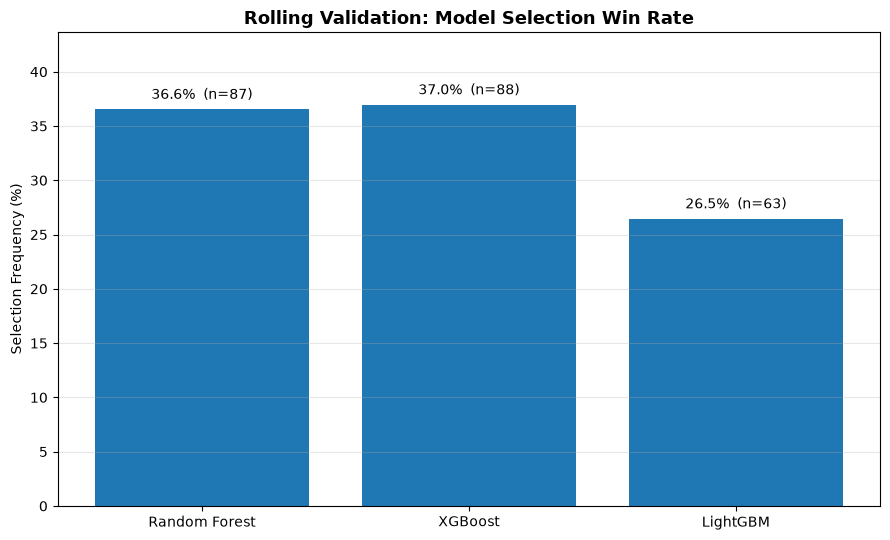


Validation checks passed.
Cell 35 completed successfully.


In [36]:

# ============================================================
# Cell 35 - ML Model Selection Win Rate Analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

RESULTS_DIR = Path("./results")
SECTORS = list(range(10, 65, 5))

MODEL_CODES = ["rf", "xgb", "gbm"]

MODEL_NAMES = {
    "rf": "Random Forest",
    "xgb": "XGBoost",
    "gbm": "LightGBM"
}

selection_records = []
file_issues = []
data_issues = []

# ------------------------------------------------------------
# 2. Load each sector's saved model-selection results
# ------------------------------------------------------------

for sector in SECTORS:

    sector_dir = RESULTS_DIR / f"sector{sector}"

    winner_file = (
        sector_dir / "df_best_model_name.csv"
    )

    score_file = (
        sector_dir / "df_model_score.csv"
    )

    if not winner_file.exists() or not score_file.exists():

        file_issues.append({
            "Sector": sector,
            "Winner File Exists": winner_file.exists(),
            "Score File Exists": score_file.exists()
        })

        continue

    # Model selection results
    winner_df = pd.read_csv(
        winner_file,
        index_col=0
    )

    score_df = pd.read_csv(
        score_file,
        index_col=0
    )

    winner_df.columns = (
        winner_df.columns.str.strip().str.lower()
    )

    score_df.columns = (
        score_df.columns.str.strip().str.lower()
    )

    if "model_name" not in winner_df.columns:
        raise ValueError(
            f"Missing model_name column: sector{sector}"
        )

    if not set(MODEL_CODES).issubset(score_df.columns):
        raise ValueError(
            f"Missing MSE columns: sector{sector}, "
            f"found {score_df.columns.tolist()}"
        )

    # Parse original rolling-window dates
    winner_df.index = pd.to_datetime(
        winner_df.index, errors="coerce"
    )

    score_df.index = pd.to_datetime(
        score_df.index, errors="coerce"
    )

    if (
        winner_df.index.isna().any()
        or score_df.index.isna().any()
    ):
        raise ValueError(
            f"Invalid trade dates in sector{sector}"
        )

    if (
        winner_df.index.has_duplicates
        or score_df.index.has_duplicates
    ):
        raise ValueError(
            f"Duplicate trade dates in sector{sector}"
        )

    missing_winner_dates = (
        score_df.index.difference(winner_df.index)
    )

    missing_score_dates = (
        winner_df.index.difference(score_df.index)
    )

    if (
        len(missing_winner_dates) > 0
        or len(missing_score_dates) > 0
    ):

        data_issues.append({
            "Sector": sector,
            "Issue": "Unmatched model-selection dates",
            "Details": (
                f"Scores without winners: "
                f"{len(missing_winner_dates)}; "
                f"Winners without scores: "
                f"{len(missing_score_dates)}"
            )
        })

    common_dates = (
        winner_df.index
        .intersection(score_df.index)
        .sort_values()
    )

    # --------------------------------------------------------
    # 3. Compare recorded winner against validation MSE
    # --------------------------------------------------------

    for trade_date in common_dates:

        winner = str(
            winner_df.loc[trade_date, "model_name"]
        ).strip().lower()

        mse = pd.to_numeric(
            score_df.loc[
                trade_date, MODEL_CODES
            ],
            errors="coerce"
        ).astype(float)

        if (
            winner not in MODEL_CODES
            or not np.isfinite(mse.to_numpy()).all()
            or (mse < 0).any()
        ):

            data_issues.append({
                "Sector": sector,
                "Issue": "Invalid winner or validation scores",
                "Details": str(trade_date.date())
            })

            continue

        minimum_mse = float(mse.min())

        # More than one model can tie at the minimum
        tied_models = [
            model for model in MODEL_CODES
            if np.isclose(
                mse[model],
                minimum_mse,
                rtol=1e-10,
                atol=1e-12
            )
        ]

        consistent = winner in tied_models

        selection_records.append({
            "sector": sector,
            "trade_date": trade_date,
            "year": trade_date.year,
            "winner": winner,
            "rf_mse": mse["rf"],
            "xgb_mse": mse["xgb"],
            "gbm_mse": mse["gbm"],
            "minimum_mse": minimum_mse,
            "winner_mse": mse[winner],
            "n_tied_models": len(tied_models),
            "winner_consistent": consistent
        })

# ------------------------------------------------------------
# 4. Combine all sector-window records
# ------------------------------------------------------------

if not selection_records:
    raise FileNotFoundError(
        "No valid model-selection results found. "
        "Check ./results/sector10 ... sector60."
    )

model_selection_details = (
    pd.DataFrame(selection_records)
    .sort_values(["sector", "trade_date"])
    .reset_index(drop=True)
)

processed_sectors = sorted(
    model_selection_details["sector"].unique()
)

print("=" * 78)
print("ML MODEL SELECTION - WIN RATE ANALYSIS")
print("=" * 78)

print("\nExpected Sectors:", len(SECTORS))
print("Processed Sectors:", len(processed_sectors))
print("Sectors:", processed_sectors)

print("\nTotal Valid Sector-Window Evaluations:")
print(len(model_selection_details))

print("\nEvaluation Date Range:")
print(
    model_selection_details["trade_date"].min().date(),
    "to",
    model_selection_details["trade_date"].max().date()
)

print("\nMissing Model Result Files:")
if file_issues:
    print(
        pd.DataFrame(file_issues).to_string(index=False)
    )
else:
    print("None")

print("\nOther Data Issues:")
if data_issues:
    print(
        pd.DataFrame(data_issues).to_string(index=False)
    )
else:
    print("None")

print("\nRecorded Winner vs Lowest Validation MSE:")
print(
    model_selection_details[
        "winner_consistent"
    ].value_counts().to_string()
)

print("\nWindows With Tied Minimum MSE:")
print(
    int(
        (model_selection_details["n_tied_models"] > 1)
        .sum()
    )
)

# ------------------------------------------------------------
# 5. Overall model win rates
# ------------------------------------------------------------

total_windows = len(model_selection_details)

overall_wins = (
    model_selection_details["winner"]
    .value_counts()
    .reindex(MODEL_CODES, fill_value=0)
)

model_win_summary = pd.DataFrame({
    "Model": [
        MODEL_NAMES[m] for m in MODEL_CODES
    ],
    "Wins": overall_wins.to_numpy(),
    "Win Rate (%)": (
        overall_wins.to_numpy()
        / total_windows * 100
    )
})

print("\n" + "=" * 78)
print("OVERALL MODEL WIN RATES")
print("=" * 78)

print(
    model_win_summary
    .round(3)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 6. Win rates by sector
# ------------------------------------------------------------

sector_counts = (
    model_selection_details
    .groupby(["sector", "winner"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=SECTORS,
        columns=MODEL_CODES,
        fill_value=0
    )
)

sector_counts["Total Windows"] = (
    sector_counts[MODEL_CODES].sum(axis=1)
)

sector_win_rates = sector_counts.copy()

for model in MODEL_CODES:

    sector_win_rates[model] = (
        sector_counts[model]
        / sector_counts["Total Windows"].replace(
            0, np.nan
        )
        * 100
    )

sector_win_rates = sector_win_rates.rename(
    columns={
        "rf": "Random Forest (%)",
        "xgb": "XGBoost (%)",
        "gbm": "LightGBM (%)"
    }
)

print("\n" + "=" * 78)
print("MODEL WIN RATES BY SECTOR (%)")
print("=" * 78)

print(
    sector_win_rates
    .round(2)
    .to_string()
)

# ------------------------------------------------------------
# 7. Model win rates by calendar year
# ------------------------------------------------------------

yearly_wins = (
    model_selection_details
    .groupby(["year", "winner"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=MODEL_CODES, fill_value=0)
)

yearly_wins["Total Windows"] = (
    yearly_wins[MODEL_CODES].sum(axis=1)
)

yearly_win_rates = yearly_wins.copy()

for model in MODEL_CODES:

    yearly_win_rates[model] = (
        yearly_wins[model]
        / yearly_wins["Total Windows"]
        * 100
    )

yearly_win_rates = yearly_win_rates.rename(
    columns={
        "rf": "Random Forest (%)",
        "xgb": "XGBoost (%)",
        "gbm": "LightGBM (%)"
    }
)

print("\n" + "=" * 78)
print("YEARLY MODEL WIN RATES (%)")
print("=" * 78)

print(
    yearly_win_rates
    .round(2)
    .to_string()
)

# ------------------------------------------------------------
# 8. Validation MSE by sector
# ------------------------------------------------------------

sector_validation_mse = (
    model_selection_details
    .groupby("sector")[
        ["rf_mse", "xgb_mse", "gbm_mse"]
    ]
    .mean()
    .rename(columns={
        "rf_mse": "Random Forest MSE",
        "xgb_mse": "XGBoost MSE",
        "gbm_mse": "LightGBM MSE"
    })
)

print("\n" + "=" * 78)
print("MEAN VALIDATION MSE BY SECTOR")
print("=" * 78)

print(
    sector_validation_mse
    .round(6)
    .to_string()
)

# ------------------------------------------------------------
# 9. Plot overall model win rates
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    model_win_summary["Model"],
    model_win_summary["Win Rate (%)"]
)

for bar, row in zip(
    bars, model_win_summary.itertuples(index=False)
):
    ax.annotate(
        f"{row[2]:.1f}%  (n={row[1]})",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.set_title(
    "Rolling Validation: Model Selection Win Rate",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Selection Frequency (%)")
ax.set_ylim(
    0,
    max(10, model_win_summary["Win Rate (%)"].max() * 1.18)
)

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Validate and export
# ------------------------------------------------------------

assert model_win_summary["Wins"].sum() == total_windows

assert np.isclose(
    model_win_summary["Win Rate (%)"].sum(),
    100.0
)

assert (
    sector_counts["Total Windows"].sum()
    == total_windows
)

assert model_selection_details[
    "winner_consistent"
].all(), (
    "Saved model winners do not match minimum MSE."
)

model_selection_details.to_csv(
    "./results/model_selection_details.csv",
    index=False
)

model_win_summary.to_csv(
    "./results/model_win_summary.csv",
    index=False
)

sector_win_rates.to_csv(
    "./results/model_win_rates_by_sector.csv"
)

yearly_win_rates.to_csv(
    "./results/model_win_rates_by_year.csv"
)

sector_validation_mse.to_csv(
    "./results/model_validation_mse_by_sector.csv"
)

print("\nValidation checks passed.")
print("Cell 35 completed successfully.")


In [37]:

# ============================================================
# Cell 36 - Feature Importance Artifact Audit
# ============================================================

from pathlib import Path
import pandas as pd
import re

ROOT = Path.cwd()
RESULTS_DIR = ROOT / "results"

print("=" * 75)
print("FEATURE IMPORTANCE ARTIFACT AUDIT")
print("=" * 75)

print("\nWorking Directory:")
print(ROOT)

# ------------------------------------------------------------
# 1. Inventory saved model artifacts
# ------------------------------------------------------------

MODEL_EXTENSIONS = {
    ".pkl", ".pickle", ".joblib",
    ".ubj", ".bst", ".onnx", ".cbm",
    ".model"
}

IMPORTANCE_KEYWORDS = [
    "importance",
    "shap",
    "permutation",
    "feature_rank",
    "feature_score"
]

model_artifacts = []
importance_artifacts = []

for path in RESULTS_DIR.rglob("*"):

    if not path.is_file():
        continue

    name = path.name.lower()

    if path.suffix.lower() in MODEL_EXTENSIONS:
        model_artifacts.append(path)

    if any(k in name for k in IMPORTANCE_KEYWORDS):
        importance_artifacts.append(path)

print("\nSaved Model Files:")
print("Count:", len(model_artifacts))

for path in model_artifacts[:30]:
    print(path.relative_to(ROOT))

print("\nFeature Importance / SHAP Files:")
print("Count:", len(importance_artifacts))

for path in importance_artifacts[:30]:
    print(path.relative_to(ROOT))

# ------------------------------------------------------------
# 2. Show existing output file structure
# ------------------------------------------------------------

print("\nExample: Sector 45 Output Files")

sector_path = RESULTS_DIR / "sector45"

if sector_path.exists():

    for path in sorted(sector_path.iterdir()):
        if path.is_file():
            print(path.name)

else:
    print("sector45 directory not found")

# ------------------------------------------------------------
# 3. Locate source scripts
# ------------------------------------------------------------

SCRIPT_NAMES = [
    "ml_model.py",
    "fundamental_run_model.py",
    "fundamental_portfolio_drl.py"
]

candidate_dirs = [
    ROOT,
    ROOT / "source_code",
    ROOT.parent / "source_code"
]

script_paths = {}

for name in SCRIPT_NAMES:

    for directory in candidate_dirs:

        candidate = directory / name

        if candidate.exists():
            script_paths[name] = candidate
            break

print("\nAvailable Training Scripts:")

for name in SCRIPT_NAMES:
    print(
        f"{name}:",
        script_paths.get(name, "NOT FOUND")
    )

# ------------------------------------------------------------
# 4. Inspect whether feature importance is computed or saved
# ------------------------------------------------------------

patterns = [
    r"feature_importances_",
    r"feature_importance",
    r"get_score\s*\(",
    r"permutation_importance",
    r"shap",
    r"save_model\s*\(",
    r"joblib\.dump",
    r"pickle\.dump",
    r"to_pickle\s*\(",
    r"plot_importance",
]

pattern = re.compile(
    "|".join(patterns),
    flags=re.IGNORECASE
)

script_findings = []

for script_name, script_path in script_paths.items():

    source_lines = script_path.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    for line_number, line in enumerate(
        source_lines, start=1
    ):

        if pattern.search(line):

            script_findings.append({
                "Script": script_name,
                "Line": line_number,
                "Code": line.strip()[:160]
            })

print("\nFeature Importance / Model Saving Code:")

if script_findings:

    findings_df = pd.DataFrame(
        script_findings
    )

    print(
        findings_df.to_string(index=False)
    )

else:
    print(
        "No direct feature-importance or model-saving "
        "keywords found in inspected scripts."
    )

# ------------------------------------------------------------
# 5. Conclusion
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ARTIFACT AUDIT SUMMARY")
print("=" * 75)

print("Saved trained-model artifacts:",
      len(model_artifacts))

print("Saved importance-related files:",
      len(importance_artifacts))

print("Relevant source-code references:",
      len(script_findings))

if model_artifacts or importance_artifacts:

    print(
        "\nPotentially reusable artifacts found. "
        "Inspect their formats before analysis."
    )

else:

    print(
        "\nNo obvious saved model or feature-importance "
        "artifacts found under ./results."
    )

print(
    "\nThis audit does not retrain models or "
    "modify existing results."
)

print("\nCell 36 completed successfully.")


FEATURE IMPORTANCE ARTIFACT AUDIT

Working Directory:
c:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\source_code

Saved Model Files:
Count: 0

Feature Importance / SHAP Files:
Count: 3
results\rf_sector45_feature_importance.csv
results\rf_sector45_importance_comparison.csv
results\rf_sector45_permutation_importance.csv

Example: Sector 45 Output Files
df_best_model_name.csv
df_model_score.csv
df_predict_best.csv
df_predict_gbm.csv
df_predict_rf.csv
df_predict_xgb.csv

Available Training Scripts:
ml_model.py: c:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\source_code\ml_model.py
fundamental_run_model.py: c:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\source_code\fundamental_run_model.py
fundamental_portfolio_drl.py: NOT FOUND

Feature Importance / Model Saving Code:
     Script  Line                                                               Code
ml_model.py   290                                for i in range(tmp_table.shape[1]):
ml_model.py   485                         

ORIGINAL RF FEATURE IMPORTANCE RECONSTRUCTION

Sector: 45
Model: Random Forest
Selected Window: 2023-09-30
Original Validation MSE: 0.0162526276368323

Number of Features: 53
Feature Names:
['adj_close_q', 'EPS', 'BPS', 'DPS', 'cur_ratio', 'quick_ratio', 'cash_ratio', 'acc_rec_turnover', 'debt_ratio', 'debt_to_equity', 'pe', 'ps', 'pb', 'roe', 'net_income_ratio', 'gross_margin', 'operating_margin', 'ebitda_margin', 'pretax_margin', 'effective_tax_rate', 'ebt_per_ebit', 'asset_turnover', 'fixed_asset_turnover', 'inventory_turnover', 'payables_turnover', 'wc_turnover', 'debt_to_assets', 'debt_to_capital', 'lt_debt_to_capital', 'interest_coverage', 'debt_service_coverage', 'debt_to_mktcap', 'fcf_per_share', 'ocf_per_share', 'cash_per_share', 'capex_per_share', 'fcf_to_ocf', 'ocf_ratio', 'ocf_to_sales', 'ocf_coverage', 'st_ocf_coverage', 'capex_coverage', 'revenue_per_share', 'tangible_bvps', 'interest_debt_per_share', 'peg', 'price_to_fcf', 'price_to_ocf', 'ev_multiple', 'dividend_payout'

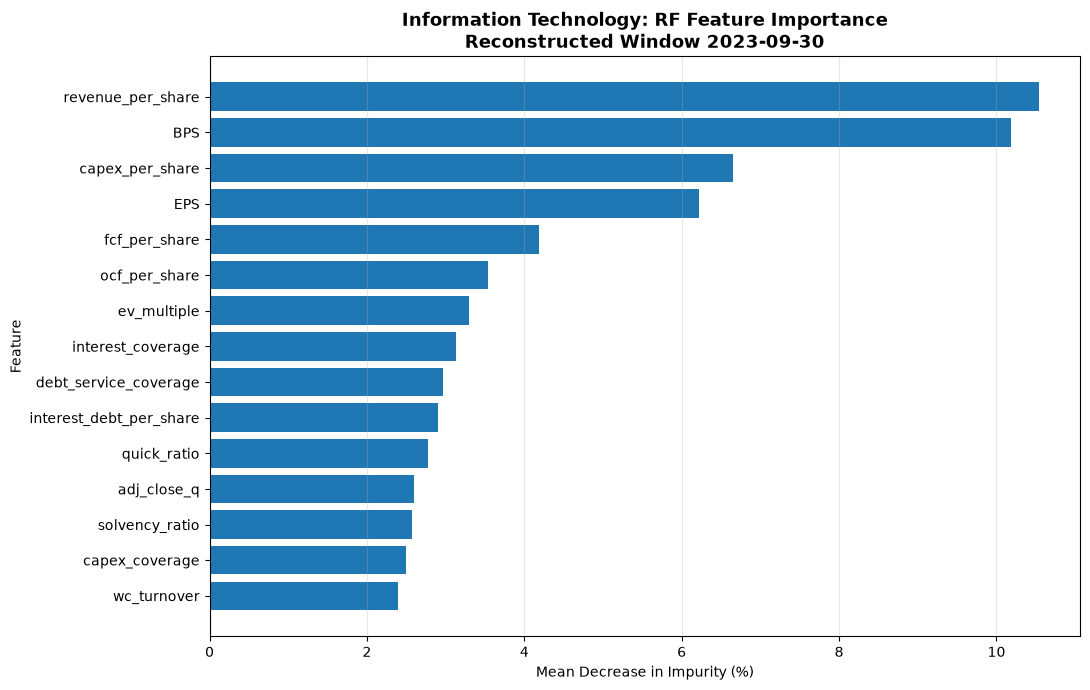


Validation MSE successfully reproduced.

Cell 37 completed successfully.


In [38]:

# ============================================================
# Cell 37 - Reconstruct Original RF Feature Importance
# Sector 45: Information Technology
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import re
from pathlib import Path
from sklearn.metrics import mean_squared_error

import ml_model

# ------------------------------------------------------------
# 1. Select a historical RF-winning window
# ------------------------------------------------------------

FI_SECTOR = 45

fi_candidates = model_selection_details.loc[
    (model_selection_details["sector"] == FI_SECTOR)
    & (model_selection_details["winner"] == "rf")
    & (
        model_selection_details["trade_date"]
        <= pd.Timestamp("2023-12-31")
    )
].sort_values("trade_date")

if fi_candidates.empty:
    raise ValueError(
        "No RF-winning Sector 45 window found "
        "before 2024."
    )

fi_record = fi_candidates.iloc[-1]

fi_target_date = pd.Timestamp(
    fi_record["trade_date"]
)

fi_saved_mse = float(
    fi_record["rf_mse"]
)

print("=" * 75)
print("ORIGINAL RF FEATURE IMPORTANCE RECONSTRUCTION")
print("=" * 75)

print("\nSector:", FI_SECTOR)
print("Model: Random Forest")
print("Selected Window:", fi_target_date.date())
print("Original Validation MSE:", fi_saved_mse)

# ------------------------------------------------------------
# 2. Load the original sector dataset
# ------------------------------------------------------------

fi_path = Path(
    f"./prepared/sector{FI_SECTOR}.xlsx"
)

if not fi_path.exists():
    raise FileNotFoundError(fi_path)

fi_data = pd.read_excel(fi_path)

# Match fundamental_run_model.py preprocessing
fi_data["date"] = pd.to_datetime(
    fi_data["date"]
)

fi_data["reportdate"] = pd.to_datetime(
    fi_data["reportdate"].replace(0, np.nan)
)

fi_unique_dates = sorted(
    fi_data["date"].unique()
)

fi_dates_index = pd.DatetimeIndex(
    fi_unique_dates
)

if fi_target_date not in fi_dates_index:
    raise ValueError(
        "Saved model date is not present "
        "in the sector dataset."
    )

fi_current_index = int(
    fi_dates_index.get_loc(fi_target_date)
)

# ------------------------------------------------------------
# 3. Replicate exact feature-selection convention
# ------------------------------------------------------------

fi_excluded_columns = [
    "gvkey", "tic", "datadate",
    "rdq", "datadate",
    "fyearq", "fqtr",
    "conm", "datacqtr", "datafqtr",
    "gsector", "y_return"
]

fi_features = [
    col for col in fi_data.columns.values
    if col not in fi_excluded_columns
    and pd.api.types.is_numeric_dtype(
        fi_data[col]
    )
    and not fi_data[col].isna().any()
]

# The original run_4model sanitizes column names
fi_renamed_cols = [
    re.sub(r"[^A-Za-z0-9_]+", "", col)
    for col in fi_data.columns
]

if len(set(fi_renamed_cols)) != len(fi_renamed_cols):
    raise ValueError(
        "Original column sanitization produces duplicates."
    )

fi_model_data = fi_data.rename(
    columns=lambda x: re.sub(
        r"[^A-Za-z0-9_]+", "", x
    )
)

if not set(fi_features).issubset(
    fi_model_data.columns
):
    raise ValueError(
        "Feature names changed under original sanitization."
    )

print("\nNumber of Features:", len(fi_features))
print("Feature Names:")
print(fi_features)

print("\nAdjusted Quarterly Close Used as Feature:",
      "adj_close_q" in fi_features)

# ------------------------------------------------------------
# 4. Reconstruct the original rolling train/test split
# ------------------------------------------------------------

FI_TEST_WINDOWS = 4
FI_MAX_ROLLING_INDEX = 44

fi_X_train, fi_y_train, _ = (
    ml_model.prepare_rolling_train(
        df=fi_model_data,
        features_column=fi_features,
        label_column="y_return",
        date_column="date",
        unique_datetime=fi_unique_dates,
        testing_windows=FI_TEST_WINDOWS,
        first_trade_date_index=fi_current_index,
        max_rolling_window_index=FI_MAX_ROLLING_INDEX,
        current_index=fi_current_index
    )
)

fi_X_test, fi_y_test, _ = (
    ml_model.prepare_rolling_test(
        df=fi_model_data,
        features_column=fi_features,
        label_column="y_return",
        date_column="date",
        unique_datetime=fi_unique_dates,
        testing_windows=FI_TEST_WINDOWS,
        first_trade_date_index=fi_current_index,
        current_index=fi_current_index
    )
)

if fi_X_train.empty or fi_X_test.empty:
    raise ValueError(
        "Empty reconstructed training or validation data."
    )

assert fi_X_train.columns.tolist() == fi_features
assert fi_X_test.columns.tolist() == fi_features

print("\nTraining Rows:", len(fi_X_train))
print("Validation Rows:", len(fi_X_test))

print("\nTraining Period:")
print(
    fi_model_data.loc[
        fi_X_train.index, "date"
    ].min().date(),
    "to",
    fi_model_data.loc[
        fi_X_train.index, "date"
    ].max().date()
)

print("\nValidation Period:")
print(
    fi_model_data.loc[
        fi_X_test.index, "date"
    ].min().date(),
    "to",
    fi_model_data.loc[
        fi_X_test.index, "date"
    ].max().date()
)

# ------------------------------------------------------------
# 5. Fit using the PROFESSOR'S ORIGINAL RF FUNCTION
# ------------------------------------------------------------

print("\nReconstructing original Random Forest...")
print("This runs one historical GridSearchCV, not all windows.")

fi_start = time.perf_counter()

fi_rf_model = ml_model.train_random_forest(
    fi_X_train,
    fi_y_train
)

fi_training_seconds = (
    time.perf_counter() - fi_start
)

print("\nTraining Time (seconds):")
print(round(fi_training_seconds, 2))

# ------------------------------------------------------------
# 6. Validate against the saved original MSE
# ------------------------------------------------------------

fi_prediction = fi_rf_model.predict(
    fi_X_test
)

fi_rebuilt_mse = mean_squared_error(
    fi_y_test,
    fi_prediction
)

fi_mse_match = np.isclose(
    fi_rebuilt_mse,
    fi_saved_mse,
    rtol=1e-5,
    atol=1e-8
)

print("\n" + "=" * 75)
print("ORIGINAL MODEL REPRODUCTION CHECK")
print("=" * 75)

print(f"Saved Validation MSE:   {fi_saved_mse:.10f}")
print(f"Rebuilt Validation MSE: {fi_rebuilt_mse:.10f}")
print(f"Absolute Difference:    {abs(fi_saved_mse-fi_rebuilt_mse):.10f}")
print(f"MSE Match:              {fi_mse_match}")

print("\nSelected RF Hyperparameters:")

for param in [
    "n_estimators",
    "max_features",
    "min_samples_leaf",
    "min_samples_split",
    "max_depth",
    "random_state"
]:
    print(
        f"{param}:",
        fi_rf_model.get_params()[param]
    )

# ------------------------------------------------------------
# 7. Extract actual trained-model feature importance
# ------------------------------------------------------------

fi_importance = pd.DataFrame({
    "Feature": fi_features,
    "Importance": (
        fi_rf_model.feature_importances_
    )
})

fi_importance = (
    fi_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

fi_importance["Rank"] = (
    np.arange(1, len(fi_importance) + 1)
)

fi_importance["Importance (%)"] = (
    fi_importance["Importance"] * 100
)

print("\n" + "=" * 75)
print("TOP 20 RF FEATURE IMPORTANCES")
print("=" * 75)

print(
    fi_importance.head(20)[
        ["Rank", "Feature", "Importance (%)"]
    ]
    .round(4)
    .to_string(index=False)
)

print("\nTotal Feature Importance:")
print(
    fi_importance["Importance"].sum()
)

# ------------------------------------------------------------
# 8. Plot top 15 features
# ------------------------------------------------------------

fi_top = (
    fi_importance.head(15)
    .sort_values("Importance (%)")
)

fig, ax = plt.subplots(
    figsize=(11, 7)
)

ax.barh(
    fi_top["Feature"],
    fi_top["Importance (%)"]
)

ax.set_title(
    "Information Technology: RF Feature Importance\n"
    f"Reconstructed Window {fi_target_date.date()}",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel(
    "Mean Decrease in Impurity (%)"
)

ax.set_ylabel("Feature")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Save results and reproduction diagnostics
# ------------------------------------------------------------

fi_importance.to_csv(
    "./results/rf_sector45_feature_importance.csv",
    index=False
)

fi_audit = pd.DataFrame([{
    "Sector": FI_SECTOR,
    "Window Date": fi_target_date,
    "Model": "Random Forest",
    "Training Rows": len(fi_X_train),
    "Validation Rows": len(fi_X_test),
    "Number of Features": len(fi_features),
    "Saved MSE": fi_saved_mse,
    "Rebuilt MSE": fi_rebuilt_mse,
    "MSE Match": fi_mse_match,
    "Training Seconds": fi_training_seconds
}])

fi_audit.to_csv(
    "./results/rf_sector45_reproduction_audit.csv",
    index=False
)

if not fi_mse_match:
    print(
        "\nWARNING: Rebuilt MSE does not match the saved "
        "result. Check library versions and preprocessing "
        "before treating importance as a faithful reconstruction."
    )
else:
    print(
        "\nValidation MSE successfully reproduced."
    )

assert np.isclose(
    fi_importance["Importance"].sum(),
    1.0
)

print("\nCell 37 completed successfully.")


PERMUTATION FEATURE IMPORTANCE

Sector: 45
Model: Original Reconstructed Random Forest
Window: 2023-09-30
Validation Observations: 283
Features: 53
Baseline Validation MSE: 0.0162526276

Running permutation importance...
No model retraining required.

TOP 20 PERMUTATION FEATURE IMPORTANCES
 Permutation Rank                 Feature  MDI Rank  Delta MSE / Baseline (%)  Permutation Delta MSE  Permutation Std
                1       interest_coverage         8                  0.380343               0.000062         0.000024
                2         capex_per_share         3                  0.322969               0.000052         0.000030
                3           fcf_per_share         5                  0.306673               0.000050         0.000031
                4       revenue_per_share         1                  0.242618               0.000039         0.000047
                5      effective_tax_rate        28                  0.137293               0.000022         0.000009
 

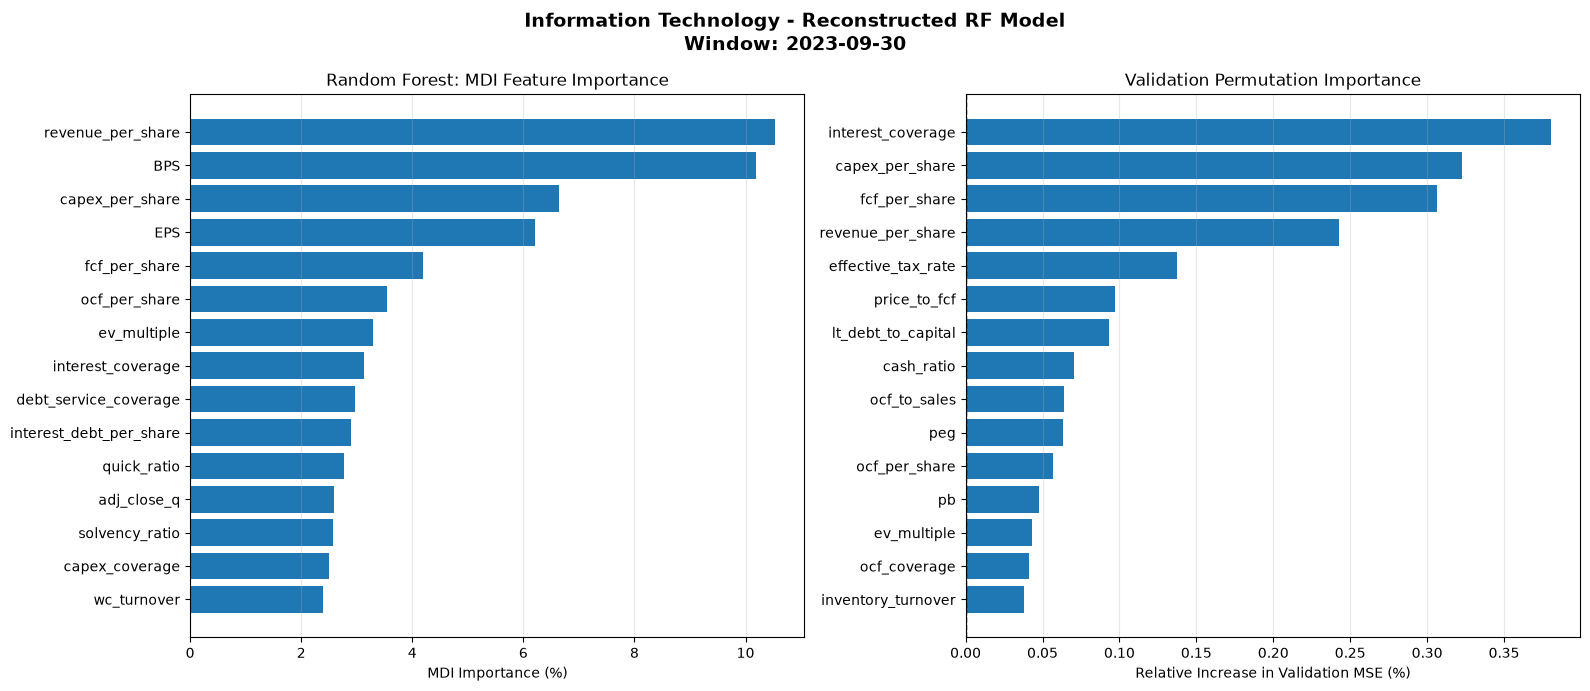


All permutation importance checks passed.
Cell 38 completed successfully.


In [39]:

# ============================================================
# Cell 38 - Permutation Feature Importance
# Reuse the reconstructed original Random Forest
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error

# ------------------------------------------------------------
# 1. Verify reconstructed model and validation data
# ------------------------------------------------------------

assert fi_mse_match, (
    "Original model reproduction must pass first."
)

assert len(fi_features) == fi_X_test.shape[1]

baseline_mse = mean_squared_error(
    fi_y_test,
    fi_rf_model.predict(fi_X_test)
)

print("=" * 75)
print("PERMUTATION FEATURE IMPORTANCE")
print("=" * 75)

print("\nSector:", FI_SECTOR)
print("Model: Original Reconstructed Random Forest")
print("Window:", fi_target_date.date())
print("Validation Observations:", len(fi_X_test))
print("Features:", len(fi_features))
print("Baseline Validation MSE:", round(baseline_mse, 10))

# ------------------------------------------------------------
# 2. Permutation importance on validation data
# ------------------------------------------------------------

print("\nRunning permutation importance...")
print("No model retraining required.")

N_REPEATS = 10

perm_result = permutation_importance(
    estimator=fi_rf_model,
    X=fi_X_test,
    y=fi_y_test,
    scoring="neg_mean_squared_error",
    n_repeats=N_REPEATS,
    random_state=42,
    n_jobs=1
)

# Positive importance = increase in validation MSE
# after a feature is randomly permuted.

# ------------------------------------------------------------
# 3. Construct comparison table
# ------------------------------------------------------------

fi_permutation = pd.DataFrame({
    "Feature": fi_features,
    "MDI Importance (%)": (
        fi_rf_model.feature_importances_ * 100
    ),
    "Permutation Delta MSE": (
        perm_result.importances_mean
    ),
    "Permutation Std": (
        perm_result.importances_std
    )
})

fi_permutation["Delta MSE / Baseline (%)"] = (
    fi_permutation["Permutation Delta MSE"]
    / baseline_mse * 100
)

fi_permutation = (
    fi_permutation
    .sort_values(
        "Permutation Delta MSE",
        ascending=False
    )
    .reset_index(drop=True)
)

fi_permutation["Permutation Rank"] = (
    np.arange(1, len(fi_permutation) + 1)
)

fi_permutation["MDI Rank"] = (
    fi_permutation["MDI Importance (%)"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# ------------------------------------------------------------
# 4. Print top 20 permutation features
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TOP 20 PERMUTATION FEATURE IMPORTANCES")
print("=" * 75)

print(
    fi_permutation.head(20)[
        [
            "Permutation Rank",
            "Feature",
            "MDI Rank",
            "Delta MSE / Baseline (%)",
            "Permutation Delta MSE",
            "Permutation Std"
        ]
    ].round(6).to_string(index=False)
)

# ------------------------------------------------------------
# 5. Compare MDI and permutation rankings
# ------------------------------------------------------------

rank_correlation = (
    fi_permutation["MDI Rank"]
    .corr(
        fi_permutation["Permutation Rank"],
        method="spearman"
    )
)

positive_count = int(
    (fi_permutation["Permutation Delta MSE"] > 0).sum()
)

negative_count = int(
    (fi_permutation["Permutation Delta MSE"] < 0).sum()
)

print("\n" + "=" * 75)
print("IMPORTANCE METHOD COMPARISON")
print("=" * 75)

print("\nSpearman Rank Correlation (MDI vs Permutation):")
print(round(rank_correlation, 5))

print("\nFeatures With Positive Permutation Importance:")
print(positive_count)

print("\nFeatures With Negative Permutation Importance:")
print(negative_count)

mdi_top10 = set(
    fi_permutation
    .sort_values("MDI Rank")
    .head(10)["Feature"]
)

perm_top10 = set(
    fi_permutation
    .head(10)["Feature"]
)

common_top10 = sorted(mdi_top10 & perm_top10)

print("\nCommon Top 10 Features Across Both Methods:")
print(common_top10)

print("\nTop 10 Overlap:")
print(f"{len(common_top10)} / 10")

# ------------------------------------------------------------
# 6. Visualize both importance methods
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

mdi_top15 = (
    fi_permutation
    .sort_values(
        "MDI Importance (%)",
        ascending=False
    )
    .head(15)
    .sort_values("MDI Importance (%)")
)

perm_top15 = (
    fi_permutation
    .head(15)
    .sort_values("Delta MSE / Baseline (%)")
)

axes[0].barh(
    mdi_top15["Feature"],
    mdi_top15["MDI Importance (%)"]
)

axes[0].set_title(
    "Random Forest: MDI Feature Importance"
)

axes[0].set_xlabel("MDI Importance (%)")
axes[0].grid(axis="x", alpha=0.3)

axes[1].barh(
    perm_top15["Feature"],
    perm_top15["Delta MSE / Baseline (%)"]
)

axes[1].axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[1].set_title(
    "Validation Permutation Importance"
)

axes[1].set_xlabel(
    "Relative Increase in Validation MSE (%)"
)

axes[1].grid(axis="x", alpha=0.3)

fig.suptitle(
    "Information Technology - Reconstructed RF Model\n"
    f"Window: {fi_target_date.date()}",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Save output
# ------------------------------------------------------------

fi_permutation.to_csv(
    "./results/rf_sector45_permutation_importance.csv",
    index=False
)

importance_comparison_summary = pd.DataFrame([{
    "Sector": FI_SECTOR,
    "Window": fi_target_date,
    "Validation MSE": baseline_mse,
    "Features": len(fi_features),
    "Permutation Repeats": N_REPEATS,
    "MDI Permutation Rank Correlation": rank_correlation,
    "Common Top 10 Features": len(common_top10),
    "Positive Permutation Features": positive_count,
    "Negative Permutation Features": negative_count
}])

importance_comparison_summary.to_csv(
    "./results/rf_sector45_importance_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Validation
# ------------------------------------------------------------

assert len(fi_permutation) == len(fi_features)

assert fi_permutation["Feature"].is_unique

assert np.isclose(
    baseline_mse,
    fi_rebuilt_mse,
    rtol=1e-8,
    atol=1e-12
)

assert np.isfinite(
    fi_permutation[
        [
            "MDI Importance (%)",
            "Permutation Delta MSE",
            "Permutation Std"
        ]
    ].to_numpy()
).all()

print("\nAll permutation importance checks passed.")
print("Cell 38 completed successfully.")


In [40]:

# ============================================================
# Cell 39 - Early ML Signal Availability Audit
# Diagnose May-August 2020 before extending the backtest
# ============================================================

import numpy as np
import pandas as pd

AUDIT_START = pd.Timestamp("2020-05-01")
AUDIT_END = pd.Timestamp("2020-09-02")

early_dates = daily_returns.index[
    (daily_returns.index >= AUDIT_START)
    & (daily_returns.index <= AUDIT_END)
]

audit_records = []

for trade_date in early_dates:

    pos = ml_prediction_dates.searchsorted(
        trade_date, side="left"
    ) - 1

    if pos < 0:
        audit_records.append({
            "trade_date": trade_date,
            "signal_date": pd.NaT,
            "ml_selected": 0,
            "priced": 0,
            "sufficient_history": 0,
            "eligible": 0
        })
        continue

    signal_date = pd.Timestamp(
        ml_prediction_dates[pos]
    )

    predictions = (
        prediction_snapshots[signal_date]
        .dropna()
    )

    selected = pd.Index(predictions.index)

    priced_candidates = selected.intersection(
        close_prices.columns
    )

    current_prices = close_prices.loc[
        trade_date, priced_candidates
    ]

    valid_prices = (
        current_prices.notna()
        & np.isfinite(current_prices)
        & (current_prices > 0)
    )

    priced_candidates = current_prices.index[
        valid_prices
    ]

    history = daily_returns.loc[
        daily_returns.index < trade_date
    ].tail(MVO_LOOKBACK)

    history_counts = (
        history[priced_candidates].count()
    )

    eligible = history_counts.index[
        history_counts >= MVO_MIN_HISTORY
    ]

    audit_records.append({
        "trade_date": trade_date,
        "signal_date": signal_date,
        "ml_selected": len(selected),
        "priced": len(priced_candidates),
        "sufficient_history": int(
            (history_counts >= MVO_MIN_HISTORY).sum()
        ),
        "eligible": len(eligible)
    })

early_signal_audit = (
    pd.DataFrame(audit_records)
    .set_index("trade_date")
)

early_signal_audit["month"] = (
    early_signal_audit.index.to_period("M")
)

early_signal_audit["valid_portfolio"] = (
    early_signal_audit["eligible"] >= MVO_MIN_STOCKS
)

# ------------------------------------------------------------
# 1. Monthly signal availability
# ------------------------------------------------------------

monthly_first = (
    early_signal_audit
    .groupby("month")
    .head(1)
)

monthly_last = (
    early_signal_audit
    .groupby("month")
    .tail(1)
)

monthly_summary = pd.DataFrame({
    "First Trade Day":
        monthly_first.index.strftime("%Y-%m-%d"),
    "First-Day ML Stocks":
        monthly_first["ml_selected"].to_numpy(),
    "First-Day Eligible":
        monthly_first["eligible"].to_numpy(),
    "Last-Day ML Stocks":
        monthly_last["ml_selected"].to_numpy(),
    "Last-Day Eligible":
        monthly_last["eligible"].to_numpy()
}, index=monthly_first["month"].astype(str).to_numpy())

print("=" * 75)
print("EARLY ML SIGNAL AVAILABILITY AUDIT")
print("=" * 75)

print("\nMonthly Availability Summary:")
print(monthly_summary.to_string())

# ------------------------------------------------------------
# 2. First 15 trading days
# ------------------------------------------------------------

print("\nFirst 15 Trading Days:")

print(
    early_signal_audit[
        [
            "signal_date",
            "ml_selected",
            "priced",
            "eligible",
            "valid_portfolio"
        ]
    ].head(15).to_string()
)

# ------------------------------------------------------------
# 3. First date with a usable portfolio
# ------------------------------------------------------------

valid_dates = early_signal_audit.index[
    early_signal_audit["valid_portfolio"]
]

print("\nFirst Date with At Least",
      MVO_MIN_STOCKS, "Eligible Stocks:")

if len(valid_dates) > 0:

    first_valid = valid_dates[0]

    print(first_valid.date())

    print(
        early_signal_audit.loc[
            first_valid,
            [
                "signal_date",
                "ml_selected",
                "priced",
                "eligible"
            ]
        ].to_string()
    )

else:

    print("No valid portfolio before the audit end.")

# ------------------------------------------------------------
# 4. Identify usable first-of-month rebalance dates
# ------------------------------------------------------------

print("\nFirst Trading Day Eligibility by Month:")

for month, group in early_signal_audit.groupby("month"):

    first_date = group.index[0]
    row = group.iloc[0]

    status = (
        "READY"
        if row["valid_portfolio"]
        else "NOT READY"
    )

    print(
        f"{month}: "
        f"{first_date.date()} | "
        f"Eligible = {int(row['eligible'])} | "
        f"{status}"
    )

# ------------------------------------------------------------
# 5. Verify existing September monthly inputs
# ------------------------------------------------------------

sep_date = monthly_rebalance_dates[0]

print("\nExisting First Monthly Rebalance:")
print(sep_date.date())

print("Original Eligible Stocks:")
print(len(mvo_inputs[sep_date]["tickers"]))

print("\nSeptember Snapshot Audit:")
print(
    early_signal_audit.loc[
        sep_date,
        [
            "signal_date",
            "ml_selected",
            "priced",
            "eligible"
        ]
    ].to_string()
)

# ------------------------------------------------------------
# 6. Save audit
# ------------------------------------------------------------

early_signal_audit.to_csv(
    "./results/early_ml_signal_availability_audit.csv"
)

print("\nCell 39 diagnostic completed successfully.")


EARLY ML SIGNAL AVAILABILITY AUDIT

Monthly Availability Summary:
        First Trade Day  First-Day ML Stocks  First-Day Eligible  Last-Day ML Stocks  Last-Day Eligible
2020-05      2020-05-01                    0                   0                   6                  5
2020-06      2020-06-01                    6                   5                  14                 12
2020-07      2020-07-01                   14                  12                  50                 43
2020-08      2020-08-03                   64                  53                 143                116
2020-09      2020-09-01                  144                 117                 145                118

First 15 Trading Days:
           signal_date  ml_selected  priced  eligible  valid_portfolio
trade_date                                                            
2020-05-01         NaT            0       0         0            False
2020-05-04  2020-05-01            1       1         1            False
20

## Full-Window Cold Start and Exploratory SPY Fallback

Cells 39A–39D extend performance evaluation to May 2020, decompose the initial cash opportunity cost, and test a SPY-to-ML fallback with transaction costs. **Interpretation:** The fallback was developed after inspecting cash warm-up results and is exploratory, not untouched out-of-sample validation.


FULL-WINDOW MONTHLY EW WITH CASH WARM-UP

Early Monthly Rebalance Decisions:
trade_date signal_date  ml_selected  priced  eligible decision
2020-05-01         NaT            0       0         0     CASH
2020-06-01  2020-05-29            6       5         5     CASH
2020-07-01  2020-06-30           14      12        12     CASH
2020-08-03  2020-07-31           64      53        53   INVEST

First Invested Close:
2020-08-03

Pre-Investment Cash Days:
64

Total Rebalances:
62

Full-Window Performance Comparison:
                          Final NAV  Total Return (%)  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)  Total Turnover  Total Cost
Monthly EW (Full Window)     2.3170          131.6987   16.8472         19.4516  0.8977          -29.5172         23.2659      0.0233
SPY                          2.5482          154.8192   18.9248         17.5141  1.0774          -24.4964             NaN         NaN
QQQ                          2.9147          191.4663   21.9230         23.0018  0.

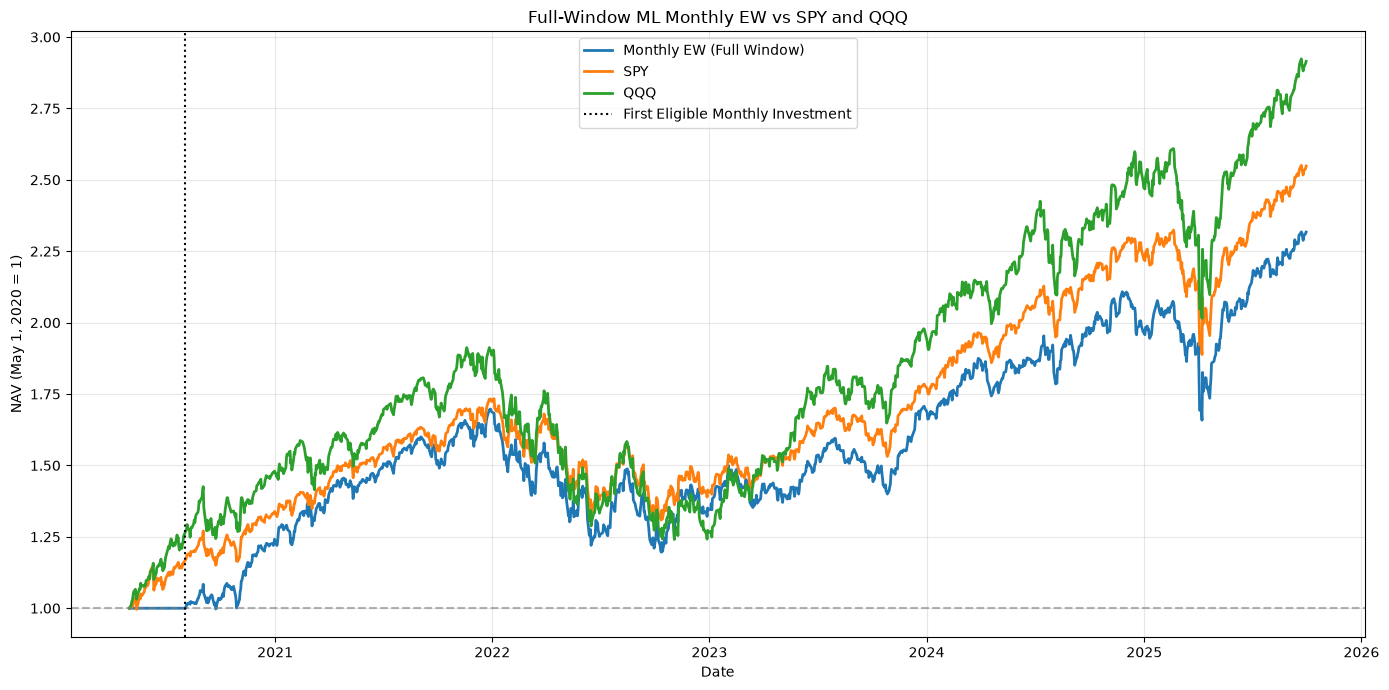


All full-window checks passed.
Cell 39B completed successfully.


In [41]:

# ============================================================
# Cell 39B - Full-Window Monthly EW with Cash Warm-Up
# 2020-05-01 to 2025-09-30
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FULL_START = pd.Timestamp("2020-05-01")
FULL_END = pd.Timestamp("2025-09-30")

Path("./results").mkdir(exist_ok=True)

# ------------------------------------------------------------
# 1. Full trading calendar
# ------------------------------------------------------------

full_dates = daily_returns.index[
    (daily_returns.index >= FULL_START)
    & (daily_returns.index <= FULL_END)
]

assert full_dates[0] == FULL_START
assert full_dates[-1] == FULL_END

original_first_date = matched_monthly_ew_weights.index.min()

# First trading day of each earlier month
earlier_dates = full_dates[
    full_dates < original_first_date
]

early_rebalances = earlier_dates[
    ~earlier_dates.to_period("M").duplicated()
]

# ------------------------------------------------------------
# 2. Check each early monthly rebalance
# ------------------------------------------------------------

early_weights = []
warmup_records = []

for trade_date in early_rebalances:

    pos = ml_prediction_dates.searchsorted(
        trade_date, side="left"
    ) - 1

    signal_date = pd.NaT
    n_selected = 0
    n_priced = 0
    n_eligible = 0
    status = "CASH"

    if pos >= 0:

        signal_date = pd.Timestamp(
            ml_prediction_dates[pos]
        )

        predictions = (
            prediction_snapshots[signal_date]
            .dropna()
        )

        selected = pd.Index(predictions.index)
        n_selected = len(selected)

        candidates = selected.intersection(
            daily_returns.columns
        )

        prices = close_prices.loc[
            trade_date, candidates
        ]

        valid_prices = (
            prices.notna()
            & np.isfinite(prices)
            & (prices > 0)
        )

        candidates = prices.index[valid_prices]
        n_priced = len(candidates)

        history = daily_returns.loc[
            daily_returns.index < trade_date
        ].tail(MVO_LOOKBACK)

        counts = history[candidates].count()

        tickers = counts.index[
            counts >= MVO_MIN_HISTORY
        ]

        n_eligible = len(tickers)

        if n_eligible >= MVO_MIN_STOCKS:

            if not tickers.isin(
                matched_monthly_ew_weights.columns
            ).all():
                raise ValueError(
                    "Early tickers missing from "
                    "the saved portfolio universe."
                )

            target = pd.Series(
                0.0,
                index=matched_monthly_ew_weights.columns,
                name=trade_date
            )

            target.loc[tickers] = 1.0 / n_eligible

            early_weights.append(target)

            status = "INVEST"

    warmup_records.append({
        "trade_date": trade_date,
        "signal_date": signal_date,
        "ml_selected": n_selected,
        "priced": n_priced,
        "eligible": n_eligible,
        "decision": status
    })

warmup_audit = pd.DataFrame(warmup_records)

# ------------------------------------------------------------
# 3. Extend portfolio target weights
# ------------------------------------------------------------

if not early_weights:
    raise ValueError(
        "No eligible early monthly rebalance found."
    )

early_weight_matrix = pd.DataFrame(
    early_weights
)

extended_monthly_weights = pd.concat([
    early_weight_matrix,
    matched_monthly_ew_weights
]).sort_index()

first_actual_trade = extended_monthly_weights.index[0]

assert first_actual_trade == pd.Timestamp("2020-08-03")

assert np.allclose(
    extended_monthly_weights.sum(axis=1),
    1.0
)

assert np.allclose(
    extended_monthly_weights.loc[
        matched_monthly_ew_weights.index
    ].to_numpy(),
    matched_monthly_ew_weights.to_numpy()
)

# ------------------------------------------------------------
# 4. Validate returns held through the first rebalance
# ------------------------------------------------------------

next_rebalance = extended_monthly_weights.index[1]

initial_held = extended_monthly_weights.columns[
    extended_monthly_weights.loc[first_actual_trade] > 0
]

holding_dates = full_dates[
    (full_dates > first_actual_trade)
    & (full_dates <= next_rebalance)
]

initial_holding_returns = daily_returns.reindex(
    index=holding_dates,
    columns=initial_held
)

if not np.isfinite(
    initial_holding_returns.to_numpy()
).all():

    bad_rows, bad_cols = np.where(
        ~np.isfinite(
            initial_holding_returns.to_numpy()
        )
    )

    problem_records = [
        {
            "date": holding_dates[i],
            "ticker": initial_held[j]
        }
        for i, j in zip(bad_rows, bad_cols)
    ]

    print("Invalid early holding returns:")
    print(pd.DataFrame(problem_records).head(20))

    raise ValueError(
        "Early holdings have incomplete daily returns."
    )

# ------------------------------------------------------------
# 5. Run existing buy-and-hold backtester
# ------------------------------------------------------------

extended_monthly_result = run_monthly_backtest(
    target_weights=extended_monthly_weights,
    daily_returns=daily_returns,
    fee_rate=FEE_RATE
)

# ------------------------------------------------------------
# 6. Add the initial cash holding period
# ------------------------------------------------------------

full_monthly_nav = pd.Series(
    1.0,
    index=full_dates,
    name="Monthly EW (Full Window)"
)

full_monthly_nav.loc[
    extended_monthly_result.index
] = extended_monthly_result["nav"].to_numpy()

cash_days = full_dates[
    full_dates < first_actual_trade
]

assert np.allclose(
    full_monthly_nav.loc[cash_days],
    1.0
)

assert np.isclose(
    extended_monthly_result.loc[
        first_actual_trade, "turnover"
    ],
    1.0
)

assert np.isclose(
    extended_monthly_result.loc[
        first_actual_trade, "nav"
    ],
    1.0 - FEE_RATE
)

# ------------------------------------------------------------
# 7. Full-window SPY and QQQ
# ------------------------------------------------------------

full_window_comparison = pd.DataFrame(
    index=full_dates
)

full_window_comparison[
    "Monthly EW (Full Window)"
] = full_monthly_nav

for ticker in ["SPY", "QQQ"]:

    benchmark = comparison_nav[
        ticker
    ].reindex(full_dates)

    if benchmark.isna().any():
        raise ValueError(
            f"Missing {ticker} benchmark dates."
        )

    full_window_comparison[ticker] = (
        benchmark / benchmark.iloc[0]
    )

# ------------------------------------------------------------
# 8. Performance comparison
# ------------------------------------------------------------

full_window_metrics = pd.DataFrame({
    name: monthly_performance_metrics(
        full_window_comparison[name]
    )
    for name in full_window_comparison.columns
}).T

full_window_metrics["Total Turnover"] = [
    extended_monthly_result["turnover"].sum(),
    np.nan,
    np.nan
]

full_window_metrics["Total Cost"] = [
    extended_monthly_result["cost"].sum(),
    np.nan,
    np.nan
]

print("=" * 75)
print("FULL-WINDOW MONTHLY EW WITH CASH WARM-UP")
print("=" * 75)

print("\nEarly Monthly Rebalance Decisions:")
print(warmup_audit.to_string(index=False))

print("\nFirst Invested Close:")
print(first_actual_trade.date())

print("\nPre-Investment Cash Days:")
print(len(cash_days))

print("\nTotal Rebalances:")
print(len(extended_monthly_weights))

print("\nFull-Window Performance Comparison:")
print(
    full_window_metrics.round(4).to_string()
)

print("\nRelative Final NAV:")

for ticker in ["SPY", "QQQ"]:

    relative = (
        full_window_comparison[
            "Monthly EW (Full Window)"
        ].iloc[-1]
        / full_window_comparison[ticker].iloc[-1]
        - 1.0
    ) * 100

    print(f"Monthly EW vs {ticker}: {relative:+.3f}%")

# ------------------------------------------------------------
# 9. Confirm September onward target weights
# ------------------------------------------------------------

print("\nExisting September-Onward Portfolio:")
print("Target weights: UNCHANGED")

print(
    "Original September-start NAV:",
    round(matched_ew_result["nav"].iloc[-1], 6)
)

print(
    "Full-window NAV:",
    round(full_monthly_nav.iloc[-1], 6)
)

print(
    "Note: The final NAVs include different start dates "
    "and different initial trading costs."
)

# ------------------------------------------------------------
# 10. Visualization
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

for name in full_window_comparison.columns:

    ax.plot(
        full_window_comparison.index,
        full_window_comparison[name],
        linewidth=2,
        label=name
    )

ax.axhline(
    1.0,
    color="gray",
    linestyle="--",
    alpha=0.6
)

ax.axvline(
    first_actual_trade,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="First Eligible Monthly Investment"
)

ax.set_title(
    "Full-Window ML Monthly EW vs SPY and QQQ"
)

ax.set_xlabel("Date")
ax.set_ylabel("NAV (May 1, 2020 = 1)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Final validations
# ------------------------------------------------------------

assert full_window_comparison.notna().all().all()

assert np.isfinite(
    full_window_comparison.to_numpy()
).all()

assert (full_window_comparison > 0).all().all()

assert np.isclose(
    full_monthly_nav.iloc[-1],
    extended_monthly_result["nav"].iloc[-1]
)

# ------------------------------------------------------------
# 12. Save
# ------------------------------------------------------------

warmup_audit.to_csv(
    "./results/full_window_warmup_audit.csv",
    index=False
)

extended_monthly_weights.to_csv(
    "./results/full_window_monthly_weights.csv"
)

full_window_comparison.to_csv(
    "./results/full_window_monthly_nav.csv"
)

full_window_metrics.to_csv(
    "./results/full_window_monthly_metrics.csv"
)

print("\nAll full-window checks passed.")
print("Cell 39B completed successfully.")


In [42]:

# ============================================================
# Cell 39C - Cash Warm-Up Performance Decomposition
# No changes to portfolio or backtest
# ============================================================

import numpy as np
import pandas as pd

nav = full_window_comparison.copy()

strategy_col = "Monthly EW (Full Window)"

start_date = nav.index[0]
entry_date = pd.Timestamp("2020-08-03")
end_date = nav.index[-1]

assert entry_date in nav.index
assert np.isclose(nav.loc[start_date, strategy_col], 1.0)

# ------------------------------------------------------------
# 1. Performance before first actual investment
# ------------------------------------------------------------

spy_before_entry = (
    nav.loc[entry_date, "SPY"]
    / nav.loc[start_date, "SPY"]
)

strategy_before_entry = (
    nav.loc[entry_date, strategy_col]
    / nav.loc[start_date, strategy_col]
)

# ------------------------------------------------------------
# 2. SPY bought at the same close as ML's first investment
# ------------------------------------------------------------

strategy_from_entry = (
    nav.loc[end_date, strategy_col]
    / nav.loc[start_date, strategy_col]
)

spy_from_entry = (
    nav.loc[end_date, "SPY"]
    / nav.loc[entry_date, "SPY"]
)

# Strategy includes initial buying cost.
# SPY benchmark remains before its own trading costs.

relative_from_entry = (
    strategy_from_entry / spy_from_entry
)

# ------------------------------------------------------------
# 3. Full-window performance
# ------------------------------------------------------------

strategy_full = (
    nav.loc[end_date, strategy_col]
    / nav.loc[start_date, strategy_col]
)

spy_full = (
    nav.loc[end_date, "SPY"]
    / nav.loc[start_date, "SPY"]
)

relative_full = strategy_full / spy_full

# ------------------------------------------------------------
# 4. Decompose full-window relative wealth
# ------------------------------------------------------------

warmup_relative_factor = (
    strategy_before_entry / spy_before_entry
)

# Entry comparison includes ML initial transaction cost.
# Remove that cost from the warm-up factor so that it is
# counted only once.

initial_fee_factor = float(
    nav.loc[entry_date, strategy_col]
)

post_entry_relative_factor = (
    relative_from_entry
)

warmup_cash_factor = (
    1.0 / spy_before_entry
)

reconstructed_full_relative = (
    warmup_cash_factor * post_entry_relative_factor
)

assert np.isclose(
    reconstructed_full_relative,
    relative_full,
    atol=1e-10
)

# ------------------------------------------------------------
# 5. Print diagnostics
# ------------------------------------------------------------

print("=" * 74)
print("FULL-WINDOW UNDERPERFORMANCE DECOMPOSITION")
print("=" * 74)

print("\nEvaluation Start:", start_date.date())
print("First ML Investment:", entry_date.date())
print("Evaluation End:", end_date.date())

print("\nA. Before ML First Investment:")
print(
    f"SPY cumulative return: "
    f"{(spy_before_entry - 1) * 100:+.3f}%"
)
print(
    f"ML portfolio (cash before trade): 0.000%"
)
print(
    f"Initial ML purchase cost: "
    f"{(initial_fee_factor - 1) * 100:.3f}%"
)

print("\nB. From First Investment Close to End:")
print(
    f"ML portfolio NAV (including first purchase fee): "
    f"{strategy_from_entry:.6f}"
)
print(
    f"SPY NAV from the same entry close: "
    f"{spy_from_entry:.6f}"
)
print(
    f"ML vs SPY: "
    f"{(relative_from_entry - 1) * 100:+.3f}%"
)

print("\nC. Full May 2020 Start:")
print(f"ML NAV: {strategy_full:.6f}")
print(f"SPY NAV: {spy_full:.6f}")
print(
    f"ML vs SPY: "
    f"{(relative_full - 1) * 100:+.3f}%"
)

print("\nD. Relative Wealth Decomposition:")
print(
    f"Cash warm-up relative factor: "
    f"{warmup_cash_factor:.6f}"
)
print(
    f"Post-entry relative factor: "
    f"{post_entry_relative_factor:.6f}"
)
print(
    f"Combined full-window factor: "
    f"{reconstructed_full_relative:.6f}"
)

print("\nReconciliation check passed.")
print("Cell 39C completed successfully.")


FULL-WINDOW UNDERPERFORMANCE DECOMPOSITION

Evaluation Start: 2020-05-01
First ML Investment: 2020-08-03
Evaluation End: 2025-09-30

A. Before ML First Investment:
SPY cumulative return: +16.778%
ML portfolio (cash before trade): 0.000%
Initial ML purchase cost: -0.100%

B. From First Investment Close to End:
ML portfolio NAV (including first purchase fee): 2.316987
SPY NAV from the same entry close: 2.182079
ML vs SPY: +6.183%

C. Full May 2020 Start:
ML NAV: 2.316987
SPY NAV: 2.548192
ML vs SPY: -9.073%

D. Relative Wealth Decomposition:
Cash warm-up relative factor: 0.856324
Post-entry relative factor: 1.061826
Combined full-window factor: 0.909267

Reconciliation check passed.
Cell 39C completed successfully.


SPY FALLBACK + ML MONTHLY EW

Backtest Period:
2020-05-01 to 2025-09-30

Fallback Phase:
SPY purchase: 2020-05-01
ML switch: 2020-08-03

SPY Return Before Switch (%):
16.7782

Trading Cost Accounting:
Initial SPY buy fee:  10.00 bps
SPY-to-ML switch fee: 20.00 bps
Total turnover:       25.2659
Total modeled cost:   0.025266

Performance Comparison:
                      Final NAV  Total Return (%)  CAGR (%)  Volatility (%)  Sharpe  Max Drawdown (%)  Total Turnover  Total Cost
SPY Fallback + ML EW     2.7003          170.0324   20.2095         19.9905  1.0218          -29.5172         25.2659      0.0253
Cash Warm-Up + ML EW     2.3170          131.6987   16.8472         19.4516  0.8977          -29.5172         23.2659      0.0233
SPY                      2.5482          154.8192   18.9248         17.5141  1.0774          -24.4964             NaN         NaN
QQQ                      2.9147          191.4663   21.9230         23.0018  0.9769          -35.1187             NaN         NaN

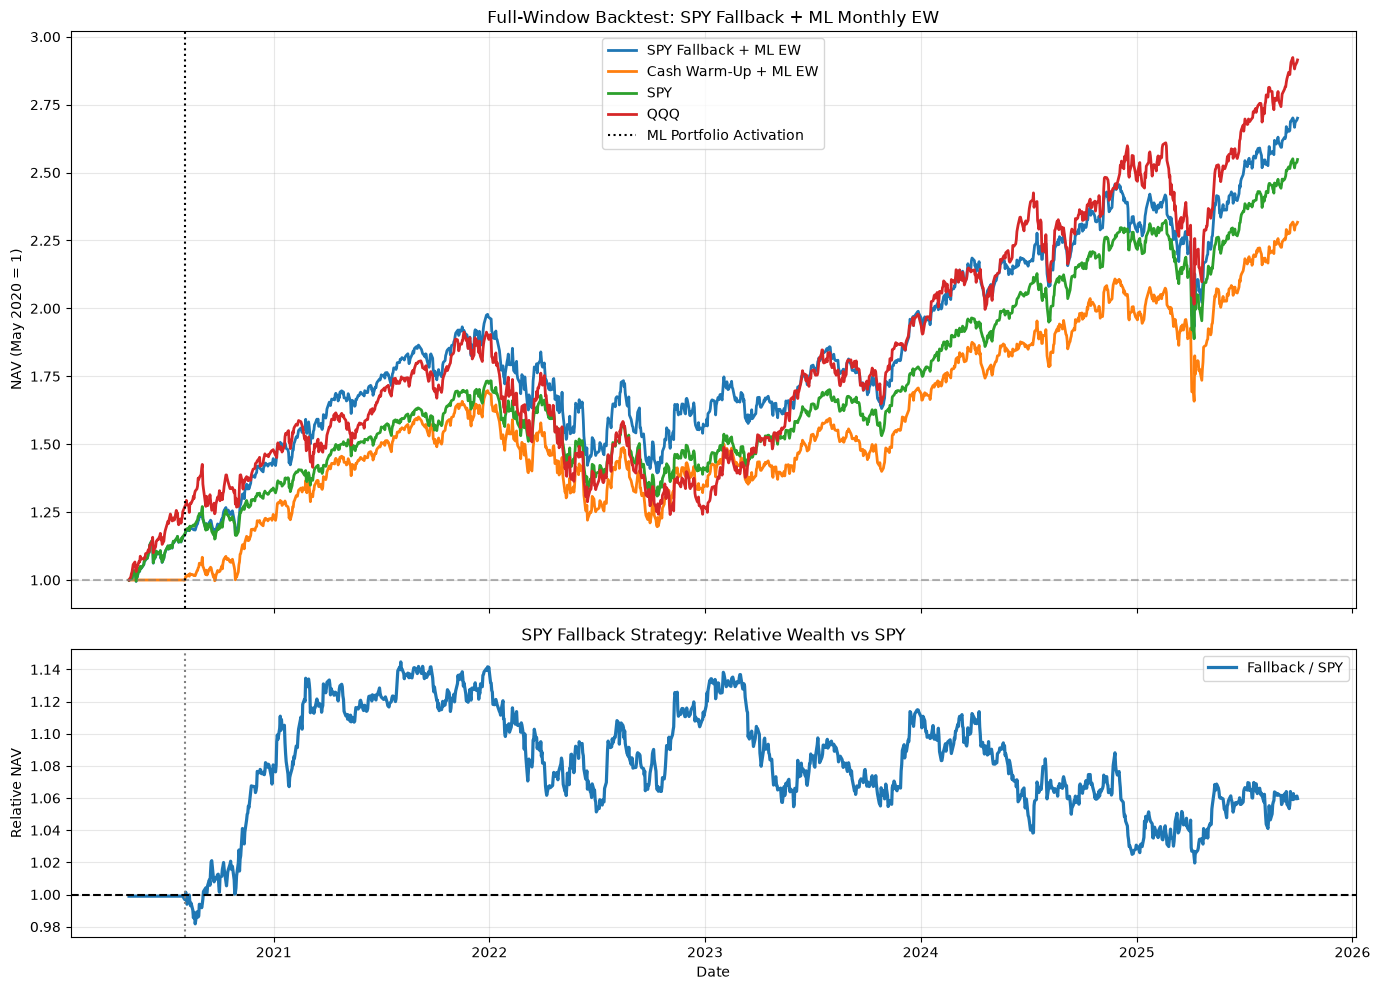


All fallback reconciliation checks passed.
Cell 39D completed successfully.


In [43]:

# ============================================================
# Cell 39D - Benchmark-Fallback ML Monthly EW
# SPY until sufficient ML stocks, then Monthly EW
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Inputs and alignment checks
# ------------------------------------------------------------

dates = full_window_comparison.index
entry_date = pd.Timestamp(first_actual_trade)
fee = float(FEE_RATE)

spy_nav = full_window_comparison["SPY"].copy()
qqq_nav = full_window_comparison["QQQ"].copy()

cash_ml_nav = full_window_comparison[
    "Monthly EW (Full Window)"
].copy()

ml_nav = extended_monthly_result["nav"].copy()

assert dates[0] == pd.Timestamp("2020-05-01")
assert dates[-1] == pd.Timestamp("2025-09-30")
assert entry_date == pd.Timestamp("2020-08-03")

assert ml_nav.index.equals(dates[dates >= entry_date])
assert np.isclose(ml_nav.loc[entry_date], 1 - fee)
assert np.isclose(spy_nav.iloc[0], 1.0)

# ------------------------------------------------------------
# 2. Initial SPY investment
# ------------------------------------------------------------

# Buy SPY on May 1 close.
# Initial SPY purchase: L1 turnover = 1.

spy_initial_fee_factor = 1.0 - fee

fallback_nav = pd.Series(
    np.nan,
    index=dates,
    name="SPY Fallback + ML EW"
)

before_switch = dates < entry_date

fallback_nav.loc[before_switch] = (
    spy_nav.loc[before_switch]
    * spy_initial_fee_factor
)

# ------------------------------------------------------------
# 3. Switch SPY -> ML at August 3 close
# ------------------------------------------------------------

# Sell 100% SPY, buy 100% ML:
# L1 turnover = 2.
#
# August 3 SPY close-to-close return is earned by
# the existing SPY position before the close trade.

switch_turnover = 2.0
switch_fee_factor = 1.0 - fee * switch_turnover

if switch_fee_factor <= 0:
    raise ValueError("Invalid switching fee.")

fallback_entry_nav = (
    spy_nav.loc[entry_date]
    * spy_initial_fee_factor
    * switch_fee_factor
)

# ------------------------------------------------------------
# 4. Continue the existing ML monthly portfolio
# ------------------------------------------------------------

# The original ML backtest charged an initial
# buy fee at its first trading date.
#
# Divide by that initial NAV to remove the duplicated
# initial buy fee: our switch already charges for
# both SPY liquidation and ML purchase.
#
# All subsequent ML trades and fees remain unchanged.

ml_entry_nav = float(ml_nav.loc[entry_date])

ml_growth_after_entry = (
    ml_nav / ml_entry_nav
)

fallback_nav.loc[entry_date:] = (
    fallback_entry_nav
    * ml_growth_after_entry
)

# ------------------------------------------------------------
# 5. Compare with original cash-start strategy
# ------------------------------------------------------------

fallback_comparison = pd.DataFrame({
    "SPY Fallback + ML EW": fallback_nav,
    "Cash Warm-Up + ML EW": cash_ml_nav,
    "SPY": spy_nav,
    "QQQ": qqq_nav
}, index=dates)

assert fallback_comparison.notna().all().all()
assert np.isfinite(fallback_comparison.to_numpy()).all()
assert (fallback_comparison > 0).all().all()

# ------------------------------------------------------------
# 6. Reconciliation checks
# ------------------------------------------------------------

expected_first_day = 1.0 - fee

assert np.isclose(
    fallback_nav.iloc[0],
    expected_first_day
)

assert np.isclose(
    fallback_nav.loc[entry_date],
    fallback_entry_nav
)

assert np.allclose(
    (
        fallback_nav.loc[entry_date:]
        / fallback_entry_nav
    ).to_numpy(),
    ml_growth_after_entry.to_numpy(),
    atol=1e-10
)

# Exact terminal NAV construction
expected_final_nav = (
    spy_nav.loc[entry_date]
    * (1 - fee)
    * (1 - 2 * fee)
    * ml_nav.iloc[-1]
    / ml_entry_nav
)

assert np.isclose(
    fallback_nav.iloc[-1],
    expected_final_nav,
    atol=1e-10
)

# ------------------------------------------------------------
# 7. Performance metrics
# ------------------------------------------------------------

fallback_metrics = pd.DataFrame({
    name: monthly_performance_metrics(
        fallback_comparison[name]
    )
    for name in fallback_comparison.columns
}).T

# The old ML turnover includes an initial cash-to-ML
# purchase with L1 turnover 1.
#
# Fallback instead has:
#   Initial cash-to-SPY: L1 = 1
#   SPY-to-ML switch:    L1 = 2
#   Subsequent ML trades: unchanged

original_ml_turnover = float(
    extended_monthly_result["turnover"].sum()
)

original_initial_turnover = float(
    extended_monthly_result.loc[
        entry_date, "turnover"
    ]
)

fallback_turnover = (
    original_ml_turnover
    - original_initial_turnover
    + 1.0
    + 2.0
)

fallback_total_cost = fallback_turnover * fee

fallback_metrics["Total Turnover"] = [
    fallback_turnover,
    original_ml_turnover,
    np.nan,
    np.nan
]

fallback_metrics["Total Cost"] = [
    fallback_total_cost,
    float(extended_monthly_result["cost"].sum()),
    np.nan,
    np.nan
]

# ------------------------------------------------------------
# 8. Print main results
# ------------------------------------------------------------

print("=" * 78)
print("SPY FALLBACK + ML MONTHLY EW")
print("=" * 78)

print("\nBacktest Period:")
print(dates[0].date(), "to", dates[-1].date())

print("\nFallback Phase:")
print("SPY purchase:", dates[0].date())
print("ML switch:", entry_date.date())

print("\nSPY Return Before Switch (%):")
print(round((spy_nav.loc[entry_date] - 1) * 100, 4))

print("\nTrading Cost Accounting:")
print(f"Initial SPY buy fee:  {fee * 10000:.2f} bps")
print(f"SPY-to-ML switch fee: {2 * fee * 10000:.2f} bps")
print(f"Total turnover:       {fallback_turnover:.4f}")
print(f"Total modeled cost:   {fallback_total_cost:.6f}")

print("\nPerformance Comparison:")
print(
    fallback_metrics.round(4).to_string()
)

print("\nRelative Final NAV:")

for benchmark in [
    "Cash Warm-Up + ML EW",
    "SPY",
    "QQQ"
]:

    relative = (
        fallback_nav.iloc[-1]
        / fallback_comparison[benchmark].iloc[-1]
        - 1.0
    ) * 100

    print(
        f"Fallback vs {benchmark}: "
        f"{relative:+.3f}%"
    )

# ------------------------------------------------------------
# 9. Plot NAV and SPY-relative wealth
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 10),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

for name in fallback_comparison.columns:

    axes[0].plot(
        fallback_comparison.index,
        fallback_comparison[name],
        linewidth=2,
        label=name
    )

axes[0].axhline(
    1.0,
    linestyle="--",
    color="gray",
    alpha=0.6
)

axes[0].axvline(
    entry_date,
    linestyle=":",
    color="black",
    label="ML Portfolio Activation"
)

axes[0].set_title(
    "Full-Window Backtest: SPY Fallback + ML Monthly EW"
)

axes[0].set_ylabel("NAV (May 2020 = 1)")
axes[0].legend()
axes[0].grid(alpha=0.3)

relative_wealth = (
    fallback_comparison["SPY Fallback + ML EW"]
    / fallback_comparison["SPY"]
)

axes[1].plot(
    relative_wealth.index,
    relative_wealth,
    linewidth=2.3,
    label="Fallback / SPY"
)

axes[1].axhline(
    1.0,
    linestyle="--",
    color="black"
)

axes[1].axvline(
    entry_date,
    linestyle=":",
    color="gray"
)

axes[1].set_title(
    "SPY Fallback Strategy: Relative Wealth vs SPY"
)

axes[1].set_xlabel("Date")
axes[1].set_ylabel("Relative NAV")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Save results
# ------------------------------------------------------------

Path("./results").mkdir(exist_ok=True)

fallback_comparison.to_csv(
    "./results/spy_fallback_full_window_nav.csv"
)

fallback_metrics.to_csv(
    "./results/spy_fallback_full_window_metrics.csv"
)

print("\nAll fallback reconciliation checks passed.")
print("Cell 39D completed successfully.")


## Timing and Historical Membership Audits

Cells 40–42 inspect signal timestamps and independently reconstruct the original S&P 500 membership filter from source data. Historical membership reproduction passes, while some upstream signal-timing flags remain unresolved and are discussed in the report. The audits require adjacent raw data files and `prepare_data.py`.


In [44]:

# ============================================================
# Cell 40 - Original ML Model and Signal Timing Audit
# Read only: no retraining, no downloads, no strategy changes
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

audit_rows = []
audit_issues = []

# ------------------------------------------------------------
# 1. Inspect original sector datasets and model windows
# ------------------------------------------------------------

for sector in sorted(model_selection_details["sector"].unique()):

    sector = int(sector)
    path = Path(f"./prepared/sector{sector}.xlsx")

    if not path.exists():
        audit_issues.append(
            f"Missing sector file: {path}"
        )
        continue

    data = pd.read_excel(
        path,
        usecols=["tic", "date", "reportdate", "y_return"]
    )

    data["date"] = pd.to_datetime(
        data["date"], errors="coerce"
    )

    data["reportdate"] = pd.to_datetime(
        data["reportdate"].replace(0, np.nan),
        errors="coerce"
    )

    data["y_return"] = pd.to_numeric(
        data["y_return"], errors="coerce"
    )

    quarter_dates = pd.DatetimeIndex(
        sorted(data["date"].dropna().unique())
    )

    windows = model_selection_details.loc[
        model_selection_details["sector"] == sector
    ]

    for _, window in windows.iterrows():

        model_quarter = pd.Timestamp(
            window["trade_date"]
        )

        if model_quarter not in quarter_dates:
            audit_issues.append(
                f"Sector {sector}: unmatched {model_quarter.date()}"
            )
            continue

        i = quarter_dates.get_loc(model_quarter)

        if i < 4:
            audit_issues.append(
                f"Sector {sector}: insufficient quarterly history"
            )
            continue

        # Original prepare_rolling_test:
        # quarter_dates[i-4] <= date < quarter_dates[i]
        validation = data.loc[
            (data["date"] >= quarter_dates[i-4])
            & (data["date"] < model_quarter)
        ].copy()

        # Original prepare_trade_data:
        # date == quarter_dates[i]
        forecast = data.loc[
            data["date"] == model_quarter
        ].copy()

        forecast = forecast.dropna(
            subset=["reportdate"]
        )

        if validation.empty or forecast.empty:
            audit_issues.append(
                f"Sector {sector}: empty window "
                f"{model_quarter.date()}"
            )
            continue

        first_forecast_date = forecast["reportdate"].min()
        last_forecast_date = forecast["reportdate"].max()

        last_validation_quarter = (
            validation["date"].max()
        )

        last_validation_report = (
            validation["reportdate"].max()
        )

        # Records whose predicted availability date
        # precedes the current nominal quarter end.
        early_forecasts = (
            forecast["reportdate"] < model_quarter
        )

        # Validation records whose filing dates occurred
        # after the earliest current-quarter forecast date.
        late_validation_filings = (
            validation["reportdate"] > first_forecast_date
        )

        # IMPORTANT:
        # y_return is described as a forward-quarter return.
        # The next-quarter realization date requires
        # separate verification against preprocessing code.
        #
        # Treat this as a possible timing conflict,
        # NOT as definitive proof of information leakage.
        forward_label_timing_flag = bool(
            first_forecast_date < model_quarter
            and validation.loc[
                validation["date"] == last_validation_quarter,
                "y_return"
            ].notna().any()
        )

        audit_rows.append({
            "sector": sector,
            "model_quarter": model_quarter,
            "validation_start": validation["date"].min(),
            "validation_end": last_validation_quarter,
            "first_forecast_reportdate": first_forecast_date,
            "last_forecast_reportdate": last_forecast_date,
            "last_validation_reportdate": last_validation_report,
            "n_forecast_records": len(forecast),
            "n_early_forecast_records": int(
                early_forecasts.sum()
            ),
            "early_forecast_pct": (
                early_forecasts.mean() * 100
            ),
            "n_late_validation_filings": int(
                late_validation_filings.sum()
            ),
            "validation_filing_overlap": bool(
                late_validation_filings.any()
            ),
            "forward_label_timing_flag": (
                forward_label_timing_flag
            ),
            "days_first_forecast_before_quarter_end": (
                model_quarter - first_forecast_date
            ).days
        })

# ------------------------------------------------------------
# 2. Assemble timing audit
# ------------------------------------------------------------

model_timing_audit = pd.DataFrame(audit_rows)

if model_timing_audit.empty:
    raise ValueError(
        "No model windows could be audited."
    )

model_timing_audit = model_timing_audit.sort_values(
    ["sector", "model_quarter"]
).reset_index(drop=True)

print("=" * 80)
print("ORIGINAL ML MODEL / SIGNAL TIMING AUDIT")
print("=" * 80)

print("\nOriginal Model Windows:")
print(len(model_selection_details))

print("\nAudited Model Windows:")
print(len(model_timing_audit))

print("\nData Issues:")
if audit_issues:
    for issue in audit_issues[:20]:
        print(issue)
else:
    print("None")

# ------------------------------------------------------------
# 3. Overall timing risks
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("TIMING FLAGS")
print("=" * 80)

print("\nWindows With Predictions Before Nominal Quarter End:")
print(
    int(
        (model_timing_audit["n_early_forecast_records"] > 0)
        .sum()
    )
)

print("\nTotal Predictions Dated Before Nominal Quarter End:")
print(
    int(
        model_timing_audit["n_early_forecast_records"].sum()
    )
)

print("\nWindows With Validation Filing Overlap:")
print(
    int(
        model_timing_audit["validation_filing_overlap"].sum()
    )
)

print("\nWindows Flagged for Forward-Label Timing Review:")
print(
    int(
        model_timing_audit["forward_label_timing_flag"].sum()
    )
)

print("\nFirst Forecast vs Quarter End (Days):")
print(
    model_timing_audit[
        "days_first_forecast_before_quarter_end"
    ].describe().round(2).to_string()
)

# ------------------------------------------------------------
# 4. Timing flags by sector
# ------------------------------------------------------------

sector_summary = (
    model_timing_audit
    .groupby("sector")
    .agg(
        Windows=("model_quarter", "size"),
        Early_Forecast_Windows=(
            "n_early_forecast_records",
            lambda x: int((x > 0).sum())
        ),
        Mean_Early_Forecast_Pct=(
            "early_forecast_pct", "mean"
        ),
        Validation_Filing_Overlap=(
            "validation_filing_overlap", "sum"
        ),
        Forward_Label_Flags=(
            "forward_label_timing_flag", "sum"
        )
    )
)

print("\n" + "=" * 80)
print("TIMING AUDIT BY SECTOR")
print("=" * 80)

print(
    sector_summary.round(3).to_string()
)

# ------------------------------------------------------------
# 5. Detailed representative window
# ------------------------------------------------------------

example = model_timing_audit.loc[
    (model_timing_audit["sector"] == 45)
    & (
        model_timing_audit["model_quarter"]
        == pd.Timestamp("2023-09-30")
    )
]

print("\n" + "=" * 80)
print("SECTOR 45 - 2023-09-30 EXAMPLE")
print("=" * 80)

if not example.empty:
    print(example.T.to_string(header=False))
else:
    print("Representative window unavailable.")

# ------------------------------------------------------------
# 6. Earliest prediction dates
# ------------------------------------------------------------

print("\nFirst 15 Audited Windows:")
print(
    model_timing_audit[
        [
            "sector",
            "model_quarter",
            "validation_end",
            "first_forecast_reportdate",
            "early_forecast_pct",
            "validation_filing_overlap",
            "forward_label_timing_flag"
        ]
    ].sort_values(
        ["model_quarter", "sector"]
    ).head(15).to_string(index=False)
)

# ------------------------------------------------------------
# 7. Save
# ------------------------------------------------------------

Path("./results").mkdir(exist_ok=True)

model_timing_audit.to_csv(
    "./results/original_model_timing_audit.csv",
    index=False
)

sector_summary.to_csv(
    "./results/original_model_timing_by_sector.csv"
)

print("\nAudit files saved.")

if len(model_timing_audit) != len(model_selection_details):
    print(
        "\nWARNING: Some model windows were not audited."
    )

if model_timing_audit["forward_label_timing_flag"].any():
    print(
        "\nWARNING: Potential forward-label timing conflicts "
        "require verification of the y_return construction."
    )

print(
    "\nFlags indicate issues to investigate, "
    "not automatically confirmed look-ahead bias."
)

print("\nCell 40 completed successfully.")


ORIGINAL ML MODEL / SIGNAL TIMING AUDIT

Original Model Windows:
238

Audited Model Windows:
238

Data Issues:
None

TIMING FLAGS

Windows With Predictions Before Nominal Quarter End:
124

Total Predictions Dated Before Nominal Quarter End:
1230

Windows With Validation Filing Overlap:
96

Windows Flagged for Forward-Label Timing Review:
124

First Forecast vs Quarter End (Days):
count    238.00
mean      16.84
std       35.87
min      -39.00
25%      -21.00
50%       29.50
75%       50.00
max       89.00

TIMING AUDIT BY SECTOR
        Windows  Early_Forecast_Windows  Mean_Early_Forecast_Pct  Validation_Filing_Overlap  Forward_Label_Flags
sector                                                                                                          
10           22                       0                    0.000                          1                    0
15           21                       9                    2.077                          1                    9
20           

In [45]:

# ============================================================
# Cell 41 - Point-in-Time Data Preparation Audit
# No retraining, no downloads, no file modification
# ============================================================

from pathlib import Path
import pandas as pd
import ast

ROOT = Path.cwd()

PREPARE_SCRIPT = ROOT / "prepare_data.py"
PREPARED_FILE = ROOT / "prepared" / "final_ratios.csv"

# Set these explicitly only if automatic discovery fails.
RAW_FUNDAMENTALS_PATH = None
CONSTITUENTS_PATH = None

print("=" * 78)
print("POINT-IN-TIME S&P 500 DATA PREPARATION AUDIT")
print("=" * 78)

print("\nWorking Directory:", ROOT)

# ------------------------------------------------------------
# 1. Verify preparation script and prepared data
# ------------------------------------------------------------

if not PREPARE_SCRIPT.exists():
    raise FileNotFoundError(PREPARE_SCRIPT)

if not PREPARED_FILE.exists():
    raise FileNotFoundError(PREPARED_FILE)

prepared = pd.read_csv(PREPARED_FILE)

print("\nPrepared Fundamental Dataset:")
print("Rows:", len(prepared))
print("Unique Stocks:", prepared["tic"].nunique())

print("\nAvailable Date Columns:")
print([
    c for c in prepared.columns
    if "date" in c.lower()
])

print("\nExpected README Reference:")
print("Rows: 19007")
print("Unique Stocks: 674")

print("\nReference Row Count Matches:",
      len(prepared) == 19007)

print("Reference Ticker Count Matches:",
      prepared["tic"].nunique() == 674)

# ------------------------------------------------------------
# 2. Locate original source files
# ------------------------------------------------------------

search_roots = [
    ROOT,
    ROOT.parent,
    ROOT.parent.parent
]

relative_dirs = [
    Path("."),
    Path("data"),
    Path("FinRL-Trading/data"),
    Path("FinRL-Trading") / "data",
    Path("source_code/data"),
    Path("dataset")
]

def locate_file(filename, manual_path=None):

    if manual_path is not None:
        path = Path(manual_path).expanduser()
        return path if path.is_file() else None

    checked = set()

    for base in search_roots:
        for rel in relative_dirs:

            candidate = (base / rel / filename).resolve()

            if candidate in checked:
                continue

            checked.add(candidate)

            if candidate.is_file():
                return candidate

    return None

raw_path = locate_file(
    "fundamental_data_full.csv",
    RAW_FUNDAMENTALS_PATH
)

members_path = locate_file(
    "sp500_historical_constituents.csv",
    CONSTITUENTS_PATH
)

print("\nOriginal Input File Locations:")

print(
    "Raw fundamentals:",
    raw_path if raw_path else "NOT FOUND"
)

print(
    "Historical constituents:",
    members_path if members_path else "NOT FOUND"
)

# ------------------------------------------------------------
# 3. Inspect source file schemas
# ------------------------------------------------------------

if raw_path is not None:

    raw_preview = pd.read_csv(raw_path, nrows=5)

    print("\nRaw Fundamental Columns:")
    print(raw_preview.columns.tolist())

    print("\nRaw Fundamental Preview:")
    print(raw_preview.head(3).to_string(index=False))

if members_path is not None:

    members_preview = pd.read_csv(
        members_path, nrows=5
    )

    print("\nHistorical Constituents Columns:")
    print(members_preview.columns.tolist())

    print("\nHistorical Constituents Preview:")
    print(members_preview.to_string(index=False))

# ------------------------------------------------------------
# 4. Inspect original preparation script
# ------------------------------------------------------------

source = PREPARE_SCRIPT.read_text(
    encoding="utf-8",
    errors="replace"
)

lines = source.splitlines()

tree = ast.parse(source)

print("\n" + "=" * 78)
print("DATA PREPARATION FUNCTION INVENTORY")
print("=" * 78)

functions = [
    node
    for node in ast.walk(tree)
    if isinstance(
        node,
        (ast.FunctionDef, ast.AsyncFunctionDef)
    )
]

for node in sorted(
    functions,
    key=lambda n: n.lineno
):

    print(
        f"Line {node.lineno:4d}: "
        f"{node.name}()"
    )

# ------------------------------------------------------------
# 5. Find membership filter implementation
# ------------------------------------------------------------

keywords = [
    "constituent",
    "membership",
    "member_of",
    "historical_sp",
    "survivor",
    "isin(",
    "merge_asof",
    "effective_date",
    "start_date",
    "end_date"
]

matched_lines = []

for i, line in enumerate(lines):

    line_lower = line.lower()

    if any(
        keyword in line_lower
        for keyword in keywords
    ):
        matched_lines.append(i)

# Combine nearby snippets to avoid duplicated output
intervals = []

for i in matched_lines:

    start = max(0, i - 3)
    end = min(len(lines), i + 6)

    if intervals and start <= intervals[-1][1]:
        intervals[-1] = (
            intervals[-1][0],
            max(intervals[-1][1], end)
        )
    else:
        intervals.append((start, end))

print("\n" + "=" * 78)
print("HISTORICAL MEMBERSHIP FILTER CODE")
print("=" * 78)

if not intervals:

    print("No obvious membership-related code found.")

else:

    for start, end in intervals:

        print(f"\n--- Script lines {start+1}-{end} ---")

        for j in range(start, end):
            print(f"{j+1:4d}: {lines[j]}")

# ------------------------------------------------------------
# 6. Prepared dataset integrity checks
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("PREPARED DATASET INTEGRITY")
print("=" * 78)

assert prepared["tic"].notna().all()

date_col = (
    "date" if "date" in prepared.columns
    else "datadate" if "datadate" in prepared.columns
    else None
)

if date_col:

    prepared_dates = pd.to_datetime(
        prepared[date_col],
        errors="coerce"
    )

    print("\nQuarter Date Range:")
    print(prepared_dates.min())
    print(prepared_dates.max())

    print("\nInvalid Quarter Dates:")
    print(prepared_dates.isna().sum())

    print("\nDuplicate Ticker + Quarter:")
    print(
        prepared.duplicated(
            ["tic", date_col]
        ).sum()
    )

if "reportdate" in prepared.columns:

    report_dates = pd.to_datetime(
        prepared["reportdate"],
        errors="coerce"
    )

    print("\nFiling Date Range:")
    print(report_dates.min())
    print(report_dates.max())

    print("\nMissing or Invalid Filing Dates:")
    print(report_dates.isna().sum())

# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("AUDIT SUMMARY")
print("=" * 78)

print("prepare_data.py located:", PREPARE_SCRIPT.exists())
print("Prepared output located:", PREPARED_FILE.exists())
print("Raw fundamentals located:", raw_path is not None)
print("Historical members located:", members_path is not None)

print(
    "\nMatching final dataset counts does not alone "
    "prove point-in-time membership correctness."
)

print(
    "Cell 41 completed. "
    "No original data or model files were changed."
)


POINT-IN-TIME S&P 500 DATA PREPARATION AUDIT

Working Directory: c:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\source_code

Prepared Fundamental Dataset:
Rows: 19007
Unique Stocks: 674

Available Date Columns:
['date', 'reportdate']

Expected README Reference:
Rows: 19007
Unique Stocks: 674

Reference Row Count Matches: True
Reference Ticker Count Matches: True

Original Input File Locations:
Raw fundamentals: C:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\data\fundamental_data_full.csv
Historical constituents: C:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\data\sp500_historical_constituents.csv

Raw Fundamental Columns:
['id', 'ticker', 'datadate', 'gsector', 'adj_close_q', 'EPS', 'BPS', 'DPS', 'cur_ratio', 'quick_ratio', 'cash_ratio', 'acc_rec_turnover', 'debt_ratio', 'debt_to_equity', 'pe', 'ps', 'pb', 'roe', 'net_income_ratio', 'y_return', 'created_at', 'gross_margin', 'operating_margin', 'ebitda_margin', 'pretax_margin', 'effective_tax_rate', 'ebt_per_ebit', 'asset_tu

In [46]:

# ============================================================
# Cell 42 - Reproduce Historical S&P 500 PIT Filtering
# No model training, downloads, or data modification
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
import prepare_data as prep

ROOT = Path.cwd()
DATA_DIR = ROOT.parent / "data"
OUTPUT_DIR = ROOT / "results"

RAW_PATH = DATA_DIR / "fundamental_data_full.csv"
MEMBERS_PATH = DATA_DIR / "sp500_historical_constituents.csv"
PREPARED_PATH = ROOT / "prepared" / "final_ratios.csv"

START = pd.Timestamp("2015-01-01")
END = pd.Timestamp("2025-09-30")

OUTPUT_DIR.mkdir(exist_ok=True)

for p in [RAW_PATH, MEMBERS_PATH, PREPARED_PATH]:
    if not p.is_file():
        raise FileNotFoundError(p)

print("=" * 78)
print("HISTORICAL S&P 500 MEMBERSHIP REPRODUCTION")
print("=" * 78)

# ------------------------------------------------------------
# 1. Reproduce the original preparation functions
# ------------------------------------------------------------

raw_loaded = prep.load_fundamentals(
    str(RAW_PATH), START, END
)

pit_filtered = prep.apply_pit_membership(
    raw_loaded.copy(),
    str(MEMBERS_PATH)
)

reproduced = prep.clean_features(
    pit_filtered.copy()
)

reproduced = (
    reproduced
    .sort_values(["tic", "date"])
    .reset_index(drop=True)
)

saved = (
    pd.read_csv(PREPARED_PATH)
    .sort_values(["tic", "date"])
    .reset_index(drop=True)
)

print("\nOriginal Data After Initial Loading:")
print("Rows:", len(raw_loaded))
print("Stocks:", raw_loaded["tic"].nunique())

print("\nAfter Historical Membership Filtering:")
print("Rows:", len(pit_filtered))
print("Stocks:", pit_filtered["tic"].nunique())

print("\nReproduced Final Dataset:")
print("Shape:", reproduced.shape)

print("\nExisting Prepared Dataset:")
print("Shape:", saved.shape)

# ------------------------------------------------------------
# 2. Independent membership snapshot verification
# ------------------------------------------------------------

members = pd.read_csv(MEMBERS_PATH)

members["date"] = pd.to_datetime(
    members["date"], errors="coerce"
)

assert members["date"].notna().all()

members = (
    members.sort_values("date")
    .reset_index(drop=True)
)

assert not members["date"].duplicated().any()

member_dates = members["date"].to_numpy(
    dtype="datetime64[ns]"
)

member_sets = [
    set(str(x).split(","))
    for x in members["tickers"]
]

def check_historical_membership(frame):

    dates = pd.to_datetime(
        frame["date"], errors="coerce"
    ).to_numpy(dtype="datetime64[ns]")

    tickers = frame["tic"].astype(str).to_numpy()

    indices = np.searchsorted(
        member_dates,
        dates,
        side="right"
    ) - 1

    is_member = np.fromiter(
        (
            i >= 0 and tic in member_sets[i]
            for tic, i in zip(tickers, indices)
        ),
        dtype=bool,
        count=len(frame)
    )

    return is_member, indices

raw_is_member, raw_snapshot_idx = (
    check_historical_membership(raw_loaded)
)

pit_is_member, pit_snapshot_idx = (
    check_historical_membership(pit_filtered)
)

saved_is_member, saved_snapshot_idx = (
    check_historical_membership(saved)
)

print("\n" + "=" * 78)
print("INDEPENDENT POINT-IN-TIME MEMBERSHIP CHECK")
print("=" * 78)

print("\nOriginal Rows Satisfying Historical Membership:")
print(int(raw_is_member.sum()))

print("\nRows Rejected by Historical Membership:")
print(int((~raw_is_member).sum()))

print("\nViolations in Filtered Dataset:")
print(int((~pit_is_member).sum()))

print("\nViolations in Saved Dataset:")
print(int((~saved_is_member).sum()))

# ------------------------------------------------------------
# 3. Verify the actual retained rows
# ------------------------------------------------------------

raw_keys = pd.MultiIndex.from_frame(
    raw_loaded[["tic", "date"]]
)

pit_keys = pd.MultiIndex.from_frame(
    pit_filtered[["tic", "date"]]
)

raw_retain_keys = raw_keys[raw_is_member]

# Compare multisets, not just unique keys
expected_key_counts = (
    pd.Series(
        list(raw_retain_keys),
        dtype="object"
    ).value_counts()
)

actual_key_counts = (
    pd.Series(
        list(pit_keys),
        dtype="object"
    ).value_counts()
)

keys_match = expected_key_counts.sort_index().equals(
    actual_key_counts.sort_index()
)

print("\nRetained Ticker-Date Records Match:")
print(keys_match)

# ------------------------------------------------------------
# 4. Compare full reproduced and saved datasets
# ------------------------------------------------------------

columns_match = (
    set(reproduced.columns) == set(saved.columns)
)

print("\nFinal Dataset Columns Match:")
print(columns_match)

missing_columns = sorted(
    set(reproduced.columns) - set(saved.columns)
)

extra_columns = sorted(
    set(saved.columns) - set(reproduced.columns)
)

if missing_columns or extra_columns:
    print("Missing columns:", missing_columns)
    print("Extra columns:", extra_columns)

row_count_match = len(reproduced) == len(saved)

full_content_match = False

if columns_match and row_count_match:

    # Normalize the two date fields before comparison
    for df in [reproduced, saved]:
        for col in ["date", "reportdate"]:
            if col in df.columns:
                df[col] = pd.to_datetime(
                    df[col], errors="coerce"
                )

    try:

        pd.testing.assert_frame_equal(
            reproduced[saved.columns],
            saved,
            check_dtype=False,
            check_exact=False,
            rtol=1e-9,
            atol=1e-9
        )

        full_content_match = True

    except AssertionError as e:

        print("\nDataset Content Difference:")
        print(str(e)[:1200])

print("\nFull Dataset Content Match:")
print(full_content_match)

# ------------------------------------------------------------
# 5. Examine excluded stocks and records
# ------------------------------------------------------------

excluded = raw_loaded.loc[
    ~raw_is_member
].copy()

removed_tickers = sorted(
    set(raw_loaded["tic"])
    - set(pit_filtered["tic"])
)

print("\n" + "=" * 78)
print("MEMBERSHIP FILTER IMPACT")
print("=" * 78)

print("\nTotal Excluded Records:")
print(len(excluded))

print("\nTickers Entirely Removed:")
print(len(removed_tickers))
print(removed_tickers[:40])

if not excluded.empty:

    excluded["year"] = pd.to_datetime(
        excluded["date"]
    ).dt.year

    print("\nExcluded Records by Year:")
    print(
        excluded.groupby("year")
        .size()
        .to_string()
    )

    print("\nTop 20 Tickers by Excluded Records:")
    print(
        excluded["tic"]
        .value_counts()
        .head(20)
        .to_string()
    )

# ------------------------------------------------------------
# 6. Check snapshot timing
# ------------------------------------------------------------

pit_dates = pd.to_datetime(
    pit_filtered["date"]
)

used_snapshot_dates = pd.to_datetime(
    member_dates[pit_snapshot_idx]
)

snapshot_age = (
    pit_dates.to_numpy(dtype="datetime64[ns]")
    - used_snapshot_dates.to_numpy(
        dtype="datetime64[ns]"
    )
) / np.timedelta64(1, "D")

print("\nMembership Snapshot Age (Days):")
print(
    pd.Series(snapshot_age)
    .describe().round(2).to_string()
)

print("\nNegative Snapshot Ages:")
print(int((snapshot_age < 0).sum()))

# ------------------------------------------------------------
# 7. Record audit results
# ------------------------------------------------------------

audit_summary = pd.DataFrame([{
    "Rows Before PIT": len(raw_loaded),
    "Rows After PIT": len(pit_filtered),
    "Rows Excluded": len(excluded),
    "Tickers Before PIT": raw_loaded["tic"].nunique(),
    "Tickers After PIT": pit_filtered["tic"].nunique(),
    "Tickers Entirely Removed": len(removed_tickers),
    "Saved Membership Violations": int(
        (~saved_is_member).sum()
    ),
    "Retained Keys Match": keys_match,
    "Columns Match": columns_match,
    "Full Content Match": full_content_match
}])

print("\n" + "=" * 78)
print("FINAL PIT REPRODUCTION SUMMARY")
print("=" * 78)

print(audit_summary.to_string(index=False))

audit_summary.to_csv(
    OUTPUT_DIR / "pit_membership_reproduction_audit.csv",
    index=False
)

excluded.to_csv(
    OUTPUT_DIR / "pit_membership_excluded_records.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Final validations
# ------------------------------------------------------------

assert raw_is_member.sum() == len(pit_filtered)

assert pit_is_member.all()
assert saved_is_member.all()

assert keys_match
assert columns_match
assert full_content_match

assert (snapshot_age >= 0).all()

print("\nAll PIT membership reproduction checks passed.")
print("Cell 42 completed successfully.")


HISTORICAL S&P 500 MEMBERSHIP REPRODUCTION
Reading fundamentals: c:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\data\fundamental_data_full.csv
  raw: 22,909 rows x 64 columns
  43 rows had no filing date -> quarter end + 45 days
  dropped 1,591 rows with no y_return label
  after 2015-01-01..2025-09-30: 21,299 rows
Applying point-in-time S&P 500 membership: c:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\data\sp500_historical_constituents.csv
  kept 19,007 of 21,299 rows (674 tickers, 692 before)
  cleaned 0 inf and 1,444 NaN values across 52 features

Original Data After Initial Loading:
Rows: 21299
Stocks: 692

After Historical Membership Filtering:
Rows: 19007
Stocks: 674

Reproduced Final Dataset:
Shape: (19007, 59)

Existing Prepared Dataset:
Shape: (19007, 59)

INDEPENDENT POINT-IN-TIME MEMBERSHIP CHECK

Original Rows Satisfying Historical Membership:
19007

Rows Rejected by Historical Membership:
2292

Violations in Filtered Dataset:
0

Violations in Saved Dataset:
0

Ret

## Report Figures

The first short cell saves the earlier full-window figure held in the `fig` variable from Cell 39D; execute it after that plot is created. Cells 44–47 generate the report's diagnostics, strategy comparison, robustness, and sector attribution figures. Cell 45A formats the Figure 2 axes created by Cell 45, so those two cells must run in sequence.


In [47]:

from pathlib import Path

Path("./results").mkdir(exist_ok=True)

fig.savefig(
    "./results/spy_fallback_full_window.png",
    dpi=250,
    bbox_inches="tight"
)

print("Figure saved successfully.")


Figure saved successfully.


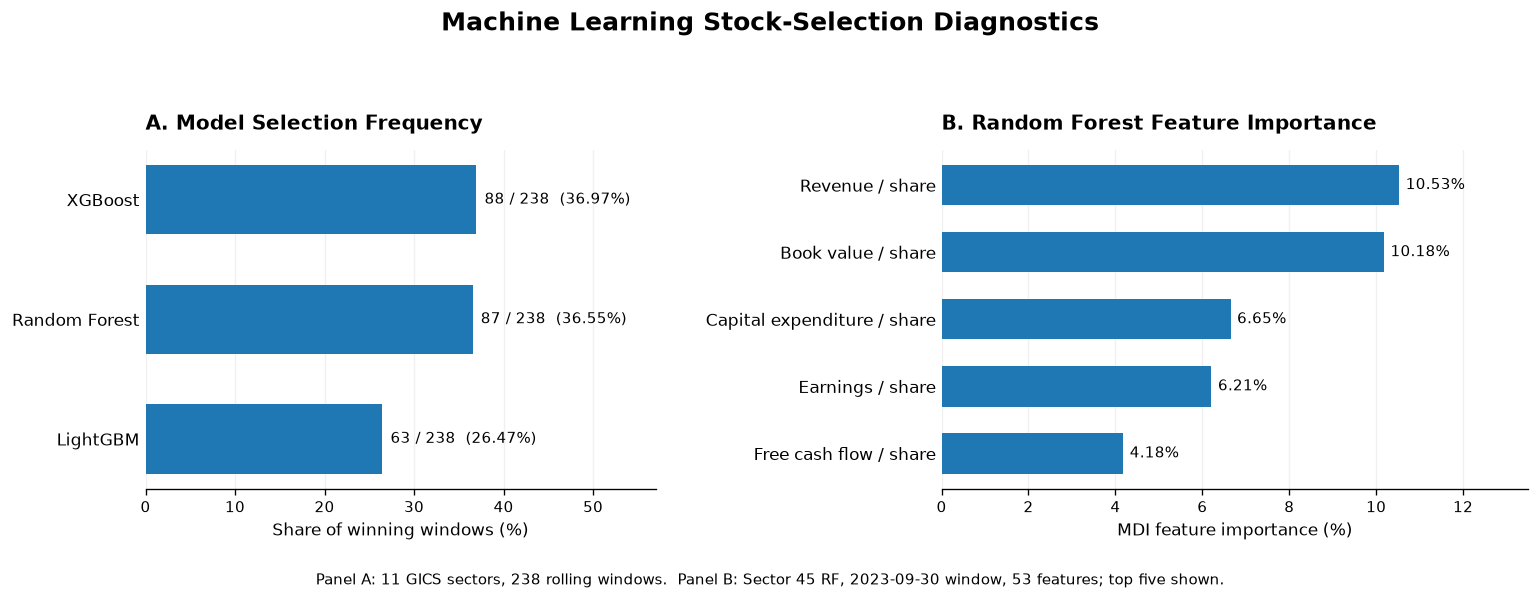

REPORT FIGURE 1 - DATA VALIDATION

Model Selection:
               Winning Windows  Frequency (%)
LightGBM                    63         26.471
Random Forest               87         36.555
XGBoost                     88         36.975

Random Forest MDI - Top 5:
Revenue / share                10.53
Book value / share             10.18
Capital expenditure / share     6.65
Earnings / share                6.21
Free cash flow / share          4.18

Saved Files:
C:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\source_code\results\report_fig1_ml_diagnostics.png
C:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\source_code\results\report_fig1_ml_diagnostics.pdf

Cell 44 completed successfully.


In [48]:

# ============================================================
# Cell 44 - Report Figure 1: ML Model Diagnostics
# Previously verified results; no retraining required
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("./results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Model selection results (238 rolling windows)
# ------------------------------------------------------------

model_wins = pd.Series({
    "LightGBM": 63,
    "Random Forest": 87,
    "XGBoost": 88
})

n_windows = int(model_wins.sum())
assert n_windows == 238

model_pct = model_wins / n_windows * 100

# ------------------------------------------------------------
# 2. Random Forest MDI feature importance
# Sector 45, model quarter 2023-09-30
# Top 5 from the previously reproduced RF model
# ------------------------------------------------------------

rf_importance = pd.Series({
    "Free cash flow / share": 4.18,
    "Earnings / share": 6.21,
    "Capital expenditure / share": 6.65,
    "Book value / share": 10.18,
    "Revenue / share": 10.53
})

# These values are percentages of total MDI importance
# across all 53 features, rounded to two decimals.

# ------------------------------------------------------------
# 3. Publication-style figure
# ------------------------------------------------------------

with plt.rc_context({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 10,
    "figure.dpi": 120,
    "savefig.dpi": 300
}):

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13.2, 5.0),
        gridspec_kw={"width_ratios": [1, 1.15]}
    )

    # Panel A: model selection frequency
    ax = axes[0]

    bars = ax.barh(
        model_pct.index,
        model_pct.values,
        height=0.58
    )

    for bar, name in zip(bars, model_pct.index):
        pct = model_pct[name]
        wins = model_wins[name]

        ax.text(
            pct + 0.9,
            bar.get_y() + bar.get_height() / 2,
            f"{wins} / {n_windows}  ({pct:.2f}%)",
            va="center",
            fontsize=9
        )

    ax.set_xlim(0, 57)
    ax.set_xlabel("Share of winning windows (%)")
    ax.set_title(
        "A. Model Selection Frequency",
        fontweight="bold",
        loc="left",
        pad=12
    )

    ax.grid(axis="x", alpha=0.18)
    ax.set_axisbelow(True)

    # Panel B: Random Forest MDI
    ax = axes[1]

    bars = ax.barh(
        rf_importance.index,
        rf_importance.values,
        height=0.60
    )

    for bar, value in zip(
        bars, rf_importance.values
    ):
        ax.text(
            value + 0.15,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.2f}%",
            va="center",
            fontsize=9
        )

    ax.set_xlim(0, 13.5)
    ax.set_xlabel("MDI feature importance (%)")
    ax.set_title(
        "B. Random Forest Feature Importance",
        fontweight="bold",
        loc="left",
        pad=12
    )

    ax.grid(axis="x", alpha=0.18)
    ax.set_axisbelow(True)

    # Clean visual styling
    for ax in axes:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)
        ax.tick_params(axis="y", length=0)

    fig.suptitle(
        "Machine Learning Stock-Selection Diagnostics",
        fontsize=15,
        fontweight="bold",
        y=0.98
    )

    fig.text(
        0.5, 0.025,
        "Panel A: 11 GICS sectors, 238 rolling windows.  "
        "Panel B: Sector 45 RF, 2023-09-30 window, "
        "53 features; top five shown.",
        ha="center",
        fontsize=9
    )

    fig.tight_layout(
        rect=[0.01, 0.07, 0.99, 0.91],
        w_pad=3
    )

    # --------------------------------------------------------
    # 4. Save for Overleaf
    # --------------------------------------------------------

    png_path = (
        OUTPUT_DIR /
        "report_fig1_ml_diagnostics.png"
    )

    pdf_path = (
        OUTPUT_DIR /
        "report_fig1_ml_diagnostics.pdf"
    )

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    plt.show()

# ------------------------------------------------------------
# 5. Print underlying values
# ------------------------------------------------------------

print("=" * 65)
print("REPORT FIGURE 1 - DATA VALIDATION")
print("=" * 65)

print("\nModel Selection:")
print(
    pd.DataFrame({
        "Winning Windows": model_wins,
        "Frequency (%)": model_pct
    }).round(3).to_string()
)

print("\nRandom Forest MDI - Top 5:")
print(
    rf_importance.sort_values(
        ascending=False
    ).to_string()
)

print("\nSaved Files:")
print(png_path.resolve())
print(pdf_path.resolve())

print("\nCell 44 completed successfully.")


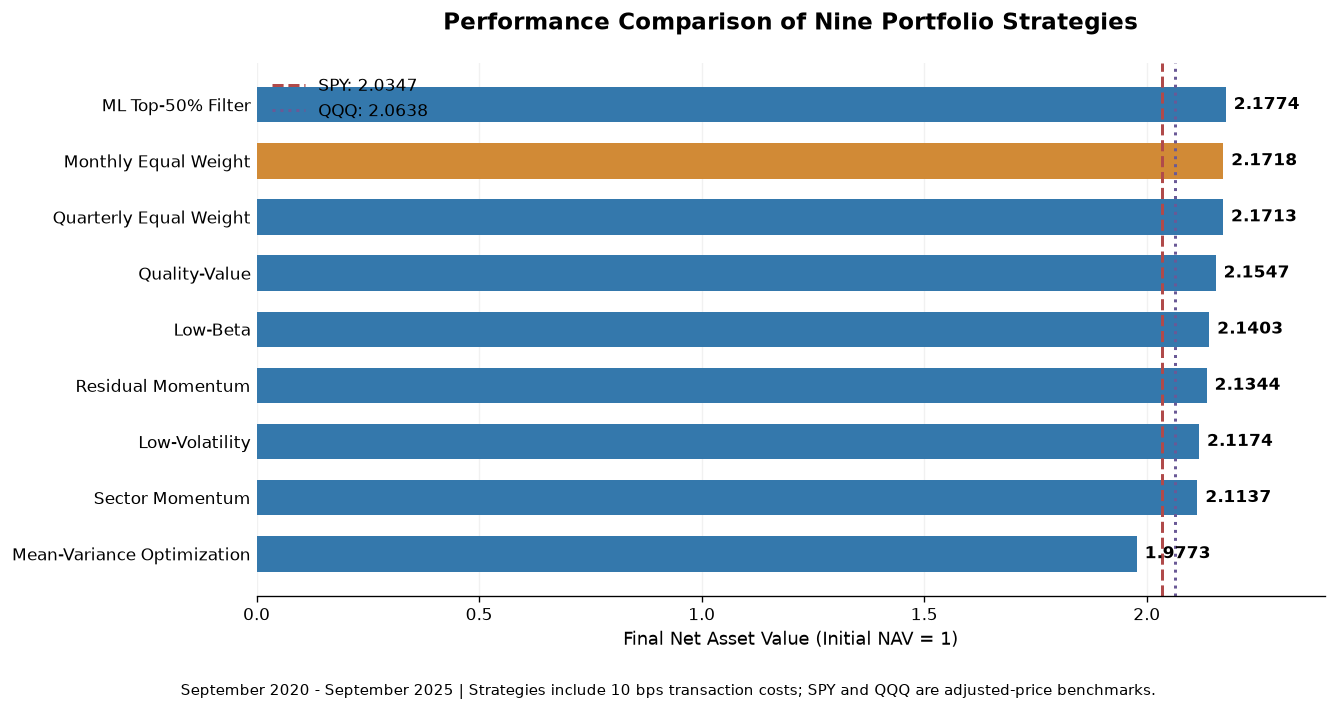

REPORT FIGURE 2 - STRATEGY COMPARISON
                            Final NAV  Excess Total Return vs SPY (pp)
ML Top-50% Filter              2.1774                          14.2677
Monthly Equal Weight           2.1718                          13.7113
Quarterly Equal Weight         2.1713                          13.6612
Quality-Value                  2.1547                          11.9962
Low-Beta                       2.1403                          10.5569
Residual Momentum              2.1344                           9.9676
Low-Volatility                 2.1174                           8.2650
Sector Momentum                2.1137                           7.8998
Mean-Variance Optimization     1.9773                          -5.7389

Strategies Outperforming SPY:
8 of 9

Strategies Outperforming QQQ:
8 of 9

Saved Files:
C:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\source_code\results\report_fig2_strategy_comparison.png
C:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\sour

In [49]:

# ============================================================
# Cell 45 - Report Figure 2: Portfolio Strategy Comparison
# September 2020 - September 2025
# No retraining or backtesting required
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("./results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Previously validated final NAV results
# ------------------------------------------------------------

strategy_nav = pd.Series({
    "ML Top-50% Filter": 2.177407,
    "Monthly Equal Weight": 2.171843,
    "Quarterly Equal Weight": 2.171342,
    "Quality-Value": 2.154692,
    "Low-Beta": 2.140299,
    "Residual Momentum": 2.134406,
    "Low-Volatility": 2.117380,
    "Sector Momentum": 2.113728,
    "Mean-Variance Optimization": 1.977341
})

spy_nav = 2.034730
qqq_nav = 2.063847

strategy_nav = strategy_nav.sort_values()

# ------------------------------------------------------------
# 2. Create publication-style horizontal bar chart
# ------------------------------------------------------------

with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 120,
    "savefig.dpi": 300
}):

    fig, ax = plt.subplots(figsize=(11.5, 6.2))

    colors = [
        "#D18A36" if name == "Monthly Equal Weight"
        else "#3478AC"
        for name in strategy_nav.index
    ]

    bars = ax.barh(
        strategy_nav.index,
        strategy_nav.values,
        color=colors,
        height=0.63
    )

    # --------------------------------------------------------
    # 3. Highlight SPY and QQQ benchmarks
    # --------------------------------------------------------

    ax.axvline(
        spy_nav,
        color="#B04A4A",
        linewidth=1.8,
        linestyle="--",
        label=f"SPY: {spy_nav:.4f}"
    )

    ax.axvline(
        qqq_nav,
        color="#6A5996",
        linewidth=1.8,
        linestyle=":",
        label=f"QQQ: {qqq_nav:.4f}"
    )

    # Final NAV labels
    for bar, value in zip(
        bars, strategy_nav.values
    ):

        ax.text(
            value + 0.018,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.4f}",
            va="center",
            fontsize=10,
            fontweight="bold"
        )

    # --------------------------------------------------------
    # 4. Layout and formatting
    # --------------------------------------------------------

    ax.set_xlim(0, 2.40)

    ax.set_xlabel("Final Net Asset Value (Initial NAV = 1)")

    ax.set_title(
        "Performance Comparison of Nine Portfolio Strategies",
        fontweight="bold",
        pad=20
    )

    ax.grid(
        axis="x",
        linestyle="-",
        alpha=0.17
    )

    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.tick_params(axis="y", length=0)

    ax.legend(
        loc="upper left",
        frameon=False,
        fontsize=10
    )

    fig.text(
        0.5, 0.015,
        "September 2020 - September 2025 | "
        "Strategies include 10 bps transaction costs; "
        "SPY and QQQ are adjusted-price benchmarks.",
        ha="center",
        fontsize=9
    )

    fig.tight_layout(
        rect=[0.01, 0.05, 0.99, 0.96]
    )

    # --------------------------------------------------------
    # 5. Save publication-quality figure
    # --------------------------------------------------------

    png_path = (
        OUTPUT_DIR /
        "report_fig2_strategy_comparison.png"
    )

    pdf_path = (
        OUTPUT_DIR /
        "report_fig2_strategy_comparison.pdf"
    )

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    plt.show()

# ------------------------------------------------------------
# 6. Validate and report source data
# ------------------------------------------------------------

print("=" * 70)
print("REPORT FIGURE 2 - STRATEGY COMPARISON")
print("=" * 70)

comparison = pd.DataFrame({
    "Final NAV": strategy_nav,
    "Excess Total Return vs SPY (pp)":
        (strategy_nav - spy_nav) * 100
})

print(
    comparison.sort_values(
        "Final NAV",
        ascending=False
    ).round(4).to_string()
)

print("\nStrategies Outperforming SPY:")
print(int((strategy_nav > spy_nav).sum()), "of 9")

print("\nStrategies Outperforming QQQ:")
print(int((strategy_nav > qqq_nav).sum()), "of 9")

print("\nSaved Files:")
print(png_path.resolve())
print(pdf_path.resolve())

print("\nCell 45 completed successfully.")


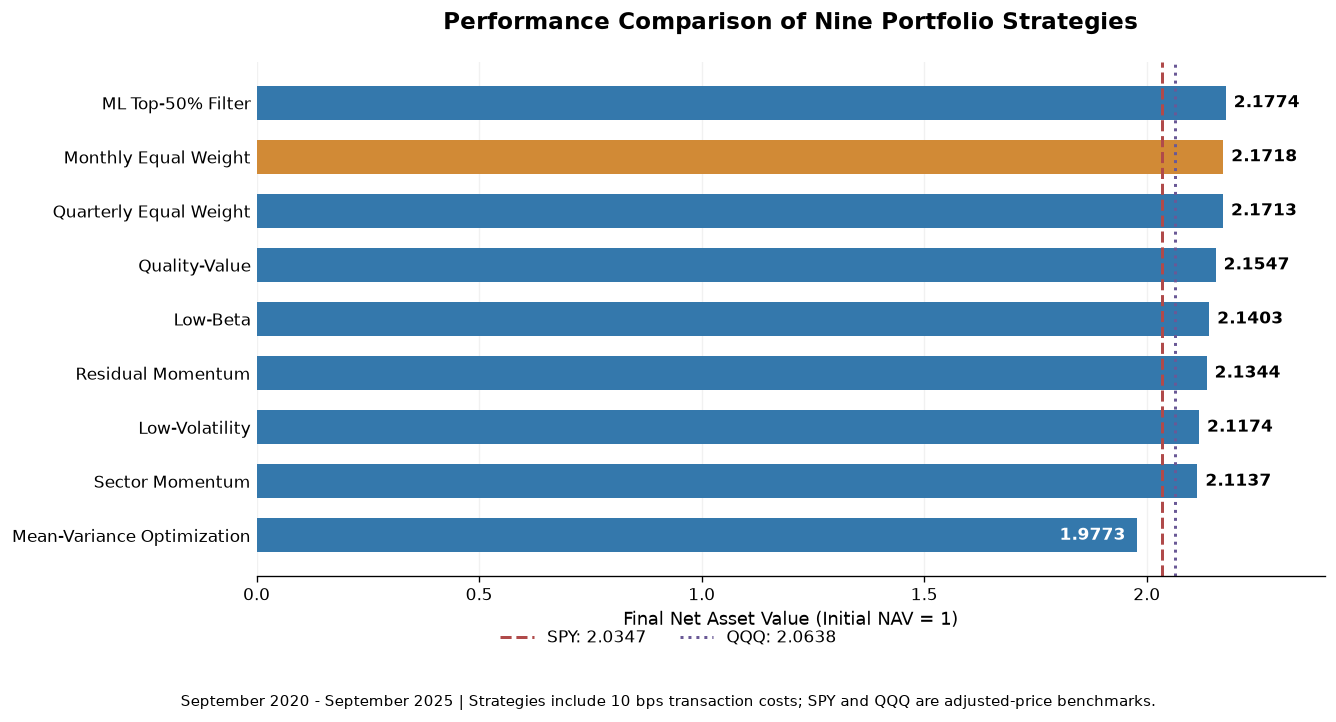

Figure 2 updated and saved.


In [50]:

# ============================================================
# Cell 45A - Final Formatting for Report Figure 2
# ============================================================

from IPython.display import display

# Remove the legend overlapping the top bar
old_legend = ax.get_legend()

if old_legend is not None:
    old_legend.remove()

# Move MVO's value label inside its bar
for txt in list(ax.texts):
    if txt.get_text() == "1.9773":
        txt.remove()

mvo_name = "Mean-Variance Optimization"
mvo_y = list(strategy_nav.index).index(mvo_name)

ax.text(
    strategy_nav[mvo_name] - 0.025,
    mvo_y,
    f"{strategy_nav[mvo_name]:.4f}",
    ha="right",
    va="center",
    color="white",
    fontsize=10,
    fontweight="bold"
)

# Allocate space below the chart for the benchmark legend
fig.subplots_adjust(bottom=0.19, top=0.88)

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.075),
    ncol=2,
    frameon=False,
    fontsize=10
)

fig.savefig(
    "./results/report_fig2_strategy_comparison.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "./results/report_fig2_strategy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

display(fig)

print("Figure 2 updated and saved.")


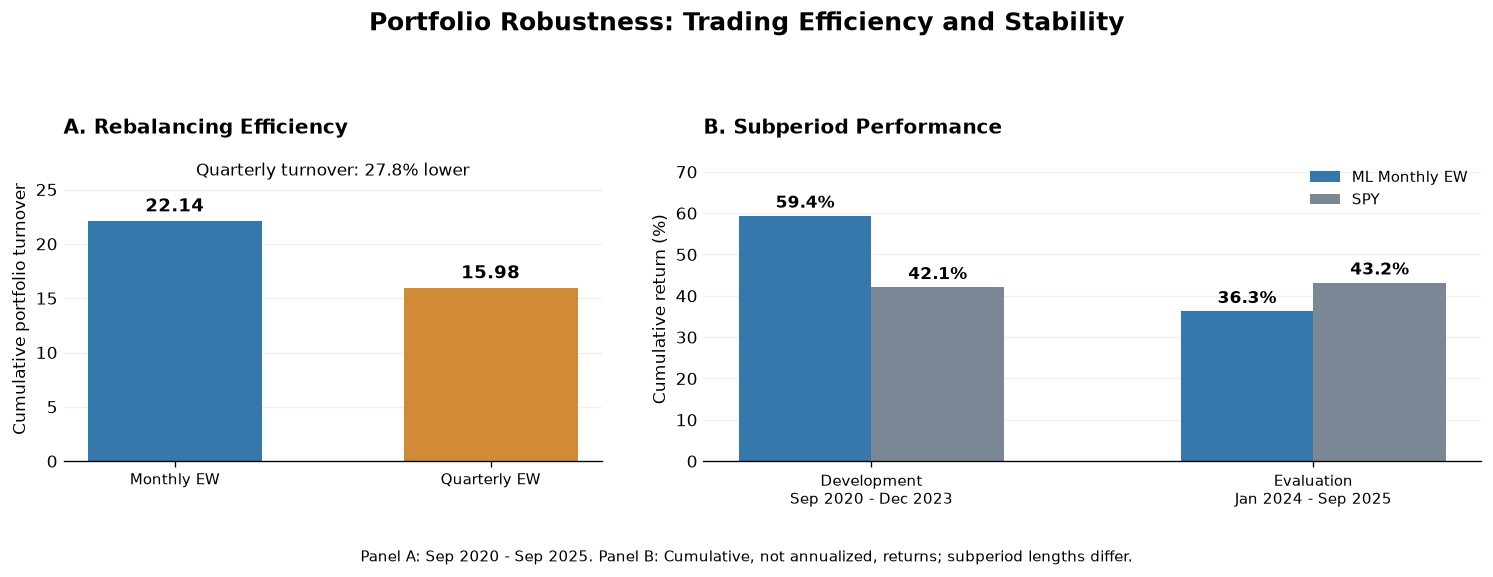

REPORT FIGURE 4 - ROBUSTNESS ANALYSIS

Cumulative Turnover:
Strategy
Monthly EW      22.1377
Quarterly EW    15.9794

Quarterly Turnover Reduction: 27.818%

Subperiod Cumulative Returns (%):
Strategy     Monthly EW      SPY
Period                          
Development     59.3561  42.0915
Evaluation      36.2887  43.1987

Monthly EW Minus SPY (Percentage Points):
Development: +17.265 pp
Evaluation: -6.910 pp

Saved Files:
C:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\source_code\results\report_fig4_robustness.png
C:\Users\kisum\Desktop\Fall 26\GE5398\Assignment 1\source_code\results\report_fig4_robustness.pdf

Cell 46 completed successfully.


In [51]:

# ============================================================
# Cell 46 - Report Figure 4: Robustness Analysis
# Rebalancing efficiency and subperiod performance
# No model training or backtesting required
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("./results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load existing validated experiment results
# ------------------------------------------------------------

if "strategy_leaderboard" in globals():
    leaderboard = strategy_leaderboard.copy()
else:
    leaderboard = pd.read_csv(
        OUTPUT_DIR / "final_strategy_leaderboard.csv",
        index_col=0
    )

if "period_comparison" in globals():
    periods_df = period_comparison.copy()
else:
    periods_df = pd.read_csv(
        OUTPUT_DIR / "final_subperiod_comparison.csv"
    )

# ------------------------------------------------------------
# 2. Monthly vs Quarterly cumulative turnover
# ------------------------------------------------------------

turnover = leaderboard.loc[
    ["Monthly EW", "Quarterly EW"],
    "Total Turnover"
].astype(float)

turnover_reduction = (
    1 - turnover["Quarterly EW"]
    / turnover["Monthly EW"]
) * 100

# Verify against previously reported results
assert np.isclose(
    turnover["Monthly EW"], 22.1377, atol=0.001
)

assert np.isclose(
    turnover["Quarterly EW"], 15.9794, atol=0.001
)

# ------------------------------------------------------------
# 3. Development vs Evaluation period returns
# ------------------------------------------------------------

subperiod = (
    periods_df.loc[
        periods_df["Strategy"].isin(
            ["Monthly EW", "SPY"]
        )
    ]
    .pivot(
        index="Period",
        columns="Strategy",
        values="Period Return (%)"
    )
    .loc[
        ["Development", "Evaluation"],
        ["Monthly EW", "SPY"]
    ]
    .astype(float)
)

assert subperiod.notna().all().all()

period_labels = [
    "Development\nSep 2020 - Dec 2023",
    "Evaluation\nJan 2024 - Sep 2025"
]

# ------------------------------------------------------------
# 4. Create two-panel academic figure
# ------------------------------------------------------------

BLUE = "#3478AC"
ORANGE = "#D18A36"
GRAY = "#7B8794"

with plt.rc_context({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 10,
    "figure.dpi": 120,
    "savefig.dpi": 300
}):

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12.8, 4.8),
        gridspec_kw={"width_ratios": [0.9, 1.3]}
    )

    # --------------------------------------------------------
    # Panel A: Rebalancing turnover
    # --------------------------------------------------------

    ax = axes[0]

    x_a = np.arange(2)

    bars = ax.bar(
        x_a,
        turnover.values,
        width=0.55,
        color=[BLUE, ORANGE]
    )

    for bar, value in zip(bars, turnover.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.45,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold"
        )

    ax.set_xticks(x_a)
    ax.set_xticklabels(
        ["Monthly EW", "Quarterly EW"]
    )

    ax.set_ylim(0, 28)

    ax.set_ylabel("Cumulative portfolio turnover")

    ax.set_title(
        "A. Rebalancing Efficiency",
        fontweight="bold",
        loc="left",
        pad=14
    )

    ax.text(
        0.5, 26.7,
        f"Quarterly turnover: {turnover_reduction:.1f}% lower",
        ha="center",
        va="center",
        fontsize=10
    )

    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

    # --------------------------------------------------------
    # Panel B: Subperiod cumulative returns
    # --------------------------------------------------------

    ax = axes[1]

    x_b = np.arange(len(period_labels))
    width = 0.30

    ew_values = subperiod["Monthly EW"].to_numpy()
    spy_values = subperiod["SPY"].to_numpy()

    ew_bars = ax.bar(
        x_b - width / 2,
        ew_values,
        width,
        label="ML Monthly EW",
        color=BLUE
    )

    spy_bars = ax.bar(
        x_b + width / 2,
        spy_values,
        width,
        label="SPY",
        color=GRAY
    )

    for bars in [ew_bars, spy_bars]:
        for bar in bars:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 1.0,
                f"{bar.get_height():.1f}%",
                ha="center",
                va="bottom",
                fontsize=10,
                fontweight="bold"
            )

    ax.set_xticks(x_b)
    ax.set_xticklabels(period_labels)

    ax.set_ylim(0, max(
        ew_values.max(),
        spy_values.max()
    ) * 1.24)

    ax.set_ylabel("Cumulative return (%)")

    ax.set_title(
        "B. Subperiod Performance",
        fontweight="bold",
        loc="left",
        pad=14
    )

    ax.legend(
        loc="upper right",
        frameon=False,
        fontsize=9
    )

    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

    # --------------------------------------------------------
    # 5. Consistent styling
    # --------------------------------------------------------

    for ax in axes:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)
        ax.tick_params(axis="y", length=0)

    fig.suptitle(
        "Portfolio Robustness: Trading Efficiency and Stability",
        fontsize=15,
        fontweight="bold",
        y=0.98
    )

    fig.text(
        0.5, 0.025,
        "Panel A: Sep 2020 - Sep 2025. "
        "Panel B: Cumulative, not annualized, "
        "returns; subperiod lengths differ.",
        ha="center",
        fontsize=9
    )

    fig.tight_layout(
        rect=[0.01, 0.085, 0.99, 0.90],
        w_pad=3.0
    )

    # --------------------------------------------------------
    # 6. Save for Overleaf
    # --------------------------------------------------------

    png_path = (
        OUTPUT_DIR /
        "report_fig4_robustness.png"
    )

    pdf_path = (
        OUTPUT_DIR /
        "report_fig4_robustness.pdf"
    )

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    plt.show()

# ------------------------------------------------------------
# 7. Print and verify underlying values
# ------------------------------------------------------------

print("=" * 70)
print("REPORT FIGURE 4 - ROBUSTNESS ANALYSIS")
print("=" * 70)

print("\nCumulative Turnover:")
print(turnover.round(4).to_string())

print(
    f"\nQuarterly Turnover Reduction: "
    f"{turnover_reduction:.3f}%"
)

print("\nSubperiod Cumulative Returns (%):")
print(subperiod.round(4).to_string())

print("\nMonthly EW Minus SPY (Percentage Points):")

for period in subperiod.index:
    difference = (
        subperiod.loc[period, "Monthly EW"]
        - subperiod.loc[period, "SPY"]
    )
    print(f"{period}: {difference:+.3f} pp")

print("\nSaved Files:")
print(png_path.resolve())
print(pdf_path.resolve())

print("\nCell 46 completed successfully.")


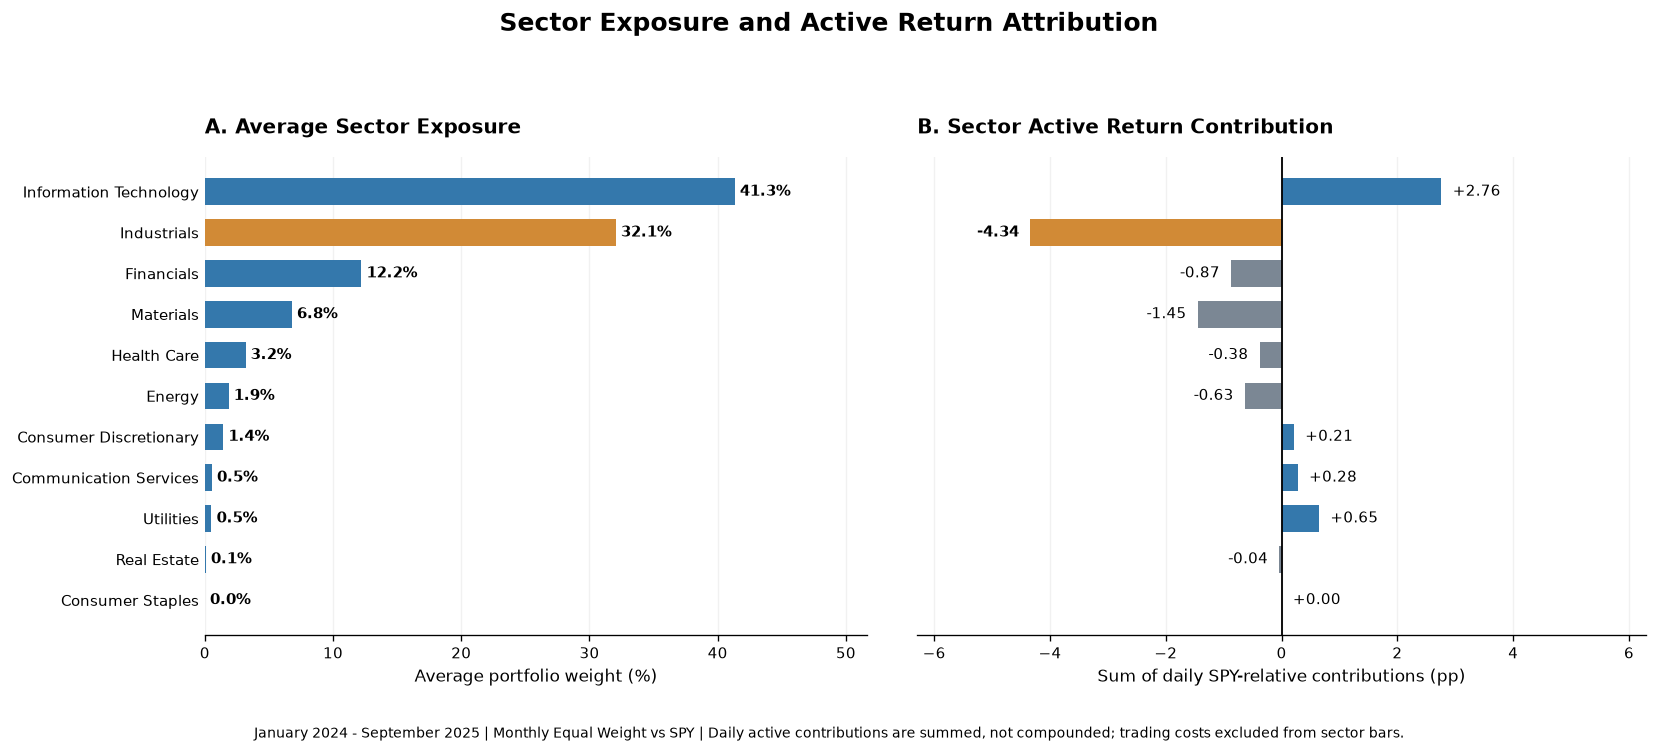

REPORT FIGURE 5 - SECTOR ATTRIBUTION

Sector Exposure and Attribution:
                        Average Exposure (%)  SPY-Relative Daily Spread (pp sum)
Information Technology               41.3322                              2.7610
Industrials                          32.0501                             -4.3396
Financials                           12.2175                             -0.8700
Materials                             6.7840                             -1.4469
Health Care                           3.1725                             -0.3780
Energy                                1.8622                             -0.6322
Consumer Discretionary                1.4398                              0.2126
Communication Services                0.5491                              0.2801
Utilities                             0.5168                              0.6469
Real Estate                           0.0759                             -0.0374
Consumer Staples                      

In [52]:

# ============================================================
# Cell 47 - Report Figure 5: Sector Exposure and Attribution
# Evaluation period: January 2024 - September 2025
# Uses existing Cell 29 attribution results
# No retraining or new backtesting required
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("./results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load existing sector attribution results
# ------------------------------------------------------------

PERIOD = "Evaluation 2024-2025"

if (
    "sector_attribution_tables" in globals()
    and PERIOD in sector_attribution_tables
):

    sector_data = (
        sector_attribution_tables[PERIOD].copy()
    )

elif (
    "sector_active_daily" in globals()
    and "sector_exposure_daily" in globals()
    and "GICS_NAMES" in globals()
):

    # Reconstruct only the summary from the existing
    # daily attribution arrays if the summary is missing.

    start = pd.Timestamp("2024-01-01")
    end = pd.Timestamp("2025-09-30")

    mask = (
        (sector_active_daily.index >= start)
        & (sector_active_daily.index <= end)
    )

    active_pp = (
        sector_active_daily.loc[mask].sum() * 100
    )

    exposure_pct = (
        sector_exposure_daily.loc[mask].mean() * 100
    )

    sector_data = pd.DataFrame({
        "Average Exposure (%)": exposure_pct,
        "SPY-Relative Daily Spread (pp sum)": active_pp
    })

    sector_data.index = [
        (
            GICS_NAMES.get(int(s), f"Sector {s}")
            if s != "Transaction Costs"
            else "Transaction Costs"
        )
        for s in sector_data.index
    ]

else:
    raise RuntimeError(
        "Sector attribution results are not in memory. "
        "Run the original Cell 29 first, then rerun Cell 47."
    )

# ------------------------------------------------------------
# 2. Prepare 11 sector observations
# ------------------------------------------------------------

required_columns = [
    "Average Exposure (%)",
    "SPY-Relative Daily Spread (pp sum)"
]

assert all(
    col in sector_data.columns
    for col in required_columns
)

sector_data = sector_data.drop(
    index="Transaction Costs",
    errors="ignore"
)

sector_data = (
    sector_data[required_columns]
    .astype(float)
    .sort_values(
        "Average Exposure (%)",
        ascending=False
    )
)

assert len(sector_data) == 11
assert sector_data.notna().all().all()
assert "Industrials" in sector_data.index

exposure = sector_data["Average Exposure (%)"]
active = sector_data[
    "SPY-Relative Daily Spread (pp sum)"
]

# Check consistency with previous audit
assert np.isclose(
    exposure.loc["Industrials"],
    32.05,
    atol=0.2
)

assert np.isclose(
    active.loc["Industrials"],
    -4.3396,
    atol=0.2
)

# ------------------------------------------------------------
# 3. Colors and chart setup
# ------------------------------------------------------------

BLUE = "#3478AC"
ORANGE = "#D18A36"
SLATE = "#7B8794"

names = sector_data.index.tolist()
y = np.arange(len(names))

colors_a = [
    ORANGE if name == "Industrials" else BLUE
    for name in names
]

colors_b = [
    ORANGE if name == "Industrials"
    else (BLUE if active.loc[name] >= 0 else SLATE)
    for name in names
]

with plt.rc_context({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.dpi": 120,
    "savefig.dpi": 300
}):

    fig, axes = plt.subplots(
        1, 2,
        figsize=(14.2, 6.3),
        sharey=True,
        gridspec_kw={"width_ratios": [1.0, 1.1]}
    )

    # --------------------------------------------------------
    # Panel A: Average sector exposure
    # --------------------------------------------------------

    ax = axes[0]

    ax.barh(
        y,
        exposure.values,
        color=colors_a,
        height=0.65
    )

    ax.set_yticks(y)
    ax.set_yticklabels(names)

    ax.invert_yaxis()

    ax.set_xlim(
        0,
        exposure.max() * 1.25
    )

    for yi, val in zip(y, exposure.values):

        ax.text(
            val + 0.4,
            yi,
            f"{val:.1f}%",
            va="center",
            fontsize=9,
            fontweight="bold"
        )

    ax.set_title(
        "A. Average Sector Exposure",
        fontweight="bold",
        loc="left",
        pad=14
    )

    ax.set_xlabel(
        "Average portfolio weight (%)"
    )

    ax.grid(axis="x", alpha=0.17)
    ax.set_axisbelow(True)

    # --------------------------------------------------------
    # Panel B: SPY-relative sector attribution
    # --------------------------------------------------------

    ax = axes[1]

    ax.barh(
        y,
        active.values,
        color=colors_b,
        height=0.65
    )

    ax.axvline(
        0,
        color="black",
        linewidth=1.1
    )

    scale = max(
        abs(active.min()),
        abs(active.max())
    )

    ax.set_xlim(
        -scale * 1.45,
        scale * 1.45
    )

    label_offset = scale * 0.045

    for yi, val in zip(y, active.values):

        if val >= 0:
            x_pos = val + label_offset
            align = "left"
        else:
            x_pos = val - label_offset
            align = "right"

        ax.text(
            x_pos,
            yi,
            f"{val:+.2f}",
            ha=align,
            va="center",
            fontsize=9,
            fontweight=(
                "bold" if names[yi] == "Industrials"
                else "normal"
            )
        )

    ax.set_title(
        "B. Sector Active Return Contribution",
        fontweight="bold",
        loc="left",
        pad=14
    )

    ax.set_xlabel(
        "Sum of daily SPY-relative contributions (pp)"
    )

    ax.tick_params(
        axis="y",
        labelleft=False
    )

    ax.grid(axis="x", alpha=0.17)
    ax.set_axisbelow(True)

    # --------------------------------------------------------
    # 4. Publication formatting
    # --------------------------------------------------------

    for ax in axes:

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)

        ax.tick_params(axis="y", length=0)

    fig.suptitle(
        "Sector Exposure and Active Return Attribution",
        fontsize=15,
        fontweight="bold",
        y=0.98
    )

    fig.text(
        0.5, 0.02,
        "January 2024 - September 2025 | "
        "Monthly Equal Weight vs SPY | "
        "Daily active contributions are summed, "
        "not compounded; trading costs excluded from sector bars.",
        ha="center",
        fontsize=8.5
    )

    fig.tight_layout(
        rect=[0.01, 0.065, 0.99, 0.92],
        w_pad=3.0
    )

    # --------------------------------------------------------
    # 5. Save figures
    # --------------------------------------------------------

    png_path = (
        OUTPUT_DIR /
        "report_fig5_sector_attribution.png"
    )

    pdf_path = (
        OUTPUT_DIR /
        "report_fig5_sector_attribution.pdf"
    )

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    plt.show()

# ------------------------------------------------------------
# 6. Verify source values
# ------------------------------------------------------------

print("=" * 75)
print("REPORT FIGURE 5 - SECTOR ATTRIBUTION")
print("=" * 75)

print("\nSector Exposure and Attribution:")
print(
    sector_data.round(4).to_string()
)

print("\nIndustrials:")
print(
    f"Average Exposure: "
    f"{exposure.loc['Industrials']:.4f}%"
)
print(
    f"SPY-Relative Contribution: "
    f"{active.loc['Industrials']:+.4f} pp"
)

print("\nTotal Average Sector Exposure:")
print(f"{exposure.sum():.4f}%")

print("\nNote:")
print(
    "Active sector contributions represent the arithmetic "
    "sum of daily sector excess-return contributions. "
    "They are not compounded relative wealth returns."
)

print("\nSaved Files:")
print(png_path.resolve())
print(pdf_path.resolve())

print("\nCell 47 completed successfully.")
